<a href="https://colab.research.google.com/github/Andoniadou-Lab/NFPA_sc/blob/main/NFPA_ANALYSIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install scanpy # install the scanpy module
# restart the kernel after running this line of code
import scanpy as sc # import the scanpy modulex
import matplotlib.pyplot as plt


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 130.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 7.9 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source o

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
adata=sc.read("/content/drive/MyDrive/Colab Notebooks/Copy of silent_gonadotroph_2026_09_02.h5ad")

In [6]:
adata

AnnData object with n_obs × n_vars = 104321 × 39074
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'assay', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'Internal_ID', 'Name', 'Normal', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'n_cells', 'pct_counts_in_top_20_genes', 'SRA_barcode', 'cell_type', 'leiden_scVI', 'leiden_scVI_final', 'final_cell_type_broad', 'final_cell_type_specific'
    var: 'mt', 'ribo', 'malat', 'n_cells_by_counts', 'mean

In [7]:
# 1. Target the column you want to modify (e.g., 'final_cell_type_broad')
target_col = "final_cell_type_broad"

# 2. Replace 'Gonadotrophs' with 'tumour cells'
adata.obs[target_col] = (
    adata.obs[target_col].astype(str).replace({"Gonadotrophs": "Tumour cells"})
)

# 3. Convert back to categorical (ensures compatibility with Scanpy plotting)
adata.obs[target_col] = adata.obs[target_col].astype("category")

In [8]:
celltype_col = "final_cell_type_broad"
adata.obs[celltype_col] = adata.obs[celltype_col].replace({"Pituicytes": "Tumour cells"})
adata.obs[celltype_col] = adata.obs[celltype_col].astype("category")
adata.obs[celltype_col] = adata.obs[celltype_col].cat.remove_unused_categories()
print(adata.obs[celltype_col].value_counts())

final_cell_type_broad
Tumour cells         94737
Macrophages           3035
Mesenchymal_cells     2540
Endothelial_cells     2000
Stem_cells            1253
Monocytes              424
T_or_NK_cells          332
Name: count, dtype: int64


In [9]:
celltype_col = "final_cell_type_broad"

# 1. Clean names (safe to re-run)
rename = {"Endothelial_cells": "Endothelial", "Mesenchymal_cells": "Mesenchymal",
          "T_or_NK_cells": "T/NK cells", "Stem_cells": "Stem cells",
          "Pituicytes": "Tumour cells"}
adata.obs[celltype_col] = (adata.obs[celltype_col].astype(str)
                           .replace(rename).astype("category"))

# 2. Fixed colours
pal = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728",
       "T/NK cells": "#e377c2"}
cats = adata.obs[celltype_col].cat.categories
missing = [c for c in cats if c not in pal]
if missing:
    print("No colour set for:", missing)
adata.uns[f"{celltype_col}_colors"] = [pal.get(c, "#cccccc") for c in cats]
print(adata.obs[celltype_col].value_counts())

final_cell_type_broad
Tumour cells    94737
Macrophages      3035
Mesenchymal      2540
Endothelial      2000
Stem cells       1253
Monocytes         424
T/NK cells        332
Name: count, dtype: int64


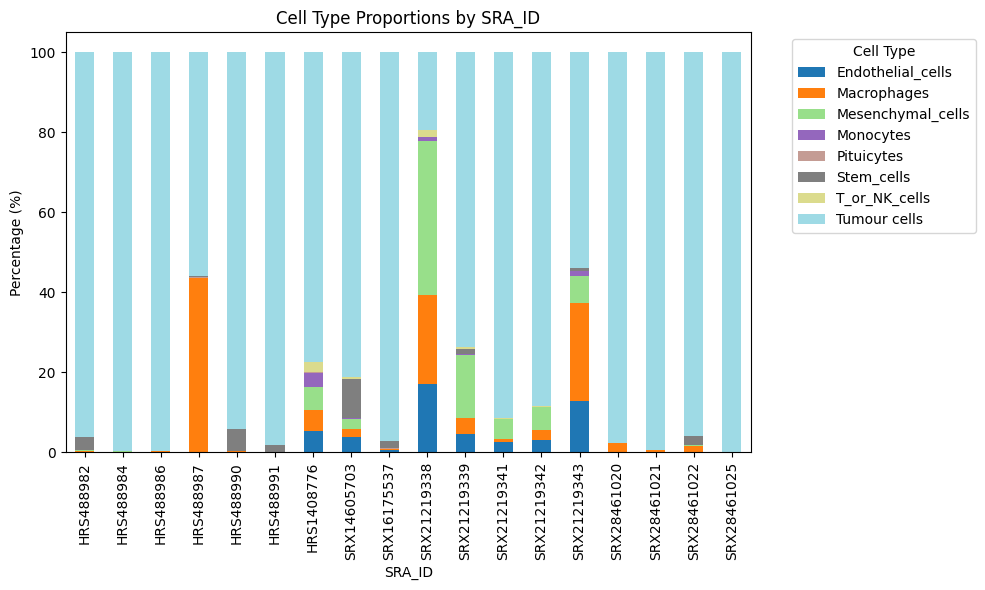

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Choose your grouping column (x-axis) and cell type column
group_col = "SRA_ID"  # e.g., 'SRA_ID', 'Normal', or 'Tumor_pta'
cell_type_col = "final_cell_type_broad"  # or 'final_cell_type_specific'

# 2. Calculate cross-tabulation (frequencies) and normalize across rows to get proportions (percentages)
props = pd.crosstab(
    adata.obs[group_col], adata.obs[cell_type_col], normalize="index"
) * 100

# 3. Plot stacked bar chart
fig, ax = plt.subplots(figsize=(10, 6))
props.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")

plt.title(f"Cell Type Proportions by {group_col}")
plt.xlabel(group_col)
plt.ylabel("Percentage (%)")
plt.legend(title="Cell Type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extract categories and theirScanpy colors
cell_types = adata.obs["final_cell_type_broad"].cat.categories
colors = adata.uns["final_cell_type_broad_colors"]

# Create a palette dictionary mapping cell types to Scanpy hex colors
color_dict = dict(zip(cell_types, colors))

# 2. Compute proportions (assuming metadata is in adata.obs)
props = (
    pd.crosstab(
        adata.obs["SRA_ID"],
        adata.obs["final_cell_type_broad"],
        normalize="index",
    )
    * 100
)

# 3. Plot stacked bar chart using the exact color dictionary
ax = props.plot(
    kind="bar", stacked=True, color=color_dict, figsize=(10, 5), width=0.8
)

plt.xlabel("SRA_ID")
plt.ylabel("Percentage (%)")
plt.title("Cell Type Proportions by SRA_ID")
plt.legend(
    title="Cell Type", bbox_to_anchor=(1.05, 1), loc="upper left", frameon=True
)
plt.tight_layout()
plt.show()

KeyError: 'final_cell_type_broad_colors'

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Compute cell counts and exact percentages
cell_counts = adata.obs["final_cell_type_broad"].value_counts()
cell_types = cell_counts.index
percentages = (cell_counts / cell_counts.sum()) * 100

# 2. Match colors to the categories
color_dict = dict(
    zip(
        adata.obs["final_cell_type_broad"].cat.categories,
        adata.uns["final_cell_type_broad_colors"],
    )
)
plot_colors = [color_dict[ct] for ct in cell_types]

# 3. Format legend labels to include percentages
legend_labels = [
    f"{ct} ({p:.1f}%)" if p >= 0.1 else f"{ct} (<0.1%)"
    for ct, p in zip(cell_types, percentages)
]

# 4. Plot Pie Chart without inline labels
fig, ax = plt.subplots(figsize=(7, 7))

# Explode minor slices slightly to keep them distinct
explode = [0 if ct == "Tumour cells" else 0.05 for ct in cell_types]

wedges, _ = ax.pie(
    cell_counts,
    startangle=90,
    counterclock=False,
    colors=plot_colors,
    explode=explode,
)

# 5. Display Legend with embedded percentages
plt.legend(
    wedges,
    legend_labels,
    title="Cell Type Proportions",
    loc="center left",
    bbox_to_anchor=(1.05, 0.5),
    frameon=False,
    fontsize=10,
)

plt.title("Integrated Tumors", fontsize=14, pad=20, weight="bold")
plt.tight_layout()
plt.show()

NameError: name 'adata' is not defined

In [ ]:
# Returns just the integer 104321
num_cells = adata.n_obs
print(f"Total cells: {num_cells}")

# Returns a tuple of (cells, genes): (104321, 39074)
print(adata.shape)

Total cells: 104321
(104321, 39074)


In [ ]:
# Print counts for each cell type
cell_type_counts = adata.obs['final_cell_type_specific'].value_counts()
print(cell_type_counts)

final_cell_type_specific
Silent_gonadotroph_tumor    94698
Macrophages                  3035
Mesenchymal_cells            2540
Endothelial_cells            2000
Stem_cells                   1268
Monocytes                     424
T_or_NK_cells                 332
Pituicytes                     24
Name: count, dtype: int64


In [ ]:
# Get proportion of total dataset instead of raw counts
adata.obs['final_cell_type_broad'].value_counts(normalize=True) * 100

final_cell_type_broad
Tumour cells         90.789966
Macrophages           2.909290
Mesenchymal_cells     2.434793
Endothelial_cells     1.917160
Stem_cells            1.201100
Monocytes             0.406438
T_or_NK_cells         0.318248
Pituicytes            0.023006
Name: proportion, dtype: float64

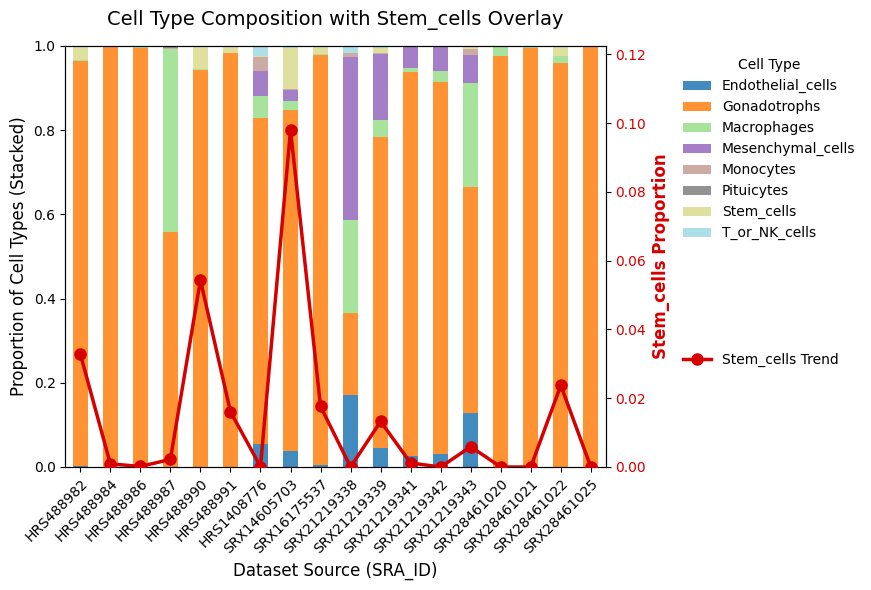

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Extract relevant columns
df = adata.obs[["final_cell_type_broad", "SRA_ID"]]

# 2. Calculate counts and normalize across batches
cluster_counts = (
    df.groupby(["SRA_ID", "final_cell_type_broad"]).size().unstack(fill_value=0)
)
cluster_proportions = cluster_counts.div(cluster_counts.sum(axis=1), axis=0)

# Sort columns alphabetically
cell_types = sorted(cluster_proportions.columns)
cluster_proportions = cluster_proportions.reindex(cell_types, axis=1)

# 3. Target the stem cell column
stem_cell_name = "Stem_cells"  # Adjust to match your exact metadata string

# Identify the exact stem cell column key
stem_col = [ct for ct in cell_types if stem_cell_name.lower() in ct.lower()]
if not stem_col:
    raise ValueError(
        f"Could not find '{stem_cell_name}' in categories: {cell_types}"
    )
stem_col_name = stem_col[0]

# 4. Create figure and primary axis for stacked bars
fig, ax1 = plt.subplots(figsize=(9, 6))

# Plot all stacked bars with a pastel palette
cluster_proportions.plot(
    kind="bar",
    stacked=True,
    colormap="tab20",
    ax=ax1,
    edgecolor="none",
    alpha=0.85,
)

ax1.set_xlabel("Dataset Source (SRA_ID)", fontsize=12)
ax1.set_ylabel("Proportion of Cell Types (Stacked)", fontsize=12)
ax1.set_xticklabels(
    cluster_proportions.index, rotation=45, ha="right", rotation_mode="anchor"
)

# Position stacked bar legend outside
ax1.legend(
    title="Cell Type",
    bbox_to_anchor=(1.12, 1),
    loc="upper left",
    frameon=False,
)

# 5. Create secondary axis (twinx) for the stem cell line overlay
ax2 = ax1.twinx()

# Plot line graph with high-visibility markers
x_positions = np.arange(len(cluster_proportions))
stem_values = cluster_proportions[stem_col_name]

ax2.plot(
    x_positions,
    stem_values,
    color="#D60000",
    marker="o",
    linewidth=2.5,
    markersize=8,
    label=f"{stem_col_name} Trend",
    zorder=10,
)

ax2.set_ylabel(
    f"{stem_col_name} Proportion", fontsize=12, color="#D60000", fontweight="bold"
)
ax2.tick_params(axis="y", labelcolor="#D60000")
ax2.set_ylim(0, max(stem_values) * 1.25 if max(stem_values) > 0 else 1)

# Add line plot legend
ax2.legend(bbox_to_anchor=(1.12, 0.3), loc="upper left", frameon=False)

plt.title(
    f"Cell Type Composition with {stem_col_name} Overlay",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [2]:
import matplotlib.pyplot as plt
import scanpy as sc

# Set figure parameters
plt.rcParams["figure.figsize"] = (6, 6)
plt.rcParams["figure.dpi"] = 500

# show=False keeps the figure open for Matplotlib to save
sc.pl.umap(adata, color=['PEG10'], use_raw=False, cmap='Reds', show=False)

# Save high-res plot with tight boundaries to prevent cut-off legends
plt.savefig("umap_nr5a1_highres.png", dpi=600, bbox_inches="tight")

# Display the plot in your notebook/screen afterwards
plt.show()

NameError: name 'adata' is not defined

In [ ]:
sc.pl.dotplot(
    adata_stem,
    var_names=["PEG10"],
    groupby="CDKN1A_group",
    use_raw=False
)

NameError: name 'adata_stem' is not defined

In [ ]:
from google.colab import files

files.download("umap_nr5a1_highres.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

KeyboardInterrupt: 

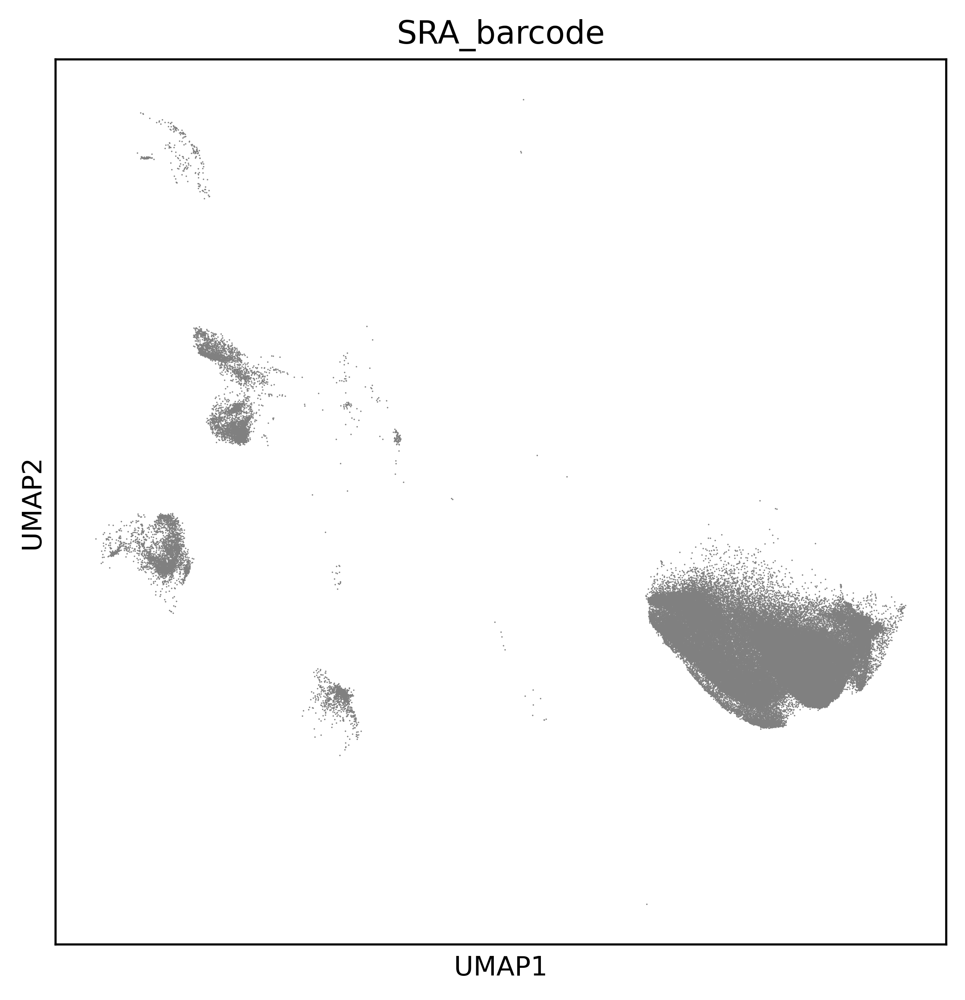

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# Set high DPI and figure dimensions
plt.rcParams["figure.figsize"] = (6, 6)
plt.rcParams["figure.dpi"] = 500

sc.pl.umap(adata, color="SRA_barcode", show=False)

# Save with 600 DPI for crisp details
plt.savefig("umap_final_cell_type_specific_highres.png", dpi=600, bbox_inches="tight")
plt.show()

<Axes: title={'center': 'final_cell_type_broad'}, xlabel='UMAP1', ylabel='UMAP2'>

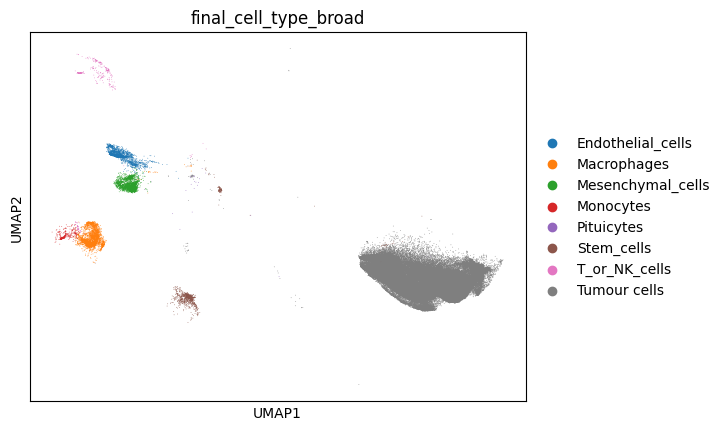

In [ ]:
sc.pl.umap(adata, color="final_cell_type_broad", show=False)

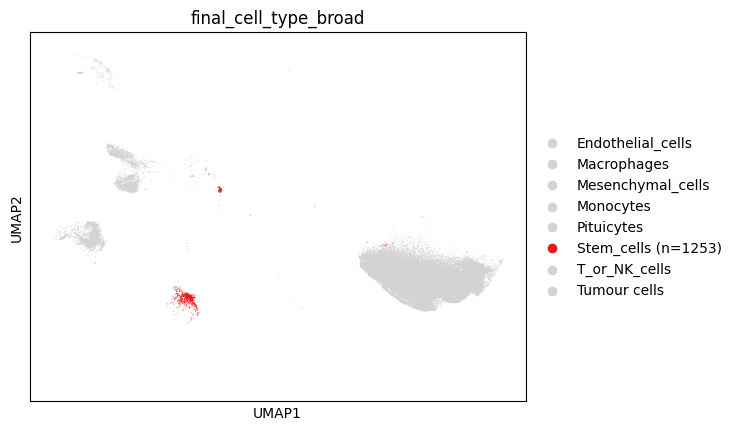

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Get counts for all cell types
counts = adata.obs["final_cell_type_broad"].value_counts()
categories = adata.obs["final_cell_type_broad"].cat.categories

# 2. Map Stem_cells to red and all other categories to gray
gray_palette = {
    ct: "#E41A1C" if ct == "Stem_cells" else "#D3D3D3" for ct in categories
}

# 3. Define new legend labels with (n=...) added to Stem_cells
legend_labels = [
    f"{ct} (n={counts[ct]})" if ct == "Stem_cells" else ct
    for ct in categories
]

# 4. Plot UMAP
sc.pl.umap(
    adata,
    color="final_cell_type_broad",
    palette=gray_palette,
    show=False,
)

# 5. Replace text in the bottom-right legend box
ax = plt.gca()
legend = ax.get_legend()
if legend:
    for text, new_label in zip(legend.get_texts(), legend_labels):
        text.set_text(new_label)

plt.show()

In [ ]:
from google.colab import files

files.download("umap_final_cell_type_specific_highres.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

KeyError: 'cell_type_broad'

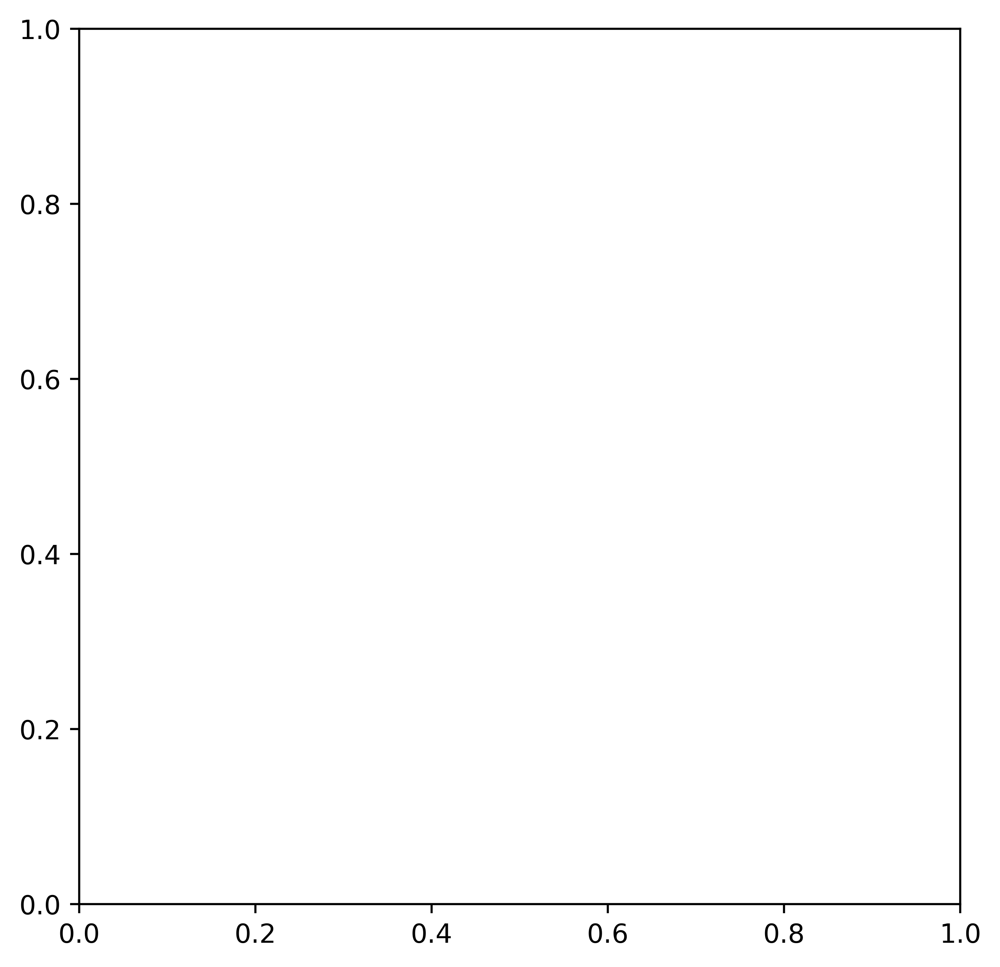

In [ ]:
sc.pl.umap(adata, color=['cell_type_broad'], use_raw=False, cmap='Reds')

In [ ]:
sc.tl.rank_genes_groups(
    adata,
    groupby='final_cell_type_specific',
    method='wilcoxon'
)

In [ ]:
sc.pl.dotplot(
    adata,
    var_names={
        group: adata.uns['rank_genes_groups']['names'][group][:5]
        for group in adata.obs['leiden'].cat.categories
    },
    groupby='leiden',
    use_raw=False
)

In [ ]:
import pandas as pd
import scanpy as sc

# 1. Ensure raw/unscaled count data or appropriate normalized matrix is used
# (Differential expression works best on raw counts or log-normalized expression)
# If your raw/log-normalized counts are in a layer, set use_raw=False and layer='counts' or log1p layer
sc.tl.rank_genes_groups(
    adata,
    groupby="final_cell_type_broad",
    method="wilcoxon",  # 'wilcoxon', 't-test', or 'logreg'
    pts=True,  # Optional: computes fraction of cells expressing genes in each group
)

# 2. Extract top 10 genes per cluster into a clean Pandas DataFrame
marker_genes_df = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(
    10
)
print("Top 10 marker genes per cell type:")
print(marker_genes_df)

# 3. Optional: Visualize as a dotplot or matrixplot
sc.pl.rank_genes_groups_dotplot(
    adata, n_genes=10, groupby="final_cell_type_broad"
)

KeyboardInterrupt: 

In [ ]:
# Load cell cycle genes defined in Tirosh et al, 2015. It is a list of 97 genes, represented by their gene symbol. The list here is for humans. There are major differences in the way Scanpy and Seurat manage data, in particular we need to filter out cell cycle genes that are not present in our dataset to avoid errors.
!wget https://www.dropbox.com/s/3dby3bjsaf5arrw/cell_cycle_vignette_files.zip?dl=1
!unzip cell_cycle_vignette_files.zip?dl=1
cell_cycle_genes = [x.strip() for x in open('/content/regev_lab_cell_cycle_genes.txt')]

--2026-10-02 11:59:41--  https://www.dropbox.com/s/3dby3bjsaf5arrw/cell_cycle_vignette_files.zip?dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/mzbkka6g9lgrzv6bxkhjp/cell_cycle_vignette_files.zip?rlkey=3xuy9ppsf7nyqhgdge92wcyld&dl=1 [following]
--2026-10-02 11:59:41--  https://www.dropbox.com/scl/fi/mzbkka6g9lgrzv6bxkhjp/cell_cycle_vignette_files.zip?rlkey=3xuy9ppsf7nyqhgdge92wcyld&dl=1
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc01cca2eb328f3803d5cd706b2f.dl.dropboxusercontent.com/cd/0/inline/DJO03kk1c_SkynafxnngpR4goM2Oa2H_fyTRvJf5APh7UEBj_cA3G7izxYqlNx5AZddaIJPF8HtbT_Z8N_IJ6adMeDA2qLrR6KCVA9iCKMQvo7cjKgvy0XpnhN-tRwN8WtA/file?dl=1# [following]
--2026-10-02 11:59:42--  https://uc01cca2eb328f3803

In [ ]:
# Here we define two lists, genes associated to the S phase and genes associated to the G2M phase
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
cell_cycle_genes = [x for x in cell_cycle_genes if x in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)

/usr/local/lib/python3.13/dist-packages/scanpy/preprocessing/_pca/__init__.py:357: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca
/tmp/ipykernel_1866/247865339.py:3: FutureWarning: The function pca_scatter is deprecated and will be removed in the future. Use :func:`scanpy.pl.pca` instead.
  sc.pl.pca_scatter(adata_cc_genes, color='phase')


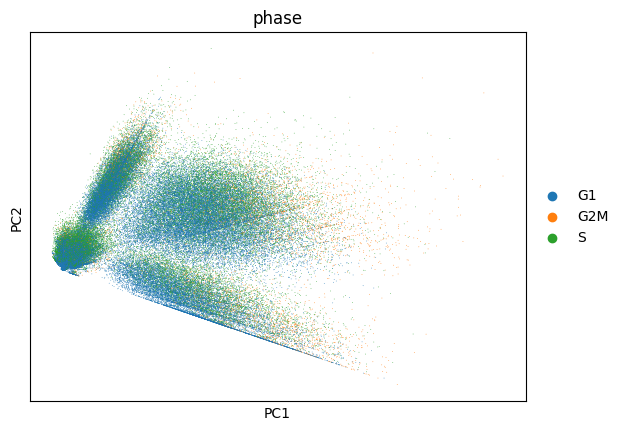

In [ ]:
adata_cc_genes = adata[:, cell_cycle_genes]
sc.tl.pca(adata_cc_genes)
sc.pl.pca_scatter(adata_cc_genes, color='phase')

In [ ]:
adata.obs["phase"].value_counts(normalize=True) * 100

phase
G1     64.010123
S      30.131996
G2M     5.857881
Name: proportion, dtype: float64

/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()
/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


(-9.62596607208252, 11.428664207458496)

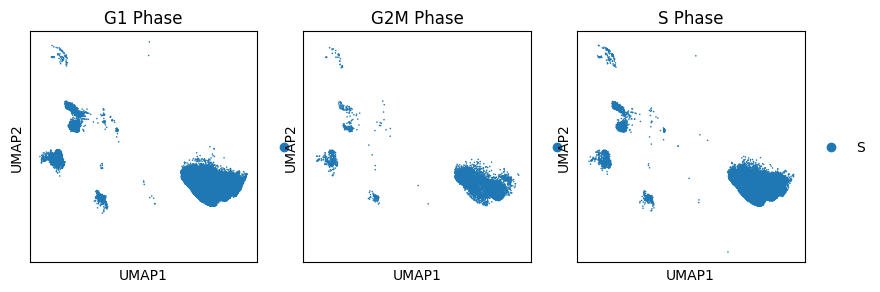

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt

# Extract limits from full UMAP
xlim = (adata.obsm['X_umap'][:, 0].min(), adata.obsm['X_umap'][:, 0].max())
ylim = (adata.obsm['X_umap'][:, 1].min(), adata.obsm['X_umap'][:, 1].max())

#add extra 5%
xlim = (xlim[0] - 0.05 * (xlim[1] - xlim[0]), xlim[1] + 0.05 * (xlim[1] - xlim[0]))
ylim = (ylim[0] - 0.05 * (ylim[1] - ylim[0]), ylim[1] + 0.05 * (ylim[1] - ylim[0]))
# Set dot size
dot_size = 5

# Create 3 subplots
fig, axs = plt.subplots(1, 3, figsize=(10, 3))

blue_colormap = plt.cm.Blues
orange_colormap = plt.cm.Oranges
green_colormap = plt.cm.Greens
# Plot G1 Phase
sc.pl.umap(
    adata[adata.obs["phase"] == "G1"],
    color='phase',
    title='G1 Phase',
    color_map=blue_colormap,
    size=dot_size,
    show=False,
    ax=axs[0]
)
axs[0].set_xlim(xlim)
axs[0].set_ylim(ylim)

# Plot G2M Phase
sc.pl.umap(
    adata[adata.obs["phase"] == "G2M"],
    color='phase',
    title='G2M Phase',
    color_map=orange_colormap,
    size=dot_size,
    show=False,
    ax=axs[1]
)
axs[1].set_xlim(xlim)
axs[1].set_ylim(ylim)

# Plot S Phase
sc.pl.umap(
    adata[adata.obs["phase"] == "S"],
    color='phase',
    title='S Phase',
    color_map=green_colormap,
    size=dot_size,
    show=False,
    ax=axs[2]
)
axs[2].set_xlim(xlim)
axs[2].set_ylim(ylim)



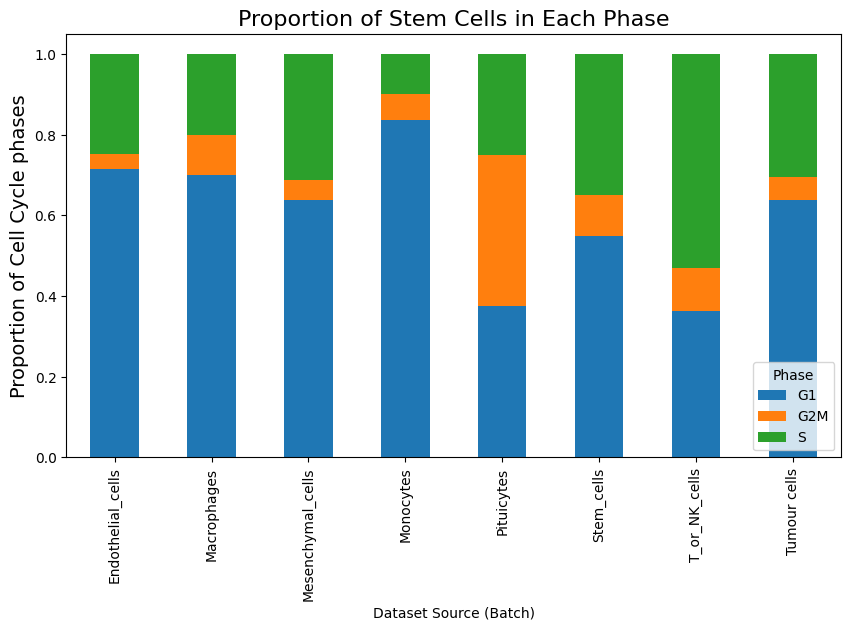

In [ ]:

# Calculate counts and normalize
cluster_counts = adata.obs.groupby(['final_cell_type_broad', 'phase']).size().unstack(fill_value=0)
cluster_proportions = cluster_counts.div(cluster_counts.sum(axis=1), axis=0)

# Reindex to ensure consistent cluster order
cluster_proportions = cluster_proportions.reindex(sorted(cluster_proportions.columns), axis=1)

# Create the stacked bar plot
colors=["#1f77b4",  "#ff7f0e",  "#2ca02c"]
cluster_proportions.plot(kind='bar', stacked=True, color=colors, figsize=(10, 5.5))

#rotate x ticks
plt.xticks(rotation=90)

# Add labels and title
plt.xlabel('Dataset Source (Batch)')
plt.ylabel('Proportion of Cell Cycle phases', fontsize=14)
plt.title('Proportion of Stem Cells in Each Phase', fontsize=16)
plt.legend(title='Phase', loc='lower right')


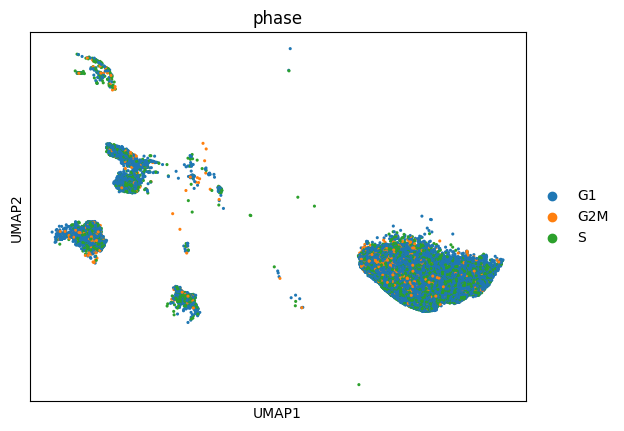

In [ ]:
sc.pl.umap(
    adata,
    color="phase",
    size=20,
    alpha=1
)

In [ ]:
metabolic_signatures = {
  # Glycolysis / Warburg Effect
  "Glycolysis": ["HK1", "HK2", "GPI", "PFKP", "ALDOA", "GAPDH", "PGK1", "PGAM1", "ENO1", "PKM", "LDHA", "SLC2A1"],

  # Oxidative Phosphorylation
  "OxPhos": ["NDUFA9", "NDUFS4", "SDHA", "SDHB", "UQCRFS1", "COX4I1", "ATP5F1A", "CYCS", "COX5A"],

  # Fatty Acid Oxidation (FAO)
  "FAO": ["CPT1A", "CPT2", "ACADVL", "ACADM", "HADHA", "HADHB", "ACAT1"],

  # Glutaminolysis / Amino Acid Metabolism
  "Glutaminolysis": ["SLC1A5", "GLS", "GLS2", "GLUD1", "GOT1", "GOT2"]
}

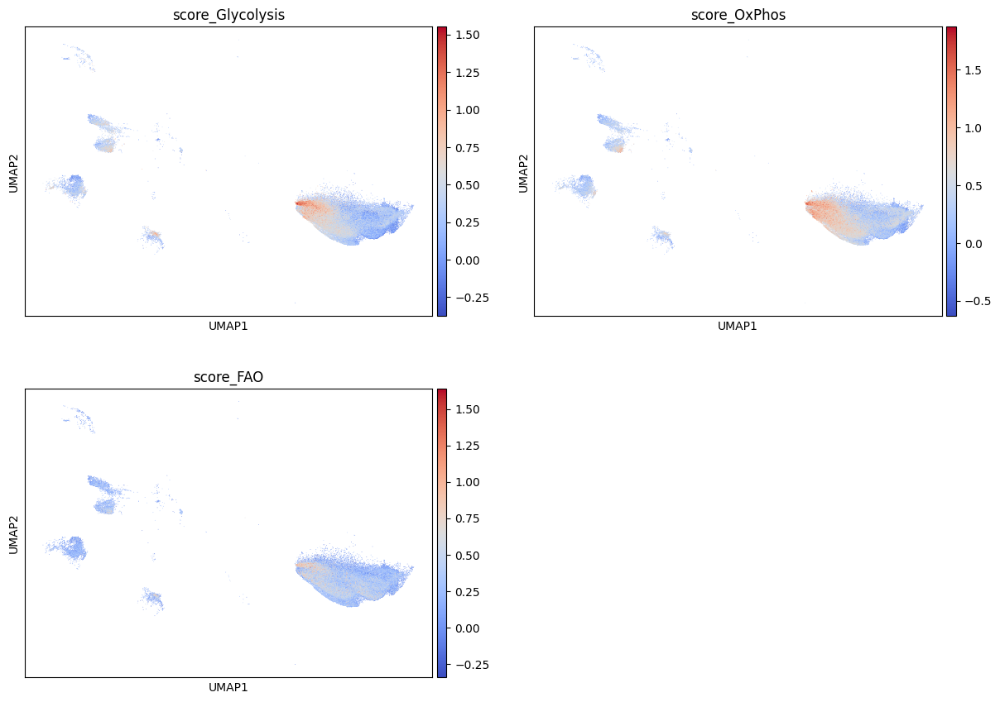

In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define key metabolic gene signatures
glycolysis_genes = [
    "HK1", "HK2", "GPI", "PFKP", "ALDOA", "GAPDH",
    "PGK1", "PGAM1", "ENO1", "PKM", "LDHA", "SLC2A1"
]

oxphos_genes = [
    "NDUFA9", "NDUFS4", "SDHA", "SDHB", "UQCRFS1",
    "COX4I1", "ATP5F1A", "CYCS", "COX5A"
]

fao_genes = [
    "CPT1A", "CPT2", "ACADVL", "ACADM", "HADHA", "HADHB", "ACAT1"
]

# 2. Score pathways using Scanpy
# Ensure genes exist in your dataset
glyco_valid = [g for g in glycolysis_genes if g in adata.var_names]
oxphos_valid = [g for g in oxphos_genes if g in adata.var_names]
fao_valid = [g for g in fao_genes if g in adata.var_names]

sc.tl.score_genes(adata, gene_list=glyco_valid, score_name='score_Glycolysis')
sc.tl.score_genes(adata, gene_list=oxphos_valid, score_name='score_OxPhos')
sc.tl.score_genes(adata, gene_list=fao_valid, score_name='score_FAO')


# 3. Visualize across tumor subpopulations
sc.pl.umap(
    adata,
    color=['score_Glycolysis', 'score_OxPhos', "score_FAO"],
    color_map='coolwarm',
    ncols=2
)


In [ ]:
print("Glycolysis:", len(glyco_valid), glyco_valid)
print("OxPhos:", len(oxphos_valid), oxphos_valid)
print("FAO:", len(fao_valid), fao_valid)

Glycolysis: 12 ['HK1', 'HK2', 'GPI', 'PFKP', 'ALDOA', 'GAPDH', 'PGK1', 'PGAM1', 'ENO1', 'PKM', 'LDHA', 'SLC2A1']
OxPhos: 9 ['NDUFA9', 'NDUFS4', 'SDHA', 'SDHB', 'UQCRFS1', 'COX4I1', 'ATP5F1A', 'CYCS', 'COX5A']
FAO: 7 ['CPT1A', 'CPT2', 'ACADVL', 'ACADM', 'HADHA', 'HADHB', 'ACAT1']


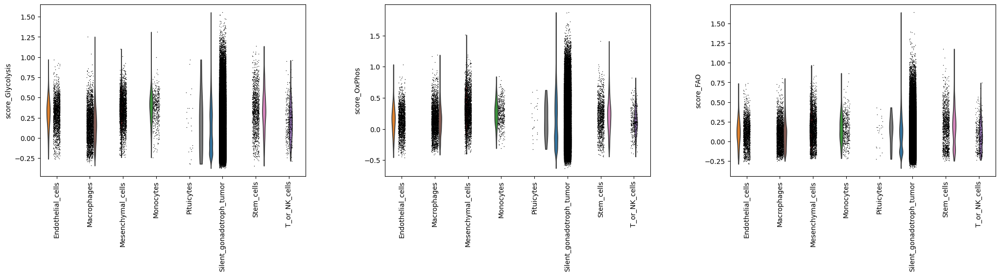

In [ ]:
sc.pl.violin(
    adata,
    keys=["score_Glycolysis", "score_OxPhos", "score_FAO"],
    groupby="final_cell_type_specific",
    rotation=90
)

In [ ]:
phase_colors = {
    "G1": "#0072B2",
    "S": "#E69F00",
    "G2M": "#D55E00"
}

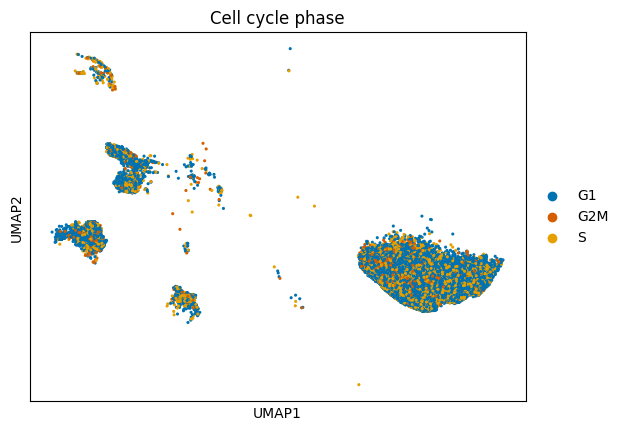

In [ ]:
sc.pl.umap(
    adata,
    color="phase",
    palette=phase_colors,
    size=20,
    alpha=1,
    title="Cell cycle phase"
)

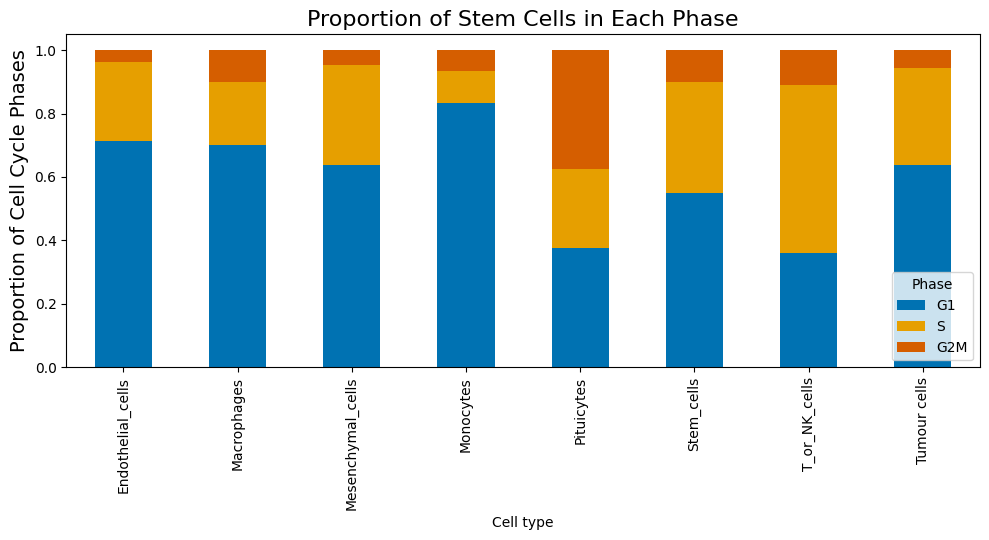

In [ ]:
# Calculate counts and normalize
cluster_counts = (
    adata.obs
    .groupby(["final_cell_type_broad", "phase"])
    .size()
    .unstack(fill_value=0)
)

cluster_proportions = cluster_counts.div(
    cluster_counts.sum(axis=1),
    axis=0
)

# Make sure columns are in the same order as the colour dictionary
cluster_proportions = cluster_proportions.reindex(
    columns=phase_colors.keys(),
    fill_value=0
)

# Plot
ax = cluster_proportions.plot(
    kind="bar",
    stacked=True,
    color=[phase_colors[x] for x in cluster_proportions.columns],
    figsize=(10, 5.5)
)

plt.xticks(rotation=90)
plt.xlabel("Cell type")
plt.ylabel("Proportion of Cell Cycle Phases", fontsize=14)
plt.title("Proportion of Stem Cells in Each Phase", fontsize=16)
plt.legend(title="Phase", loc="lower right")

plt.tight_layout()
plt.show()

In [ ]:
adata_stem = adata[adata.obs["final_cell_type_broad"] == "Stem_cells"].copy()


In [ ]:
adata_tumour = adata[adata.obs["final_cell_type_broad"] == "Tumour cells"].copy()

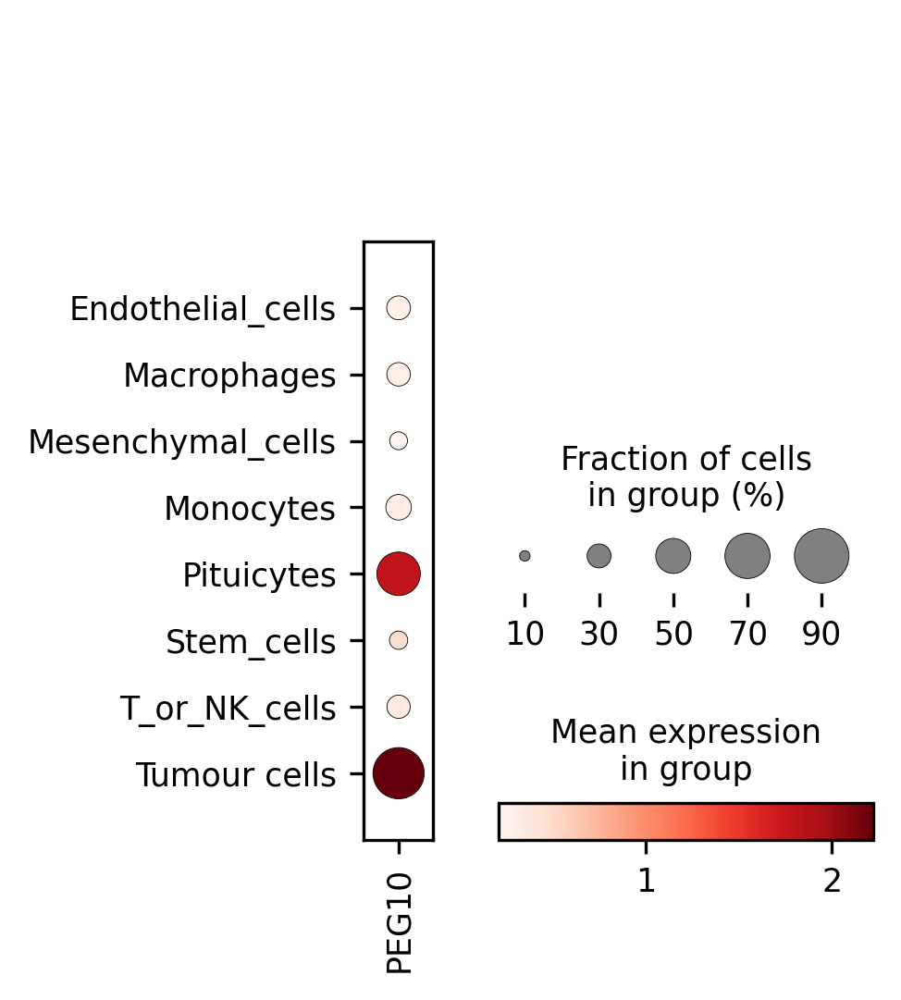

In [ ]:
sc.pl.dotplot(
    adata,
    var_names=["PEG10"],
    groupby="final_cell_type_broad",
    use_raw=False
)


In [ ]:
adata_tumour

AnnData object with n_obs × n_vars = 0 × 39074
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'assay', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'Internal_ID', 'Name', 'Normal', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'n_cells', 'pct_counts_in_top_20_genes', 'SRA_barcode', 'cell_type', 'leiden_scVI', 'leiden_scVI_final', 'final_cell_type_broad', 'final_cell_type_specific'
    var: 'mt', 'ribo', 'malat', 'n_cells_by_counts', 'mean_coun

In [ ]:
adata_stem

AnnData object with n_obs × n_vars = 1253 × 39074
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'assay', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'Internal_ID', 'Name', 'Normal', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'n_cells', 'pct_counts_in_top_20_genes', 'SRA_barcode', 'cell_type', 'leiden_scVI', 'leiden_scVI_final', 'final_cell_type_broad', 'final_cell_type_specific'
    var: 'mt', 'ribo', 'malat', 'n_cells_by_counts', 'mean_c

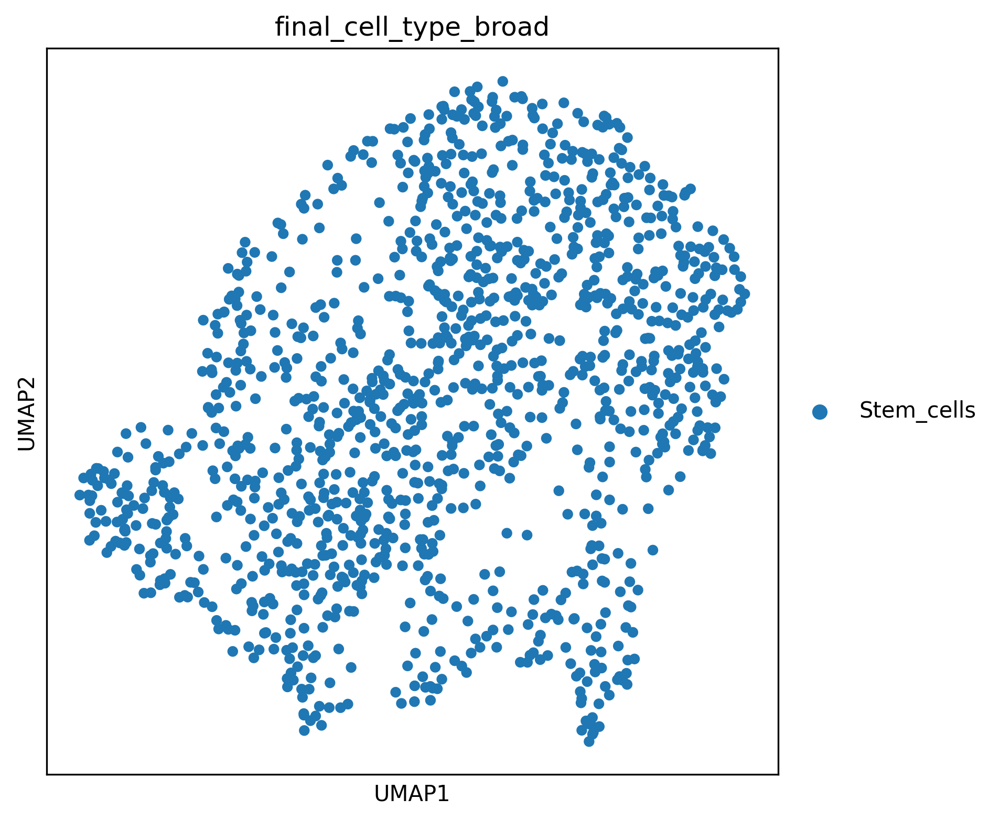

In [ ]:
import scanpy as sc

sc.pl.umap(
    adata_stem,
    color="final_cell_type_broad"
)

/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_tools/scatterplots.py:235: RuntimeWarning: divide by zero encountered in scalar divide
  size = 120000 / (~np.isnan(basis_values).any(axis=1)).sum()
/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_tools/scatterplots.py:1195: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(


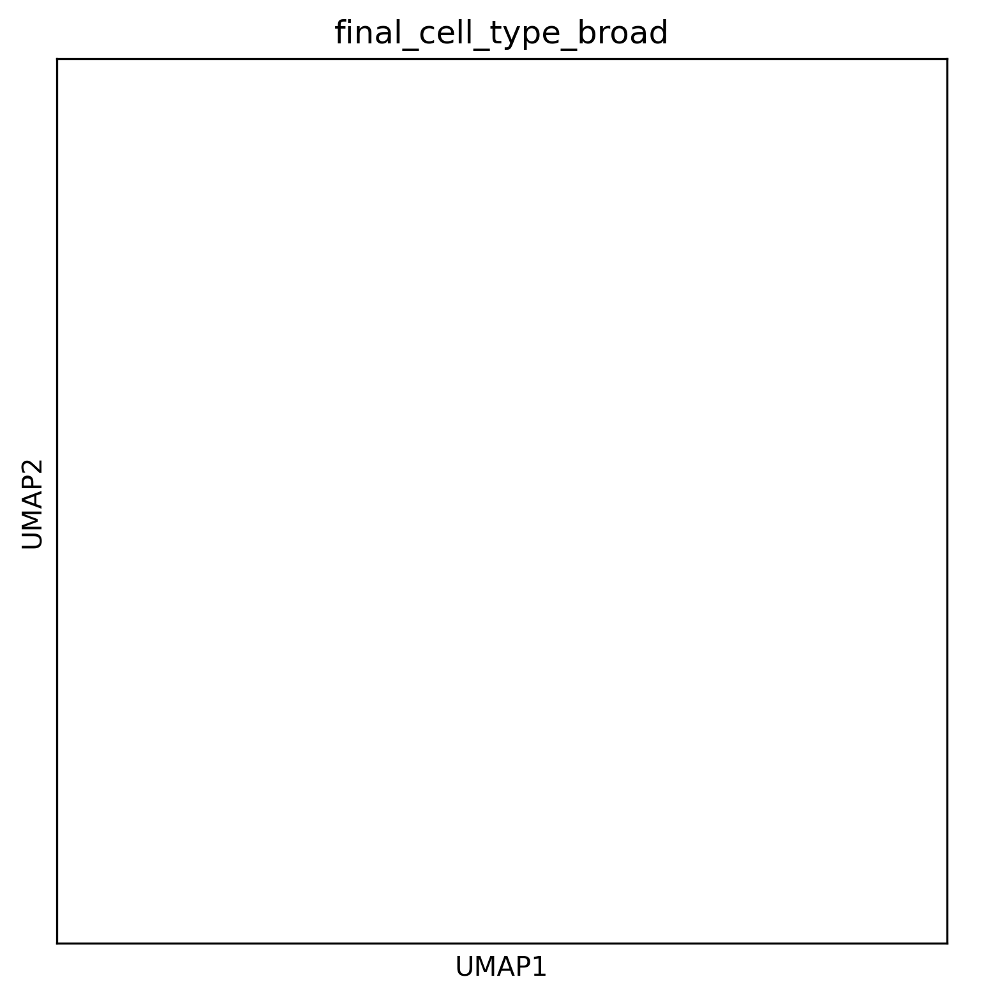

In [ ]:
import scanpy as sc

sc.pl.umap(
    adata_tumour,
    color="final_cell_type_broad"
)

Number of cells in adata_tumour: 94713


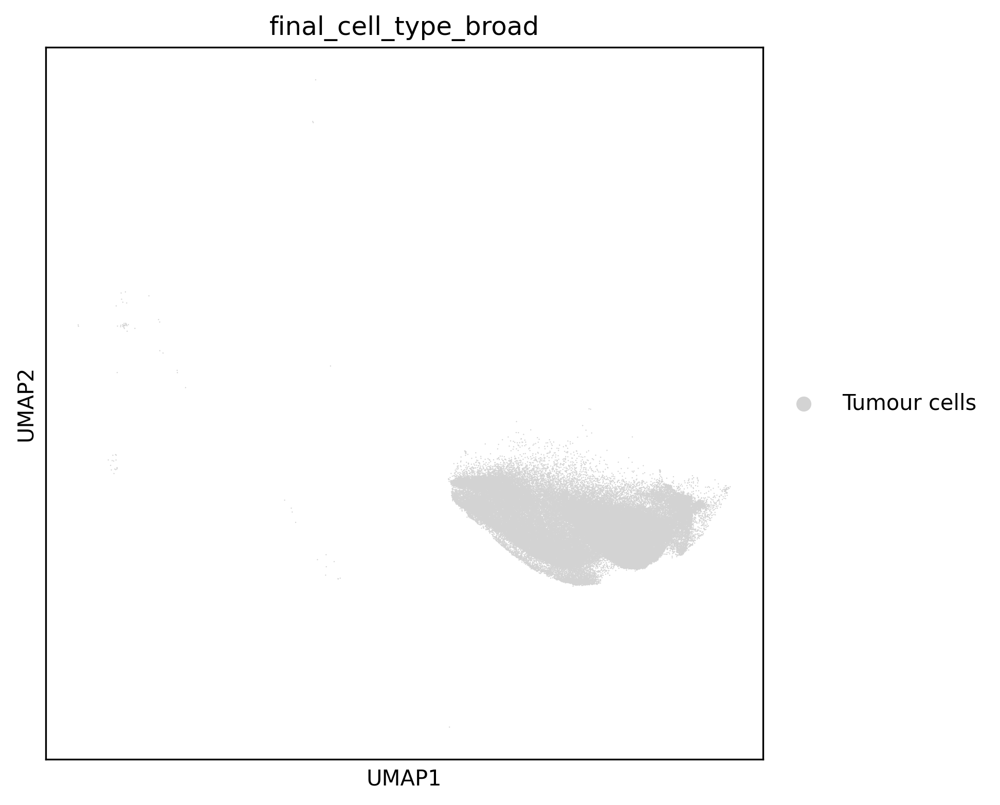

In [ ]:
import scanpy as sc

# Safely recreate adata_tumour by matching 'tumour cells' case-insensitively
tumour_mask = adata.obs["final_cell_type_broad"].astype(str).str.lower() == "tumour cells"
adata_tumour = adata[tumour_mask].copy()

print(f"Number of cells in adata_tumour: {adata_tumour.n_obs}")

# Now plot UMAP successfully
if adata_tumour.n_obs > 0:
    sc.pl.umap(adata_tumour, color="final_cell_type_broad")
else:
    print("Error: No cells matched 'Tumour cells' in the dataset.")

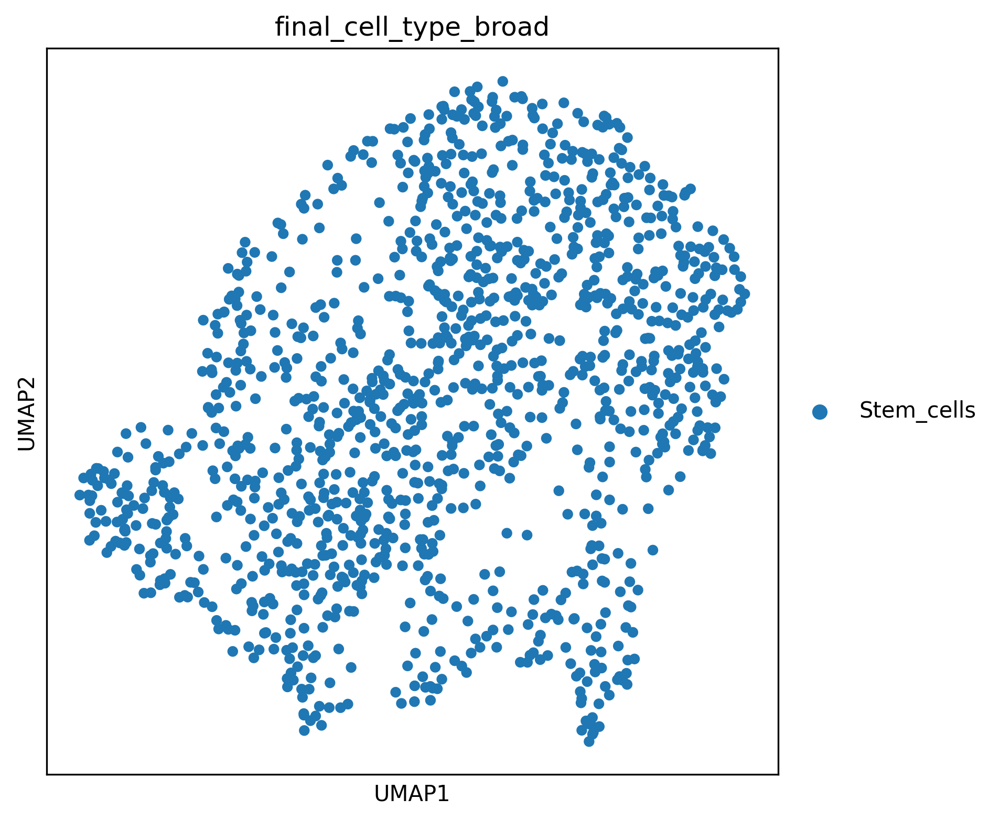

In [ ]:
import scanpy as sc

sc.pl.umap(
    adata_stem,
    color="final_cell_type_broad"
)

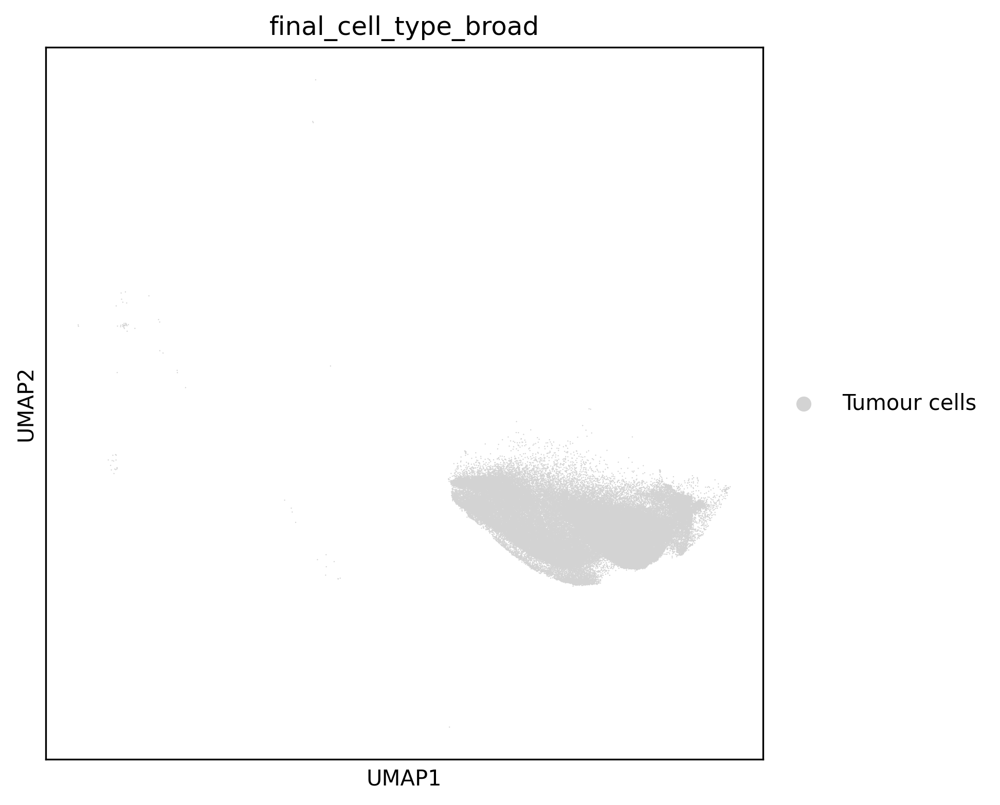

In [ ]:
import scanpy as sc

sc.pl.umap(
    adata_tumour,
    color="final_cell_type_broad"
)

In [ ]:
import scanpy as sc

sc.pp.neighbors(
    adata_tumour,
    use_rep="X_scVI",
    n_neighbors=15
)

InvalidParameterError: The 'n_neighbors' parameter of KNeighborsTransformer must be an int in the range [1, inf) or None. Got -1 instead.

In [ ]:
sc.tl.umap(adata_tumour)

sc.pl.umap(
    adata_tumour,
    color="final_cell_type_broad",
    palette=["#E41A1C"]  # Sets the cluster color to bright red
)


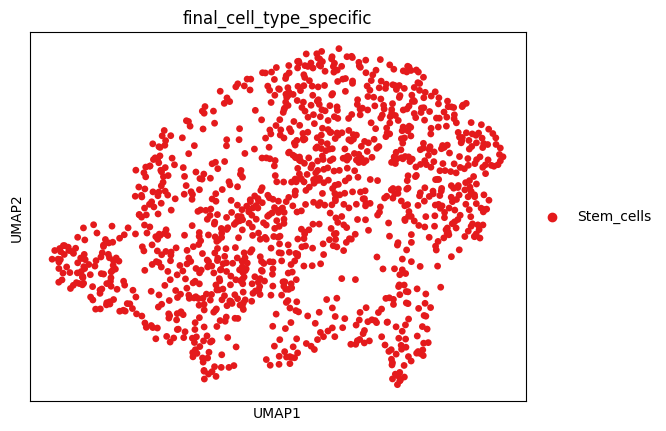

In [ ]:
sc.tl.umap(adata_stem)

sc.pl.umap(
    adata_stem,
    color="final_cell_type_specific",
    palette=["#E41A1C"]  # Sets the cluster color to bright red
)


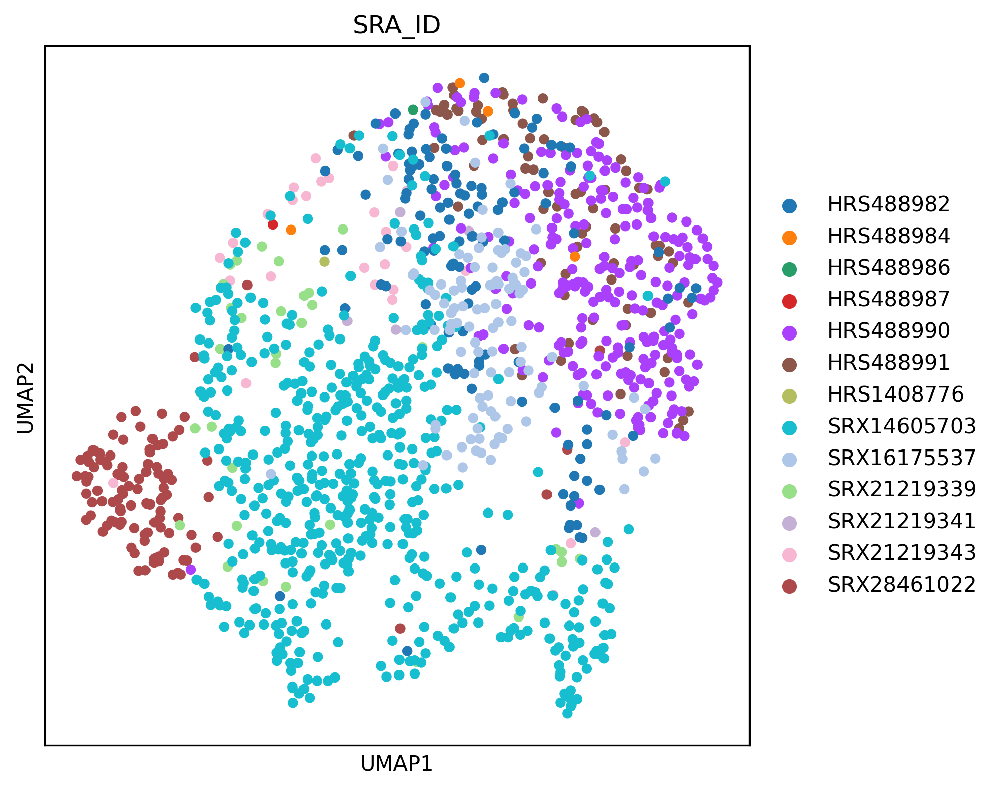

In [ ]:
sc.tl.umap(adata_stem)

sc.pl.umap(
    adata_stem,
    color="SRA_ID"
)

In [ ]:
sc.tl.umap(adata_tumour)

sc.pl.umap(
    adata_tumour,
    color="SRA_ID"
)

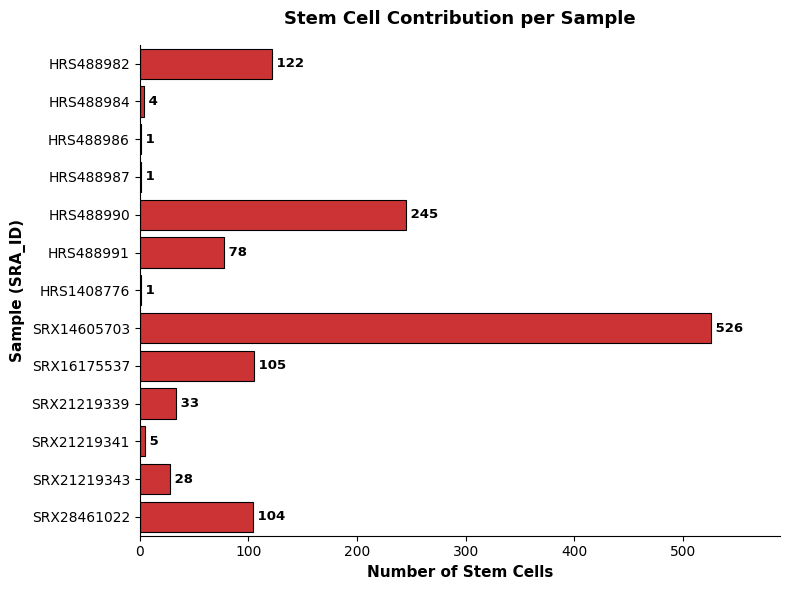

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract stem counts and sort from largest to smallest
stem_counts = (
    adata[adata.obs["final_cell_type_broad"] == "Stem_cells"]
    .obs["SRA_ID"]
    .value_counts()
    .sort_values(ascending=True)  # Ascending so highest is at top
)

# 2. Create horizontal bar plot
plt.figure(figsize=(8, 6))
ax = sns.barplot(
    x=stem_counts.values,
    y=stem_counts.index,
    color="#E41A1C",
    edgecolor="black",
    linewidth=0.8,
)

# 3. Add count labels to the right of each bar
max_val = stem_counts.max()
for p in ax.patches:
    width = int(p.get_width())
    if width > 0:
        ax.annotate(
            f" {width}",
            (width, p.get_y() + p.get_height() / 2.0),
            ha="left",
            va="center",
            fontsize=9.5,
            weight="bold",
        )

plt.xlim(0, max_val * 1.12)  # Add right margin so numbers don't touch edge
plt.xlabel("Number of Stem Cells", fontsize=11, weight="bold")
plt.ylabel("Sample (SRA_ID)", fontsize=11, weight="bold")
plt.title(
    "Stem Cell Contribution per Sample", fontsize=13, weight="bold", pad=15
)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_688/1559107858.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


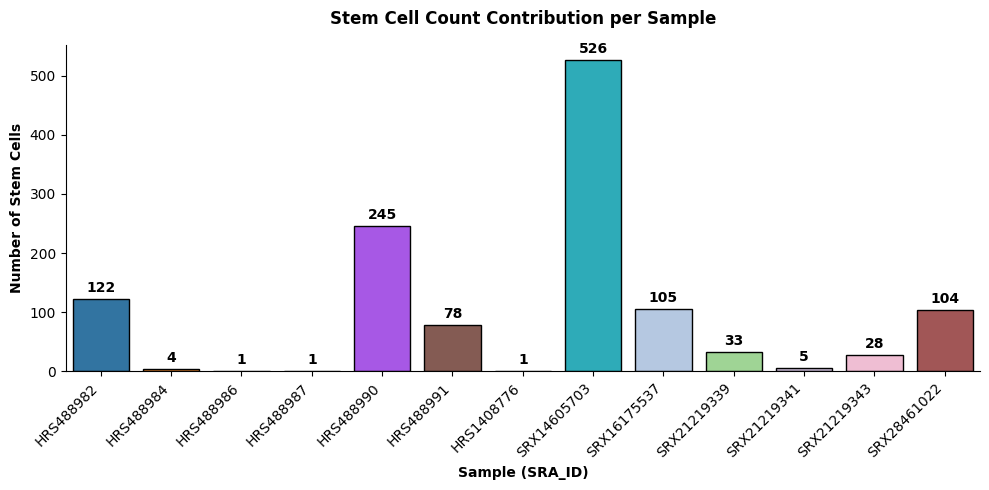

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract stem counts and sort them
stem_counts = (
    adata[adata.obs["final_cell_type_broad"] == "Stem_cells"]
    .obs["SRA_ID"]
    .value_counts()
    .sort_values(ascending=True)
)

# 2. Extract original categories and Scanpy colors for SRA_ID
sra_categories = adata.obs["SRA_ID"].cat.categories
sra_colors = adata.uns["SRA_ID_colors"]

# Map each SRA_ID category to its exact color
color_dict = dict(zip(sra_categories, sra_colors))

# 3. Create the plot using the exact mapped palette
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=stem_counts.index,
    y=stem_counts.values,
    palette=color_dict,
    edgecolor="black",
)

# Add value labels above bars
for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(
            f"{height}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points",
            fontweight="bold",
        )

plt.xticks(rotation=45, ha="right")
plt.xlabel("Sample (SRA_ID)", fontweight="bold")
plt.ylabel("Number of Stem Cells", fontweight="bold")
plt.title("Stem Cell Count Contribution per Sample", fontweight="bold", pad=15)
sns.despine()
plt.tight_layout()
plt.show()

/tmp/ipykernel_688/2285223893.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


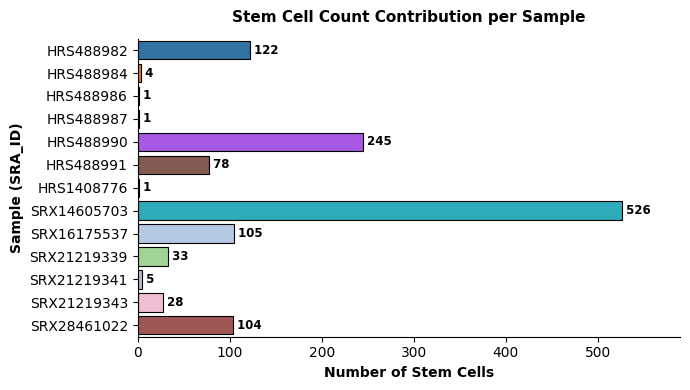

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract stem counts and sort in ascending order (so highest appears at top)
stem_counts = (
    adata[adata.obs["final_cell_type_broad"] == "Stem_cells"]
    .obs["SRA_ID"]
    .value_counts()
    .sort_values(ascending=True)
)

# 2. Extract original categories and Scanpy colors for SRA_ID
sra_categories = adata.obs["SRA_ID"].cat.categories
sra_colors = adata.uns["SRA_ID_colors"]
color_dict = dict(zip(sra_categories, sra_colors))

# 3. Create a compact horizontal bar plot
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    y=stem_counts.index,
    x=stem_counts.values,
    palette=color_dict,
    edgecolor="black",
    linewidth=0.8,
)

# 4. Add count labels right next to each bar
max_val = stem_counts.max()
for p in ax.patches:
    width = int(p.get_width())
    if width > 0:
        ax.annotate(
            f" {width}",
            (width, p.get_y() + p.get_height() / 2.0),
            ha="left",
            va="center",
            fontsize=8.5,
            fontweight="bold",
        )

# Adjust padding and labels for a clean, compact publication format
plt.xlim(0, max_val * 1.12)
plt.xlabel("Number of Stem Cells", fontweight="bold", fontsize=10)
plt.ylabel("Sample (SRA_ID)", fontweight="bold", fontsize=10)
plt.title("Stem Cell Count Contribution per Sample", fontweight="bold", fontsize=11, pad=12)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_984/4078576131.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


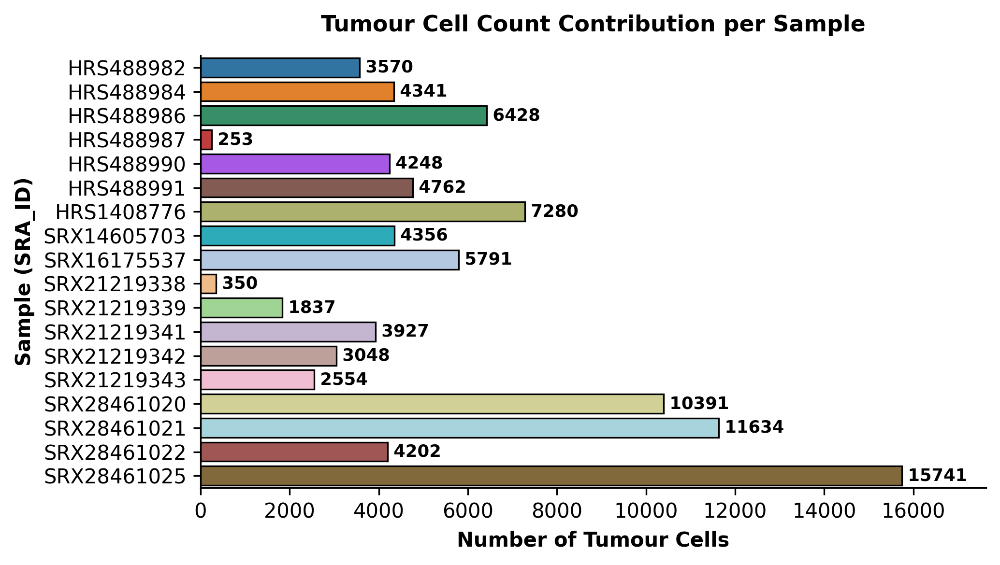

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract tumour counts and sort in ascending order (so highest appears at top)
tumour_counts = (
    adata[adata.obs["final_cell_type_broad"] == "Tumour cells"]
    .obs["SRA_ID"]
    .value_counts()
    .sort_values(ascending=True)
)

# 2. Extract original categories and Scanpy colors for SRA_ID
sra_categories = adata.obs["SRA_ID"].cat.categories
sra_colors = adata.uns["SRA_ID_colors"]
color_dict = dict(zip(sra_categories, sra_colors))

# 3. Create a compact horizontal bar plot
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    y=tumour_counts.index,
    x=tumour_counts.values,
    palette=color_dict,
    edgecolor="black",
    linewidth=0.8,
)

# 4. Add count labels right next to each bar
max_val = tumour_counts.max()
for p in ax.patches:
    width = int(p.get_width())
    if width > 0:
        ax.annotate(
            f" {width}",
            (width, p.get_y() + p.get_height() / 2.0),
            ha="left",
            va="center",
            fontsize=8.5,
            fontweight="bold",
        )

# Adjust padding and labels for a clean, compact publication format
plt.xlim(0, max_val * 1.12)
plt.xlabel("Number of Tumour Cells", fontweight="bold", fontsize=10)
plt.ylabel("Sample (SRA_ID)", fontweight="bold", fontsize=10)
plt.title("Tumour Cell Count Contribution per Sample", fontweight="bold", fontsize=11, pad=12)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract stem counts and sort in ascending order (so highest appears at top)
stem_counts = (
    adata[adata.obs["final_cell_type_broad"] == "Tumour cells"]
    .obs["SRA_ID"]
    .value_counts()
    .sort_values(ascending=True)
)

# 2. Extract original categories and Scanpy colors for SRA_ID
sra_categories = adata.obs["SRA_ID"].cat.categories
sra_colors = adata.uns["SRA_ID_colors"]
color_dict = dict(zip(sra_categories, sra_colors))

# 3. Create a compact horizontal bar plot
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    y=stem_counts.index,
    x=stem_counts.values,
    palette=color_dict,
    edgecolor="black",
    linewidth=0.8,
)

# 4. Add count labels right next to each bar
max_val = stem_counts.max()
for p in ax.patches:
    width = int(p.get_width())
    if width > 0:
        ax.annotate(
            f" {width}",
            (width, p.get_y() + p.get_height() / 2.0),
            ha="left",
            va="center",
            fontsize=8.5,
            fontweight="bold",
        )

# Adjust padding and labels for a clean, compact publication format
plt.xlim(0, max_val * 1.12)
plt.xlabel("Number of Stem Cells", fontweight="bold", fontsize=10)
plt.ylabel("Sample (SRA_ID)", fontweight="bold", fontsize=10)
plt.title("Stem Cell Count Contribution per Sample", fontweight="bold", fontsize=11, pad=12)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

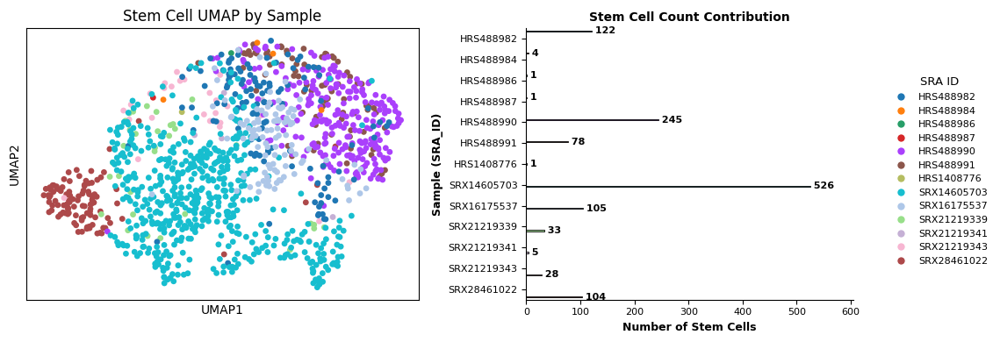

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc
import seaborn as sns

# 1. Prepare stem cell count data (sorted so highest is at top)
stem_counts = (
    adata[adata.obs["final_cell_type_broad"] == "Stem_cells"]
    .obs["SRA_ID"]
    .value_counts()
    .sort_values(ascending=True)
)

# 2. Extract original SRA_ID categories and matching colors
sra_categories = adata_stem.obs["SRA_ID"].cat.categories
sra_colors = adata_stem.uns["SRA_ID_colors"]
color_dict = dict(zip(sra_categories, sra_colors))

# 3. Initialize side-by-side figure layout
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.2, 1]}
)

# --- Panel A: UMAP (No built-in legend) ---
sc.pl.umap(
    adata_stem,
    color="SRA_ID",
    palette=color_dict,
    ax=ax1,
    show=False,
    legend_loc=None,  # Hide standard legend
    title="Stem Cell UMAP by Sample",
)

# --- Panel B: Colored Horizontal Bar Plot ---
sns.barplot(
    y=stem_counts.index,
    x=stem_counts.values,
    hue=stem_counts.index,  # Maps color to each bar
    palette=color_dict,  # Uses exact sample hex colors
    legend=False,
    edgecolor="black",
    linewidth=0.6,
    ax=ax2,
)

# Add numeric labels to the right of each bar
max_val = stem_counts.max()
for p in ax2.patches:
    width = int(p.get_width())
    if width > 0:
        ax2.annotate(
            f" {width}",
            (width, p.get_y() + p.get_height() / 2.0),
            ha="left",
            va="center",
            fontsize=8,
            fontweight="bold",
        )

# Format axes for bar chart
ax2.set_xlim(0, max_val * 1.15)
ax2.set_xlabel("Number of Stem Cells", fontweight="bold", fontsize=9)
ax2.set_ylabel("Sample (SRA_ID)", fontweight="bold", fontsize=9)
ax2.set_title("Stem Cell Count Contribution", fontweight="bold", fontsize=10)
ax2.tick_params(axis="both", labelsize=8)
sns.despine(ax=ax2, top=True, right=True)

# --- 4. Single Shared Legend on Far Right ---
legend_handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=color_dict[sra],
        markersize=7,
        label=sra,
    )
    for sra in sra_categories
]

fig.legend(
    handles=legend_handles,
    title="SRA ID",
    title_fontsize=9.5,
    fontsize=8,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False,
)

plt.tight_layout()
plt.show()

In [ ]:
sc.tl.leiden(
    adata_stem,
    resolution=0.5,
    key_added="stem_leiden"
)

/tmp/ipykernel_46918/1704928521.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(


ModuleNotFoundError: No module named 'leidenalg'

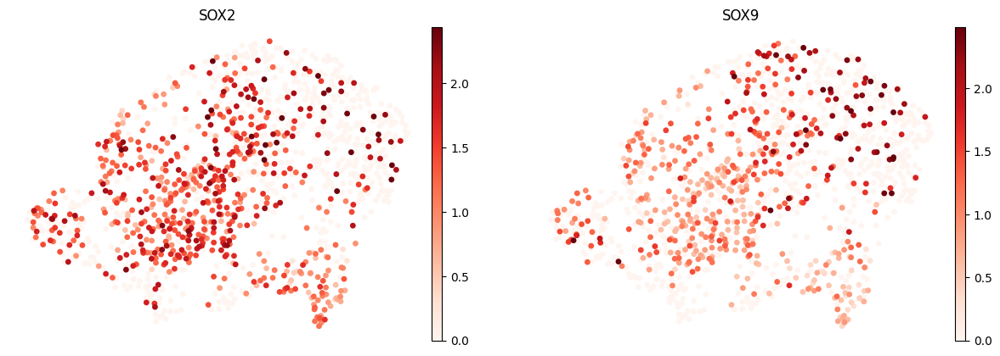

In [ ]:
import scanpy as sc

# Plot SOX2 and SOX9 expression side-by-side on the UMAP
sc.pl.umap(
    adata_stem,
    color=["SOX2", "SOX9"],
    color_map="Reds",  # Continuous red intensity scale
    frameon=False,  # Removes axis box for a clean publication look
    ncols=2,  # Places plots side-by-side
    vmax="p99",  # Clips extreme upper outliers for better contrast
)

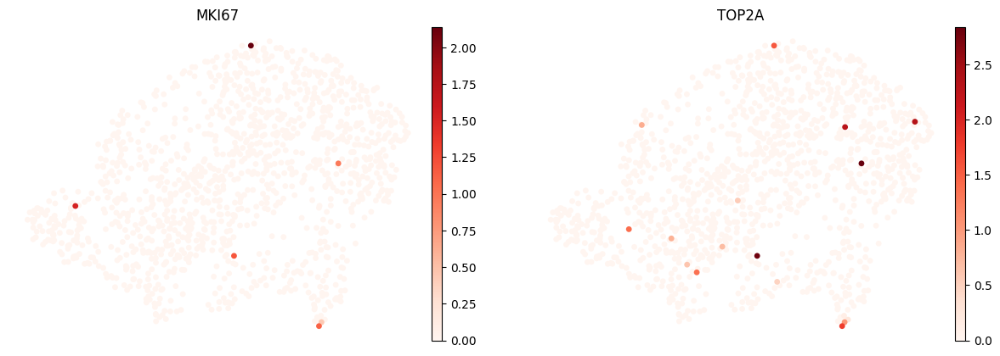

In [ ]:
import scanpy as sc

# Plot SOX2, SOX9, and MKI67 expression side-by-side
sc.pl.umap(
    adata_stem,
    color=["MKI67", "TOP2A"],
    color_map="Reds",  # Continuous red intensity scale
    frameon=False,  # Removes axis box for clean look
    ncols=3,  # Places all 3 plots in a single row
)

MKI67+: 7/1253 cells (0.6% of stem cells)
TOP2A+: 17/1253 cells (1.4% of stem cells)


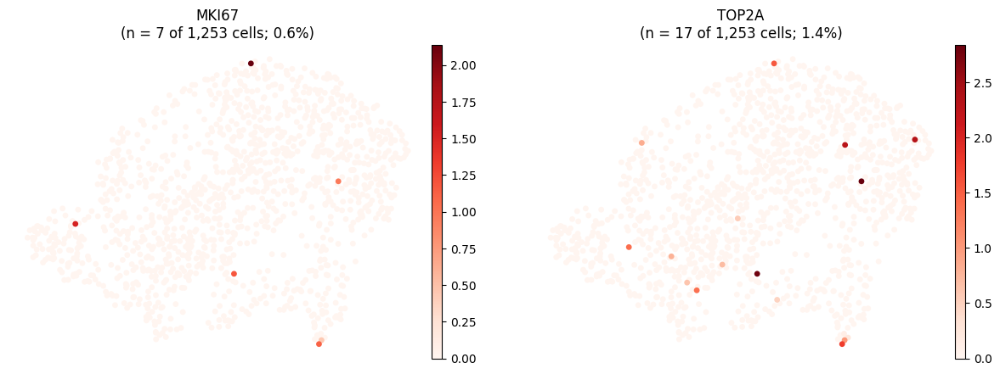

In [ ]:
import numpy as np
import scanpy as sc

# 1. Total stem cells
total_stem = adata_stem.n_obs


# 2. Function to compute positive cell count & percentage
def get_pos_stats(adata, gene):
    # Retrieve raw/normalized vector for the gene
    expr = (
        adata[:, gene].X.toarray().flatten()
        if hasattr(adata[:, gene].X, "toarray")
        else adata[:, gene].X.flatten()
    )
    n_pos = np.sum(expr > 0)
    pct_pos = (n_pos / total_stem) * 100
    return n_pos, pct_pos


# Calculate stats
mki67_n, mki67_pct = get_pos_stats(adata_stem, "MKI67")
top2a_n, top2a_pct = get_pos_stats(adata_stem, "TOP2A")

# Print summary to console/caption
print(
    f"MKI67+: {mki67_n}/{total_stem} cells ({mki67_pct:.1f}% of stem cells)"
)
print(
    f"TOP2A+: {top2a_n}/{total_stem} cells ({top2a_pct:.1f}% of stem cells)"
)

# 3. Plot UMAP with quantified text titles on each panel
sc.pl.umap(
    adata_stem,
    color=["MKI67", "TOP2A"],
    title=[
        f"MKI67\n(n = {mki67_n} of {total_stem:,} cells; {mki67_pct:.1f}%)",
        f"TOP2A\n(n = {top2a_n} of {total_stem:,} cells; {top2a_pct:.1f}%)",
    ],
    color_map="Reds",
    frameon=False,
    ncols=2,
)

SOX2+: 632/1253 cells (50.4% of stem cells)
SOX9+: 532/1253 cells (42.5% of stem cells)


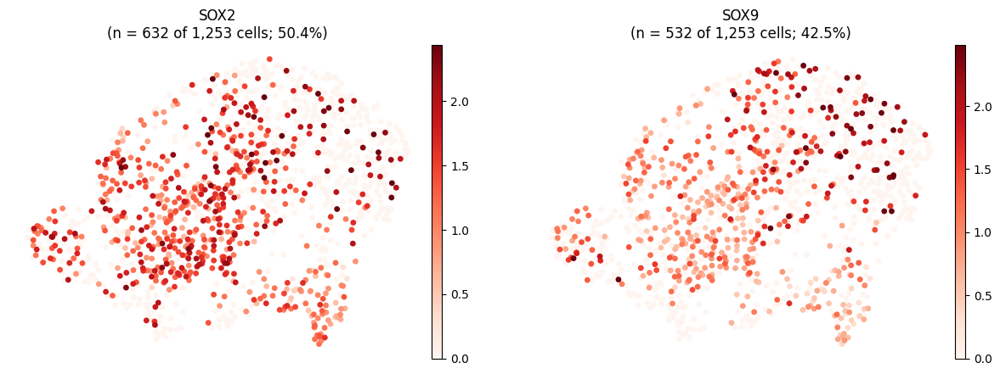

In [ ]:
import numpy as np
import scanpy as sc

# 1. Total stem cells
total_stem = adata_stem.n_obs


# 2. Function to compute positive cell count & percentage
def get_pos_stats(adata, gene):
    expr = (
        adata[:, gene].X.toarray().flatten()
        if hasattr(adata[:, gene].X, "toarray")
        else adata[:, gene].X.flatten()
    )
    n_pos = np.sum(expr > 0)
    pct_pos = (n_pos / total_stem) * 100
    return n_pos, pct_pos


# Calculate stats
sox2_n, sox2_pct = get_pos_stats(adata_stem, "SOX2")
sox9_n, sox9_pct = get_pos_stats(adata_stem, "SOX9")

# Print summary to console/caption
print(f"SOX2+: {sox2_n}/{total_stem} cells ({sox2_pct:.1f}% of stem cells)")
print(f"SOX9+: {sox9_n}/{total_stem} cells ({sox9_pct:.1f}% of stem cells)")

# 3. Plot UMAP with quantified titles on each panel
sc.pl.umap(
    adata_stem,
    color=["SOX2", "SOX9"],
    title=[
        f"SOX2\n(n = {sox2_n} of {total_stem:,} cells; {sox2_pct:.1f}%)",
        f"SOX9\n(n = {sox9_n} of {total_stem:,} cells; {sox9_pct:.1f}%)",
    ],
    color_map="Reds",
    frameon=False,
    ncols=2,
    vmax="p99",
)

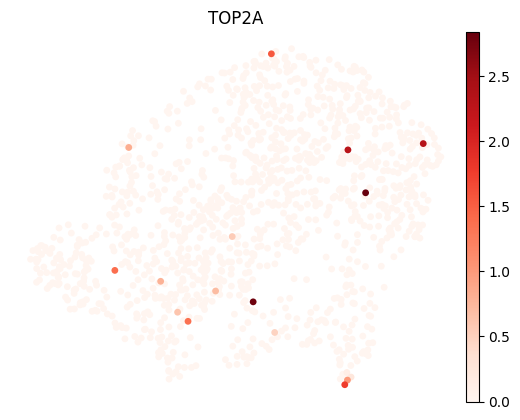

In [ ]:
import scanpy as sc

# Plot MKI67 expression on UMAP
sc.pl.umap(
    adata_stem,
    color="TOP2A",
    color_map="Reds",  # Continuous red scale
    frameon=False,  # Removes border frame
)

In [ ]:
"CDKN1A" in adata_stem.var_names

True

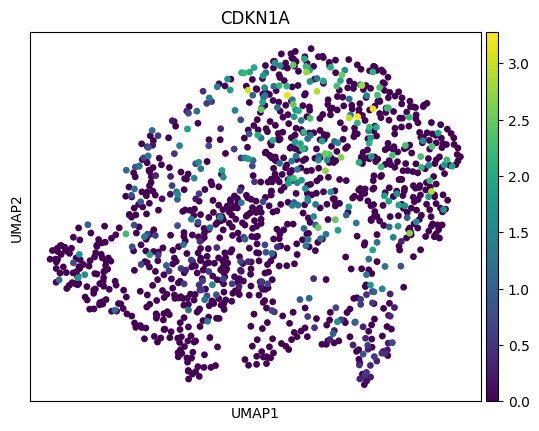

In [ ]:
sc.pl.umap(
    adata_stem,
    color="CDKN1A"
)

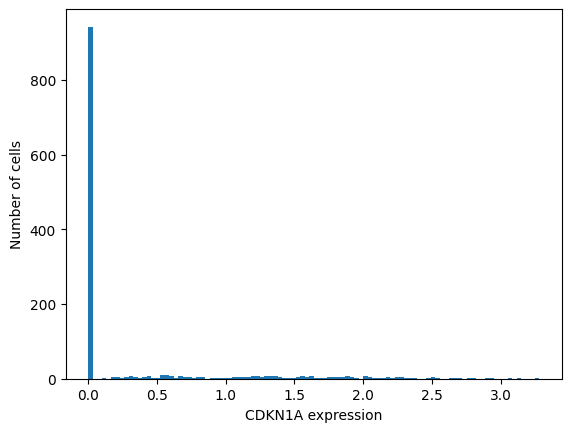

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

cdkn1a = adata_stem[:, "CDKN1A"].X

if hasattr(cdkn1a, "toarray"):
    cdkn1a = cdkn1a.toarray().flatten()
else:
    cdkn1a = np.asarray(cdkn1a).flatten()

plt.hist(cdkn1a, bins=100)
plt.xlabel("CDKN1A expression")
plt.ylabel("Number of cells")
plt.show()

In [ ]:
threshold = np.percentile(cdkn1a, 90)

adata_stem.obs["CDKN1A_group"] = np.where(
    cdkn1a >= threshold,
    "CDKN1A_high",
    "CDKN1A_low"
)

adata_stem.obs["CDKN1A_group"].value_counts()

CDKN1A_group
CDKN1A_low     1127
CDKN1A_high     126
Name: count, dtype: int64

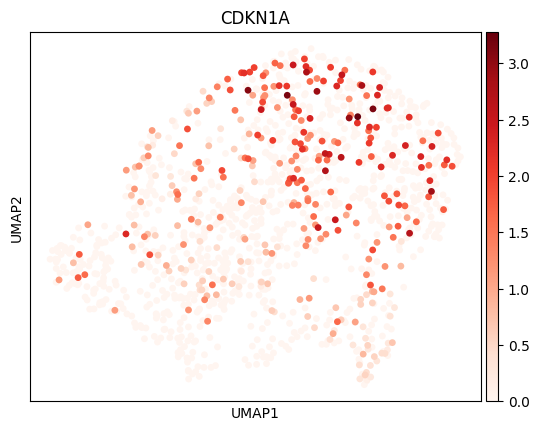

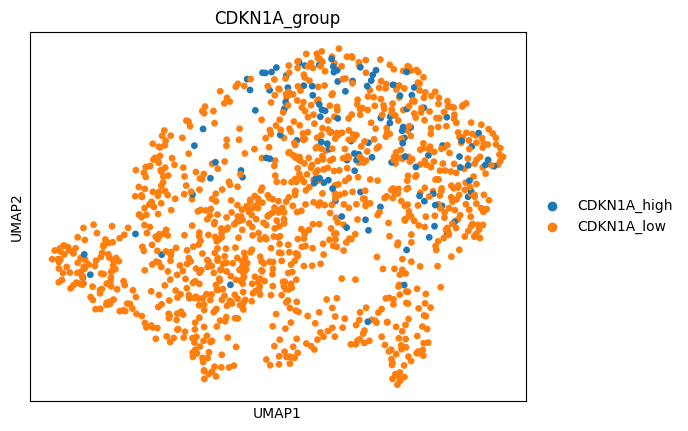

In [ ]:
sc.pl.umap(
    adata_stem,
    color="CDKN1A",
    cmap="Reds"
)

sc.pl.umap(
    adata_stem,
    color="CDKN1A_group"
)

In [ ]:
sc.tl.rank_genes_groups(
    adata_stem,
    groupby="CDKN1A_group",
    groups=["CDKN1A_high"],
    reference="CDKN1A_low",
    method="wilcoxon"
)

In [ ]:
degs = sc.get.rank_genes_groups_df(
    adata_stem,
    group="CDKN1A_high"
)

degs.head(30)

,names,scores,logfoldchanges,pvals,pvals_adj
0,CDKN1A,24.529154,7.381190,7.219571e-133,2.820975e-128
1,EGR1,9.072789,1.294615,1.160087e-19,2.266461e-15
2,ZFP36,8.656626,1.416977,4.859346e-18,6.329137e-14
3,JUNB,8.562606,1.388906,1.103443e-17,1.077898e-13
4,FOS,8.534225,1.313841,1.410982e-17,1.102654e-13
5,GADD45B,8.335750,1.788839,7.700851e-17,5.015051e-13
6,KLF6,8.264065,1.300608,1.407940e-16,7.859119e-13
7,EEF1A1,8.011070,0.622634,1.137143e-15,5.554092e-12
8,CLDN4,7.819130,1.294540,5.318962e-15,2.309257e-11
9,ACTB,7.521271,0.830522,5.424608e-14,2.119611e-10


In [ ]:
degs_sig = degs[
    (degs["pvals_adj"] < 0.05) &
    (abs(degs["logfoldchanges"]) > 0.5)
].copy()

degs_sig

,names,scores,logfoldchanges,pvals,pvals_adj
0,CDKN1A,24.529154,7.381190,7.219571e-133,2.820975e-128
1,EGR1,9.072789,1.294615,1.160087e-19,2.266461e-15
2,ZFP36,8.656626,1.416977,4.859346e-18,6.329137e-14
3,JUNB,8.562606,1.388906,1.103443e-17,1.077898e-13
4,FOS,8.534225,1.313841,1.410982e-17,1.102654e-13
...,...,...,...,...,...
39069,EYA1,-5.282650,-0.730499,1.273283e-07,8.884329e-05
39070,DLEU2,-5.304107,-1.349410,1.132258e-07,8.043974e-05
39071,ENSG00000289474.2,-5.333951,-1.719162,9.609821e-08,7.084795e-05
39072,LAMA2,-5.507166,-1.338065,3.646565e-08,2.968456e-05


In [ ]:
np.percentile(cdkn1a, [50, 60, 70, 75, 80, 90])

array([0.        , 0.        , 0.        , 0.        , 0.54922491,
       1.49427297])

In [ ]:
print(degs_sig.to_string())

                   names     scores  logfoldchanges          pvals      pvals_adj
0                 CDKN1A  24.529154        7.381190  7.219571e-133  2.820975e-128
1                   EGR1   9.072789        1.294615   1.160087e-19   2.266461e-15
2                  ZFP36   8.656626        1.416977   4.859346e-18   6.329137e-14
3                   JUNB   8.562606        1.388906   1.103443e-17   1.077898e-13
4                    FOS   8.534225        1.313841   1.410982e-17   1.102654e-13
5                GADD45B   8.335750        1.788839   7.700851e-17   5.015051e-13
6                   KLF6   8.264065        1.300608   1.407940e-16   7.859119e-13
7                 EEF1A1   8.011070        0.622634   1.137143e-15   5.554092e-12
8                  CLDN4   7.819130        1.294540   5.318962e-15   2.309257e-11
9                   ACTB   7.521271        0.830522   5.424608e-14   2.119611e-10
10                  RPS6   7.372927        0.629620   1.669215e-13   5.459160e-10
11              

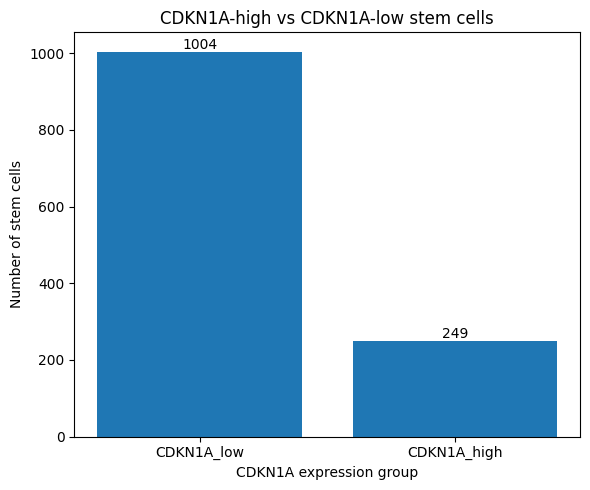

In [ ]:
import matplotlib.pyplot as plt

# Count cells in each group
counts = adata_stem.obs["CDKN1A_group"].value_counts()

# Make sure ordering is consistent
groups = ["CDKN1A_low", "CDKN1A_high"]
values = [counts.get(g, 0) for g in groups]

# Plot
fig, ax = plt.subplots(figsize=(6, 5))

bars = ax.bar(groups, values)

# Add counts above bars
for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        str(value),
        ha="center",
        va="bottom"
    )

ax.set_ylabel("Number of stem cells")
ax.set_xlabel("CDKN1A expression group")
ax.set_title("CDKN1A-high vs CDKN1A-low stem cells")

plt.tight_layout()
plt.show()

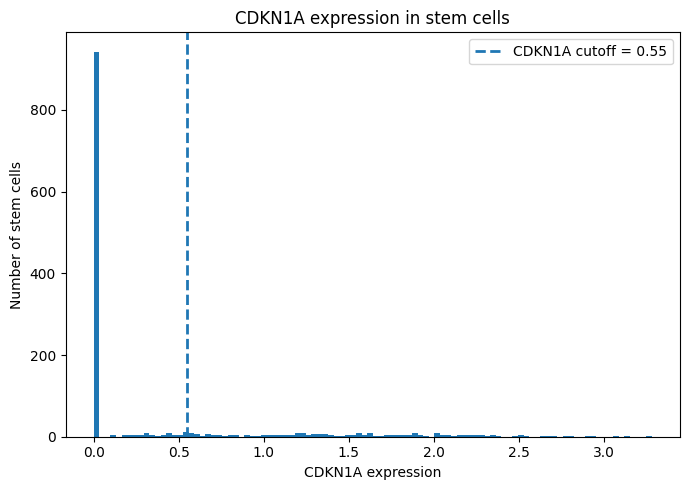

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(
    cdkn1a,
    bins=100
)

ax.axvline(
    0.55,
    linestyle="--",
    linewidth=2,
    label="CDKN1A cutoff = 0.55"
)

ax.set_xlabel("CDKN1A expression")
ax.set_ylabel("Number of stem cells")
ax.set_title("CDKN1A expression in stem cells")

ax.legend()

plt.tight_layout()
plt.show()

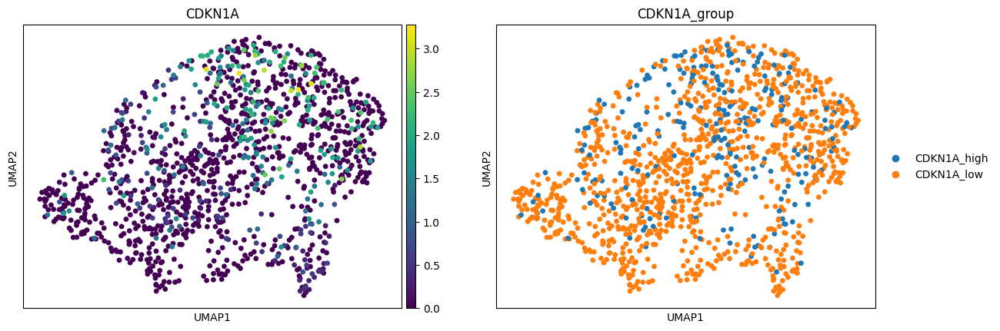

In [ ]:
sc.pl.umap(
    adata_stem,
    color=["CDKN1A", "CDKN1A_group"]
)

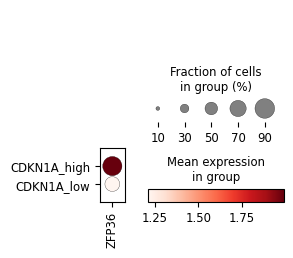

In [ ]:
sc.pl.dotplot(
    adata_stem,
    var_names=["ZFP36"],
    groupby="CDKN1A_group",
    use_raw=False
)


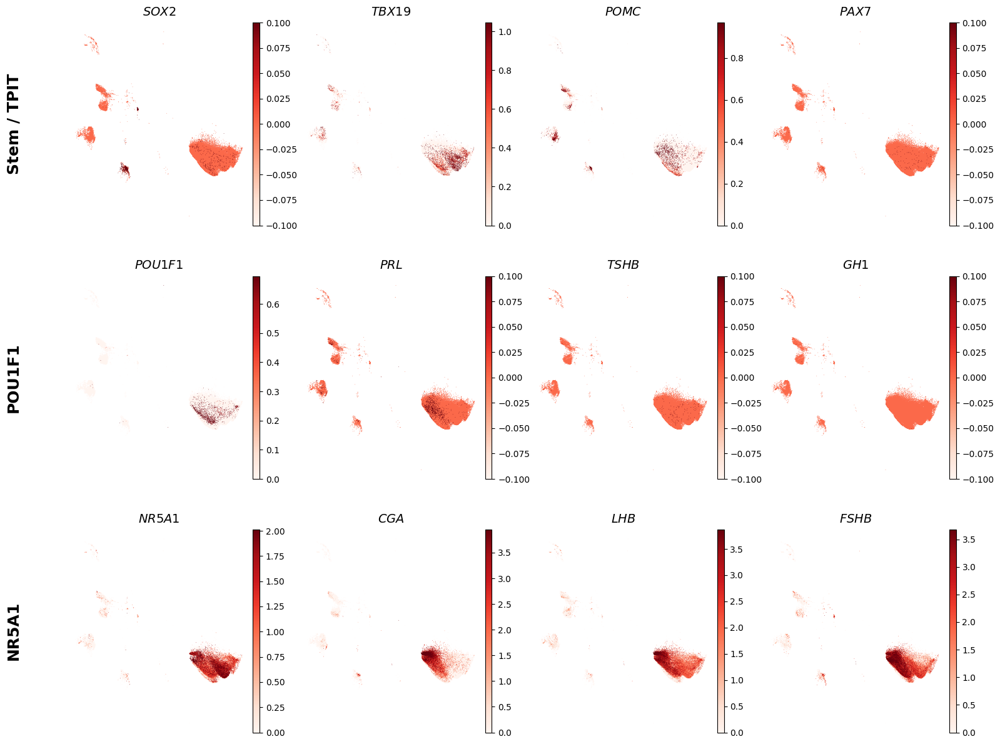

In [6]:
import matplotlib.pyplot as plt
import scanpy as sc

# Define genes structured by lineage rows
marker_rows = {
    "Stem / TPIT": ["SOX2", "TBX19", "POMC", "PAX7"],
    "POU1F1": ["POU1F1", "PRL", "TSHB", "GH1"],
    "NR5A1": ["NR5A1", "CGA", "LHB", "FSHB"],
}

# Flatten list of all genes for sequential plotting
all_genes = [gene for row in marker_rows.values() for gene in row]

# Create figure grid
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes_flat = axes.flatten()

# Plot each gene UMAP onto its assigned subplot
for i, gene in enumerate(all_genes):
    ax = axes_flat[i]

    # Plot expression feature map
    sc.pl.umap(
        adata,
        color=gene,
        color_map="Reds",
        frameon=False,  # Hides outer borders and tick marks
        vmax="p99",  # Enhances expression contrast
        ax=ax,
        show=False,
        title="",  # Custom title applied below
    )

    # Clean italicized gene title
    ax.set_title(f"${gene}$", fontsize=14, fontweight="bold", pad=8)

# Add large row labels on the left margin
row_labels = list(marker_rows.keys())
for row_idx, label in enumerate(row_labels):
    # Target the left-most subplot of each row
    first_ax_in_row = axes[row_idx, 0]
    first_ax_in_row.text(
        -0.25,
        0.5,
        label,
        transform=first_ax_in_row.transAxes,
        fontsize=18,
        fontweight="bold",
        va="center",
        ha="right",
        rotation=90,
    )

plt.tight_layout()
plt.subplots_adjust(wspace=0.15, hspace=0.25)
plt.show()

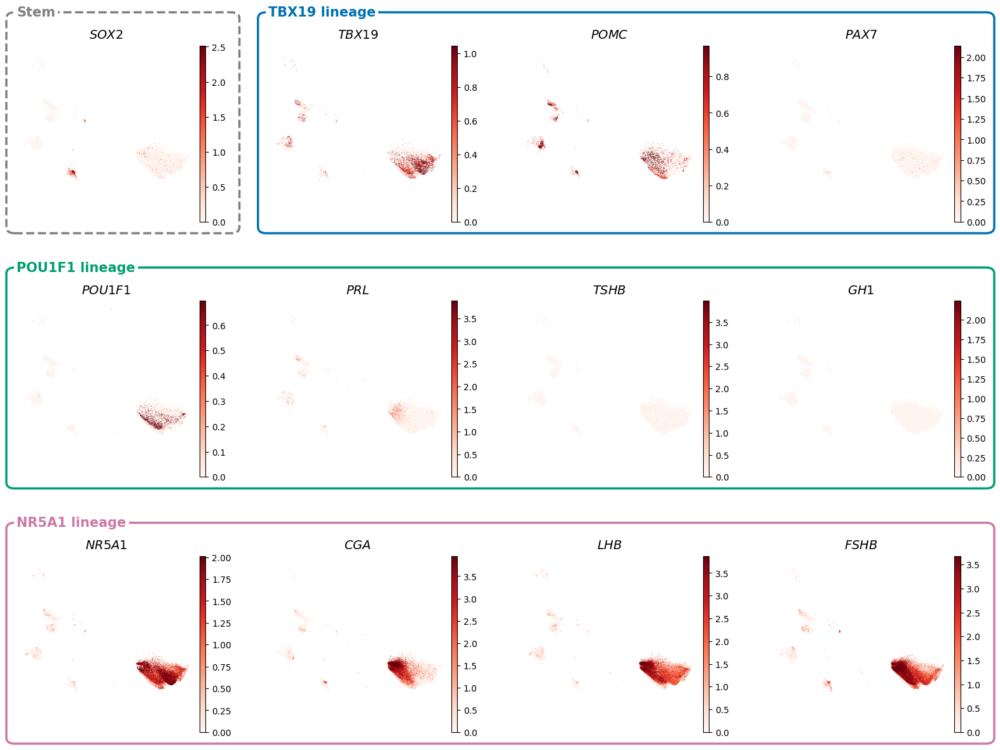

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
from matplotlib.patches import FancyBboxPatch
from matplotlib.transforms import Bbox

# Genes arranged by lineage row; SOX2 sits in row 0 but in its own group
grid = [
    ["SOX2",   "TBX19", "POMC", "PAX7"],
    ["POU1F1", "PRL",   "TSHB", "GH1"],
    ["NR5A1",  "CGA",   "LHB",  "FSHB"],
]

# Boxed groups: label -> (row, first_col, last_col, colour, linestyle)
# Colours from the Okabe–Ito palette (colour-blind safe)
groups = {
    "Stem":           (0, 0, 0, "grey",    "--"),
    "TBX19 lineage":  (0, 1, 3, "#0072B2", "-"),   # blue
    "POU1F1 lineage": (1, 0, 3, "#009E73", "-"),   # bluish green
    "NR5A1 lineage":  (2, 0, 3, "#CC79A7", "-"),   # reddish purple
}

# Use the same data source scanpy uses for colouring (raw if present)
use_raw = adata.raw is not None

def robust_vmax(gene, q=99):
    """99th percentile of expression; for sparse genes, of expressing cells only."""
    x = sc.get.obs_df(adata, keys=[gene], use_raw=use_raw)[gene].values
    v = np.percentile(x, q)
    if v <= 0:
        pos = x[x > 0]
        v = np.percentile(pos, q) if pos.size else 1.0
    return v

n_rows, n_cols = len(grid), len(grid[0])
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 12))

# Track every axis belonging to each panel (UMAP + its colorbar)
panel_axes = {}

for r, row in enumerate(grid):
    for c, gene in enumerate(row):
        ax = axes[r, c]
        n_before = len(fig.axes)

        sc.pl.umap(
            adata,
            color=gene,
            color_map="Reds",
            frameon=False,
            vmin=0,
            vmax=robust_vmax(gene),
            ax=ax,
            show=False,
            title="",
        )
        ax.set_title(f"${gene}$", fontsize=14, fontweight="bold", pad=8)

        panel_axes[(r, c)] = [ax] + fig.axes[n_before:]

plt.tight_layout()
plt.subplots_adjust(wspace=0.25, hspace=0.45, left=0.03, right=0.97, top=0.93, bottom=0.03)

# --- Lineage boxes (drawn after the final layout) ---
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
to_fig = fig.transFigure.inverted()

def bbox_of(cells):
    return Bbox.union([a.get_tightbbox(renderer)
                       for rc in cells for a in panel_axes[rc]]).transformed(to_fig)

# Shared column extents so box edges line up across rows
col_bb = {c: bbox_of([(r, c) for r in range(n_rows)]) for c in range(n_cols)}

pad, top_pad = 0.008, 0.022   # top_pad leaves room for the label above gene titles
for label, (r, c0, c1, colour, ls) in groups.items():
    row_bb = bbox_of([(r, c) for c in range(c0, c1 + 1)])
    x0 = col_bb[c0].x0 - pad
    x1 = col_bb[c1].x1 + pad
    y0 = row_bb.y0 - pad
    y1 = row_bb.y1 + top_pad

    fig.add_artist(FancyBboxPatch(
        (x0, y0), x1 - x0, y1 - y0,
        boxstyle="round,pad=0,rounding_size=0.008",
        transform=fig.transFigure, fill=False,
        edgecolor=colour, linewidth=2.5, linestyle=ls,
        clip_on=False, zorder=0,
    ))
    fig.text(
        x0 + 0.01, y1, label,
        fontsize=15, fontweight="bold", color=colour,
        ha="left", va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=3),
    )

# Save at publication quality
fig.savefig("lineage_umaps.pdf", bbox_inches="tight")
fig.savefig("lineage_umaps.png", dpi=300, bbox_inches="tight")

plt.show()

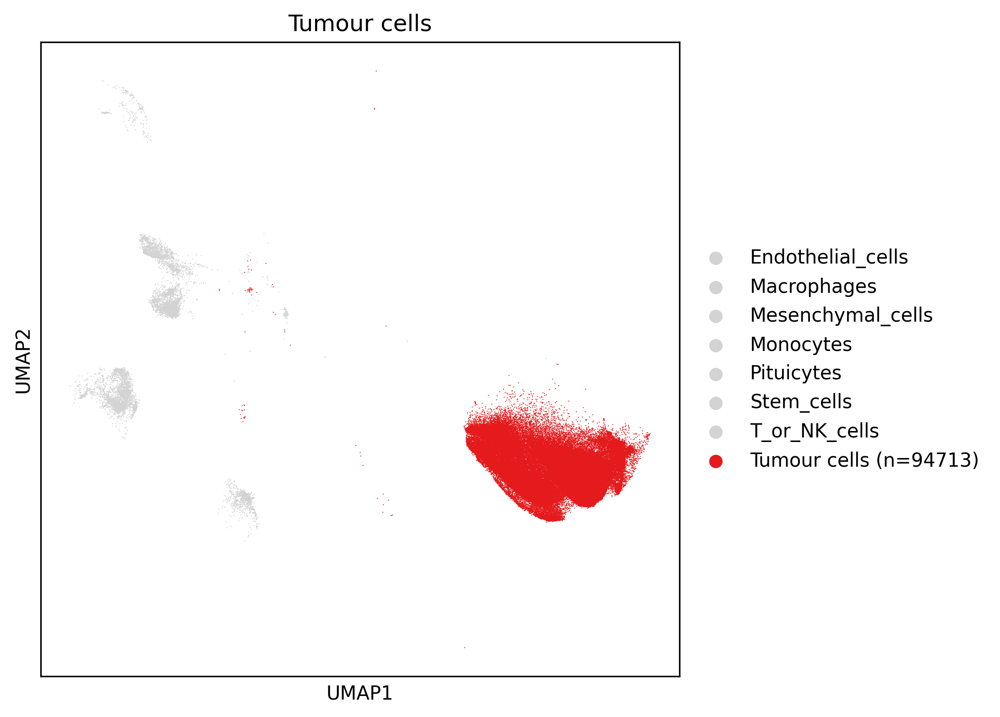

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Get value counts
counts = adata.obs["final_cell_type_broad"].value_counts()
target_category = "Tumour cells"  # Make sure this matches adata.obs["final_cell_type_broad"] exactly

# 2. Build map of old categories to new category names containing (n=...)
rename_map = {
    ct: f"{ct} (n={counts[ct]})" if ct == target_category else ct
    for ct in adata.obs["final_cell_type_broad"].cat.categories
}

# 3. Create a temporary column with updated category names
adata.obs["temp_highlight"] = (
    adata.obs["final_cell_type_broad"]
    .map(rename_map)
    .astype("category")
)

# 4. Define palette matching the new category names exactly
new_target = rename_map[target_category]
highlight_palette = {
    cat: "#E41A1C" if cat == new_target else "#D3D3D3"
    for cat in adata.obs["temp_highlight"].cat.categories
}

# 5. Plot directly with the matching palette
sc.pl.umap(
    adata,
    color="temp_highlight",
    palette=highlight_palette,
    title="Tumour cells",
)

# Clean up temporary column
del adata.obs["temp_highlight"]

/tmp/ipykernel_984/4078576131.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


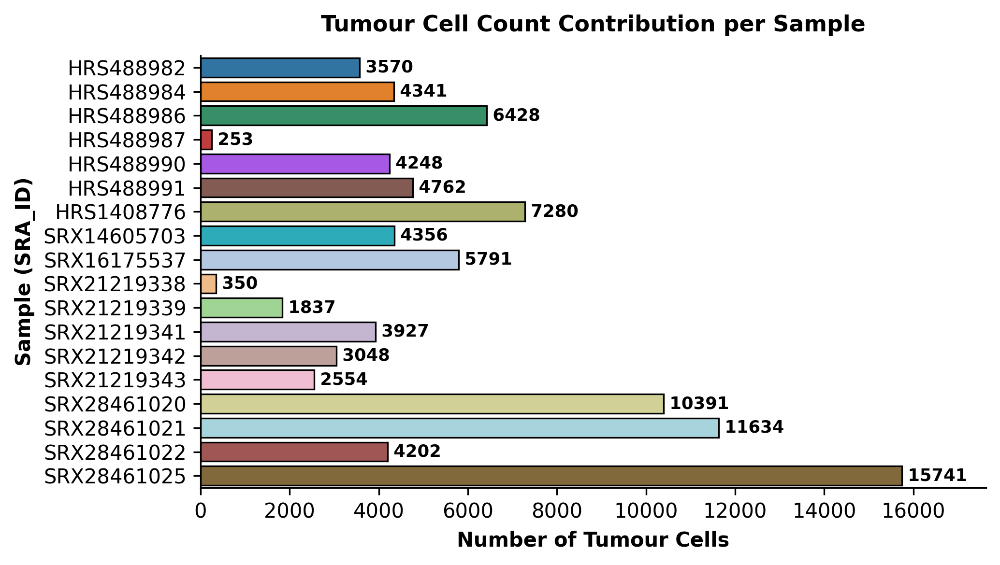

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract tumour counts and sort in ascending order (so highest appears at top)
tumour_counts = (
    adata[adata.obs["final_cell_type_broad"] == "Tumour cells"]
    .obs["SRA_ID"]
    .value_counts()
    .sort_values(ascending=True)
)

# 2. Extract original categories and Scanpy colors for SRA_ID
sra_categories = adata.obs["SRA_ID"].cat.categories
sra_colors = adata.uns["SRA_ID_colors"]
color_dict = dict(zip(sra_categories, sra_colors))

# 3. Create a compact horizontal bar plot
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    y=tumour_counts.index,
    x=tumour_counts.values,
    palette=color_dict,
    edgecolor="black",
    linewidth=0.8,
)

# 4. Add count labels right next to each bar
max_val = tumour_counts.max()
for p in ax.patches:
    width = int(p.get_width())
    if width > 0:
        ax.annotate(
            f" {width}",
            (width, p.get_y() + p.get_height() / 2.0),
            ha="left",
            va="center",
            fontsize=8.5,
            fontweight="bold",
        )

# Adjust padding and labels for a clean, compact publication format
plt.xlim(0, max_val * 1.12)
plt.xlabel("Number of Tumour Cells", fontweight="bold", fontsize=10)
plt.ylabel("Sample (SRA_ID)", fontweight="bold", fontsize=10)
plt.title("Tumour Cell Count Contribution per Sample", fontweight="bold", fontsize=11, pad=12)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

In [ ]:
#  top tumour cell markers
import numpy as np
import pandas as pd

# Calculate mean expression per gene (handles both dense and sparse matrices)
if hasattr(adata_tumour.X, "toarray"):
    mean_expr = np.array(adata_tumour.X.mean(axis=0)).flatten()
else:
    mean_expr = adata_tumour.X.mean(axis=0)

# Create a sorted DataFrame
top_genes_df = pd.DataFrame(
    {"gene": adata_tumour.var_names, "mean_expression": mean_expr}
).sort_values("mean_expression", ascending=False)

# Top 20 most highly expressed genes overall
print(top_genes_df.head(50))

                    gene  mean_expression
27039             MALAT1         5.559110
29049               NRG1         3.165017
30289              PDE4D         2.929611
32490              RIMS2         2.731031
28373              NALF1         2.715358
28042             MT-CO1         2.670221
38171             ZBTB20         2.511759
487                AGBL4         2.476559
29074              NRXN1         2.447148
32675              ROBO1         2.413119
35362             TALAM1         2.411325
7126   ENSG00000230876.8         2.390062
21220               GNAS         2.343641
26821              LSAMP         2.342988
2478               CALM1         2.340268
2451               CADM2         2.313927
20707                FTX         2.235073
30382              PEG10         2.224748
28802              NLGN1         2.201770
28044             MT-CO3         2.166740
34375             SNHG14         2.130430
37492              UNC5D         2.129935
29966               PAK3         2

<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_984/2029607768.py:28: SyntaxWarning: invalid escape sequence '\m'
  title=f"$\mathit{{{gene}}}$\n(n = {malat1_n:,} of {total_tumour:,} cells; {malat1_pct:.1f}%)",


MALAT1+: 87860/94713 cells (92.8% of tumour cells)


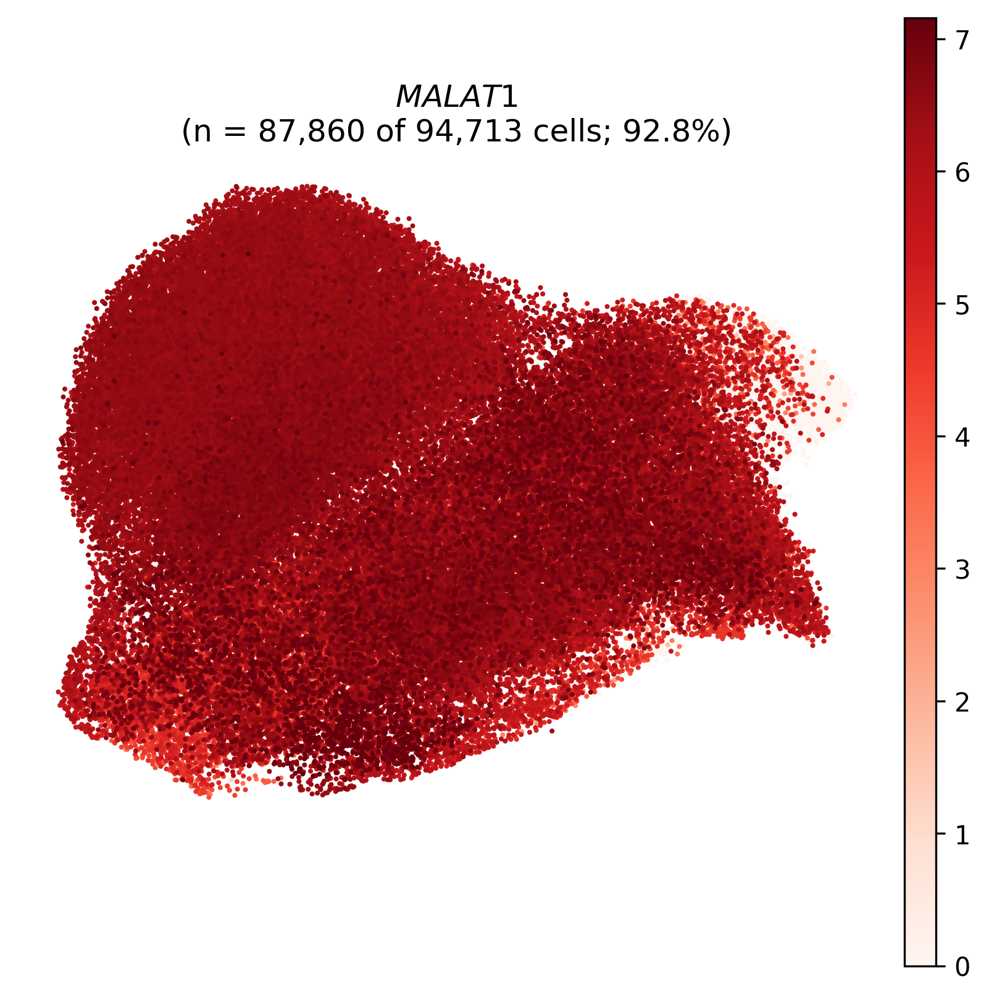

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

# 1. Total tumour cells
total_tumour = adata_tumour.n_obs

# 2. Compute positive cell count & percentage for MALAT1
gene = "MALAT1"
expr = (
    adata_tumour[:, gene].X.toarray().flatten()
    if hasattr(adata_tumour[:, gene].X, "toarray")
    else adata_tumour[:, gene].X.flatten()
)
malat1_n = np.sum(expr > 0)
malat1_pct = (malat1_n / total_tumour) * 100

# Print summary to console
print(f"MALAT1+: {malat1_n}/{total_tumour} cells ({malat1_pct:.1f}% of tumour cells)")

# 3. Set up square aspect ratio figure
fig, ax = plt.subplots(figsize=(5.5, 5.5))

# 4. Plot UMAP with italicized gene name in title
sc.pl.umap(
    adata_tumour,
    color=[gene],
    title=f"$\mathit{{{gene}}}$\n(n = {malat1_n:,} of {total_tumour:,} cells; {malat1_pct:.1f}%)",
    color_map="Reds",
    frameon=False,
    vmax="p99",
    use_raw=False,
    size=15,
    ax=ax,
    show=False,
)

# Force 1:1 square aspect ratio
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

# 1. Define list of target genes from your table
genes = [
    "MALAT1",
    "NRG1",
    "PDE4D",
    "RIMS2",
    "NALF1",
    "MT-CO1",
    "ZBTB20",
    "AGBL4",
    "NRXN1",
    "ROBO1",
    "TALAM1",
    "ENSG00000230876.8",
    "GNAS",
    "LSAMP",
    "CALM1",
    "CADM2",
    "FTX",
    "PEG10",
    "NLGN1",
    "MT-CO3",
]

total_cells = adata_tumour.n_obs

# 2. Pre-calculate positive cell count & percentage for each gene
gene_titles = []
for g in genes:
    if g in adata_tumour.var_names:
        expr = (
            adata_tumour[:, g].X.toarray().flatten()
            if hasattr(adata_tumour[:, g].X, "toarray")
            else adata_tumour[:, g].X.flatten()
        )
        n_pos = np.sum(expr > 0)
        pct_pos = (n_pos / total_cells) * 100

        # Italicize gene symbol and include n and % metrics
        gene_titles.append(
            f"$\\mathit{{{g}}}$\n(n = {n_pos:,} of {total_cells:,}; {pct_pos:.1f}%)"
        )
    else:
        gene_titles.append(f"$\\mathit{{{g}}}$\n(Not found)")

# Filter to genes present in the dataset
valid_genes = [g for g in genes if g in adata_tumour.var_names]
valid_titles = [
    t for g, t in zip(genes, gene_titles) if g in adata_tumour.var_names
]

# 3. Create grid layout (5 columns x 4 rows for 20 panels)
ncols = 5
nrows = int(np.ceil(len(valid_genes) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows), squeeze=False
)
axes = axes.flatten()

# 4. Iterate and plot each UMAP panel
for i, (gene, title) in enumerate(zip(valid_genes, valid_titles)):
    ax = axes[i]
    sc.pl.umap(
        adata_tumour,
        color=[gene],
        title=title,
        color_map="Reds",
        frameon=False,
        vmax="p99",
        use_raw=False,
        size=15,
        ax=ax,
        show=False,
    )
    # Ensure 1:1 aspect ratio so UMAPs are not squished
    ax.set_aspect("equal", adjustable="box")

# Hide any remaining empty subplots
for j in range(len(valid_genes), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

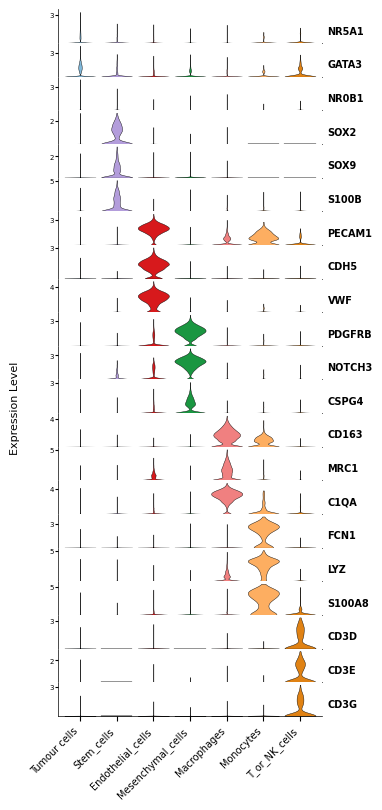

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

# ---- 1. Point these at your data --------------------------------------------
# Using the active 'adata' already loaded in memory instead of reading from disk
label_col = "final_cell_type_broad"
use_raw = adata.raw is not None                   # plot log-normalised expression, not scaled/integrated

# x-axis order = order of marker blocks -> gives the diagonal pattern
order = [
    "Tumour cells",
    "Stem_cells",
    "Endothelial_cells",
    "Mesenchymal_cells",
    "Macrophages",
    "Monocytes",
    "T_or_NK_cells",
]

markers = {
    "Tumour": ["NR5A1","GATA3","NR0B1","CHGA","CHGB","SCG2","SCG3","PCSK1N","SYP","INSM1"],
    "Stem_cells":               ["SOX2","SOX9","S100B","LHX3","PAX6","CD24","ALDH1A2","LGR4","KRT8","KRT18"],
    "Endothelial_cells":        ["PECAM1","CDH5","VWF","KDR","FLT1","TEK","CLDN5","ERG","PLVAP","EMCN"],
    "Mesenchymal_cells":        ["PDGFRB","NOTCH3","CSPG4","KCNJ8","ACTA2","TAGLN","MYH11","COL1A1","COL1A2","DCN"],
    "Macrophages":              ["CD163","MRC1","C1QA","C1QB","C1QC","CSF1R","MS4A7","MSR1","TREM2","F13A1"],
    "Monocytes":                ["FCN1","LYZ","S100A8","S100A9","S100A12","VCAN","CD300E","CSF3R","MNDA","FPR1"],
    "T_or_NK_cells":            ["CD3D","CD3E","CD3G","CD2","CD8A","IL7R","NKG7","GNLY","PRF1","KLRF1"],
}

colors = {
    "Tumour cells": "#7FB8DA",
    "Stem_cells":               "#B39DDB",
    "Endothelial_cells":        "#D7191C",
    "Mesenchymal_cells":        "#1A9641",
    "Macrophages":              "#F08080",
    "Monocytes":                "#FDAE61",
    "T_or_NK_cells":            "#E08214",
}

n_per_type = 3   # panel B uses ~3 genes per type; set to 10 for the full list

# ---- 2. Pull expression --------------------------------------------------------
genes = [g for ct in order for g in markers[ct if ct != "Tumour cells" else "Tumour"][:n_per_type]]
var_names = adata.raw.var_names if use_raw else adata.var_names
missing = [g for g in genes if g not in var_names]
if missing:
    print("Not found, dropped:", missing)
genes = [g for g in genes if g in var_names]

expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
labels = adata.obs[label_col].astype(str)

# ---- 3. Plot -------------------------------------------------------------------
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(genes), 1, figsize=(4, 0.32 * len(genes) + 1.4), sharex=True)
axes = np.atleast_1d(axes)

for ax, g in zip(axes, genes):
    vals = expr[g].to_numpy(dtype=float)
    for i, ct in enumerate(order):
        v = vals[(labels == ct).to_numpy()]
        if len(v) < 2:
            continue
        v = v + rng.normal(0, 1e-4, len(v))  # tiny jitter so all-zero groups still draw (as Seurat does)
        vp = ax.violinplot(v, positions=[i], widths=0.85, showextrema=False)
        body = vp["bodies"][0]
        body.set_facecolor(colors[ct])
        body.set_edgecolor("black")
        body.set_linewidth(0.3)
        body.set_alpha(1)

    ymax = max(vals.max(), 1)
    ax.set_ylim(0, ymax * 1.08)
    ax.set_yticks([int(np.floor(ymax))])           # one tick per row, avoids label clashes
    ax.tick_params(axis="y", labelsize=5, length=2, pad=1)
    ax.set_ylabel(g, rotation=0, ha="left", va="center", fontsize=7, fontweight="bold")
    ax.yaxis.set_label_position("right")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_linewidth(0.5)
    ax.spines["bottom"].set_linewidth(0.5)

axes[-1].set_xticks(range(len(order)))
axes[-1].set_xticklabels(order, rotation=45, ha="right", fontsize=7)
axes[-1].set_xlim(-0.6, len(order) - 0.4)
fig.supylabel("Expression Level", fontsize=8)
plt.subplots_adjust(hspace=0, left=0.14, right=0.80, bottom=0.12, top=0.99)

fig.savefig("stacked_violin_markers.pdf", bbox_inches="tight")
fig.savefig("stacked_violin_markers.png", dpi=300, bbox_inches="tight")
plt.show()

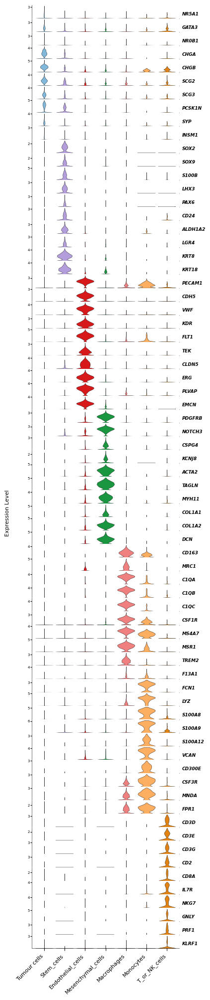

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

# ---- 1. Configuration --------------------------------------------------------
label_col = "final_cell_type_broad"
use_raw = adata.raw is not None  # plot log-normalised expression

order = [
    "Tumour cells",
    "Stem_cells",
    "Endothelial_cells",
    "Mesenchymal_cells",
    "Macrophages",
    "Monocytes",
    "T_or_NK_cells",
]

markers = {
    "Tumour": ["NR5A1", "GATA3", "NR0B1", "CHGA", "CHGB", "SCG2", "SCG3", "PCSK1N", "SYP", "INSM1"],
    "Stem_cells": ["SOX2", "SOX9", "S100B", "LHX3", "PAX6", "CD24", "ALDH1A2", "LGR4", "KRT8", "KRT18"],
    "Endothelial_cells": ["PECAM1", "CDH5", "VWF", "KDR", "FLT1", "TEK", "CLDN5", "ERG", "PLVAP", "EMCN"],
    "Mesenchymal_cells": ["PDGFRB", "NOTCH3", "CSPG4", "KCNJ8", "ACTA2", "TAGLN", "MYH11", "COL1A1", "COL1A2", "DCN"],
    "Macrophages": ["CD163", "MRC1", "C1QA", "C1QB", "C1QC", "CSF1R", "MS4A7", "MSR1", "TREM2", "F13A1"],
    "Monocytes": ["FCN1", "LYZ", "S100A8", "S100A9", "S100A12", "VCAN", "CD300E", "CSF3R", "MNDA", "FPR1"],
    "T_or_NK_cells": ["CD3D", "CD3E", "CD3G", "CD2", "CD8A", "IL7R", "NKG7", "GNLY", "PRF1", "KLRF1"],
}

colors = {
    "Tumour cells": "#7FB8DA",
    "Stem_cells": "#B39DDB",
    "Endothelial_cells": "#D7191C",
    "Mesenchymal_cells": "#1A9641",
    "Macrophages": "#F08080",
    "Monocytes": "#FDAE61",
    "T_or_NK_cells": "#E08214",
}

# ---- 2. Pull expression for ALL genes ----------------------------------------
genes = [
    g
    for ct in order
    for g in markers[ct if ct != "Tumour cells" else "Tumour"]
]
var_names = adata.raw.var_names if use_raw else adata.var_names
missing = [g for g in genes if g not in var_names]
if missing:
    print("Not found, dropped:", missing)
genes = [g for g in genes if g in var_names]

expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
labels = adata.obs[label_col].astype(str)

# ---- 3. Plot Stacked Violin ---------------------------------------------------
rng = np.random.default_rng(0)

fig, axes = plt.subplots(
    len(genes), 1, figsize=(4.5, 0.28 * len(genes) + 1.2), sharex=True
)
axes = np.atleast_1d(axes)

for ax, g in zip(axes, genes):
    vals = expr[g].to_numpy(dtype=float)
    for i, ct in enumerate(order):
        v = vals[(labels == ct).to_numpy()]
        if len(v) < 2:
            continue
        v = v + rng.normal(0, 1e-4, len(v))  # tiny jitter for all-zero groups
        vp = ax.violinplot(v, positions=[i], widths=0.85, showextrema=False)
        body = vp["bodies"][0]
        body.set_facecolor(colors[ct])
        body.set_edgecolor("black")
        body.set_linewidth(0.3)
        body.set_alpha(1)

    ymax = max(vals.max(), 1)
    ax.set_ylim(0, ymax * 1.08)
    ax.set_yticks([int(np.floor(ymax))])
    ax.tick_params(axis="y", labelsize=5, length=2, pad=1)
    ax.set_ylabel(
        g, rotation=0, ha="left", va="center",
        fontsize=6.5, fontweight="bold", fontstyle="italic",
    )
    ax.yaxis.set_label_position("right")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_linewidth(0.4)
    ax.spines["bottom"].set_linewidth(0.4)

axes[-1].set_xticks(range(len(order)))
axes[-1].set_xticklabels(order, rotation=45, ha="right", fontsize=8)
axes[-1].set_xlim(-0.6, len(order) - 0.4)
fig.supylabel("Expression Level", fontsize=8)
plt.subplots_adjust(hspace=0, left=0.14, right=0.80, bottom=0.08, top=0.99)

# ---- 4. Save and Show --------------------------------------------------------
fig.savefig("stacked_violin_markers_all.pdf", bbox_inches="tight")
fig.savefig("stacked_violin_markers_all.png", dpi=300, bbox_inches="tight")
plt.show()

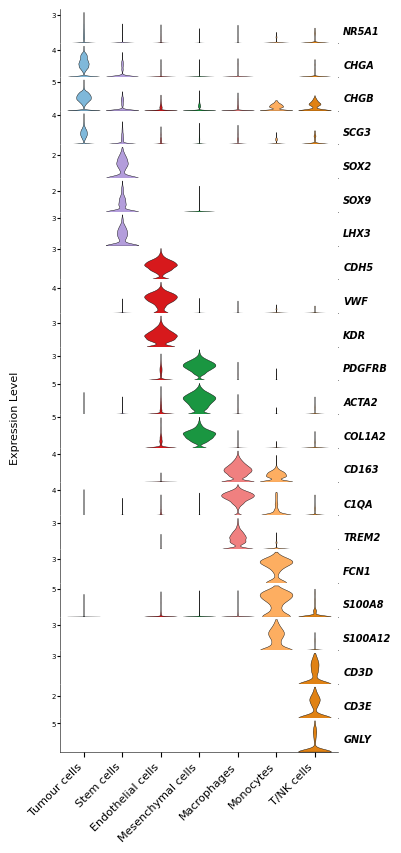

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

# ---- 1. Configuration --------------------------------------------------------
label_col = "final_cell_type_broad"
use_raw = adata.raw is not None  # plot log-normalised expression

compact = True        # True = main figure (3-4 genes/type); False = all 10/type (supplementary)
min_frac = 0.02       # don't draw a violin if < 2% of cells in that group express the gene

order = [
    "Tumour cells",
    "Stem_cells",
    "Endothelial_cells",
    "Mesenchymal_cells",
    "Macrophages",
    "Monocytes",
    "T_or_NK_cells",
]

# Labels shown on the x-axis
display_names = {
    "Tumour cells": "Tumour cells",
    "Stem_cells": "Stem cells",
    "Endothelial_cells": "Endothelial cells",
    "Mesenchymal_cells": "Mesenchymal cells",
    "Macrophages": "Macrophages",
    "Monocytes": "Monocytes",
    "T_or_NK_cells": "T/NK cells",
}

markers_full = {
    "Tumour cells": ["NR5A1", "GATA3", "NR0B1", "CHGA", "CHGB", "SCG2", "SCG3", "PCSK1N", "SYP", "INSM1"],
    "Stem_cells": ["SOX2", "SOX9", "S100B", "LHX3", "PAX6", "CD24", "ALDH1A2", "LGR4", "KRT8", "KRT18"],
    "Endothelial_cells": ["PECAM1", "CDH5", "VWF", "KDR", "FLT1", "TEK", "CLDN5", "ERG", "PLVAP", "EMCN"],
    "Mesenchymal_cells": ["PDGFRB", "NOTCH3", "CSPG4", "KCNJ8", "ACTA2", "TAGLN", "MYH11", "COL1A1", "COL1A2", "DCN"],
    "Macrophages": ["CD163", "MRC1", "C1QA", "C1QB", "C1QC", "CSF1R", "MS4A7", "MSR1", "TREM2", "F13A1"],
    "Monocytes": ["FCN1", "LYZ", "S100A8", "S100A9", "S100A12", "VCAN", "CD300E", "CSF3R", "MNDA", "FPR1"],
    "T_or_NK_cells": ["CD3D", "CD3E", "CD3G", "CD2", "CD8A", "IL7R", "NKG7", "GNLY", "PRF1", "KLRF1"],
}

# Cleanest, most specific genes from the full plot
markers_compact = {
    "Tumour cells": ["NR5A1", "CHGA", "CHGB", "SCG3"],
    "Stem_cells": ["SOX2", "SOX9", "LHX3"],
    "Endothelial_cells": ["CDH5", "VWF", "KDR"],
    "Mesenchymal_cells": ["PDGFRB", "ACTA2", "COL1A2"],
    "Macrophages": ["CD163", "C1QA", "TREM2"],
    "Monocytes": ["FCN1", "S100A8", "S100A12"],
    "T_or_NK_cells": ["CD3D", "CD3E", "GNLY"],
}

markers = markers_compact if compact else markers_full

colors = {
    "Tumour cells": "#7FB8DA",
    "Stem_cells": "#B39DDB",
    "Endothelial_cells": "#D7191C",
    "Mesenchymal_cells": "#1A9641",
    "Macrophages": "#F08080",
    "Monocytes": "#FDAE61",
    "T_or_NK_cells": "#E08214",
}

# ---- 2. Pull expression --------------------------------------------------------
genes = [g for ct in order for g in markers[ct]]
var_names = adata.raw.var_names if use_raw else adata.var_names
missing = [g for g in genes if g not in var_names]
if missing:
    print("Not found, dropped:", missing)
genes = [g for g in genes if g in var_names]

expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
labels = adata.obs[label_col].astype(str).to_numpy()

# ---- 3. Plot stacked violin ----------------------------------------------------
rng = np.random.default_rng(0)
row_h = 0.32 if compact else 0.28

fig, axes = plt.subplots(
    len(genes), 1, figsize=(4.2, row_h * len(genes) + 1.3), sharex=True
)
axes = np.atleast_1d(axes)

for ax, g in zip(axes, genes):
    vals = expr[g].to_numpy(dtype=float)
    for i, ct in enumerate(order):
        v = vals[labels == ct]
        if len(v) < 2 or (v > 0).mean() < min_frac:
            continue  # skip near-empty groups -> no flat lines / stray spikes
        v = v + rng.normal(0, 1e-4, len(v))
        vp = ax.violinplot(v, positions=[i], widths=0.85, showextrema=False)
        body = vp["bodies"][0]
        body.set_facecolor(colors[ct])
        body.set_edgecolor("black")
        body.set_linewidth(0.3)
        body.set_alpha(1)

    ymax = max(vals.max(), 1)
    ax.set_ylim(0, ymax * 1.08)
    ax.set_yticks([int(np.floor(ymax))])
    ax.tick_params(axis="y", labelsize=5, length=2, pad=1)
    ax.set_ylabel(
        g, rotation=0, ha="left", va="center",
        fontsize=7 if compact else 6.5, fontweight="bold", fontstyle="italic",
    )
    ax.yaxis.set_label_position("right")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_linewidth(0.4)
    ax.spines["bottom"].set_linewidth(0.4)

axes[-1].set_xticks(range(len(order)))
axes[-1].set_xticklabels([display_names[c] for c in order], rotation=45, ha="right", fontsize=8)
axes[-1].set_xlim(-0.6, len(order) - 0.4)
fig.supylabel("Expression Level", fontsize=8)
plt.subplots_adjust(hspace=0, left=0.14, right=0.80, bottom=0.10, top=0.99)

# ---- 4. Save and show ----------------------------------------------------------
suffix = "compact" if compact else "all"
fig.savefig(f"stacked_violin_markers_{suffix}.pdf", bbox_inches="tight")
fig.savefig(f"stacked_violin_markers_{suffix}.png", dpi=300, bbox_inches="tight")
plt.show()

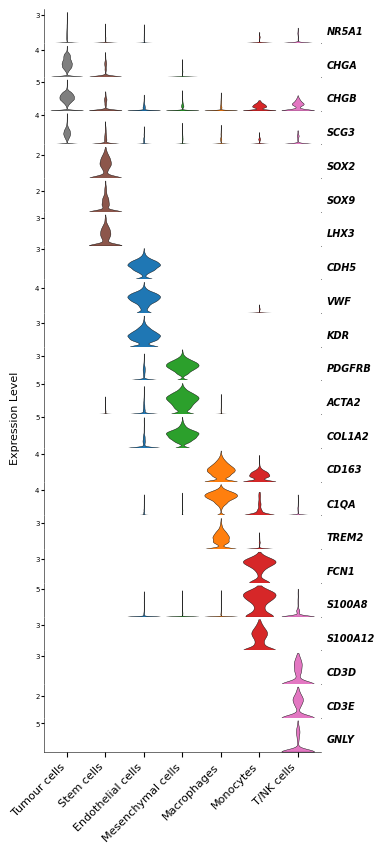

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

# ---- 1. Configuration --------------------------------------------------------
label_col = "final_cell_type_broad"
use_raw = adata.raw is not None  # plot log-normalised expression

compact = True        # True = main figure (3-4 genes/type); False = all 10/type (supplementary)
min_frac = 0.05       # don't draw a violin if < 5% of cells in that group express the gene

order = [
    "Tumour cells",
    "Stem_cells",
    "Endothelial_cells",
    "Mesenchymal_cells",
    "Macrophages",
    "Monocytes",
    "T_or_NK_cells",
]

# Labels shown on the x-axis
display_names = {
    "Tumour cells": "Tumour cells",
    "Stem_cells": "Stem cells",
    "Endothelial_cells": "Endothelial cells",
    "Mesenchymal_cells": "Mesenchymal cells",
    "Macrophages": "Macrophages",
    "Monocytes": "Monocytes",
    "T_or_NK_cells": "T/NK cells",
}

markers_full = {
    "Tumour cells": ["NR5A1", "GATA3", "NR0B1", "CHGA", "CHGB", "SCG2", "SCG3", "PCSK1N", "SYP", "INSM1"],
    "Stem_cells": ["SOX2", "SOX9", "S100B", "LHX3", "PAX6", "CD24", "ALDH1A2", "LGR4", "KRT8", "KRT18"],
    "Endothelial_cells": ["PECAM1", "CDH5", "VWF", "KDR", "FLT1", "TEK", "CLDN5", "ERG", "PLVAP", "EMCN"],
    "Mesenchymal_cells": ["PDGFRB", "NOTCH3", "CSPG4", "KCNJ8", "ACTA2", "TAGLN", "MYH11", "COL1A1", "COL1A2", "DCN"],
    "Macrophages": ["CD163", "MRC1", "C1QA", "C1QB", "C1QC", "CSF1R", "MS4A7", "MSR1", "TREM2", "F13A1"],
    "Monocytes": ["FCN1", "LYZ", "S100A8", "S100A9", "S100A12", "VCAN", "CD300E", "CSF3R", "MNDA", "FPR1"],
    "T_or_NK_cells": ["CD3D", "CD3E", "CD3G", "CD2", "CD8A", "IL7R", "NKG7", "GNLY", "PRF1", "KLRF1"],
}

# Cleanest, most specific genes for the main figure
markers_compact = {
    "Tumour cells": ["NR5A1", "CHGA", "CHGB", "SCG3"],  # swap CHGB -> "SCG2" or "PCSK1N" if off-target signal bothers you
    "Stem_cells": ["SOX2", "SOX9", "LHX3"],
    "Endothelial_cells": ["CDH5", "VWF", "KDR"],
    "Mesenchymal_cells": ["PDGFRB", "ACTA2", "COL1A2"],
    "Macrophages": ["CD163", "C1QA", "TREM2"],
    "Monocytes": ["FCN1", "S100A8", "S100A12"],
    "T_or_NK_cells": ["CD3D", "CD3E", "GNLY"],
}

markers = markers_compact if compact else markers_full

colors = {
    "Tumour cells":      "#7f7f7f",  # grey
    "Stem_cells":        "#8c564b",  # brown
    "Endothelial_cells": "#1f77b4",  # blue
    "Mesenchymal_cells": "#2ca02c",  # green
    "Macrophages":       "#ff7f0e",  # orange
    "Monocytes":         "#d62728",  # red
    "T_or_NK_cells":     "#e377c2",  # pink
    "Pituicytes":        "#9467bd",  # purple (for if you add pituicyte markers)
}
# ---- 2. Pull expression --------------------------------------------------------
genes = [g for ct in order for g in markers[ct]]
var_names = adata.raw.var_names if use_raw else adata.var_names
missing = [g for g in genes if g not in var_names]
if missing:
    print("Not found, dropped:", missing)
genes = [g for g in genes if g in var_names]

expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
labels = adata.obs[label_col].astype(str).to_numpy()

# ---- 3. Plot stacked violin ----------------------------------------------------
rng = np.random.default_rng(0)
row_h = 0.32 if compact else 0.28

fig, axes = plt.subplots(
    len(genes), 1, figsize=(4.2, row_h * len(genes) + 1.3), sharex=True
)
axes = np.atleast_1d(axes)

for ax, g in zip(axes, genes):
    vals = expr[g].to_numpy(dtype=float)
    for i, ct in enumerate(order):
        v = vals[labels == ct]
        if len(v) < 2 or (v > 0).mean() < min_frac:
            continue  # skip near-empty groups -> no flat lines / stray spikes
        v = v + rng.normal(0, 1e-4, len(v))
        vp = ax.violinplot(v, positions=[i], widths=0.85, showextrema=False)
        body = vp["bodies"][0]
        body.set_facecolor(colors[ct])
        body.set_edgecolor("black")
        body.set_linewidth(0.3)
        body.set_alpha(1)

    ymax = max(vals.max(), 1)
    ax.set_ylim(0, ymax * 1.08)
    ax.set_yticks([int(np.floor(ymax))])
    ax.tick_params(axis="y", labelsize=5, length=2, pad=1)
    ax.set_ylabel(
        g, rotation=0, ha="left", va="center",
        fontsize=7 if compact else 6.5, fontweight="bold", fontstyle="italic",
    )
    ax.yaxis.set_label_position("right")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_linewidth(0.4)
    ax.spines["bottom"].set_linewidth(0.4)

axes[-1].set_xticks(range(len(order)))
axes[-1].set_xticklabels([display_names[c] for c in order], rotation=45, ha="right", fontsize=8)
axes[-1].set_xlim(-0.6, len(order) - 0.4)
fig.supylabel("Expression Level", fontsize=8, x=0.06)
plt.subplots_adjust(hspace=0, left=0.14, right=0.80, bottom=0.10, top=0.99)

# ---- 4. Save and show ----------------------------------------------------------
suffix = "compact" if compact else "all"
fig.savefig(f"stacked_violin_markers_{suffix}.pdf", bbox_inches="tight")
fig.savefig(f"stacked_violin_markers_{suffix}.png", dpi=300, bbox_inches="tight")
plt.show()

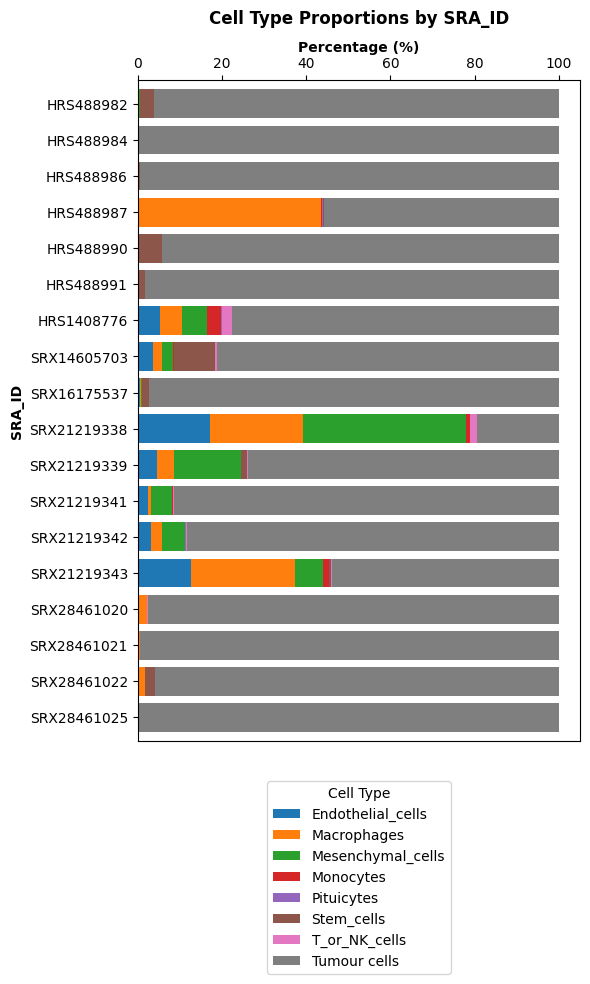

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extract categories and their Scanpy colors
cell_types = adata.obs["final_cell_type_broad"].cat.categories
colors = adata.uns["final_cell_type_broad_colors"]

# Create a palette dictionary mapping cell types to Scanpy hex colors
color_dict = dict(zip(cell_types, colors))

# 2. Compute proportions
props = (
    pd.crosstab(
        adata.obs["SRA_ID"],
        adata.obs["final_cell_type_broad"],
        normalize="index",
    )
    * 100
)

# Reverse sample order so top sample appears at top of Y-axis
props_reversed = props.iloc[::-1]

# 3. Plot horizontal stacked bar chart
ax = props_reversed.plot(
    kind="barh", stacked=True, color=color_dict, figsize=(6, 10), width=0.8
)

# 4. Labels and legend formatting
plt.xlabel("Percentage (%)", fontweight="bold")
plt.ylabel("SRA_ID", fontweight="bold")
plt.title("Cell Type Proportions by SRA_ID", fontweight="bold", pad=12)

# Move X-axis ticks to top if desired (matching image orientation)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

plt.legend(
    title="Cell Type",
    bbox_to_anchor=(0.5, -0.05),
    loc="upper center",
    ncol=1,
    frameon=True,
)

plt.tight_layout()
plt.show()

KeyError: 'unknown'

In [ ]:
#X as type float
adata.X=adata.X.astype(float)
#filter out genes that are not expressed in at least 50 cells
sc.pp.filter_genes(adata, min_cells=100)
adata

AnnData object with n_obs × n_vars = 104321 × 27068
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'assay', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'Internal_ID', 'Name', 'Normal', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'n_cells', 'pct_counts_in_top_20_genes', 'SRA_barcode', 'cell_type', 'leiden_scVI', 'leiden_scVI_final', 'final_cell_type_broad', 'final_cell_type_specific'
    var: 'mt', 'ribo', 'malat', 'n_cells_by_counts', 'mean

In [ ]:
# Install liana first as it is not pre-installed in Colab
!pip install liana

# import liana's rank_aggregate. this provides a consensus that integrates the predictions of individual methods
from liana.mt import rank_aggregate

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 601.6/601.6 kB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 89.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 4.8 MB/s eta 0:00:00
  Created wheel for docrep: filename=docrep-0.3.2-py3-none-any.whl size=19973 sha256=6f0054f1a6741aaba8c6c0421ed4cc77bc1d5dab3cb43e9483c04da47c7a8cda
  Stored in directory: /root/.cache/pip/wheels/45/f2/42/d9ffbaceb3f12c063124529560e5a8b5ec85930e6f8ba5a017
Successfully built docrep
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.6
    Uninstalling pandas-3.0.6:
      Successfully uninstalled pandas-3.0.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pan

In [ ]:
from liana.method import singlecellsignalr, connectome, cellphonedb, natmi, logfc, cellchat, geometric_mean, scseqcomm, rank_aggregate


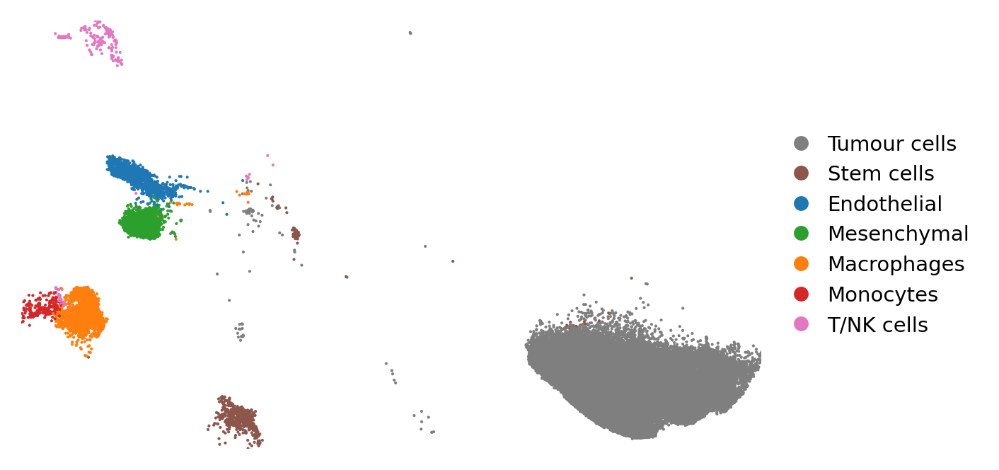

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import scanpy as sc

celltype_col = "final_cell_type_broad"

fig, ax = plt.subplots(figsize=(4.5, 3.2), dpi=300)   # wider to make room for the key
sc.pl.umap(adata, color=celltype_col, ax=ax, size=4, frameon=False,
           legend_loc=None, title="", show=False)

# Key: built by hand so the dots are a readable size and the order is controlled
cats   = list(adata.obs[celltype_col].cat.categories)
colors = adata.uns[f"{celltype_col}_colors"]
order  = ["Tumour cells", "Stem cells", "Pituicytes", "Endothelial", "Mesenchymal",
          "Macrophages", "Monocytes", "T/NK cells"]          # edit to the order you want
order  = [c for c in order if c in cats] + [c for c in cats if c not in order]
handles = [Line2D([], [], marker="o", ls="", markersize=5,
                  markerfacecolor=colors[cats.index(c)], markeredgecolor="none", label=c)
           for c in order]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5),
          frameon=False, fontsize=7, handletextpad=0.3, labelspacing=0.5)

# Crop to the central 99.8% of cells to drop the stray outliers
xy = adata.obsm["X_umap"]
lo, hi = np.percentile(xy, 0.1, axis=0), np.percentile(xy, 99.9, axis=0)
pad = 0.4
ax.set_xlim(lo[0] - pad, hi[0] + pad)
ax.set_ylim(lo[1] - pad, hi[1] + pad)
ax.set_aspect("equal")

plt.savefig("Fig1B_umap_celltypes.pdf", bbox_inches="tight", pad_inches=0.02)
plt.savefig("Fig1B_umap_celltypes.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

Tumour cells: n = 94737 cells
Stem cells: n = 1253 cells
Endothelial: n = 2000 cells
Mesenchymal: n = 2540 cells
Macrophages: n = 3035 cells
Monocytes: n = 424 cells
T/NK cells: n = 332 cells


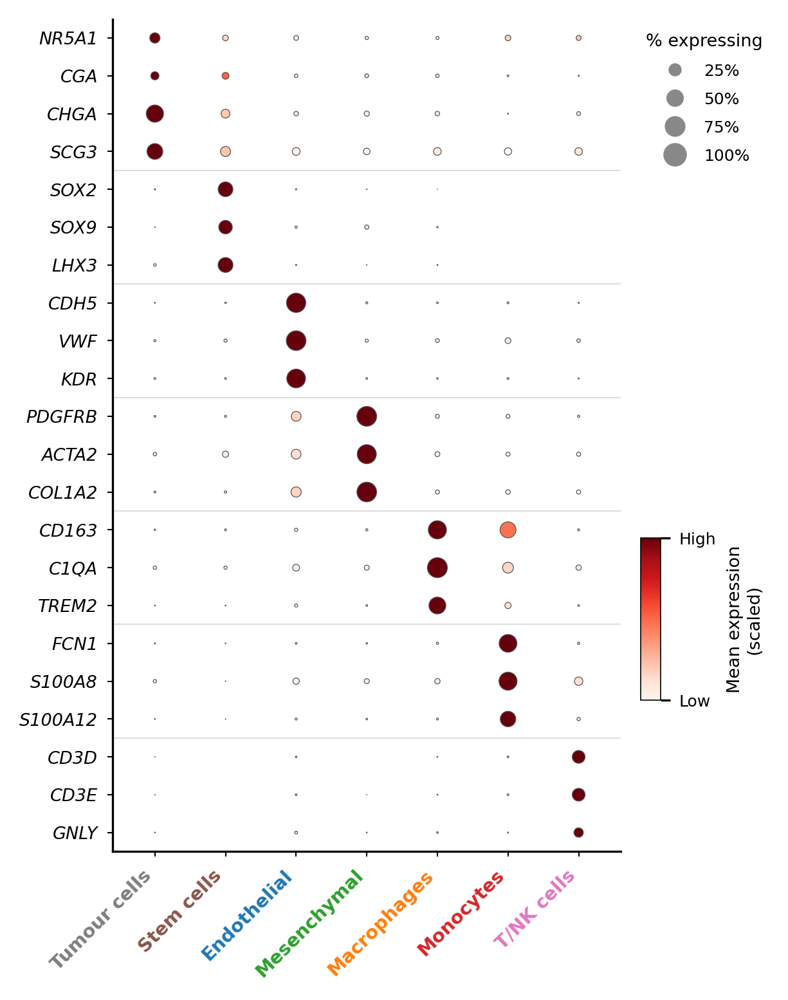

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from matplotlib.lines import Line2D

# ---- 1. Configuration --------------------------------------------------------
label_col = "final_cell_type_broad"
use_raw = adata.raw is not None     # log-normalised expression

# Display order (columns). Old spreadsheet-style names are mapped automatically,
# so this works whether or not the categories were renamed for panel B.
order = ["Tumour cells", "Stem cells", "Endothelial", "Mesenchymal",
         "Macrophages", "Monocytes", "T/NK cells"]
aliases = {"Stem_cells": "Stem cells", "Endothelial_cells": "Endothelial",
           "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells",
           "Pituicytes": "Tumour cells"}   # pituicyte-labelled cells express tumour markers

markers = {
    "Tumour cells": ["NR5A1", "CGA", "CHGA", "SCG3"],   # SF-1 gonadotroph lineage + neuroendocrine
    "Stem cells":   ["SOX2", "SOX9", "LHX3"],
    "Endothelial":  ["CDH5", "VWF", "KDR"],
    "Mesenchymal":  ["PDGFRB", "ACTA2", "COL1A2"],
    "Macrophages":  ["CD163", "C1QA", "TREM2"],
    "Monocytes":    ["FCN1", "S100A8", "S100A12"],
    "T/NK cells":   ["CD3D", "CD3E", "GNLY"],
}

# Same colours as panels B and D (used for the column labels)
colors = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b",
          "Endothelial": "#1f77b4", "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e",
          "Monocytes": "#d62728", "T/NK cells": "#e377c2"}

# ---- 2. Expression summary: % of cells expressing, mean expression ----------
labels = adata.obs[label_col].astype(str).replace(aliases).to_numpy()
order = [c for c in order if c in set(labels)]

var_names = adata.raw.var_names if use_raw else adata.var_names
genes = [g for c in order for g in markers[c]]
missing = [g for g in genes if g not in var_names]
if missing:
    print("Not found, dropped:", missing)
genes = [g for g in genes if g in var_names]

expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
frac = np.zeros((len(genes), len(order)))
mean = np.zeros_like(frac)
for j, ct in enumerate(order):
    sub = expr[labels == ct].to_numpy(dtype=float)
    frac[:, j] = (sub > 0).mean(axis=0)
    mean[:, j] = sub.mean(axis=0)
    print(f"{ct}: n = {(labels == ct).sum()} cells")
# scale mean expression 0-1 within each gene (standard for marker dot plots)
mean_scaled = (mean - mean.min(1, keepdims=True)) / np.ptp(mean, axis=1, keepdims=True).clip(1e-9)

# ---- 3. Plot -----------------------------------------------------------------
max_size = 60
fig, ax = plt.subplots(figsize=(3.4, 0.2 * len(genes) + 1.2), dpi=300)
yy, xx = np.meshgrid(np.arange(len(genes)), np.arange(len(order)), indexing="ij")
sc_ = ax.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * max_size,
                 c=mean_scaled.ravel(), cmap="Reds", vmin=0, vmax=1,
                 edgecolors="#555555", linewidths=0.3)

ax.set_yticks(range(len(genes)))
ax.set_yticklabels(genes, fontsize=6.5, fontstyle="italic")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right", fontsize=7)
for lab, ct in zip(ax.get_xticklabels(), order):
    lab.set_color(colors[ct])
    lab.set_fontweight("bold")
ax.set_xlim(-0.6, len(order) - 0.4)
ax.set_ylim(len(genes) - 0.5, -0.5)          # first gene at the top

# thin lines between each cell type's block of markers
row = 0
for ct in order[:-1]:
    row += sum(g in genes for g in markers[ct])
    ax.axhline(row - 0.5, color="#DDDDDD", lw=0.5, zorder=0)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=2, width=0.5)

# Keys: dot size = % expressing; colour = scaled mean expression
size_handles = [Line2D([], [], marker="o", ls="", color="#888888",
                       markersize=np.sqrt(p * max_size), label=f"{int(p * 100)}%")
                for p in (0.25, 0.5, 0.75, 1.0)]
leg = ax.legend(handles=size_handles, title="% expressing", loc="upper left",
                bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=6, title_fontsize=6.5,
                labelspacing=0.8)
cax = fig.add_axes([0.93, 0.25, 0.03, 0.15])
cb = fig.colorbar(sc_, cax=cax, ticks=[0, 1])
cb.ax.set_yticklabels(["Low", "High"], fontsize=6)
cb.set_label("Mean expression\n(scaled)", fontsize=6.5)
cb.outline.set_linewidth(0.4)

# ---- 4. Save -------------------------------------------------------------------
fig.savefig("Fig1C_marker_dotplot.pdf", bbox_inches="tight")
fig.savefig("Fig1C_marker_dotplot.png", dpi=600, bbox_inches="tight")
plt.show()

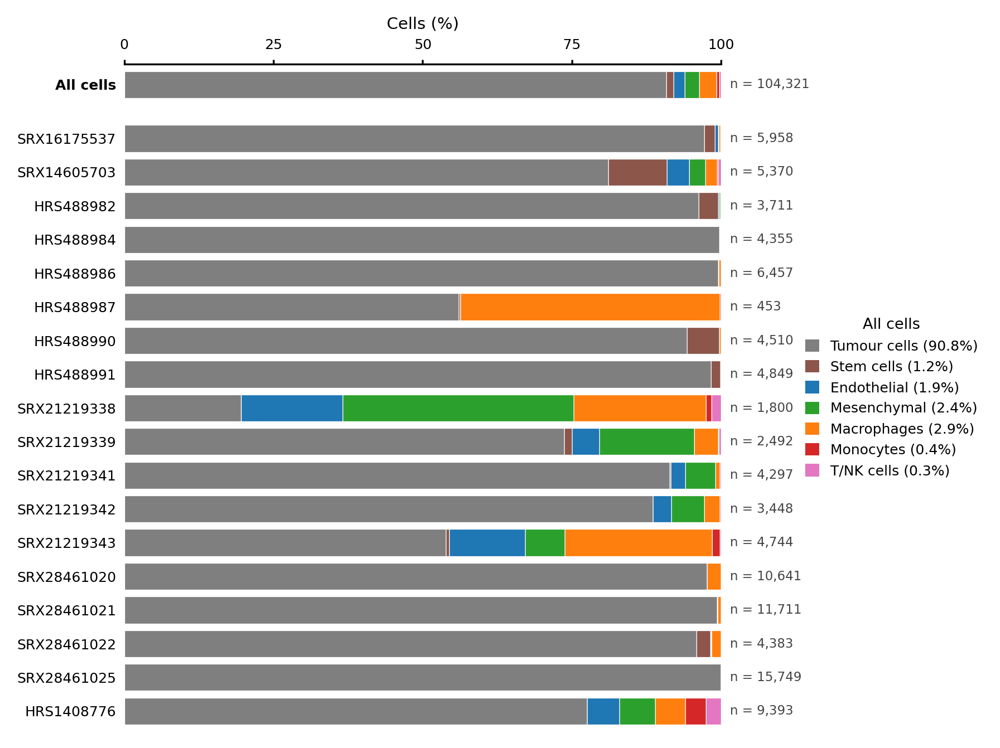

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# ---- 1. Configuration --------------------------------------------------------
celltype_col = "final_cell_type_broad"
sample_col   = "SRA_ID"

# Same order as the columns of panel A (top to bottom here). Edit to match A exactly.
# Samples in the data but not listed are added at the end; listed samples with no cells
# are kept as an empty row marked "excluded", so A and D line up.
sample_order = [
    "SRX16175537", "SRX14605703",
    "HRS488982", "HRS488984", "HRS488986", "HRS488987", "HRS488990", "HRS488991",
    "SRX21219338", "SRX21219339", "SRX21219341", "SRX21219342", "SRX21219343",
    "SRX28461020", "SRX28461021", "SRX28461022", "SRX28461025",
    "HRS1408776",
]

# Same colours and order as panels B and C
pal = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728",
       "T/NK cells": "#e377c2"}

# ---- 2. Proportions ------------------------------------------------------------
obs = adata.obs[[sample_col, celltype_col]].astype(str)
types = [t for t in pal if t in set(obs[celltype_col])]
extra = sorted(set(obs[celltype_col]) - set(types))
if extra:
    print("No colour set for:", extra)
types += extra

counts = pd.crosstab(obs[sample_col], obs[celltype_col]).reindex(columns=types, fill_value=0)
in_data = list(counts.index)
order = list(sample_order) + [s for s in in_data if s not in sample_order]
absent = [s for s in sample_order if s not in in_data]
if absent:
    print("In panel A order but no cells here (shown as 'excluded'):", absent)
counts = counts.reindex(order, fill_value=0)
n_cells = counts.sum(axis=1)
props = counts.div(n_cells.replace(0, np.nan), axis=0).fillna(0) * 100

overall = counts.sum(axis=0)
overall_pct = overall / overall.sum() * 100

# ---- 3. Plot -------------------------------------------------------------------
rows = ["All cells"] + order
y = np.r_[0, np.arange(1, len(order) + 1) + 0.6]           # gap under the "All cells" bar
data = pd.concat([overall_pct.to_frame("All cells").T, props])

fig, ax = plt.subplots(figsize=(4.6, 0.22 * len(rows) + 1.0), dpi=300)
left = np.zeros(len(rows))
for t in types:
    vals = data[t].to_numpy()
    ax.barh(y, vals, left=left, height=0.8, color=pal.get(t, "#cccccc"),
            edgecolor="white", linewidth=0.3)
    left += vals

# cell numbers at the end of each bar; empty rows marked as excluded
ns = [int(overall.sum())] + list(n_cells)
for yi, n in zip(y, ns):
    ax.text(101.5, yi, f"n = {n:,}" if n else "excluded", va="center", fontsize=5.5,
            color="#444444" if n else "#999999")

ax.set_yticks(y)
ax.set_yticklabels(rows, fontsize=6)
ax.get_yticklabels()[0].set_fontweight("bold")
ax.set_ylim(y[-1] + 0.6, -0.6)                              # first row at the top
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelsize=6, length=2)
ax.tick_params(axis="y", length=0)
ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
ax.set_xlabel("Cells (%)", fontsize=7)
for s in ("right", "bottom", "left"):
    ax.spines[s].set_visible(False)

# single legend, with the overall percentage for each cell type
lab = [f"{t} ({overall_pct[t]:.1f}%)" if overall_pct[t] >= 0.1 else f"{t} (<0.1%)" for t in types]
ax.legend(handles=[Patch(facecolor=pal.get(t, "#cccccc"), label=l) for t, l in zip(types, lab)],
          loc="center left", bbox_to_anchor=(1.12, 0.5), frameon=False, fontsize=6,
          handlelength=1, handleheight=1, title="All cells", title_fontsize=6.5)

fig.savefig("Fig1D_composition.pdf", bbox_inches="tight")
fig.savefig("Fig1D_composition.png", dpi=600, bbox_inches="tight")
plt.show()

In [20]:
print(sorted(adata.obs["SRA_ID"].unique()))

['HRS1408776', 'HRS488982', 'HRS488984', 'HRS488986', 'HRS488987', 'HRS488990', 'HRS488991', 'SRX14605703', 'SRX16175537', 'SRX21219338', 'SRX21219339', 'SRX21219341', 'SRX21219342', 'SRX21219343', 'SRX28461020', 'SRX28461021', 'SRX28461022', 'SRX28461025']


In [22]:
adata.obs

,0,n_genes,n_counts,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,...,passed_qc,filtering_junk,n_cells,pct_counts_in_top_20_genes,SRA_barcode,cell_type,leiden_scVI,leiden_scVI_final,final_cell_type_broad,final_cell_type_specific
364181,AAACCCAAGCGCAATG,5659,21946.0,5659,8.641179,18628.0,9.832475,2213.0,7.702556,11.879966,...,NaN,1.0,10239.0,15.342495,HRS1408776AAACCCAAGCGCAATG,unknown,10,21,Tumour cells,Silent_gonadotroph_tumor
364182,AAACCCAAGCGCCTCA,4585,13197.0,4582,8.430109,11572.0,9.356430,643.0,6.467699,5.556516,...,NaN,1.0,10239.0,10.292085,HRS1408776AAACCCAAGCGCCTCA,unknown,10,21,Tumour cells,Silent_gonadotroph_tumor
364183,AAACCCAAGCTACTGT,6306,23261.0,6303,8.748940,19977.0,9.902387,1806.0,7.499424,9.040397,...,NaN,1.0,10239.0,11.658407,HRS1408776AAACCCAAGCTACTGT,unknown,8,21,Tumour cells,Silent_gonadotroph_tumor
364186,AAACCCACATCTTAGG,4213,13188.0,4211,8.345693,11543.0,9.353921,1360.0,7.215975,11.782032,...,NaN,1.0,10239.0,16.650784,HRS1408776AAACCCACATCTTAGG,unknown,10,21,Tumour cells,Silent_gonadotroph_tumor
364187,AAACCCACATGAATCC,3615,10106.0,3566,8.179481,9583.0,9.167850,546.0,6.304449,5.697589,...,NaN,1.0,10239.0,12.511740,HRS1408776AAACCCACATGAATCC,unknown,10,21,Tumour cells,Silent_gonadotroph_tumor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
769613,TTTGTTGGTCAAAGTA,1695,2768.0,1695,7.436028,2659.0,7.886081,83.0,4.430817,3.121474,...,NaN,1.0,6038.0,10.643099,SRX16175537TTTGTTGGTCAAAGTA,unknown,10,27,Tumour cells,Silent_gonadotroph_tumor
769614,TTTGTTGGTCGCGGTT,2303,4666.0,2302,7.741968,4462.0,8.403577,149.0,5.010635,3.339310,...,NaN,1.0,6038.0,10.914388,SRX16175537TTTGTTGGTCGCGGTT,unknown,10,27,Tumour cells,Silent_gonadotroph_tumor
769615,TTTGTTGGTTCTTGCC,1686,2830.0,1689,7.432484,2745.0,7.917901,22.0,3.135494,0.801457,...,NaN,1.0,6038.0,10.018215,SRX16175537TTTGTTGGTTCTTGCC,unknown,10,27,Tumour cells,Silent_gonadotroph_tumor
769616,TTTGTTGTCACATACG,2309,4238.0,2308,7.744570,4030.0,8.301770,135.0,4.912655,3.349876,...,NaN,1.0,6038.0,9.776675,SRX16175537TTTGTTGTCACATACG,unknown,10,27,Tumour cells,Silent_gonadotroph_tumor


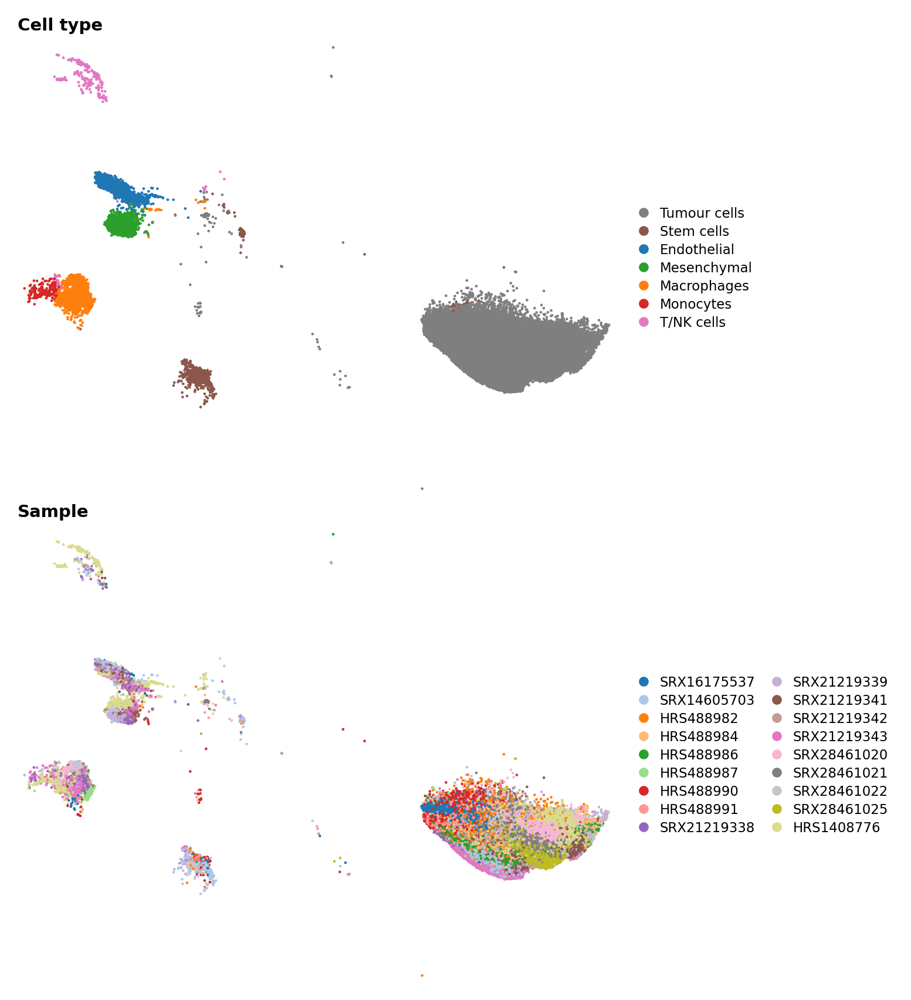

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

celltype_col = "final_cell_type_broad"
sample_col   = "SRA_ID"

ct_pal = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
          "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728",
          "T/NK cells": "#e377c2"}
sample_order = ["SRX16175537", "SRX14605703",
                "HRS488982", "HRS488984", "HRS488986", "HRS488987", "HRS488990", "HRS488991",
                "SRX21219338", "SRX21219339", "SRX21219341", "SRX21219342", "SRX21219343",
                "SRX28461020", "SRX28461021", "SRX28461022", "SRX28461025", "HRS1408776"]
present = set(adata.obs[sample_col].astype(str))
sample_order = [s for s in sample_order if s in present] + sorted(present - set(sample_order))
cmap = plt.get_cmap("tab20")
sample_pal = {s: cmap(i % 20) for i, s in enumerate(sample_order)}

full = adata.obsm["X_umap"]
idx = np.random.default_rng(0).permutation(adata.n_obs)
xy = full[idx]

# Crop to ALL cells (no cluster is lost), with a small margin
pad = 0.3
x0, x1 = full[:, 0].min() - pad, full[:, 0].max() + pad
y0, y1 = full[:, 1].min() - pad, full[:, 1].max() + pad

# Size the figure from the UMAP's shape, so there are no empty bands
plot_w   = 3.4                                  # inches for each UMAP
plot_h   = plot_w * (y1 - y0) / (x1 - x0)       # height that matches the data's aspect
legend_w = 1.7
title_h  = 0.18                                 # room for each title
fig_w, fig_h = plot_w + legend_w, 2 * (plot_h + title_h)
fig = plt.figure(figsize=(fig_w, fig_h), dpi=300)

def panel(row, labels, pal, order, ncol, title):
    bottom = (1 - row) * (plot_h + title_h) / fig_h          # row 0 = top
    ax = fig.add_axes([0, bottom, plot_w / fig_w, plot_h / fig_h])
    ax.scatter(xy[:, 0], xy[:, 1], c=[pal.get(l, "#cccccc") for l in labels[idx]],
               s=1.2, linewidths=0, rasterized=True)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.axis("off")
    fig.text(0.0, bottom + (plot_h + 0.04) / fig_h, title,
             fontsize=7, fontweight="bold", ha="left", va="bottom")
    handles = [Line2D([], [], marker="o", ls="", markersize=4, markerfacecolor=pal[o],
                      markeredgecolor="none", label=o) for o in order]
    fig.legend(handles=handles, loc="center left",
               bbox_to_anchor=(plot_w / fig_w + 0.01, bottom + plot_h / fig_h / 2),
               frameon=False, fontsize=5.5, ncol=ncol, handletextpad=0.2,
               columnspacing=0.6, labelspacing=0.35, borderaxespad=0)

ct_labels = adata.obs[celltype_col].astype(str).to_numpy()
panel(0, ct_labels, ct_pal, [c for c in ct_pal if c in set(ct_labels)], 1, "Cell type")
panel(1, adata.obs[sample_col].astype(str).to_numpy(), sample_pal, sample_order, 2, "Sample")

plt.savefig("Fig1B_umap_celltype_sample.pdf", bbox_inches="tight", pad_inches=0.02, dpi=600)
plt.savefig("Fig1B_umap_celltype_sample.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

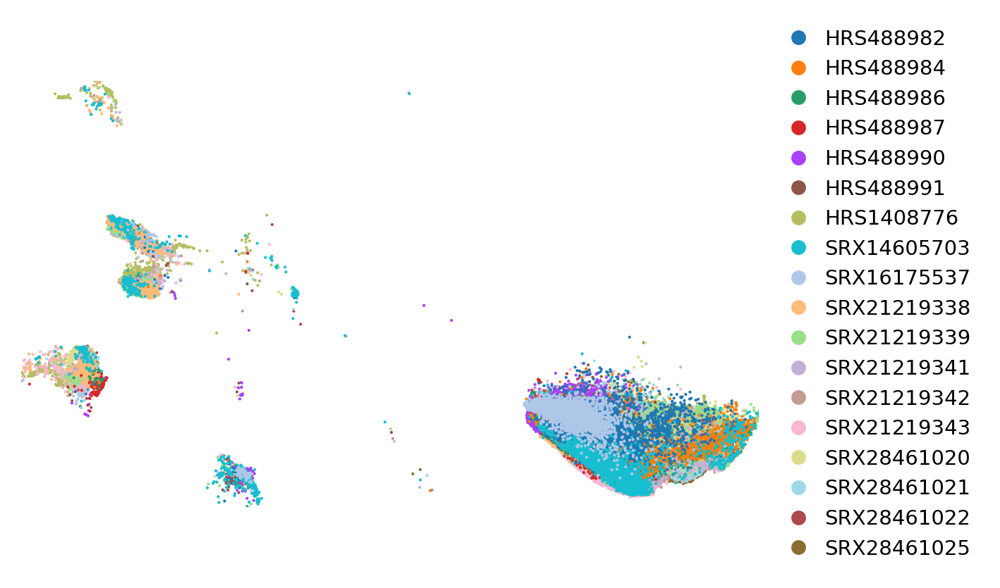

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import scanpy as sc

celltype_col = "SRA_ID"

fig, ax = plt.subplots(figsize=(4.5, 3.2), dpi=300)   # wider to make room for the key
sc.pl.umap(adata, color=celltype_col, ax=ax, size=4, frameon=False,
           legend_loc=None, title="", show=False)

# Key: built by hand so the dots are a readable size and the order is controlled
cats   = list(adata.obs[celltype_col].cat.categories)
colors = adata.uns[f"{celltype_col}_colors"]
order  = ["Tumour cells", "Stem cells", "Pituicytes", "Endothelial", "Mesenchymal",
          "Macrophages", "Monocytes", "T/NK cells"]          # edit to the order you want
order  = [c for c in order if c in cats] + [c for c in cats if c not in order]
handles = [Line2D([], [], marker="o", ls="", markersize=5,
                  markerfacecolor=colors[cats.index(c)], markeredgecolor="none", label=c)
           for c in order]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5),
          frameon=False, fontsize=7, handletextpad=0.3, labelspacing=0.5)

# Crop to the central 99.8% of cells to drop the stray outliers
xy = adata.obsm["X_umap"]
lo, hi = np.percentile(xy, 0.1, axis=0), np.percentile(xy, 99.9, axis=0)
pad = 0.4
ax.set_xlim(lo[0] - pad, hi[0] + pad)
ax.set_ylim(lo[1] - pad, hi[1] + pad)
ax.set_aspect("equal")

plt.savefig("Fig1B_umap_celltypes.pdf", bbox_inches="tight", pad_inches=0.02)
plt.savefig("Fig1B_umap_celltypes.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

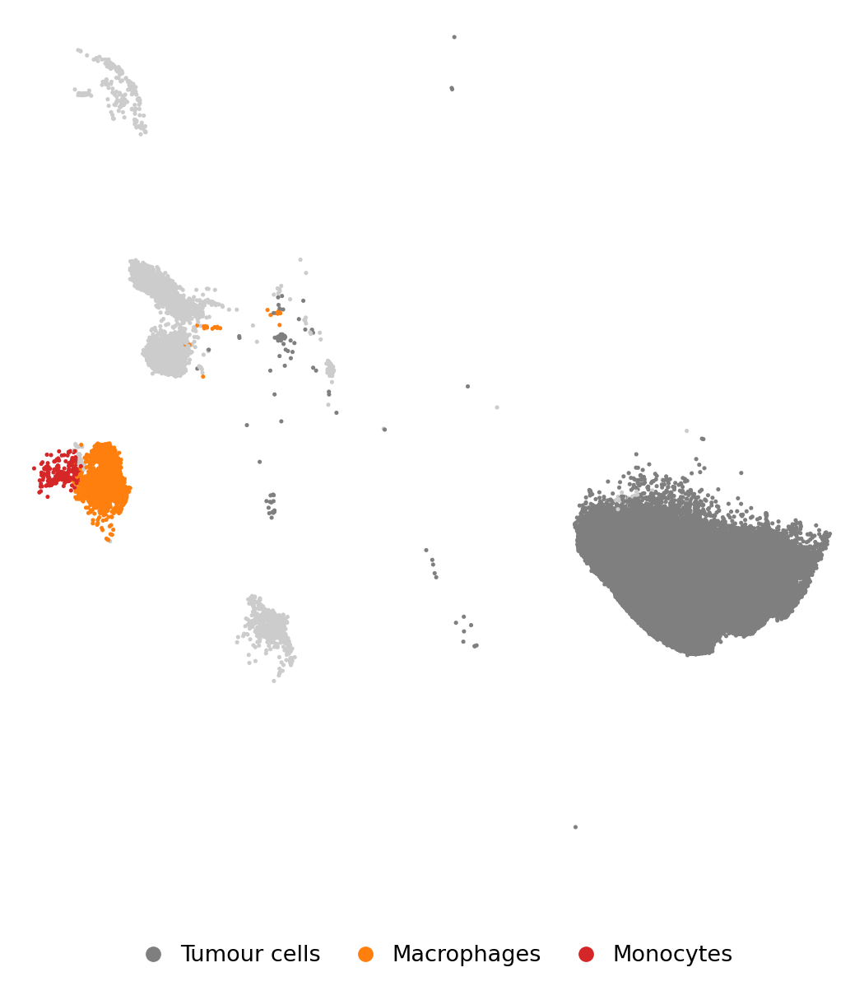

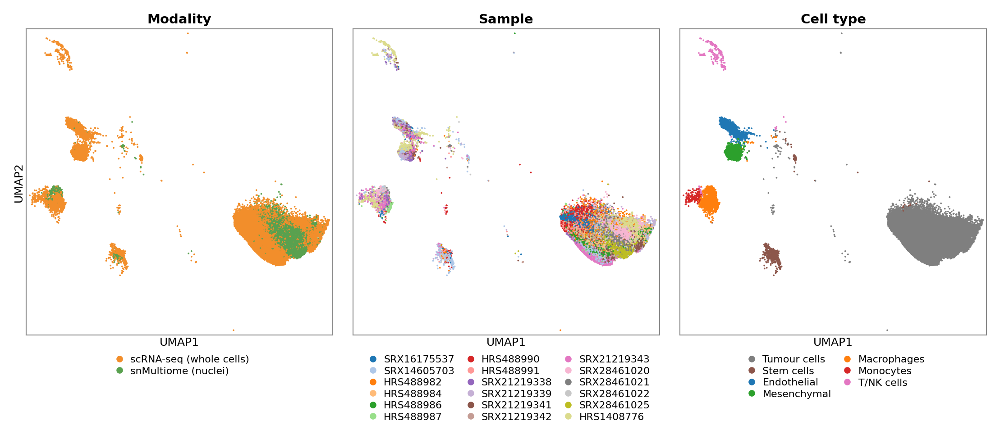

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ---- Columns -----------------------------------------------------------------------
modality_raw = "Modality"              # <- your modality column ("sc" / "multi_rna")
sample_col   = "SRA_ID"
celltype_col = "final_cell_type_broad"

# ---- Clean cell-type names (safe to re-run) --------------------------------------------
rename_ct = {"Endothelial_cells": "Endothelial", "Mesenchymal_cells": "Mesenchymal",
             "T_or_NK_cells": "T/NK cells", "Stem_cells": "Stem cells",
             "Pituicytes": "Tumour cells"}
adata.obs[celltype_col] = (adata.obs[celltype_col].astype(str)
                           .replace(rename_ct).astype("category"))

# ---- Readable modality labels -------------------------------------------------------
mod_names = {"sc": "scRNA-seq (whole cells)", "multi_rna": "snMultiome (nuclei)"}
adata.obs["modality_label"] = adata.obs[modality_raw].astype(str).replace(mod_names)
unknown_mod = set(adata.obs["modality_label"]) - set(mod_names.values())
if unknown_mod:
    print("Unlabelled modality values:", unknown_mod)

# ---- Colours ---------------------------------------------------------------------------
mod_pal = {"scRNA-seq (whole cells)": "#F28E2B",       # same as panel A technology row
           "snMultiome (nuclei)":     "#59A14F"}
mod_order = [m for m in mod_pal if m in set(adata.obs["modality_label"])]

ct_pal = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
          "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728",
          "T/NK cells": "#e377c2"}
ct_order = [c for c in ct_pal if c in set(adata.obs[celltype_col].astype(str))]

sample_order = ["SRX16175537", "SRX14605703",
                "HRS488982", "HRS488984", "HRS488986", "HRS488987", "HRS488990", "HRS488991",
                "SRX21219338", "SRX21219339", "SRX21219341", "SRX21219342", "SRX21219343",
                "SRX28461020", "SRX28461021", "SRX28461022", "SRX28461025", "HRS1408776"]
present = set(adata.obs[sample_col].astype(str))
sample_order = [s for s in sample_order if s in present] + sorted(present - set(sample_order))
tab20 = plt.get_cmap("tab20")
sample_pal = {s: tab20(i % 20) for i, s in enumerate(sample_order)}

# ---- Shared layout --------------------------------------------------------------------
full = adata.obsm["X_umap"]
idx = np.random.default_rng(0).permutation(adata.n_obs)   # random draw order
xy = full[idx]
pad = 0.3
x0, x1 = full[:, 0].min() - pad, full[:, 0].max() + pad
y0, y1 = full[:, 1].min() - pad, full[:, 1].max() + pad

fig_w   = 7.1                 # full page width (180 mm)
gap     = 0.15                # space between plots, inches
side    = (fig_w - 2 * gap) / 3
leg_h   = 1.15                # room for the legends underneath
title_h = 0.18
fig_h   = title_h + side + leg_h
fig = plt.figure(figsize=(fig_w, fig_h), dpi=300)

def umap_panel(i, col, pal, order, ncol, title):
    left = i * (side + gap) / fig_w
    bottom = leg_h / fig_h
    ax = fig.add_axes([left, bottom, side / fig_w, side / fig_h])
    labels = adata.obs[col].astype(str).to_numpy()[idx]
    ax.scatter(xy[:, 0], xy[:, 1], c=[pal.get(l, "#cccccc") for l in labels],
               s=0.8, linewidths=0, rasterized=True)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_aspect("auto")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_linewidth(0.5); s.set_color("#888888")
    ax.set_title(title, fontsize=7, fontweight="bold", pad=3)
    ax.set_xlabel("UMAP1", fontsize=6, labelpad=1)
    if i == 0:
        ax.set_ylabel("UMAP2", fontsize=6, labelpad=1)
    handles = [Line2D([], [], marker="o", ls="", markersize=3.5, markerfacecolor=pal[o],
                      markeredgecolor="none", label=o) for o in order]
    fig.legend(handles=handles, loc="upper center",
               bbox_to_anchor=(left + side / fig_w / 2, (leg_h - 0.12) / fig_h),
               ncol=ncol, frameon=False, fontsize=5.3, handletextpad=0.1,
               columnspacing=0.6, labelspacing=0.25, borderaxespad=0)

umap_panel(0, "modality_label", mod_pal, mod_order, 1, "Modality")
umap_panel(1, sample_col, sample_pal, sample_order, 3, "Sample")
umap_panel(2, celltype_col, ct_pal, ct_order, 2, "Cell type")

plt.savefig("Fig1C_umaps.pdf", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig("Fig1C_umaps.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

SenMayo genes found: 123/124
Missing: ['CCL3L1']
final_cell_type_broad
Macrophages     0.279348
Monocytes       0.233015
Endothelial     0.220432
Mesenchymal     0.191687
Stem cells      0.112379
T/NK cells      0.095244
Tumour cells    0.026484
Name: SenMayo_score, dtype: float64


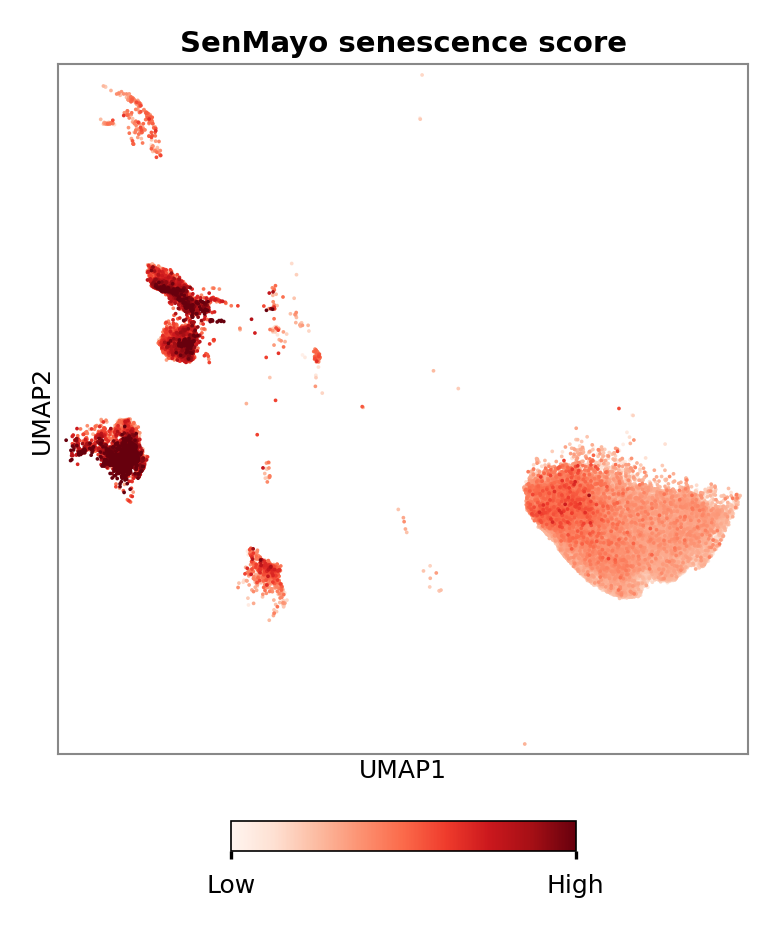

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc

celltype_col = "final_cell_type_broad"

# ---- 1. SenMayo gene set (Saul et al., Nat Commun 2022; 125 genes) ----------------
# Check against the paper's Supplementary Data 1 before publishing.
senmayo = """ACVR1B ANG ANGPT1 ANGPTL4 AREG AXL BEX3 BMP2 BMP6 C3 CCL1 CCL13 CCL16 CCL2 CCL20
CCL24 CCL26 CCL3 CCL3L1 CCL4 CCL5 CCL7 CCL8 CD55 CD9 CSF1 CSF2 CSF2RB CST4 CTNNB1 CTSB
CXCL1 CXCL10 CXCL12 CXCL16 CXCL2 CXCL3 CXCL8 CXCR2 DKK1 EDN1 EGF EGFR EREG ESM1 ETS2 FAS
FGF1 FGF2 FGF7 GDF15 GEM GMFG HGF HMGB1 ICAM1 ICAM3 IGF1 IGFBP1 IGFBP2 IGFBP3 IGFBP4
IGFBP5 IGFBP6 IGFBP7 IL10 IL13 IL15 IL18 IL1A IL1B IL2 IL32 IL6 IL6ST IL7 INHA IQGAP2
ITGA2 ITPKA JUN KITLG LCP1 MIF MMP1 MMP10 MMP12 MMP13 MMP14 MMP2 MMP3 MMP9 NAP1L4 NRG1
PAPPA PECAM1 PGF PLAT PLAU PLAUR PTBP1 PTGER2 PTGES RPS6KA5 SCAMP4 SELPLG SEMA3F SERPINB4
SERPINE1 SERPINE2 SPP1 SPX TIMP2 TNF TNFRSF10C TNFRSF11B TNFRSF1A TNFRSF1B TUBGCP2 VEGFA
VEGFC VGF WNT16 WNT2""".split()

use_raw = adata.raw is not None
genes_avail = adata.raw.var_names if use_raw else adata.var_names
found = [g for g in senmayo if g in genes_avail]
print(f"SenMayo genes found: {len(found)}/{len(senmayo)}")
print("Missing:", sorted(set(senmayo) - set(found)))

# ---- 2. Score each cell -----------------------------------------------------------
sc.tl.score_genes(adata, gene_list=found, score_name="SenMayo_score",
                  use_raw=use_raw, random_state=0)

# median score per cell type (useful for the Results text)
print(adata.obs.groupby(celltype_col)["SenMayo_score"].median().sort_values(ascending=False))

# ---- 3. Plot (same crop as panel C) ------------------------------------------------
full = adata.obsm["X_umap"]
score = adata.obs["SenMayo_score"].to_numpy()
order = np.argsort(score)                   # highest scores drawn on top
pad = 0.3
x0, x1 = full[:, 0].min() - pad, full[:, 0].max() + pad
y0, y1 = full[:, 1].min() - pad, full[:, 1].max() + pad
vmin, vmax = np.percentile(score, [1, 99])  # stop a few extreme cells washing out the scale

side = 2.3                                  # same size as each panel C plot
fig = plt.figure(figsize=(side, side + 0.55), dpi=300)
ax = fig.add_axes([0, 0.55 / (side + 0.55), 1, side / (side + 0.55)])
pts = ax.scatter(full[order, 0], full[order, 1], c=score[order], cmap="Reds",
                 vmin=vmin, vmax=vmax, s=0.8, linewidths=0, rasterized=True)
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("auto")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_linewidth(0.5); s.set_color("#888888")
ax.set_title("SenMayo senescence score", fontsize=7, fontweight="bold", pad=3)
ax.set_xlabel("UMAP1", fontsize=6, labelpad=1)
ax.set_ylabel("UMAP2", fontsize=6, labelpad=1)

cax = fig.add_axes([0.25, 0.08, 0.5, 0.035])
cb = fig.colorbar(pts, cax=cax, orientation="horizontal")
cb.set_ticks([vmin, vmax]); cb.set_ticklabels(["Low", "High"])
cb.ax.tick_params(labelsize=6, length=2)
cb.outline.set_linewidth(0.4)

plt.savefig("Fig1E_senmayo_umap.pdf", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig("Fig1E_senmayo_umap.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

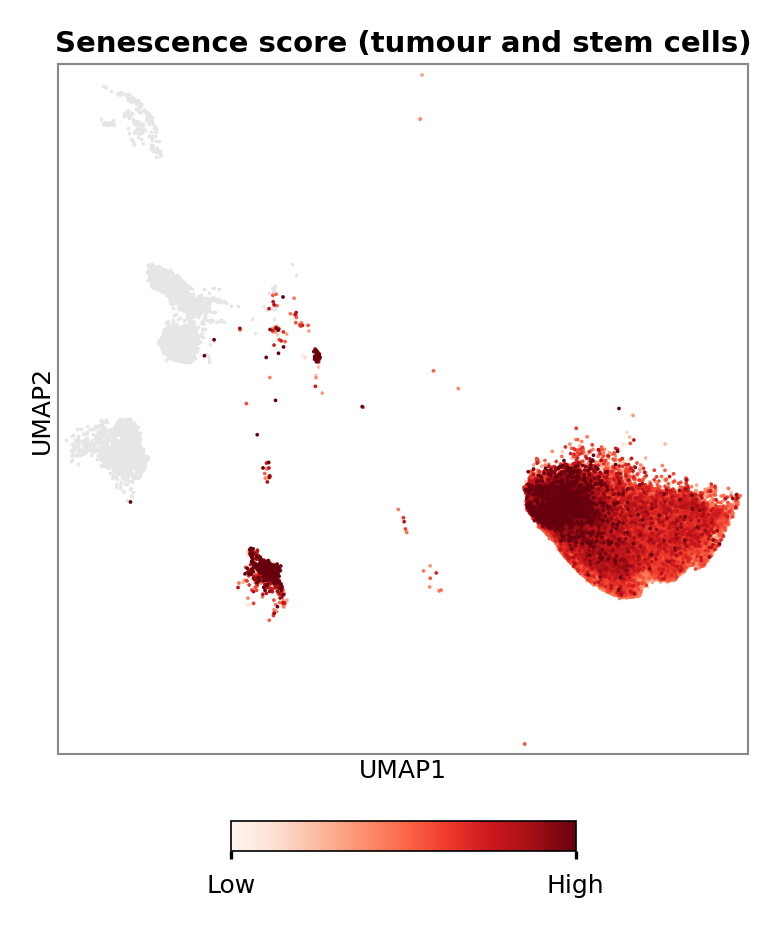

SRA_ID
HRS488991      0.076445
HRS488990      0.075278
SRX16175537    0.057426
HRS488982      0.055608
HRS488987      0.048629
HRS1408776     0.046694
HRS488986      0.044508
HRS488984      0.042385
SRX21219342    0.040673
SRX21219338    0.038477
SRX21219339    0.037233
SRX14605703    0.036667
SRX21219343    0.028262
SRX21219341    0.021018
SRX28461021    0.006443
SRX28461020   -0.000161
SRX28461022   -0.001154
SRX28461025   -0.003236
Name: SenMayo_score, dtype: float64


In [21]:
import numpy as np
import matplotlib.pyplot as plt

celltype_col = "final_cell_type_broad"
focus = ["Tumour cells", "Stem cells"]            # cells whose senescence we care about

full  = adata.obsm["X_umap"]
score = adata.obs["SenMayo_score"].to_numpy()
ct    = adata.obs[celltype_col].astype(str).to_numpy()
is_focus = np.isin(ct, focus)

vmin, vmax = np.percentile(score[is_focus], [1, 99])   # scale set by tumour + stem cells only
order = np.where(is_focus)[0][np.argsort(score[is_focus])]   # highest on top

pad = 0.3
x0, x1 = full[:, 0].min() - pad, full[:, 0].max() + pad
y0, y1 = full[:, 1].min() - pad, full[:, 1].max() + pad

side = 2.3
fig = plt.figure(figsize=(side, side + 0.55), dpi=300)
ax = fig.add_axes([0, 0.55 / (side + 0.55), 1, side / (side + 0.55)])
ax.scatter(full[~is_focus, 0], full[~is_focus, 1], c="#E6E6E6", s=0.8,
           linewidths=0, rasterized=True)                       # context, grey
pts = ax.scatter(full[order, 0], full[order, 1], c=score[order], cmap="Reds",
                 vmin=vmin, vmax=vmax, s=0.8, linewidths=0, rasterized=True)
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("auto")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_linewidth(0.5); s.set_color("#888888")
ax.set_title("Senescence score (tumour and stem cells)", fontsize=7, fontweight="bold", pad=3)
ax.set_xlabel("UMAP1", fontsize=6, labelpad=1)
ax.set_ylabel("UMAP2", fontsize=6, labelpad=1)

cax = fig.add_axes([0.25, 0.08, 0.5, 0.035])
cb = fig.colorbar(pts, cax=cax, orientation="horizontal")
cb.set_ticks([vmin, vmax]); cb.set_ticklabels(["Low", "High"])
cb.ax.tick_params(labelsize=6, length=2); cb.outline.set_linewidth(0.4)

plt.savefig("Fig1E_senmayo_tumour.pdf", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig("Fig1E_senmayo_tumour.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

# Check: is the high-scoring region one patient, or several?
t = adata.obs[np.isin(ct, ["Tumour cells"])]
print(t.groupby("SRA_ID")["SenMayo_score"].median().sort_values(ascending=False))

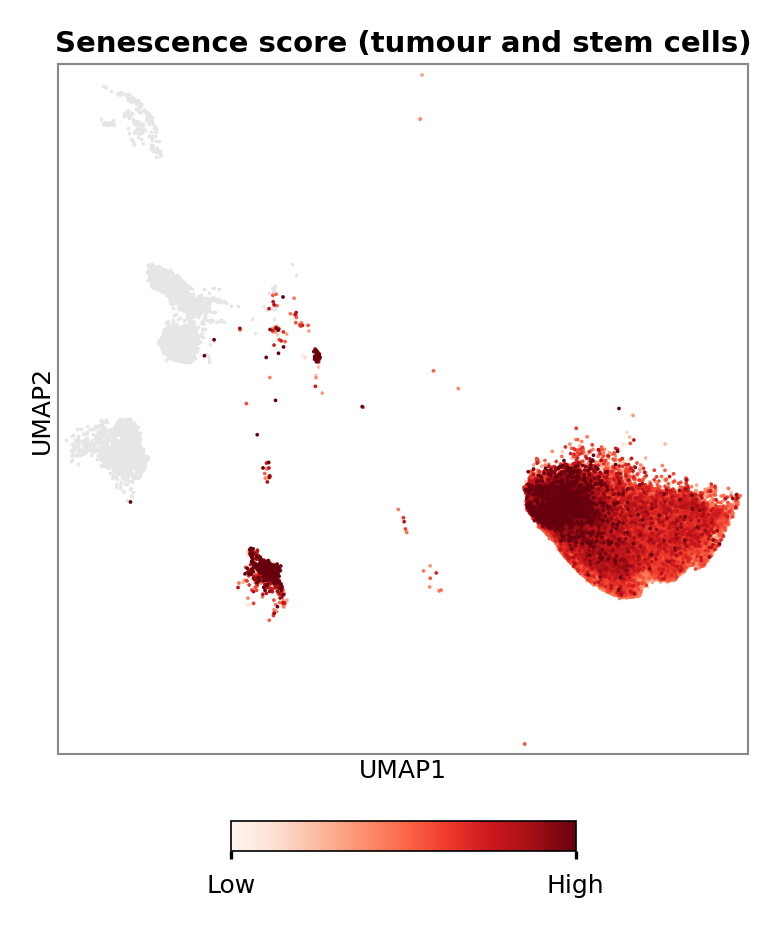

SRA_ID
HRS488991      0.076445
HRS488990      0.075278
SRX16175537    0.057426
HRS488982      0.055608
HRS488987      0.048629
HRS1408776     0.046694
HRS488986      0.044508
HRS488984      0.042385
SRX21219342    0.040673
SRX21219338    0.038477
SRX21219339    0.037233
SRX14605703    0.036667
SRX21219343    0.028262
SRX21219341    0.021018
SRX28461021    0.006443
SRX28461020   -0.000161
SRX28461022   -0.001154
SRX28461025   -0.003236
Name: SenMayo_score, dtype: float64


In [22]:
import numpy as np
import matplotlib.pyplot as plt

celltype_col = "final_cell_type_broad"
focus = ["Tumour cells", "Stem cells"]            # cells whose senescence we care about

full  = adata.obsm["X_umap"]
score = adata.obs["SenMayo_score"].to_numpy()
ct    = adata.obs[celltype_col].astype(str).to_numpy()
is_focus = np.isin(ct, focus)

vmin, vmax = np.percentile(score[is_focus], [1, 99])   # scale set by tumour + stem cells only
order = np.where(is_focus)[0][np.argsort(score[is_focus])]   # highest on top

pad = 0.3
x0, x1 = full[:, 0].min() - pad, full[:, 0].max() + pad
y0, y1 = full[:, 1].min() - pad, full[:, 1].max() + pad

side = 2.3
fig = plt.figure(figsize=(side, side + 0.55), dpi=300)
ax = fig.add_axes([0, 0.55 / (side + 0.55), 1, side / (side + 0.55)])
ax.scatter(full[~is_focus, 0], full[~is_focus, 1], c="#E6E6E6", s=0.8,
           linewidths=0, rasterized=True)                       # context, grey
pts = ax.scatter(full[order, 0], full[order, 1], c=score[order], cmap="Reds",
                 vmin=vmin, vmax=vmax, s=0.8, linewidths=0, rasterized=True)
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("auto")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_linewidth(0.5); s.set_color("#888888")
ax.set_title("Senescence score (tumour and stem cells)", fontsize=7, fontweight="bold", pad=3)
ax.set_xlabel("UMAP1", fontsize=6, labelpad=1)
ax.set_ylabel("UMAP2", fontsize=6, labelpad=1)

cax = fig.add_axes([0.25, 0.08, 0.5, 0.035])
cb = fig.colorbar(pts, cax=cax, orientation="horizontal")
cb.set_ticks([vmin, vmax]); cb.set_ticklabels(["Low", "High"])
cb.ax.tick_params(labelsize=6, length=2); cb.outline.set_linewidth(0.4)

plt.savefig("Fig1E_senmayo_tumour.pdf", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig("Fig1E_senmayo_tumour.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

# Check: is the high-scoring region one patient, or several?
t = adata.obs[np.isin(ct, ["Tumour cells"])]
print(t.groupby("SRA_ID")["SenMayo_score"].median().sort_values(ascending=False))

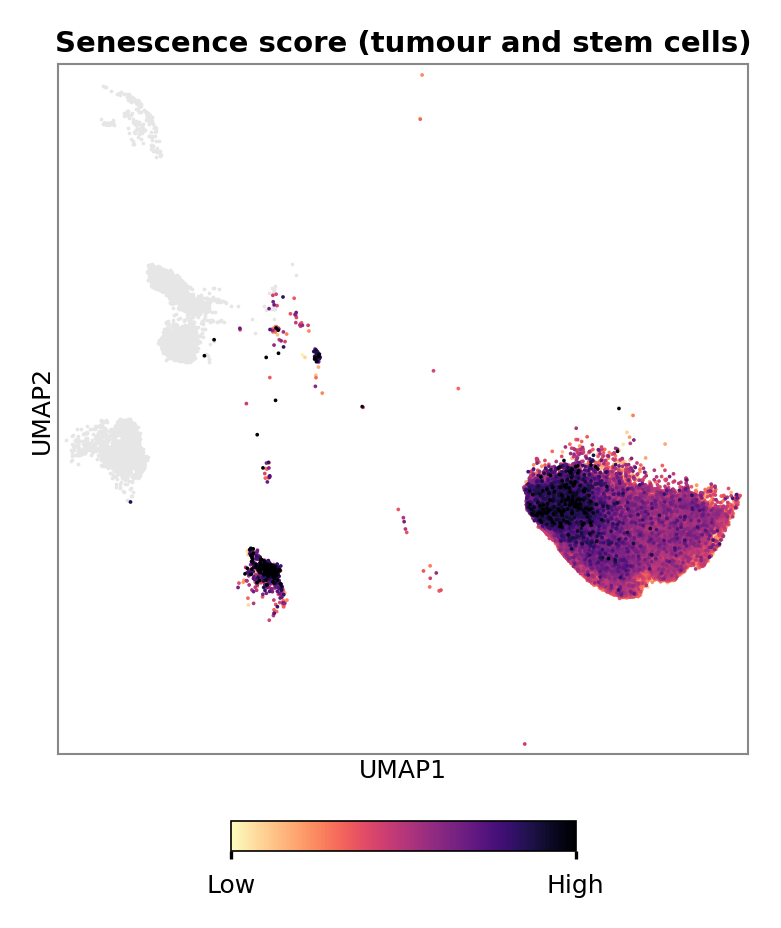


Tumour-cell senescence score by sample:
             median      n
SRA_ID                    
HRS488991     0.076   4765
HRS488990     0.075   4250
SRX16175537   0.057   5792
HRS488982     0.056   3570
HRS488987     0.049    254
HRS1408776    0.047   7286
HRS488986     0.045   6428
HRS488984     0.042   4341
SRX21219342   0.041   3053
SRX21219338   0.038    352
SRX21219339   0.037   1837
SRX14605703   0.037   4357
SRX21219343   0.028   2555
SRX21219341   0.021   3928
SRX28461021   0.006  11635
SRX28461020  -0.000  10391
SRX28461022  -0.001   4202
SRX28461025  -0.003  15741

Tumour-cell score by Invasion:
Invasion
Invasion        0.047
Invasive        0.063
No              0.041
Non_invasive    0.048
Yes             0.028
Name: SenMayo_score, dtype: float64


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc

celltype_col = "final_cell_type_broad"
sample_col   = "SRA_ID"
focus = ["Tumour cells", "Stem cells"]        # cells whose senescence we show

# ---- 0. Clean cell-type names (safe to re-run) ------------------------------------------
rename_ct = {"Endothelial_cells": "Endothelial", "Mesenchymal_cells": "Mesenchymal",
             "T_or_NK_cells": "T/NK cells", "Stem_cells": "Stem cells",
             "Pituicytes": "Tumour cells"}
adata.obs[celltype_col] = (adata.obs[celltype_col].astype(str)
                           .replace(rename_ct).astype("category"))

# ---- 1. SenMayo score (Saul et al., Nat Commun 2022) - computed once ---------------
if "SenMayo_score" not in adata.obs:
    senmayo = """ACVR1B ANG ANGPT1 ANGPTL4 AREG AXL BEX3 BMP2 BMP6 C3 CCL1 CCL13 CCL16 CCL2
    CCL20 CCL24 CCL26 CCL3 CCL3L1 CCL4 CCL5 CCL7 CCL8 CD55 CD9 CSF1 CSF2 CSF2RB CST4 CTNNB1
    CTSB CXCL1 CXCL10 CXCL12 CXCL16 CXCL2 CXCL3 CXCL8 CXCR2 DKK1 EDN1 EGF EGFR EREG ESM1 ETS2
    FAS FGF1 FGF2 FGF7 GDF15 GEM GMFG HGF HMGB1 ICAM1 ICAM3 IGF1 IGFBP1 IGFBP2 IGFBP3 IGFBP4
    IGFBP5 IGFBP6 IGFBP7 IL10 IL13 IL15 IL18 IL1A IL1B IL2 IL32 IL6 IL6ST IL7 INHA IQGAP2
    ITGA2 ITPKA JUN KITLG LCP1 MIF MMP1 MMP10 MMP12 MMP13 MMP14 MMP2 MMP3 MMP9 NAP1L4 NRG1
    PAPPA PECAM1 PGF PLAT PLAU PLAUR PTBP1 PTGER2 PTGES RPS6KA5 SCAMP4 SELPLG SEMA3F SERPINB4
    SERPINE1 SERPINE2 SPP1 SPX TIMP2 TNF TNFRSF10C TNFRSF11B TNFRSF1A TNFRSF1B TUBGCP2 VEGFA
    VEGFC VGF WNT16 WNT2""".split()        # check against the paper's Supplementary Data 1
    use_raw = adata.raw is not None
    avail = adata.raw.var_names if use_raw else adata.var_names
    found = [g for g in senmayo if g in avail]
    print(f"SenMayo genes found: {len(found)}/{len(senmayo)}; missing: {sorted(set(senmayo) - set(found))}")
    sc.tl.score_genes(adata, gene_list=found, score_name="SenMayo_score",
                      use_raw=use_raw, random_state=0)

# ---- 2. Plot: tumour + stem cells coloured, everything else grey -------------------------
full  = adata.obsm["X_umap"]
score = adata.obs["SenMayo_score"].to_numpy()
ct    = adata.obs[celltype_col].astype(str).to_numpy()
is_focus = np.isin(ct, focus)

vmin, vmax = np.percentile(score[is_focus], [2, 99.8])        # less saturation at the top
order = np.where(is_focus)[0][np.argsort(score[is_focus])]    # highest drawn on top

pad = 0.3
x0, x1 = full[:, 0].min() - pad, full[:, 0].max() + pad
y0, y1 = full[:, 1].min() - pad, full[:, 1].max() + pad

side = 2.3                                    # same size as each panel C plot
fig = plt.figure(figsize=(side, side + 0.55), dpi=300)
ax = fig.add_axes([0, 0.55 / (side + 0.55), 1, side / (side + 0.55)])
ax.scatter(full[~is_focus, 0], full[~is_focus, 1], c="#E6E6E6", s=0.8,
           linewidths=0, rasterized=True)
pts = ax.scatter(full[order, 0], full[order, 1], c=score[order], cmap="magma_r",
                 vmin=vmin, vmax=vmax, s=0.8, linewidths=0, rasterized=True)
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("auto")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_linewidth(0.5); s.set_color("#888888")
ax.set_title("Senescence score (tumour and stem cells)", fontsize=7, fontweight="bold", pad=3)
ax.set_xlabel("UMAP1", fontsize=6, labelpad=1)
ax.set_ylabel("UMAP2", fontsize=6, labelpad=1)

cax = fig.add_axes([0.25, 0.08, 0.5, 0.035])
cb = fig.colorbar(pts, cax=cax, orientation="horizontal")
cb.set_ticks([vmin, vmax]); cb.set_ticklabels(["Low", "High"])
cb.ax.tick_params(labelsize=6, length=2); cb.outline.set_linewidth(0.4)

plt.savefig("Fig1E_senmayo_tumour.pdf", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig("Fig1E_senmayo_tumour.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()

# ---- 3. Check: one or two patients, or many? ----------------------------------------------
tum = adata.obs[ct == "Tumour cells"]
by_sample = (tum.groupby(sample_col)["SenMayo_score"]
                .agg(median="median", n="size")
                .sort_values("median", ascending=False))
print("\nTumour-cell senescence score by sample:")
print(by_sample.round(3))

for c in ("Invasion", "invasion", "Invasive"):          # if invasion status is in obs
    if c in adata.obs:
        print(f"\nTumour-cell score by {c}:")
        print(tum.groupby(c)["SenMayo_score"].median().round(3))
        break

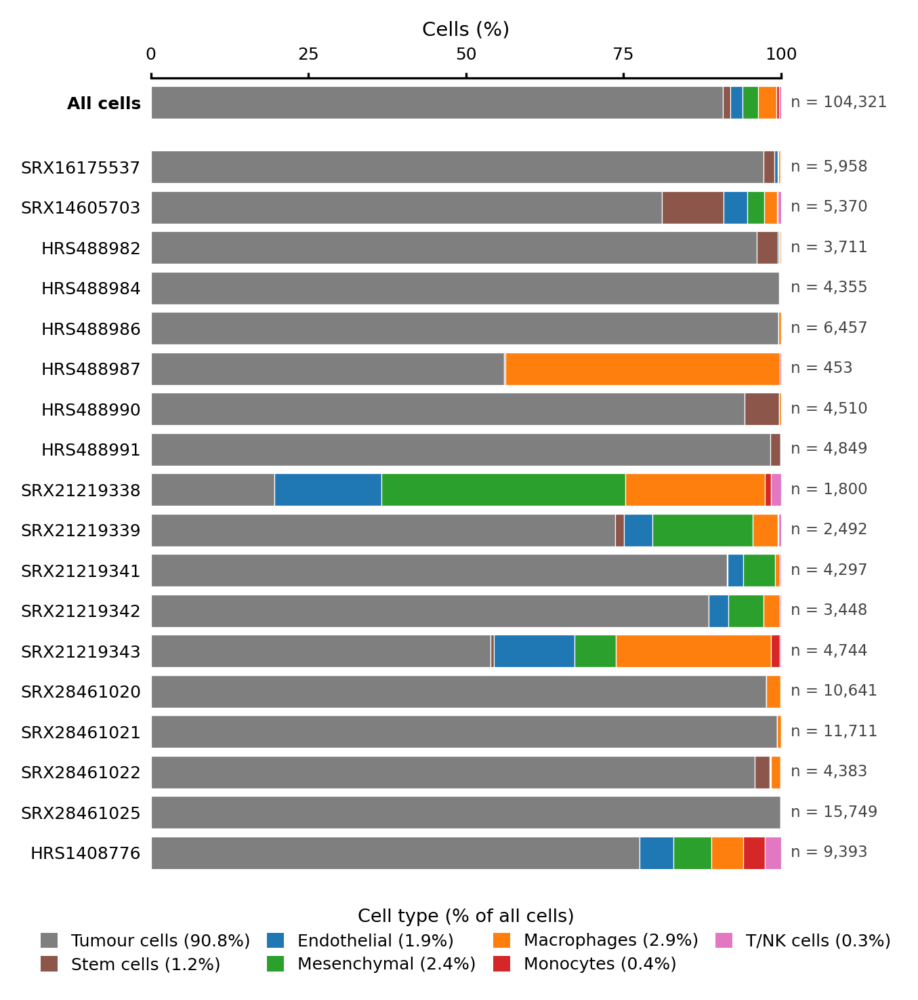

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# ---- 1. Configuration --------------------------------------------------------
celltype_col = "final_cell_type_broad"
sample_col   = "SRA_ID"

# Same order as the columns of panel A (top to bottom here). Edit to match A exactly.
# Samples in the data but not listed are added at the end; listed samples with no cells
# are kept as an empty row marked "excluded", so A and D line up.
sample_order = [
    "SRX16175537", "SRX14605703",
    "HRS488982", "HRS488984", "HRS488986", "HRS488987", "HRS488990", "HRS488991",
    "SRX21219338", "SRX21219339", "SRX21219341", "SRX21219342", "SRX21219343",
    "SRX28461020", "SRX28461021", "SRX28461022", "SRX28461025",
    "HRS1408776",
]

# Same colours and order as panels B and C
pal = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728",
       "T/NK cells": "#e377c2"}

# ---- 2. Proportions ------------------------------------------------------------
obs = adata.obs[[sample_col, celltype_col]].astype(str)
types = [t for t in pal if t in set(obs[celltype_col])]
extra = sorted(set(obs[celltype_col]) - set(types))
if extra:
    print("No colour set for:", extra)
types += extra

counts = pd.crosstab(obs[sample_col], obs[celltype_col]).reindex(columns=types, fill_value=0)
in_data = list(counts.index)
order = list(sample_order) + [s for s in in_data if s not in sample_order]
absent = [s for s in sample_order if s not in in_data]
if absent:
    print("In panel A order but no cells here (shown as 'excluded'):", absent)
counts = counts.reindex(order, fill_value=0)
n_cells = counts.sum(axis=1)
props = counts.div(n_cells.replace(0, np.nan), axis=0).fillna(0) * 100

overall = counts.sum(axis=0)
overall_pct = overall / overall.sum() * 100

# ---- 3. Plot -------------------------------------------------------------------
rows = ["All cells"] + order
y = np.r_[0, np.arange(1, len(order) + 1) + 0.6]           # gap under the "All cells" bar
data = pd.concat([overall_pct.to_frame("All cells").T, props])

fig, ax = plt.subplots(figsize=(4.0, 0.2 * len(rows) + 1.3), dpi=300)   # narrower; extra height for the legend below
left = np.zeros(len(rows))
for t in types:
    vals = data[t].to_numpy()
    ax.barh(y, vals, left=left, height=0.8, color=pal.get(t, "#cccccc"),
            edgecolor="white", linewidth=0.3)
    left += vals

# cell numbers at the end of each bar; empty rows marked as excluded
ns = [int(overall.sum())] + list(n_cells)
for yi, n in zip(y, ns):
    ax.text(101.5, yi, f"n = {n:,}" if n else "excluded", va="center", fontsize=5.5,
            color="#444444" if n else "#999999")

ax.set_yticks(y)
ax.set_yticklabels(rows, fontsize=6)
ax.get_yticklabels()[0].set_fontweight("bold")
ax.set_ylim(y[-1] + 0.6, -0.6)                              # first row at the top
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelsize=6, length=2)
ax.tick_params(axis="y", length=0)
ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
ax.set_xlabel("Cells (%)", fontsize=7)
for s in ("right", "bottom", "left"):
    ax.spines[s].set_visible(False)

# single legend, with the overall percentage for each cell type
lab = [f"{t} ({overall_pct[t]:.1f}%)" if overall_pct[t] >= 0.1 else f"{t} (<0.1%)" for t in types]
ax.legend(handles=[Patch(facecolor=pal.get(t, "#cccccc"), label=l) for t, l in zip(types, lab)],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False, fontsize=6,
          handlelength=1, handleheight=1, columnspacing=1.0, labelspacing=0.4,
          title="Cell type (% of all cells)", title_fontsize=6.5)

fig.savefig("Fig1D_composition.pdf", bbox_inches="tight")
fig.savefig("Fig1D_composition.png", dpi=600, bbox_inches="tight")
plt.show()

In [29]:
import pandas as pd

obs = adata.obs
print([c for c in obs.columns])          # all column names, for reference

# 1. Study: use an existing column if there is one, otherwise group by accession
cand = [c for c in obs.columns if any(k in c.lower() for k in ("study", "dataset", "batch", "source", "author"))]
if cand:
    study_col = cand[0]
    print("Using study column:", study_col)
else:
    def sra_to_study(s):
        for p in ("SRX28461", "SRX21219", "HRS4889", "HRS1408", "SRX16175", "SRX14605"):
            if s.startswith(p):
                return p
        return "other"
    obs["study_from_id"] = obs["SRA_ID"].astype(str).map(sra_to_study)
    study_col = "study_from_id"
    print("No study column found; grouped by accession prefix")

# 2. Harmonise invasion labels
inv_map = {"Invasion": "Invasive", "Invasive": "Invasive", "Yes": "Invasive",
           "No": "Non-invasive", "Non_invasive": "Non-invasive"}
obs["Invasion_clean"] = obs["Invasion"].astype(str).map(inv_map).fillna("Unknown")
print(obs.groupby(["Invasion", "Invasion_clean"], observed=True).size())

# 3. One row per sample (tumour cells only)
mod = "modality_label" if "modality_label" in obs.columns else "modality"
tum = obs[obs["final_cell_type_broad"].astype(str) == "Tumour cells"]
per_sample = (tum.groupby(["SRA_ID", study_col, mod, "Invasion_clean"], observed=True)
                 ["SenMayo_score"].agg(median="median", n="size").reset_index()
                 .sort_values([study_col, "Invasion_clean", "median"]))
print(per_sample.to_string(index=False))
per_sample.to_csv("SenMayo_per_sample.csv", index=False)

['0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'assay', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'Internal_ID', 'Name', 'Normal', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'n_cells', 'pct_counts_in_top_20_genes', 'SRA_barcode', 'cell_type', 'leiden_scVI', 'leiden_scVI_final', 'final_cell_type_broad', 'final_cell_type_specific', 'modality_label', 'SenMayo_score', 'Invasion_clean']
Using study column: Author
Invasion      Invasion_clean
Invasion

In [30]:
import pandas as pd
genes = ["NR5A1", "TBX19", "POMC", "POU1F1"]
tum = adata[adata.obs["final_cell_type_broad"] == "Tumour cells"]
X = sc.get.obs_df(tum, keys=genes, use_raw=adata.raw is not None)
pct = (X > 0).groupby(tum.obs["SRA_ID"].values).mean().mul(100).round(1)
print(pct.join(tum.obs.groupby("SRA_ID", observed=True)["Lineage"].first()))

             NR5A1  TBX19  POMC  POU1F1 Lineage
HRS488982      5.2    1.5  13.1     3.2    Null
HRS488984     23.1    1.4   2.4     4.4   NR5A1
HRS488986     30.1    3.2   3.0    10.4   NR5A1
HRS488987      1.6    1.2   0.4     0.0    Null
HRS488990      3.7    0.2   2.4     0.4   NR5A1
HRS488991      8.2    0.3   2.9     0.6   NR5A1
HRS1408776    54.5    6.4   0.0     0.1   NR5A1
SRX14605703   49.6   13.7   0.4     0.0   NR5A1
SRX16175537   17.8    0.5   0.6     0.0   NR5A1
SRX21219338   45.5    3.1   0.3     1.4   NR5A1
SRX21219339   18.5   10.1   1.0     3.3   NR5A1
SRX21219341   36.3    4.1   0.3     0.0   NR5A1
SRX21219342   65.4    9.2   1.2     0.3   NR5A1
SRX21219343   18.0    8.3  26.7     0.3   NR5A1
SRX28461020   11.7    3.5   0.0     0.5   NR5A1
SRX28461021   26.5    3.2   0.0     0.9   NR5A1
SRX28461022   24.6    4.4   0.0     0.4   NR5A1
SRX28461025   17.5    2.3   0.0     0.0   NR5A1


In [31]:
tum = adata[adata.obs["final_cell_type_broad"] == "Tumour cells"]
X = sc.get.obs_df(tum, keys=["POMC", "TBX19", "CGA", "FSHB", "NR5A1"],
                  use_raw=adata.raw is not None)
pomc_hi = X["POMC"] > 1                      # clearly POMC-expressing cells
print("POMC-high cells:", pomc_hi.sum())
print(tum.obs.loc[pomc_hi, "SRA_ID"].value_counts().head())
print("\n% of POMC-high cells also expressing:")
print((X[pomc_hi][["TBX19", "CGA", "FSHB", "NR5A1"]] > 0).mean().mul(100).round(1))
print("\n'Normal' annotation of POMC-high cells:")
print(tum.obs.loc[pomc_hi, "Normal"].value_counts())

POMC-high cells: 797
SRA_ID
HRS488982    339
HRS488991    140
HRS488990    103
HRS488986     97
HRS488984     62
Name: count, dtype: int64

% of POMC-high cells also expressing:
TBX19     1.8
CGA      32.6
FSHB     32.7
NR5A1     9.5
dtype: float64

'Normal' annotation of POMC-high cells:
Normal
0    797
Name: count, dtype: int64


In [33]:
adata

AnnData object with n_obs × n_vars = 104321 × 39074
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'assay', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'Internal_ID', 'Name', 'Normal', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'n_cells', 'pct_counts_in_top_20_genes', 'SRA_barcode', 'cell_type', 'leiden_scVI', 'leiden_scVI_final', 'final_cell_type_broad', 'final_cell_type_specific', 'modality_label', 'SenMayo_score', 'Invasion_clean'
    v

In [34]:
import numpy as np
import pandas as pd
import scanpy as sc

# ---- Supplementary Table 1: one row per sample in the integrated atlas ----------
obs = adata.obs.copy()
sid = "SRA_ID"

# 0. What the QC flags contain (if all True, this object is already filtered and
#    pre-QC cell numbers must come from the raw per-study objects)
for c in ("passed_qc", "filtering_junk", "predicted_doublet"):
    if c in obs.columns:
        print(c, obs[c].value_counts(dropna=False).to_dict())

# 1. Sample-level metadata (first value per sample; columns missing are skipped)
meta_cols = ["Author", "Internal_ID", "assay", "10X version", "modality_label",
             "Lineage", "Subtype", "Invasion_clean", "KNOSP", "KI67",
             "Age_numeric", "Sex"]
meta_cols = [c for c in meta_cols if c in obs.columns]
meta = obs.groupby(sid, observed=True)[meta_cols].first()

# 2. QC summary per sample (cells in the final atlas)
qc = obs.groupby(sid, observed=True).agg(
    cells=("n_genes_by_counts", "size"),
    median_genes=("n_genes_by_counts", "median"),
    median_UMIs=("total_counts", "median"),
    median_pct_mt=("pct_counts_mt", "median"),
).round({"median_genes": 0, "median_UMIs": 0, "median_pct_mt": 2})

# 3. Cell-type composition (% of cells in each sample)
comp = (pd.crosstab(obs[sid], obs["final_cell_type_broad"], normalize="index") * 100).round(1)
comp.columns = [f"% {c}" for c in comp.columns]

# 4. Lineage markers: % of tumour cells with detectable expression
genes = [g for g in ["NR5A1", "CGA", "FSHB", "LHB", "TBX19", "POMC", "POU1F1"]
         if g in adata.var_names]
tum = adata[adata.obs["final_cell_type_broad"].astype(str) == "Tumour cells"]
X = sc.get.obs_df(tum, keys=genes, use_raw=False)
lin = ((X > 0).groupby(tum.obs[sid].astype(str).values).mean() * 100).round(1)
lin.columns = [f"% tumour cells {g}+" for g in lin.columns]

# 5. Senescence score (median across tumour cells)
sen = tum.obs.groupby(sid, observed=True)["SenMayo_score"].median().round(3).rename(
    "SenMayo median (tumour cells)")

# 6. Combine, order as in Fig. 1A, save
table = meta.join(qc).join(comp).join(lin).join(sen)
table.index = table.index.astype(str)
order = ["SRX16175537", "SRX14605703",
         "HRS488982", "HRS488984", "HRS488986", "HRS488987", "HRS488990", "HRS488991",
         "SRX21219338", "SRX21219339", "SRX21219341", "SRX21219342", "SRX21219343",
         "SRX28461020", "SRX28461021", "SRX28461022", "SRX28461025",
         "HRS1408776"]
table = table.reindex([s for s in order if s in table.index] +
                      [s for s in table.index if s not in order])
table = table.rename(columns={"Author": "Study", "assay": "Assay", "10X version": "10x chemistry",
                              "modality_label": "Modality", "Invasion_clean": "Invasion",
                              "Age_numeric": "Age (years)", "Internal_ID": "Sample ID (study)"})
table.index.name = "Accession"

# Totals row
tot = pd.Series(index=table.columns, dtype=object)
tot["Study"] = "All samples"
tot["cells"] = int(table["cells"].sum())
table = pd.concat([table, tot.to_frame("Total").T])

table.to_excel("SuppTable1_samples.xlsx")
table.to_csv("SuppTable1_samples.csv")
print(table.iloc[:, :8].to_string())

passed_qc {nan: 99966, 1.0: 4355}
filtering_junk {1.0: 104321}
predicted_doublet {'False': 88678, 'True': 15643}
                             Study Sample ID (study)      Assay 10x chemistry                 Modality Lineage             Subtype      Invasion
SRX16175537   Asuzu et al., (2022)         pta_sc_39         sc         10XV3  scRNA-seq (whole cells)   NR5A1  Silent Gonadotroph       Unknown
SRX14605703  Zhang et al., (2022b)         pta_sc_47         sc         10XV3  scRNA-seq (whole cells)   NR5A1  Silent Gonadotroph       Unknown
HRS488982       Yan et al., (2024)         pta_sc_66         sc         10XV2  scRNA-seq (whole cells)    Null                Null  Non-invasive
HRS488984       Yan et al., (2024)         pta_sc_68         sc         10XV2  scRNA-seq (whole cells)   NR5A1  Silent Gonadotroph      Invasive
HRS488986       Yan et al., (2024)         pta_sc_70         sc         10XV2  scRNA-seq (whole cells)   NR5A1  Silent Gonadotroph  Non-invasive
HRS488987       Y


CDKN1A
              % expressing  mean (log-norm)  % of total expression
Tumour cells           4.1            0.038                   35.6
Stem cells            24.7            0.320                    3.9
Endothelial           71.0            0.972                   19.2
Mesenchymal           48.0            0.612                   15.3
Macrophages           53.3            0.696                   20.8
Monocytes             71.0            0.981                    4.1
T/NK cells            22.9            0.310                    1.0

GLB1
              % expressing  mean (log-norm)  % of total expression
Tumour cells          22.1            0.203                   88.9
Stem cells            23.9            0.207                    1.2
Endothelial           34.9            0.221                    2.1
Mesenchymal           20.0            0.178                    2.1
Macrophages           35.6            0.333                    4.7
Monocytes             37.3            0.325     

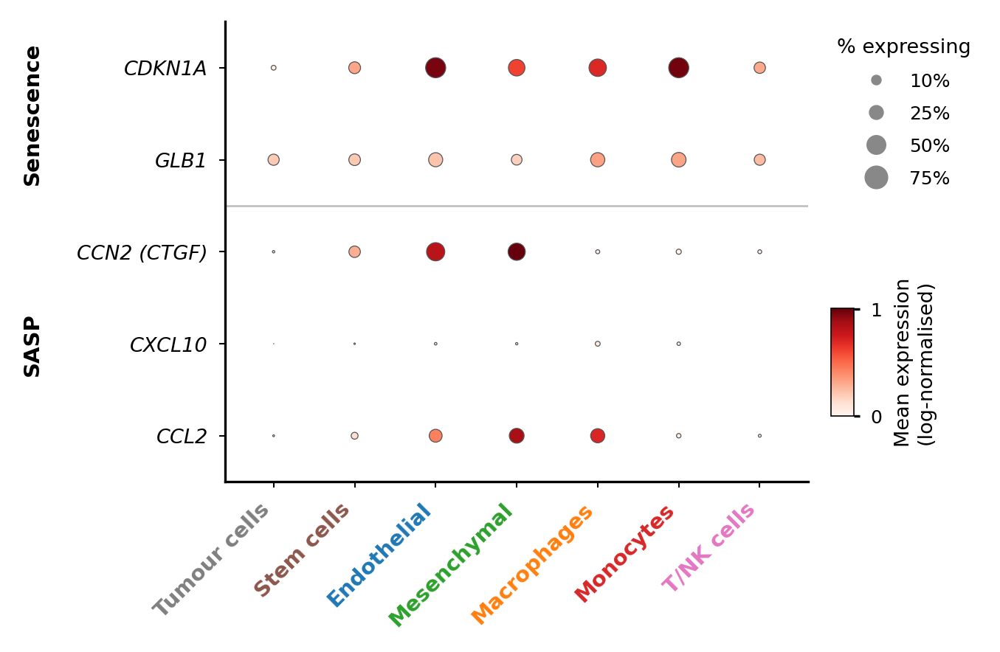

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

# ---- 1. Configuration --------------------------------------------------------
label_col = "final_cell_type_broad"
use_raw = adata.raw is not None

order = ["Tumour cells", "Stem cells", "Endothelial", "Mesenchymal",
         "Macrophages", "Monocytes", "T/NK cells"]
aliases = {"Stem_cells": "Stem cells", "Endothelial_cells": "Endothelial",
           "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells",
           "Pituicytes": "Tumour cells"}
colors = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
          "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728",
          "T/NK cells": "#e377c2"}

# Genes measured in tissue, grouped as in the paper. CTGF is called CCN2 in newer
# annotations; whichever name is present is used and shown as "CCN2 (CTGF)".
groups = {"Senescence": ["CDKN1A", "GLB1"],
          "SASP":       ["CCN2", "CXCL10", "CCL2"]}
alt_names = {"CCN2": "CTGF"}
display = {"CCN2": "CCN2 (CTGF)", "CTGF": "CCN2 (CTGF)"}

# ---- 2. Expression summary ---------------------------------------------------
labels = adata.obs[label_col].astype(str).replace(aliases).to_numpy()
order = [c for c in order if c in set(labels)]
var_names = adata.raw.var_names if use_raw else adata.var_names

genes, gene_group = [], []
for grp, gl in groups.items():
    for g in gl:
        name = g if g in var_names else alt_names.get(g)
        if name in var_names:
            genes.append(name); gene_group.append(grp)
        else:
            print("Not found, dropped:", g)

expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
frac = np.zeros((len(genes), len(order)))
mean = np.zeros_like(frac)
total = np.zeros_like(frac)
for j, ct in enumerate(order):
    sub = expr[labels == ct].to_numpy(dtype=float)
    frac[:, j] = (sub > 0).mean(axis=0)
    mean[:, j] = sub.mean(axis=0)
    total[:, j] = sub.sum(axis=0)

# Printed summary: % expressing, mean expression, and share of all expression
# (the share answers "which cell type contributes most of this transcript",
#  which depends on cell numbers as well as per-cell level)
share = total / total.sum(axis=1, keepdims=True) * 100
for i, g in enumerate(genes):
    print(f"\n{display.get(g, g)}")
    print(pd.DataFrame({"% expressing": (frac[i] * 100).round(1),
                        "mean (log-norm)": mean[i].round(3),
                        "% of total expression": share[i].round(1)}, index=order).to_string())

# ---- 3. Plot -----------------------------------------------------------------
# Colour = mean log-normalised expression on ONE shared scale (not scaled per gene),
# so levels can be compared between genes as well as between cell types.
max_size = 60
vmax = np.percentile(mean, 99) if mean.max() > 0 else 1
fig, ax = plt.subplots(figsize=(3.4, 0.24 * len(genes) + 1.5), dpi=300)
yy, xx = np.meshgrid(np.arange(len(genes)), np.arange(len(order)), indexing="ij")
sc_ = ax.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * max_size,
                 c=mean.ravel(), cmap="Reds", vmin=0, vmax=vmax,
                 edgecolors="#555555", linewidths=0.3)

ax.set_yticks(range(len(genes)))
ax.set_yticklabels([display.get(g, g) for g in genes], fontsize=6.5, fontstyle="italic")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right", fontsize=7)
for lab, ct in zip(ax.get_xticklabels(), order):
    lab.set_color(colors[ct]); lab.set_fontweight("bold")
ax.set_xlim(-0.6, len(order) - 0.4)
ax.set_ylim(len(genes) - 0.5, -0.5)

# group separators and labels on the left
start = 0
for grp in groups:
    n = gene_group.count(grp)
    if n == 0:
        continue
    if start > 0:
        ax.axhline(start - 0.5, color="#BBBBBB", lw=0.6, zorder=0)
    ax.annotate(grp, xy=(-0.33, 1 - (start + n / 2) / len(genes)), xycoords="axes fraction",
                rotation=90, ha="center", va="center", fontsize=7, fontweight="bold")
    start += n
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=2, width=0.5)

size_handles = [Line2D([], [], marker="o", ls="", color="#888888",
                       markersize=np.sqrt(p * max_size), label=f"{int(p * 100)}%")
                for p in (0.1, 0.25, 0.5, 0.75)]
ax.legend(handles=size_handles, title="% expressing", loc="upper left",
          bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=6, title_fontsize=6.5,
          labelspacing=0.8)
cax = fig.add_axes([0.93, 0.22, 0.03, 0.18])
cb = fig.colorbar(sc_, cax=cax)
cb.ax.tick_params(labelsize=6, length=2)
cb.set_label("Mean expression\n(log-normalised)", fontsize=6.5)
cb.outline.set_linewidth(0.4)

fig.savefig("SuppFig_SASP_dotplot.pdf", bbox_inches="tight")
fig.savefig("SuppFig_SASP_dotplot.svg", bbox_inches="tight")
fig.savefig("SuppFig_SASP_dotplot.png", dpi=600, bbox_inches="tight")
plt.show()

Excluded (<20 stem cells): {'HRS1408776': 1, 'HRS488984': 4, 'HRS488986': 1, 'HRS488987': 1, 'SRX21219338': 0, 'SRX21219341': 5, 'SRX21219342': 0, 'SRX28461020': 0, 'SRX28461021': 0, 'SRX28461025': 0}
final_cell_type_broad  Tumour cells  Stem cells  n_stem
SRA_ID                                                 
HRS488982                     0.056       0.115     122
HRS488990                     0.075       0.111     245
HRS488991                     0.076       0.115      78
SRX14605703                   0.037       0.112     526
SRX16175537                   0.057       0.164     105
SRX21219339                   0.037       0.145      33
SRX21219343                   0.028       0.176      28
SRX28461022                  -0.001       0.045     104

Stem > tumour in 8/8 samples; paired Wilcoxon P = 0.00781


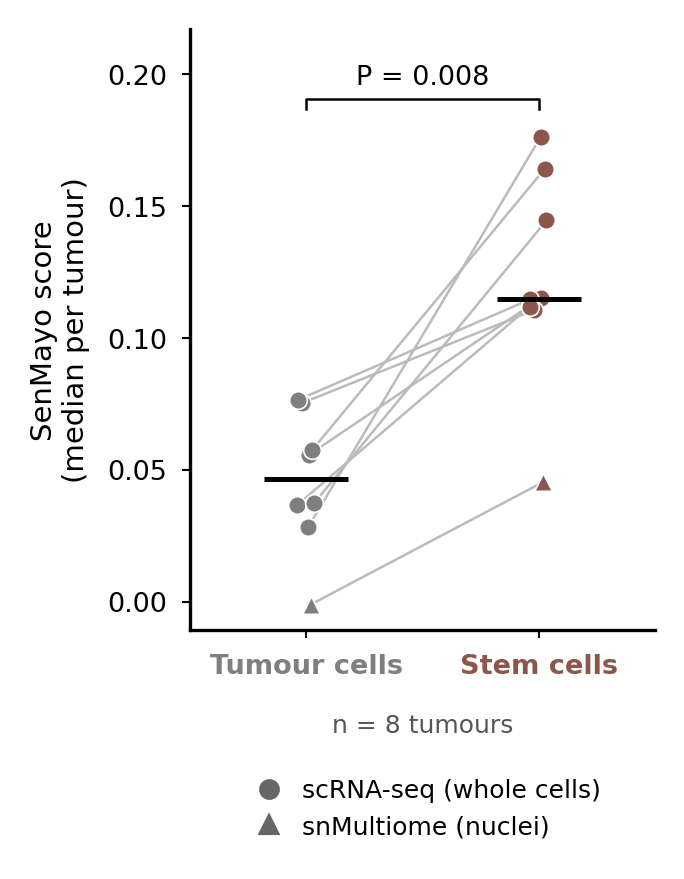

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
score_col  = "SenMayo_score"
mod_col    = "modality_label"
min_stem   = 20                     # samples need at least this many stem cells
groups     = ["Tumour cells", "Stem cells"]
colors     = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b"}
markers    = {"scRNA-seq (whole cells)": "o", "snMultiome (nuclei)": "^"}

# ---- 2. One median score per sample and cell type ---------------------------
obs = adata.obs[[sample_col, label_col, score_col, mod_col]].copy()
obs[label_col] = obs[label_col].astype(str).replace({"Stem_cells": "Stem cells",
                                                     "Pituicytes": "Tumour cells"})
obs = obs[obs[label_col].isin(groups)]

n_cells = obs.groupby([sample_col, label_col], observed=True).size().unstack(fill_value=0)
med = obs.groupby([sample_col, label_col], observed=True)[score_col].median().unstack()
mod = obs.groupby(sample_col, observed=True)[mod_col].first().astype(str)

keep = n_cells.index[n_cells.get("Stem cells", 0) >= min_stem]
dropped = sorted(set(n_cells.index) - set(keep))
if dropped:
    print(f"Excluded (<{min_stem} stem cells):",
          {s: int(n_cells.loc[s, "Stem cells"]) if "Stem cells" in n_cells else 0 for s in dropped})
med = med.loc[keep, groups].dropna()

stat = wilcoxon(med["Stem cells"], med["Tumour cells"])
n_up = int((med["Stem cells"] > med["Tumour cells"]).sum())
print(med.round(3).assign(n_stem=n_cells.loc[med.index, "Stem cells"]).to_string())
print(f"\nStem > tumour in {n_up}/{len(med)} samples; paired Wilcoxon P = {stat.pvalue:.3g}")

# ---- 3. Plot -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.0, 2.6), dpi=300)
x = {g: i for i, g in enumerate(groups)}
rng = np.random.default_rng(0)
for s, row in med.iterrows():
    jit = rng.uniform(-0.04, 0.04)
    ax.plot([x[groups[0]] + jit, x[groups[1]] + jit], row[groups].to_numpy(),
            color="#BBBBBB", lw=0.6, zorder=1)
    for g in groups:
        ax.scatter(x[g] + jit, row[g], s=18, color=colors[g], marker=markers.get(mod[s], "o"),
                   edgecolors="white", linewidths=0.4, zorder=2)

# group medians as short black bars
for g in groups:
    ax.hlines(med[g].median(), x[g] - 0.18, x[g] + 0.18, color="black", lw=1.2, zorder=3)

ax.set_xticks(range(len(groups)))
ax.set_xticklabels(groups, fontsize=7)
for lab, g in zip(ax.get_xticklabels(), groups):
    lab.set_color(colors[g]); lab.set_fontweight("bold")
ax.set_xlim(-0.5, len(groups) - 0.5)
ax.set_ylabel("SenMayo score\n(median per tumour)", fontsize=7)
ax.tick_params(labelsize=6.5, length=2, width=0.5)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

# P value bracket
top = med.to_numpy().max()
span = top - med.to_numpy().min()
yb = top + 0.08 * span
ax.plot([0, 0, 1, 1], [yb - 0.02 * span, yb, yb, yb - 0.02 * span], color="black", lw=0.6)
ptxt = "P < 0.001" if stat.pvalue < 0.001 else f"P = {stat.pvalue:.3f}" if stat.pvalue < 0.01 else f"P = {stat.pvalue:.2f}"
ax.text(0.5, yb + 0.02 * span, ptxt, ha="center", va="bottom", fontsize=6.5)
ax.set_ylim(top=yb + 0.15 * span)
ax.text(0.5, -0.17, f"n = {len(med)} tumours", transform=ax.transAxes,
        ha="center", fontsize=6, color="#555555")

# modality key (only if both present)
present = [m for m in markers if m in set(mod[med.index])]
if len(present) > 1:
    ax.legend(handles=[Line2D([], [], marker=markers[m], ls="", color="#666666", markersize=4,
                              label=m) for m in present],
              loc="upper center", bbox_to_anchor=(0.5, -0.21), frameon=False, fontsize=6,
              handletextpad=0.3)

fig.savefig("Fig2B_SenMayo_stem_vs_tumour.pdf", bbox_inches="tight")
fig.savefig("Fig2B_SenMayo_stem_vs_tumour.svg", bbox_inches="tight")
fig.savefig("Fig2B_SenMayo_stem_vs_tumour.png", dpi=600, bbox_inches="tight")
plt.show()

Stem outline covers 940/1253 stem-labelled cells
CDKN1A: expressed in 4.1% tumour cells, 24.7% stem cells
CDKN1B: expressed in 23.9% tumour cells, 23.3% stem cells
GLB1: expressed in 22.1% tumour cells, 23.9% stem cells


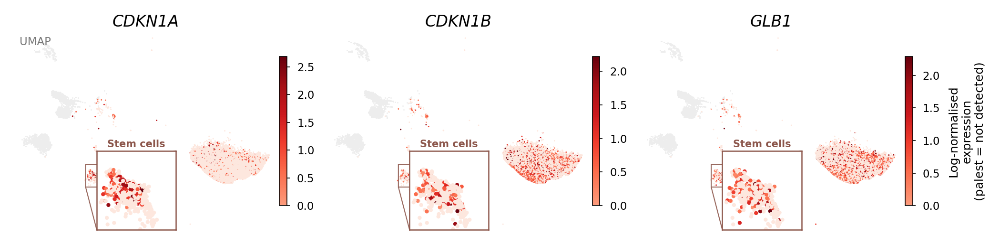

In [47]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.spatial import cKDTree
from matplotlib.patches import Ellipse

# ---- 1. Configuration --------------------------------------------------------
genes          = ["CDKN1A", "CDKN1B", "GLB1"]
label_col      = "final_cell_type_broad"
use_raw        = adata.raw is not None
highlight_stem = True          # dashed outline around the stem cell cluster
stem_label     = "Stem cells"
cmap           = "Reds"
pt_size        = 0.5           # small dots stop 94k tumour cells overplotting into solid red
draw_order     = "random"      # "random": honest density; "sorted": expressing cells on top
fig_w          = 7.1           # inches (180 mm, full page width)
focus_types    = ["Tumour cells", "Stem cells"]   # coloured; all other cells light grey (as in 2A)
pos_scale      = 1.0           # >1 makes positives bigger (more pop, but exaggerates frequency)
inset          = True          # zoomed view of the stem cluster in each panel
inset_pos      = [0.31, 0.0, 0.31, 0.40]          # axes fraction [x, y, w, h]; move into empty space

# ---- 2. Data -----------------------------------------------------------------
genes = [g for g in genes if g in (adata.raw.var_names if use_raw else adata.var_names)]
expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
xy = adata.obsm["X_umap"]
labels = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()

# same crop for every panel
pad = 0.03
xr, yr = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
xlim = (xy[:, 0].min() - pad * xr, xy[:, 0].max() + pad * xr)
ylim = (xy[:, 1].min() - pad * yr, xy[:, 1].max() + pad * yr)

# stem cluster outline: ellipse around the DENSE core of stem cells only
# (stem-labelled cells scattered elsewhere on the UMAP are ignored)
stem_xy = xy[labels == stem_label]
if highlight_stem and len(stem_xy) > 10:
    r = 0.03 * max(xr, yr)
    dens = np.array([len(n) for n in cKDTree(stem_xy).query_ball_point(stem_xy, r)])
    seed = stem_xy[dens.argmax()]                      # densest point = cluster centre
    core = stem_xy[np.linalg.norm(stem_xy - seed, axis=1) < 4 * r]
    core = core[dens[np.linalg.norm(stem_xy - seed, axis=1) < 4 * r] >= np.percentile(dens, 25)]
    c = np.median(core, axis=0)
    d = np.abs(core - c)
    w, h = 2 * np.percentile(d[:, 0], 98) * 1.3 + r, 2 * np.percentile(d[:, 1], 98) * 1.3 + r
    print(f"Stem outline covers {len(core)}/{len(stem_xy)} stem-labelled cells")

# ---- 3. Plot -----------------------------------------------------------------
focus = np.isin(labels, focus_types)
panel_h = fig_w / len(genes) * (yr / xr) * 0.92
fig, axes = plt.subplots(1, len(genes), figsize=(fig_w, panel_h + 0.4), dpi=300)
axes = np.atleast_1d(axes)

# Colour map: 0 (not detected) = very pale pink, any detected expression jumps to a
# clearly visible red and darkens with level. Tumour/stem cells are therefore ALL
# coloured (none look excluded); only other cell types are grey.
from matplotlib.colors import LinearSegmentedColormap
reds = plt.get_cmap(cmap)(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])

def draw(a, v, vmax, s):
    # 1) other cell types: light grey
    a.scatter(xy[~focus, 0], xy[~focus, 1], s=s, color="#EDEDED", linewidths=0, rasterized=True)
    # 2) tumour/stem cells: non-expressing first (pale pink), expressing on top (reds)
    neg = np.where(focus & (v <= 0))[0]
    pos = np.where(focus & (v > 0))[0]
    pos = pos[np.argsort(v[pos])] if draw_order == "sorted" else np.random.default_rng(0).permutation(pos)
    if draw_order == "sorted":
        idx = np.r_[neg, pos]                    # positives on top (pops, but overstates frequency)
    else:
        idx = np.random.default_rng(0).permutation(np.r_[neg, pos])   # true density
    return a.scatter(xy[idx, 0], xy[idx, 1], c=v[idx], s=s, cmap=pop_cmap,
                     vmin=0, vmax=vmax, linewidths=0, rasterized=True)

for ax, g in zip(axes, genes):
    v = expr[g].to_numpy(dtype=float)
    vf = v[focus]
    vmax = np.percentile(vf[vf > 0], 99) if (vf > 0).any() else 1
    im = draw(ax, v, vmax, pt_size)
    ax.set_title(g, fontsize=8, fontstyle="italic", pad=3)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)

    if highlight_stem and len(stem_xy) > 10:
        if inset:
            ins = ax.inset_axes(inset_pos)
            draw(ins, v, vmax, pt_size * 8)
            half = max(w, h) / 2 * 1.15
            ins.set_xlim(c[0] - half, c[0] + half); ins.set_ylim(c[1] - half, c[1] + half)
            ins.set_aspect("equal"); ins.set_xticks([]); ins.set_yticks([])
            for sp in ins.spines.values():
                sp.set_edgecolor("#8c564b"); sp.set_linewidth(0.6)
            ins.text(0.5, 1.02, "Stem cells", transform=ins.transAxes, va="bottom", ha="center",
                     fontsize=5, color="#8c564b", fontweight="bold")
            ax.indicate_inset_zoom(ins, edgecolor="#8c564b", lw=0.5, alpha=0.9)
        else:
            ax.add_patch(Ellipse(c, w, h, fill=False, ls="--", lw=0.7, ec="#8c564b"))

    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01, shrink=0.6)
    cb.ax.tick_params(labelsize=5.5, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    pct = {ct: (v[labels == ct] > 0).mean() * 100 for ct in ("Tumour cells", stem_label)}
    print(f"{g}: expressed in {pct['Tumour cells']:.1f}% tumour cells, "
          f"{pct[stem_label]:.1f}% stem cells")

cb.set_label("Log-normalised\nexpression\n(palest = not detected)", fontsize=6)
axes[0].text(0.02, 0.98, "UMAP", transform=axes[0].transAxes, va="top", fontsize=5.5, color="#777777")
fig.tight_layout(w_pad=0.6)

fig.savefig("Fig2C_senescence_UMAPs.pdf", bbox_inches="tight")
fig.savefig("Fig2C_senescence_UMAPs.svg", bbox_inches="tight")
fig.savefig("Fig2C_senescence_UMAPs.png", dpi=600, bbox_inches="tight")
plt.show()

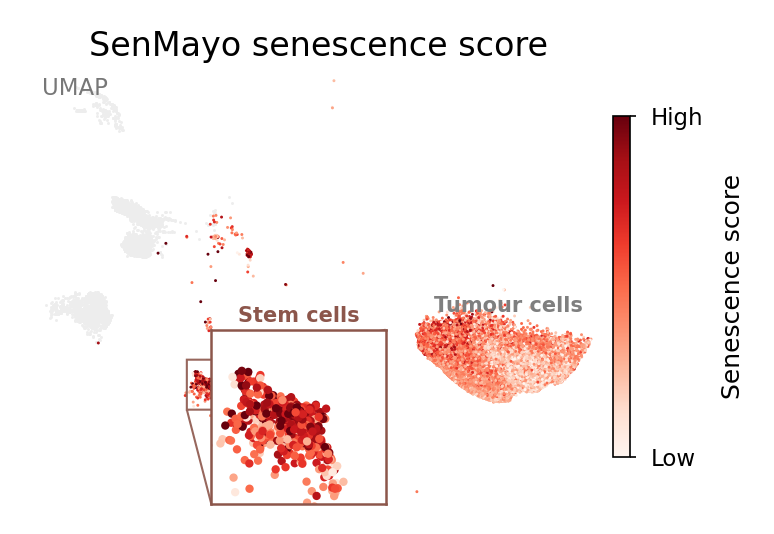

In [50]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree

# Figure 2A: SenMayo score on the UMAP, styled to match panel C
# (Reds, other cell types grey, no frame, stem cell inset). Run after SenMayo_score exists.

# ---- 1. Configuration --------------------------------------------------------
score_col   = "SenMayo_score"
label_col   = "final_cell_type_broad"
focus_types = ["Tumour cells", "Stem cells"]
stem_label  = "Stem cells"
cmap        = "Reds"                  # same family as panel C
pt_size     = 0.5                     # same as panel C main panels
inset       = True
inset_pos   = [0.31, 0.0, 0.31, 0.40] # same as panel C
fig_w       = 2.6                     # inches; set to match one panel of C (7.1 / 3 ≈ 2.4)

# ---- 2. Data -----------------------------------------------------------------
xy = adata.obsm["X_umap"]
labels = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
v = adata.obs[score_col].to_numpy(dtype=float)
focus = np.isin(labels, focus_types)
vmin, vmax = np.percentile(v[focus], [2, 99.8])     # robust range, as before

pad = 0.03
xr, yr = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
xlim = (xy[:, 0].min() - pad * xr, xy[:, 0].max() + pad * xr)
ylim = (xy[:, 1].min() - pad * yr, xy[:, 1].max() + pad * yr)

# stem cluster core (same method as panel C)
stem_xy = xy[labels == stem_label]
r = 0.03 * max(xr, yr)
dens = np.array([len(n) for n in cKDTree(stem_xy).query_ball_point(stem_xy, r)])
seed = stem_xy[dens.argmax()]
near = np.linalg.norm(stem_xy - seed, axis=1) < 4 * r
core = stem_xy[near & (dens >= np.percentile(dens, 25))]
c = np.median(core, axis=0)
d = np.abs(core - c)
half = max(2 * np.percentile(d[:, 0], 98) * 1.3 + r, 2 * np.percentile(d[:, 1], 98) * 1.3 + r) / 2 * 1.15


# "Tumour cells" label above the main tumour cluster
t_xy = xy[labels == "Tumour cells"]
t_med = np.median(t_xy, axis=0)
t_core = t_xy[np.linalg.norm(t_xy - t_med, axis=1) < np.percentile(np.linalg.norm(t_xy - t_med, axis=1), 90)]
t_lab_xy = (np.median(t_core[:, 0]), np.percentile(t_core[:, 1], 99.5) + 0.03 * yr)

def draw(a, s):
    a.scatter(xy[~focus, 0], xy[~focus, 1], s=s, color="#EDEDED", linewidths=0, rasterized=True)
    idx = np.random.default_rng(0).permutation(np.where(focus)[0])   # random order: true density
    return a.scatter(xy[idx, 0], xy[idx, 1], c=v[idx], s=s, cmap=cmap, vmin=vmin, vmax=vmax,
                     linewidths=0, rasterized=True)

# ---- 3. Plot -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(fig_w, fig_w * yr / xr + 0.5), dpi=300)
im = draw(ax, pt_size)
ax.set_title("SenMayo senescence score", fontsize=8, pad=3)
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_visible(False)
ax.text(*t_lab_xy, "Tumour cells", ha="center", va="bottom", fontsize=5,
            color="#7f7f7f", fontweight="bold")
ax.text(0.02, 0.98, "UMAP", transform=ax.transAxes, va="top", fontsize=5.5, color="#777777")

if inset:
    ins = ax.inset_axes(inset_pos)
    draw(ins, pt_size * 8)
    ins.set_xlim(c[0] - half, c[0] + half); ins.set_ylim(c[1] - half, c[1] + half)
    ins.set_aspect("equal"); ins.set_xticks([]); ins.set_yticks([])
    for sp in ins.spines.values():
        sp.set_edgecolor("#8c564b"); sp.set_linewidth(0.6)
    ins.text(0.5, 1.02, "Stem cells", transform=ins.transAxes, va="bottom", ha="center",
             fontsize=5, color="#8c564b", fontweight="bold")
    ax.indicate_inset_zoom(ins, edgecolor="#8c564b", lw=0.5, alpha=0.9)

cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01, shrink=0.6, ticks=[vmin, vmax])
cb.ax.set_yticklabels(["Low", "High"], fontsize=5.5)
cb.ax.tick_params(length=1.5, width=0.4)
cb.outline.set_linewidth(0.4)
cb.set_label("Senescence score", fontsize=6)

fig.savefig("Fig2A_SenMayo_UMAP.pdf", bbox_inches="tight")
fig.savefig("Fig2A_SenMayo_UMAP.svg", bbox_inches="tight")
fig.savefig("Fig2A_SenMayo_UMAP.png", dpi=600, bbox_inches="tight")
plt.show()

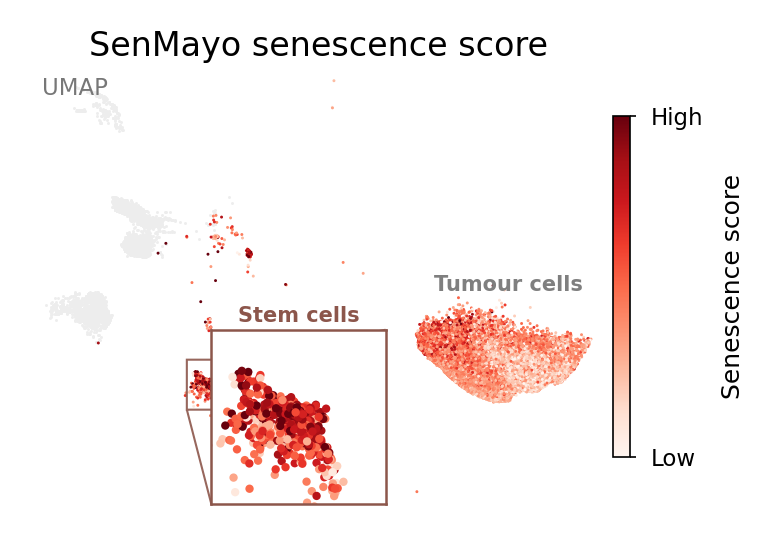

In [51]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree

# Figure 2A: SenMayo score on the UMAP, styled to match panel C
# (Reds, other cell types grey, no frame, stem cell inset). Run after SenMayo_score exists.

# ---- 1. Configuration --------------------------------------------------------
score_col   = "SenMayo_score"
label_col   = "final_cell_type_broad"
focus_types = ["Tumour cells", "Stem cells"]
stem_label  = "Stem cells"
cmap        = "Reds"                  # same family as panel C
pt_size     = 0.5                     # same as panel C main panels
inset       = True
inset_pos   = [0.31, 0.0, 0.31, 0.40] # same as panel C
fig_w       = 2.6                     # inches; set to match one panel of C (7.1 / 3 ≈ 2.4)

# ---- 2. Data -----------------------------------------------------------------
xy = adata.obsm["X_umap"]
labels = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
v = adata.obs[score_col].to_numpy(dtype=float)
focus = np.isin(labels, focus_types)
vmin, vmax = np.percentile(v[focus], [2, 99.8])     # robust range, as before

pad = 0.03
xr, yr = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
xlim = (xy[:, 0].min() - pad * xr, xy[:, 0].max() + pad * xr)
ylim = (xy[:, 1].min() - pad * yr, xy[:, 1].max() + pad * yr)

# stem cluster core (same method as panel C)
stem_xy = xy[labels == stem_label]
r = 0.03 * max(xr, yr)
dens = np.array([len(n) for n in cKDTree(stem_xy).query_ball_point(stem_xy, r)])
seed = stem_xy[dens.argmax()]
near = np.linalg.norm(stem_xy - seed, axis=1) < 4 * r
core = stem_xy[near & (dens >= np.percentile(dens, 25))]
c = np.median(core, axis=0)
d = np.abs(core - c)
half = max(2 * np.percentile(d[:, 0], 98) * 1.3 + r, 2 * np.percentile(d[:, 1], 98) * 1.3 + r) / 2 * 1.15

# "Tumour cells" label above the main tumour cluster
t_xy = xy[labels == "Tumour cells"]
t_med = np.median(t_xy, axis=0)
t_core = t_xy[np.linalg.norm(t_xy - t_med, axis=1) < np.percentile(np.linalg.norm(t_xy - t_med, axis=1), 90)]
t_lab_xy = (np.median(t_core[:, 0]), np.percentile(t_core[:, 1], 99.9) + 0.06 * yr)

def draw(a, s):
    a.scatter(xy[~focus, 0], xy[~focus, 1], s=s, color="#EDEDED", linewidths=0, rasterized=True)
    idx = np.random.default_rng(0).permutation(np.where(focus)[0])   # random order: true density
    return a.scatter(xy[idx, 0], xy[idx, 1], c=v[idx], s=s, cmap=cmap, vmin=vmin, vmax=vmax,
                     linewidths=0, rasterized=True)

# ---- 3. Plot -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(fig_w, fig_w * yr / xr + 0.5), dpi=300)
im = draw(ax, pt_size)
ax.set_title("SenMayo senescence score", fontsize=8, pad=3)
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_visible(False)
ax.text(*t_lab_xy, "Tumour cells", ha="center", va="bottom", fontsize=5,
        color="#7f7f7f", fontweight="bold")
ax.text(0.02, 0.98, "UMAP", transform=ax.transAxes, va="top", fontsize=5.5, color="#777777")

if inset:
    ins = ax.inset_axes(inset_pos)
    draw(ins, pt_size * 8)
    ins.set_xlim(c[0] - half, c[0] + half); ins.set_ylim(c[1] - half, c[1] + half)
    ins.set_aspect("equal"); ins.set_xticks([]); ins.set_yticks([])
    for sp in ins.spines.values():
        sp.set_edgecolor("#8c564b"); sp.set_linewidth(0.6)
    ins.text(0.5, 1.02, "Stem cells", transform=ins.transAxes, va="bottom", ha="center",
             fontsize=5, color="#8c564b", fontweight="bold")
    ax.indicate_inset_zoom(ins, edgecolor="#8c564b", lw=0.5, alpha=0.9)

cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01, shrink=0.6, ticks=[vmin, vmax])
cb.ax.set_yticklabels(["Low", "High"], fontsize=5.5)
cb.ax.tick_params(length=1.5, width=0.4)
cb.outline.set_linewidth(0.4)
cb.set_label("Senescence score", fontsize=6)

fig.savefig("Fig2A_SenMayo_UMAP.pdf", bbox_inches="tight")
fig.savefig("Fig2A_SenMayo_UMAP.svg", bbox_inches="tight")
fig.savefig("Fig2A_SenMayo_UMAP.png", dpi=600, bbox_inches="tight")
plt.show()

Stem outline covers 940/1253 stem-labelled cells
CDKN1A: expressed in 4.1% tumour cells, 24.7% stem cells
CDKN1B: expressed in 23.9% tumour cells, 23.3% stem cells
GLB1: expressed in 22.1% tumour cells, 23.9% stem cells


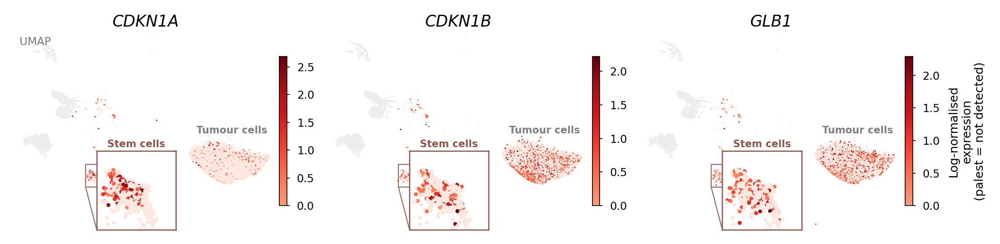

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.spatial import cKDTree
from matplotlib.patches import Ellipse

# ---- 1. Configuration --------------------------------------------------------
genes          = ["CDKN1A", "CDKN1B", "GLB1"]
label_col      = "final_cell_type_broad"
use_raw        = adata.raw is not None
highlight_stem = True          # dashed outline around the stem cell cluster
stem_label     = "Stem cells"
cmap           = "Reds"
pt_size        = 0.5           # small dots stop 94k tumour cells overplotting into solid red
draw_order     = "random"      # "random": honest density; "sorted": expressing cells on top
fig_w          = 7.1           # inches (180 mm, full page width)
focus_types    = ["Tumour cells", "Stem cells"]   # coloured; all other cells light grey (as in 2A)
pos_scale      = 1.0           # >1 makes positives bigger (more pop, but exaggerates frequency)
inset          = True          # zoomed view of the stem cluster in each panel
inset_pos      = [0.31, 0.0, 0.31, 0.40]          # axes fraction [x, y, w, h]; move into empty space

# ---- 2. Data -----------------------------------------------------------------
genes = [g for g in genes if g in (adata.raw.var_names if use_raw else adata.var_names)]
expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
xy = adata.obsm["X_umap"]
labels = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()

# same crop for every panel
pad = 0.03
xr, yr = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
xlim = (xy[:, 0].min() - pad * xr, xy[:, 0].max() + pad * xr)
ylim = (xy[:, 1].min() - pad * yr, xy[:, 1].max() + pad * yr)

# stem cluster outline: ellipse around the DENSE core of stem cells only
# (stem-labelled cells scattered elsewhere on the UMAP are ignored)
stem_xy = xy[labels == stem_label]
if highlight_stem and len(stem_xy) > 10:
    r = 0.03 * max(xr, yr)
    dens = np.array([len(n) for n in cKDTree(stem_xy).query_ball_point(stem_xy, r)])
    seed = stem_xy[dens.argmax()]                      # densest point = cluster centre
    core = stem_xy[np.linalg.norm(stem_xy - seed, axis=1) < 4 * r]
    core = core[dens[np.linalg.norm(stem_xy - seed, axis=1) < 4 * r] >= np.percentile(dens, 25)]
    c = np.median(core, axis=0)
    d = np.abs(core - c)
    w, h = 2 * np.percentile(d[:, 0], 98) * 1.3 + r, 2 * np.percentile(d[:, 1], 98) * 1.3 + r
    print(f"Stem outline covers {len(core)}/{len(stem_xy)} stem-labelled cells")

# "Tumour cells" label above the main tumour cluster
t_xy = xy[labels == "Tumour cells"]
t_med = np.median(t_xy, axis=0)
t_core = t_xy[np.linalg.norm(t_xy - t_med, axis=1) < np.percentile(np.linalg.norm(t_xy - t_med, axis=1), 90)]
t_lab_xy = (np.median(t_core[:, 0]), np.percentile(t_core[:, 1], 99.9) + 0.06 * yr)

# ---- 3. Plot -----------------------------------------------------------------
focus = np.isin(labels, focus_types)
panel_h = fig_w / len(genes) * (yr / xr) * 0.92
fig, axes = plt.subplots(1, len(genes), figsize=(fig_w, panel_h + 0.4), dpi=300)
axes = np.atleast_1d(axes)

# Colour map: 0 (not detected) = very pale pink, any detected expression jumps to a
# clearly visible red and darkens with level. Tumour/stem cells are therefore ALL
# coloured (none look excluded); only other cell types are grey.
from matplotlib.colors import LinearSegmentedColormap
reds = plt.get_cmap(cmap)(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])

def draw(a, v, vmax, s):
    # 1) other cell types: light grey
    a.scatter(xy[~focus, 0], xy[~focus, 1], s=s, color="#EDEDED", linewidths=0, rasterized=True)
    # 2) tumour/stem cells: non-expressing first (pale pink), expressing on top (reds)
    neg = np.where(focus & (v <= 0))[0]
    pos = np.where(focus & (v > 0))[0]
    pos = pos[np.argsort(v[pos])] if draw_order == "sorted" else np.random.default_rng(0).permutation(pos)
    if draw_order == "sorted":
        idx = np.r_[neg, pos]                    # positives on top (pops, but overstates frequency)
    else:
        idx = np.random.default_rng(0).permutation(np.r_[neg, pos])   # true density
    return a.scatter(xy[idx, 0], xy[idx, 1], c=v[idx], s=s, cmap=pop_cmap,
                     vmin=0, vmax=vmax, linewidths=0, rasterized=True)

for ax, g in zip(axes, genes):
    v = expr[g].to_numpy(dtype=float)
    vf = v[focus]
    vmax = np.percentile(vf[vf > 0], 99) if (vf > 0).any() else 1
    im = draw(ax, v, vmax, pt_size)
    ax.set_title(g, fontsize=8, fontstyle="italic", pad=3)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.text(*t_lab_xy, "Tumour cells", ha="center", va="bottom", fontsize=5,
            color="#7f7f7f", fontweight="bold")
    for sp in ax.spines.values():
        sp.set_visible(False)

    if highlight_stem and len(stem_xy) > 10:
        if inset:
            ins = ax.inset_axes(inset_pos)
            draw(ins, v, vmax, pt_size * 8)
            half = max(w, h) / 2 * 1.15
            ins.set_xlim(c[0] - half, c[0] + half); ins.set_ylim(c[1] - half, c[1] + half)
            ins.set_aspect("equal"); ins.set_xticks([]); ins.set_yticks([])
            for sp in ins.spines.values():
                sp.set_edgecolor("#8c564b"); sp.set_linewidth(0.6)
            ins.text(0.5, 1.02, "Stem cells", transform=ins.transAxes, va="bottom", ha="center",
                     fontsize=5, color="#8c564b", fontweight="bold")
            ax.indicate_inset_zoom(ins, edgecolor="#8c564b", lw=0.5, alpha=0.9)
        else:
            ax.add_patch(Ellipse(c, w, h, fill=False, ls="--", lw=0.7, ec="#8c564b"))

    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01, shrink=0.6)
    cb.ax.tick_params(labelsize=5.5, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    pct = {ct: (v[labels == ct] > 0).mean() * 100 for ct in ("Tumour cells", stem_label)}
    print(f"{g}: expressed in {pct['Tumour cells']:.1f}% tumour cells, "
          f"{pct[stem_label]:.1f}% stem cells")

cb.set_label("Log-normalised\nexpression\n(palest = not detected)", fontsize=6)
axes[0].text(0.02, 0.98, "UMAP", transform=axes[0].transAxes, va="top", fontsize=5.5, color="#777777")
fig.tight_layout(w_pad=0.6)

fig.savefig("Fig2C_senescence_UMAPs.pdf", bbox_inches="tight")
fig.savefig("Fig2C_senescence_UMAPs.svg", bbox_inches="tight")
fig.savefig("Fig2C_senescence_UMAPs.png", dpi=600, bbox_inches="tight")
plt.show()

Tumours included (>= 20 stem cells): 8

Gene      tumour median %  stem median %  stem>tumour  paired Wilcoxon P
CDKN1A                6.2           30.8       8/8           0.00781
CDKN1B               24.4           18.2       1/8            0.0234
GLB1                 21.8           20.2       3/8             0.383


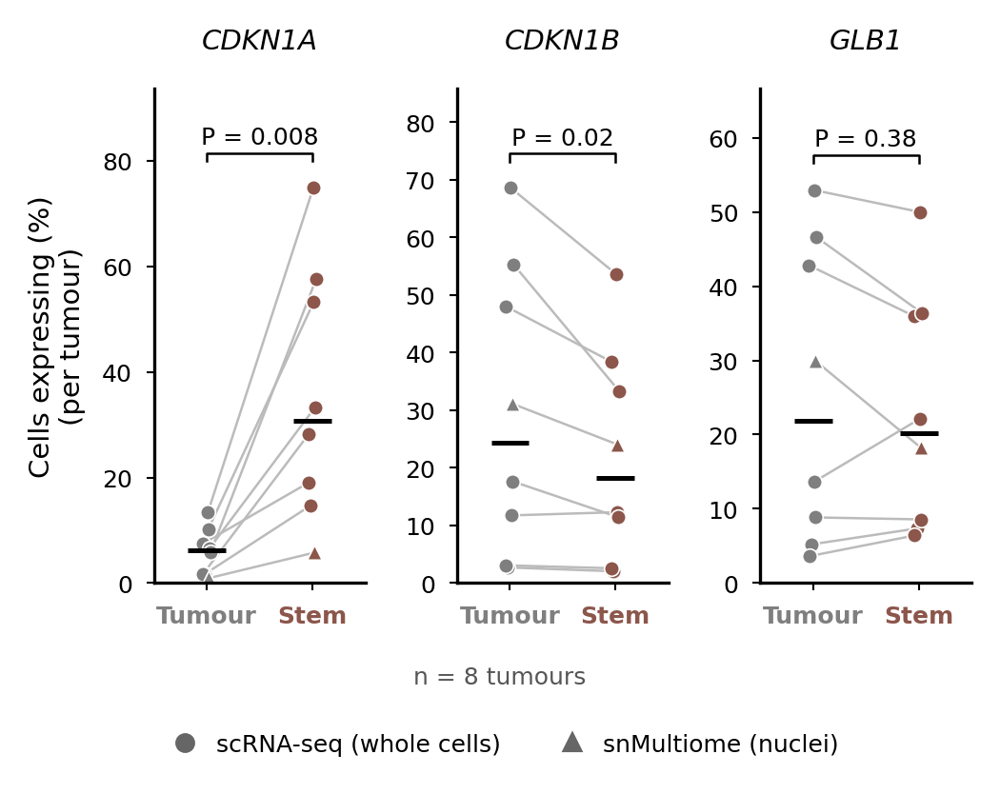

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon

# Figure 2D: % of stem vs tumour cells expressing each gene, one paired point per tumour.
# Same style, sample inclusion and statistics as panel B.

# ---- 1. Configuration --------------------------------------------------------
genes      = ["CDKN1A", "CDKN1B", "GLB1"]          # same genes as panel C
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
mod_col    = "modality_label"
min_stem   = 20                                    # same cut-off as panel B
groups     = ["Tumour cells", "Stem cells"]
colors     = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b"}
markers    = {"scRNA-seq (whole cells)": "o", "snMultiome (nuclei)": "^"}
xlabels    = ["Tumour", "Stem"]                    # short labels to save width
fig_size   = (3.6, 2.4)                            # inches; three mini panels in a row
use_raw    = adata.raw is not None

# ---- 2. % expressing per tumour and cell type -------------------------------
genes = [g for g in genes if g in (adata.raw.var_names if use_raw else adata.var_names)]
obs = adata.obs[[sample_col, label_col, mod_col]].copy()
obs[label_col] = obs[label_col].astype(str).replace({"Stem_cells": "Stem cells",
                                                     "Pituicytes": "Tumour cells"})
expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
expr.index = obs.index
keep_cells = obs[label_col].isin(groups).to_numpy()
obs, pos = obs[keep_cells], (expr[keep_cells] > 0)

n_cells = obs.groupby([sample_col, label_col], observed=True).size().unstack(fill_value=0)
keep = n_cells.index[n_cells.get("Stem cells", 0) >= min_stem]
print(f"Tumours included (>= {min_stem} stem cells): {len(keep)}")
mod = obs.groupby(sample_col, observed=True)[mod_col].first().astype(str)

pct = {}
for g in genes:
    t = (pos[g].groupby([obs[sample_col], obs[label_col]], observed=True).mean() * 100).unstack()
    pct[g] = t.loc[keep, groups].dropna()

# ---- 3. Plot -----------------------------------------------------------------
fig, axes = plt.subplots(1, len(genes), figsize=fig_size, dpi=300)
axes = np.atleast_1d(axes)
summary = []
for ax, g in zip(axes, genes):
    d = pct[g]
    stat = wilcoxon(d["Stem cells"], d["Tumour cells"])
    n_up = int((d["Stem cells"] > d["Tumour cells"]).sum())
    summary.append((g, d["Tumour cells"].median(), d["Stem cells"].median(), n_up, len(d), stat.pvalue))

    rng = np.random.default_rng(0)
    for s, row in d.iterrows():
        jit = rng.uniform(-0.04, 0.04)
        ax.plot([0 + jit, 1 + jit], row[groups].to_numpy(), color="#BBBBBB", lw=0.6, zorder=1)
        for i, grp in enumerate(groups):
            ax.scatter(i + jit, row[grp], s=14, color=colors[grp], marker=markers.get(mod[s], "o"),
                       edgecolors="white", linewidths=0.4, zorder=2)
    for i, grp in enumerate(groups):
        ax.hlines(d[grp].median(), i - 0.18, i + 0.18, color="black", lw=1.2, zorder=3)

    ax.set_title(g, fontsize=7, fontstyle="italic", pad=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(xlabels, fontsize=6.5)
    for lab, grp in zip(ax.get_xticklabels(), groups):
        lab.set_color(colors[grp]); lab.set_fontweight("bold")
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=6, length=2, width=0.5)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

    # P value bracket
    top = d.to_numpy().max()
    yb = top * 1.08 + 0.5
    ax.plot([0, 0, 1, 1], [yb - top * 0.02, yb, yb, yb - top * 0.02], color="black", lw=0.6)
    p = stat.pvalue
    ax.text(0.5, yb + top * 0.01, "P < 0.001" if p < 0.001 else f"P = {p:.3f}" if p < 0.01 else f"P = {p:.2f}",
            ha="center", va="bottom", fontsize=6)
    ax.set_ylim(top=yb + top * 0.15 + 1)

axes[0].set_ylabel("Cells expressing (%)\n(per tumour)", fontsize=7)
fig.text(0.5, -0.02, f"n = {len(keep)} tumours", ha="center", fontsize=6, color="#555555")
present = [m for m in markers if m in set(mod[keep])]
if len(present) > 1:
    fig.legend(handles=[Line2D([], [], marker=markers[m], ls="", color="#666666", markersize=4, label=m)
                        for m in present],
               loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False, fontsize=6,
               handletextpad=0.3)
fig.tight_layout(w_pad=1.0)

print("\nGene      tumour median %  stem median %  stem>tumour  paired Wilcoxon P")
for g, mt, ms, up, n, p in summary:
    print(f"{g:<9} {mt:>15.1f} {ms:>14.1f} {up:>7}/{n:<4} {p:>14.3g}")

fig.savefig("Fig2D_pct_expressing_paired.pdf", bbox_inches="tight")
fig.savefig("Fig2D_pct_expressing_paired.svg", bbox_inches="tight")
fig.savefig("Fig2D_pct_expressing_paired.png", dpi=600, bbox_inches="tight")
plt.show()

Stem outline covers 940/1253 stem-labelled cells
CDKN1A: expressed in 4.1% tumour cells, 24.7% stem cells
CDKN2A: expressed in 3.6% tumour cells, 25.1% stem cells
GLB1: expressed in 22.1% tumour cells, 23.9% stem cells


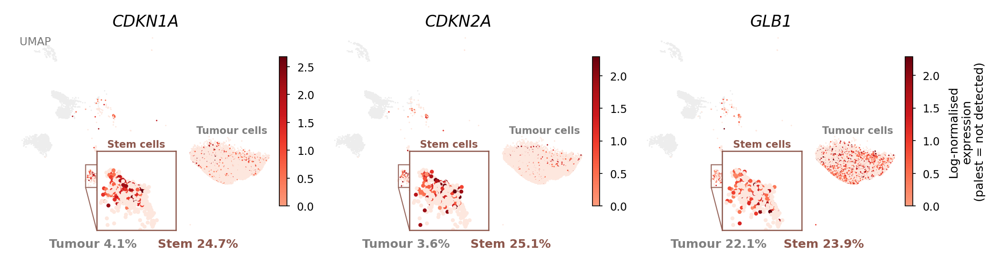

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.spatial import cKDTree
from matplotlib.patches import Ellipse

# ---- 1. Configuration --------------------------------------------------------
genes          = ["CDKN1A", "CDKN2A", "GLB1"]
label_col      = "final_cell_type_broad"
use_raw        = adata.raw is not None
highlight_stem = True          # dashed outline around the stem cell cluster
stem_label     = "Stem cells"
cmap           = "Reds"
pt_size        = 0.5           # small dots stop 94k tumour cells overplotting into solid red
draw_order     = "random"      # "random": honest density; "sorted": expressing cells on top
fig_w          = 7.1           # inches (180 mm, full page width)
focus_types    = ["Tumour cells", "Stem cells"]   # coloured; all other cells light grey (as in 2A)
pos_scale      = 1.0           # >1 makes positives bigger (more pop, but exaggerates frequency)
inset          = True          # zoomed view of the stem cluster in each panel
inset_pos      = [0.31, 0.0, 0.31, 0.40]          # axes fraction [x, y, w, h]; move into empty space

# ---- 2. Data -----------------------------------------------------------------
genes = [g for g in genes if g in (adata.raw.var_names if use_raw else adata.var_names)]
expr = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
xy = adata.obsm["X_umap"]
labels = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()

# same crop for every panel
pad = 0.03
xr, yr = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
xlim = (xy[:, 0].min() - pad * xr, xy[:, 0].max() + pad * xr)
ylim = (xy[:, 1].min() - pad * yr, xy[:, 1].max() + pad * yr)

# stem cluster outline: ellipse around the DENSE core of stem cells only
# (stem-labelled cells scattered elsewhere on the UMAP are ignored)
stem_xy = xy[labels == stem_label]
if highlight_stem and len(stem_xy) > 10:
    r = 0.03 * max(xr, yr)
    dens = np.array([len(n) for n in cKDTree(stem_xy).query_ball_point(stem_xy, r)])
    seed = stem_xy[dens.argmax()]                      # densest point = cluster centre
    core = stem_xy[np.linalg.norm(stem_xy - seed, axis=1) < 4 * r]
    core = core[dens[np.linalg.norm(stem_xy - seed, axis=1) < 4 * r] >= np.percentile(dens, 25)]
    c = np.median(core, axis=0)
    d = np.abs(core - c)
    w, h = 2 * np.percentile(d[:, 0], 98) * 1.3 + r, 2 * np.percentile(d[:, 1], 98) * 1.3 + r
    print(f"Stem outline covers {len(core)}/{len(stem_xy)} stem-labelled cells")

# "Tumour cells" label above the main tumour cluster
t_xy = xy[labels == "Tumour cells"]
t_med = np.median(t_xy, axis=0)
t_core = t_xy[np.linalg.norm(t_xy - t_med, axis=1) < np.percentile(np.linalg.norm(t_xy - t_med, axis=1), 90)]
t_lab_xy = (np.median(t_core[:, 0]), np.percentile(t_core[:, 1], 99.9) + 0.06 * yr)

# ---- 3. Plot -----------------------------------------------------------------
focus = np.isin(labels, focus_types)
panel_h = fig_w / len(genes) * (yr / xr) * 0.92
fig, axes = plt.subplots(1, len(genes), figsize=(fig_w, panel_h + 0.4), dpi=300)
axes = np.atleast_1d(axes)

# Colour map: 0 (not detected) = very pale pink, any detected expression jumps to a
# clearly visible red and darkens with level. Tumour/stem cells are therefore ALL
# coloured (none look excluded); only other cell types are grey.
from matplotlib.colors import LinearSegmentedColormap
reds = plt.get_cmap(cmap)(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])

def draw(a, v, vmax, s):
    # 1) other cell types: light grey
    a.scatter(xy[~focus, 0], xy[~focus, 1], s=s, color="#EDEDED", linewidths=0, rasterized=True)
    # 2) tumour/stem cells: non-expressing first (pale pink), expressing on top (reds)
    neg = np.where(focus & (v <= 0))[0]
    pos = np.where(focus & (v > 0))[0]
    pos = pos[np.argsort(v[pos])] if draw_order == "sorted" else np.random.default_rng(0).permutation(pos)
    if draw_order == "sorted":
        idx = np.r_[neg, pos]                    # positives on top (pops, but overstates frequency)
    else:
        idx = np.random.default_rng(0).permutation(np.r_[neg, pos])   # true density
    return a.scatter(xy[idx, 0], xy[idx, 1], c=v[idx], s=s, cmap=pop_cmap,
                     vmin=0, vmax=vmax, linewidths=0, rasterized=True)

for ax, g in zip(axes, genes):
    v = expr[g].to_numpy(dtype=float)
    vf = v[focus]
    vmax = np.percentile(vf[vf > 0], 99) if (vf > 0).any() else 1
    im = draw(ax, v, vmax, pt_size)
    ax.set_title(g, fontsize=8, fontstyle="italic", pad=3)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.text(*t_lab_xy, "Tumour cells", ha="center", va="bottom", fontsize=5,
            color="#7f7f7f", fontweight="bold")
    for sp in ax.spines.values():
        sp.set_visible(False)

    if highlight_stem and len(stem_xy) > 10:
        if inset:
            ins = ax.inset_axes(inset_pos)
            draw(ins, v, vmax, pt_size * 8)
            half = max(w, h) / 2 * 1.15
            ins.set_xlim(c[0] - half, c[0] + half); ins.set_ylim(c[1] - half, c[1] + half)
            ins.set_aspect("equal"); ins.set_xticks([]); ins.set_yticks([])
            for sp in ins.spines.values():
                sp.set_edgecolor("#8c564b"); sp.set_linewidth(0.6)
            ins.text(0.5, 1.02, "Stem cells", transform=ins.transAxes, va="bottom", ha="center",
                     fontsize=5, color="#8c564b", fontweight="bold")
            ax.indicate_inset_zoom(ins, edgecolor="#8c564b", lw=0.5, alpha=0.9)
        else:
            ax.add_patch(Ellipse(c, w, h, fill=False, ls="--", lw=0.7, ec="#8c564b"))

    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01, shrink=0.6)
    cb.ax.tick_params(labelsize=5.5, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    pct = {ct: (v[labels == ct] > 0).mean() * 100 for ct in ("Tumour cells", stem_label)}
    print(f"{g}: expressed in {pct['Tumour cells']:.1f}% tumour cells, "
          f"{pct[stem_label]:.1f}% stem cells")
    # % expressing shown under each UMAP (all cells of that type in the atlas)
    ax.text(0.30, -0.04, f"Tumour {pct['Tumour cells']:.1f}%", transform=ax.transAxes,
            ha="center", va="top", fontsize=6, color="#7f7f7f", fontweight="bold")
    ax.text(0.70, -0.04, f"Stem {pct[stem_label]:.1f}%", transform=ax.transAxes,
            ha="center", va="top", fontsize=6, color="#8c564b", fontweight="bold")

cb.set_label("Log-normalised\nexpression\n(palest = not detected)", fontsize=6)
axes[0].text(0.02, 0.98, "UMAP", transform=axes[0].transAxes, va="top", fontsize=5.5, color="#777777")
fig.tight_layout(w_pad=0.6)

fig.savefig("Fig2C_senescence_UMAPs.pdf", bbox_inches="tight")
fig.savefig("Fig2C_senescence_UMAPs.svg", bbox_inches="tight")
fig.savefig("Fig2C_senescence_UMAPs.png", dpi=600, bbox_inches="tight")
plt.show()

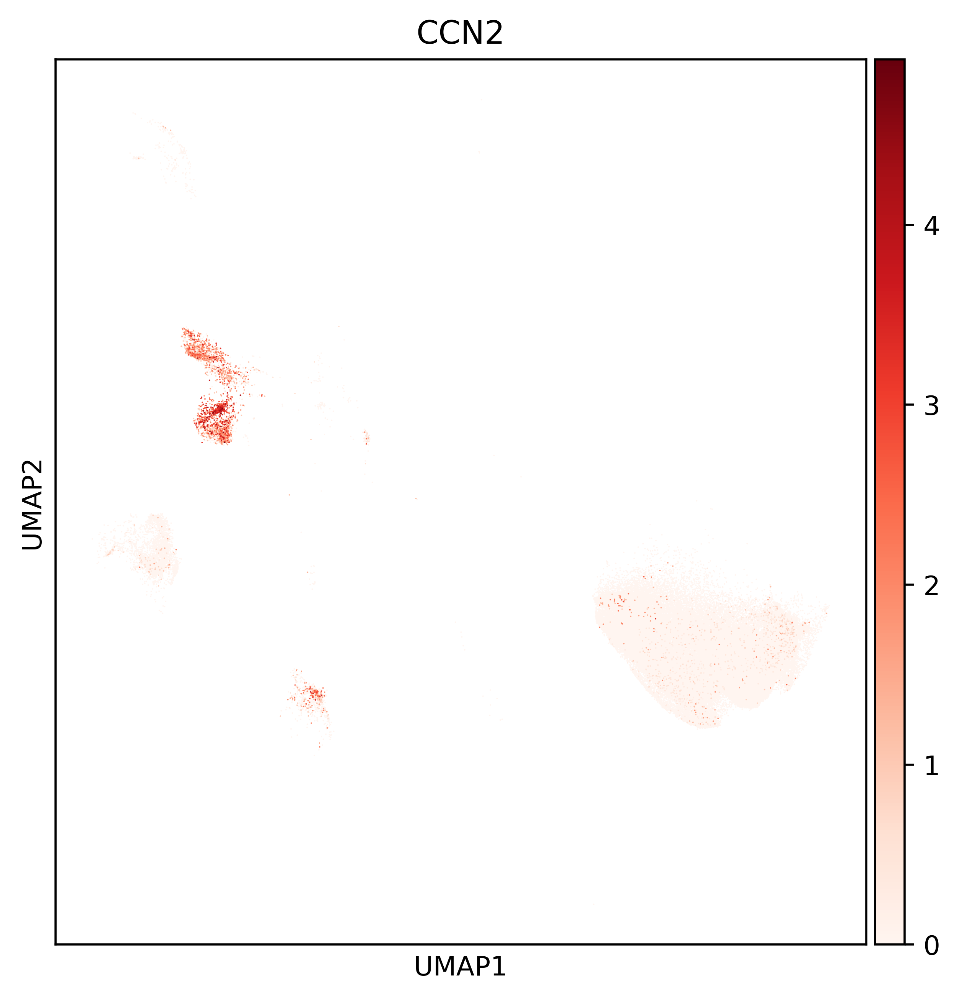

In [56]:
import matplotlib.pyplot as plt
import scanpy as sc

# Set figure parameters
plt.rcParams["figure.figsize"] = (6, 6)
plt.rcParams["figure.dpi"] = 500

# show=False keeps the figure open for Matplotlib to save
sc.pl.umap(adata, color=['CCN2'], use_raw=False, cmap='Reds', show=False)

# Save high-res plot with tight boundaries to prevent cut-off legends
plt.savefig("umap_nr5a1_highres.png", dpi=600, bbox_inches="tight")

# Display the plot in your notebook/screen afterwards
plt.show()

In [57]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

sasp = [
    # interleukins / chemokines
    "IL6", "CXCL8", "IL1A", "IL1B", "IL15", "CXCL1", "CXCL2", "CXCL10", "CXCL12",
    "CCL2", "CCL5", "CCL20", "CSF2", "MIF",
    # growth factors / regulators
    "CCN2", "CTGF", "CCN1", "CYR61", "TGFB1", "VEGFA", "PGF", "FGF2", "HGF", "AREG",
    "EREG", "GDF15", "BMP2", "STC1", "ANGPTL4",
    # IGF-binding proteins
    "IGFBP2", "IGFBP3", "IGFBP4", "IGFBP5", "IGFBP7",
    # proteases / inhibitors / matrix
    "SERPINE1", "SERPINE2", "PLAU", "PLAUR", "MMP1", "MMP2", "MMP3", "MMP9",
    "TIMP1", "TIMP2", "FN1", "SPP1", "LGALS3", "ICAM1", "CST3",
]
sasp = [g for g in dict.fromkeys(sasp) if g in adata.var_names]

ct = adata.obs["final_cell_type_broad"].astype(str).values
sid = adata.obs["SRA_ID"].astype(str).values
X = sc.get.obs_df(adata, keys=sasp, use_raw=adata.raw is not None) > 0
X.index = range(len(X))

stem, tum = ct == "Stem cells", ct == "Tumour cells"
other = ~(stem | tum)
res = pd.DataFrame({
    "% stem":   X[stem].mean() * 100,
    "% tumour": X[tum].mean() * 100,
    "% other (stroma/immune)": X[other].mean() * 100,
})
res["stem - tumour"] = res["% stem"] - res["% tumour"]

# per-tumour paired check (tumours with >=20 stem cells, as in Fig. 2B)
keep = [s for s in pd.unique(sid) if (stem & (sid == s)).sum() >= 20]
for g in res.index:
    st = [X.loc[stem & (sid == s), g].mean() * 100 for s in keep]
    tu = [X.loc[tum & (sid == s), g].mean() * 100 for s in keep]
    res.loc[g, "stem>tumour (tumours)"] = f"{sum(a > b for a, b in zip(st, tu))}/{len(keep)}"
    res.loc[g, "paired P"] = wilcoxon(st, tu).pvalue if any(a != b for a, b in zip(st, tu)) else np.nan

res = res.sort_values("stem - tumour", ascending=False).round(2)
pd.set_option("display.width", 200)
print(res.to_string())
print("\nCandidates (stem >= 10%, stem >= 3x tumour):")
print(res[(res["% stem"] >= 10) & (res["% stem"] >= 3 * res["% tumour"].clip(lower=0.1))].index.tolist())

          % stem  % tumour  % other (stroma/immune)  stem - tumour stem>tumour (tumours)  paired P
IGFBP3     62.49      0.75                    10.24          61.74                   8/8      0.01
IGFBP7     79.89     20.47                    59.84          59.42                   8/8      0.01
LGALS3     59.62      0.88                    50.35          58.74                   8/8      0.01
CST3       92.66     48.73                    87.41          43.93                   6/8      0.15
IGFBP5     88.03     44.26                    34.38          43.77                   7/8      0.02
CCN1       37.03      0.88                    30.91          36.15                   8/8      0.01
IGFBP2     34.88      1.03                    32.51          33.84                   8/8      0.01
TIMP1      81.32     55.53                    70.65          25.80                   6/8      0.15
CCN2       23.06      1.01                    31.33          22.06                   8/8      0.01
MIF       

Senescence  CDKN1A  tumour   4.1%   stem  24.7%
Senescence  CDKN2A  tumour   3.6%   stem  25.1%
Senescence  GLB1    tumour  22.1%   stem  23.9%
SASP        CCN2    tumour   1.0%   stem  23.1%
SASP        IGFBP3  tumour   0.8%   stem  62.5%
SASP        CCL2    tumour   0.6%   stem   8.4%


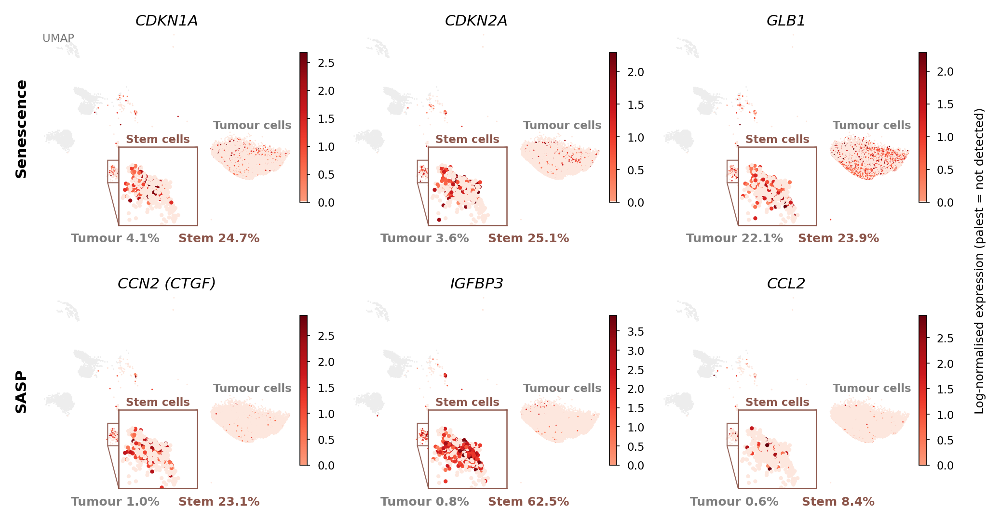

In [62]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator
from scipy.spatial import cKDTree

# Figure 2C + 2D as one aligned 2 x 3 grid.
# Row 1 (C): senescence genes; Row 2 (D): SASP factors. Same style as before.

# ---- 1. Configuration --------------------------------------------------------
rows = [("Senescence", ["CDKN1A", "CDKN2A", "GLB1"]),      # panel C
        ("SASP",       ["CCN2", "IGFBP3", "CCL2"])]         # panel D
aliases     = {"CCN2": "CTGF"}                              # older annotations use CTGF
display     = {"CCN2": "CCN2 (CTGF)", "CTGF": "CCN2 (CTGF)"}
label_col   = "final_cell_type_broad"
use_raw     = adata.raw is not None
focus_types = ["Tumour cells", "Stem cells"]
stem_label  = "Stem cells"
pt_size     = 0.5
inset_pos   = [0.31, 0.0, 0.31, 0.40]                       # axes fraction [x, y, w, h]
fig_w       = 7.1                                           # inches (180 mm)
fs          = {"title": 7.5, "label": 6, "small": 5.5, "row": 7.5}   # font sizes (pt)

# ---- 2. Data -----------------------------------------------------------------
vn = adata.raw.var_names if use_raw else adata.var_names
rows = [(name, [g if g in vn else aliases.get(g, g) for g in gl]) for name, gl in rows]
missing = [g for _, gl in rows for g in gl if g not in vn]
if missing:
    print("Not found:", missing)
all_genes = [g for _, gl in rows for g in gl if g in vn]
expr = sc.get.obs_df(adata, keys=all_genes, use_raw=use_raw)
xy = adata.obsm["X_umap"]
labels = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
focus = np.isin(labels, focus_types)

pad = 0.03
xr, yr = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
xlim = (xy[:, 0].min() - pad * xr, xy[:, 0].max() + pad * xr)
ylim = (xy[:, 1].min() - pad * yr, xy[:, 1].max() + pad * yr)

# stem cluster core (for the inset)
stem_xy = xy[labels == stem_label]
r = 0.03 * max(xr, yr)
dens = np.array([len(n) for n in cKDTree(stem_xy).query_ball_point(stem_xy, r)])
seed = stem_xy[dens.argmax()]
near = np.linalg.norm(stem_xy - seed, axis=1) < 4 * r
core = stem_xy[near & (dens >= np.percentile(dens, 25))]
c = np.median(core, axis=0)
d = np.abs(core - c)
half = max(2 * np.percentile(d[:, 0], 98) * 1.3 + r, 2 * np.percentile(d[:, 1], 98) * 1.3 + r) / 2 * 1.15

# "Tumour cells" label position
t_xy = xy[labels == "Tumour cells"]
t_med = np.median(t_xy, axis=0)
dist = np.linalg.norm(t_xy - t_med, axis=1)
t_core = t_xy[dist < np.percentile(dist, 90)]
t_lab_xy = (np.median(t_core[:, 0]), np.percentile(t_core[:, 1], 99.9) + 0.06 * yr)

# colour map: palest = not detected; any expression jumps to visible red
reds = plt.get_cmap("Reds")(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])
order = np.random.default_rng(0).permutation(np.where(focus)[0])   # random: true density

def draw(a, v, vmax, s):
    a.scatter(xy[~focus, 0], xy[~focus, 1], s=s, color="#EDEDED", linewidths=0, rasterized=True)
    return a.scatter(xy[order, 0], xy[order, 1], c=v[order], s=s, cmap=pop_cmap,
                     vmin=0, vmax=vmax, linewidths=0, rasterized=True)

# ---- 3. Plot -----------------------------------------------------------------
ncol = max(len(gl) for _, gl in rows)
panel_h = fig_w / ncol * (yr / xr) * 0.92
fig, axes = plt.subplots(len(rows), ncol, figsize=(fig_w, len(rows) * (panel_h + 0.3)), dpi=300,
                         squeeze=False)

for i, (row_name, gl) in enumerate(rows):
    for j in range(ncol):
        ax = axes[i, j]
        if j >= len(gl) or gl[j] not in vn:
            ax.axis("off"); continue
        g = gl[j]
        v = expr[g].to_numpy(dtype=float)
        vf = v[focus]
        vmax = np.percentile(vf[vf > 0], 99) if (vf > 0).any() else 1
        im = draw(ax, v, vmax, pt_size)
        ax.set_title(display.get(g, g), fontsize=fs["title"], fontstyle="italic", pad=2)
        ax.set_xlim(xlim); ax.set_ylim(ylim)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.text(*t_lab_xy, "Tumour cells", ha="center", va="bottom", fontsize=fs["small"],
                color="#7f7f7f", fontweight="bold")

        ins = ax.inset_axes(inset_pos)
        draw(ins, v, vmax, pt_size * 8)
        ins.set_xlim(c[0] - half, c[0] + half); ins.set_ylim(c[1] - half, c[1] + half)
        ins.set_aspect("equal"); ins.set_xticks([]); ins.set_yticks([])
        for sp in ins.spines.values():
            sp.set_edgecolor("#8c564b"); sp.set_linewidth(0.6)
        ins.text(0.5, 1.02, "Stem cells", transform=ins.transAxes, va="bottom", ha="center",
                 fontsize=fs["small"], color="#8c564b", fontweight="bold")
        ax.indicate_inset_zoom(ins, edgecolor="#8c564b", lw=0.5, alpha=0.9)

        cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.01, shrink=0.6)
        cb.ax.tick_params(labelsize=fs["small"], length=1.5, width=0.4)
        cb.outline.set_linewidth(0.4)
        cb.locator = MultipleLocator(0.5); cb.update_ticks()   # 0.5 steps in every panel

        pct = {ct: (v[labels == ct] > 0).mean() * 100 for ct in ("Tumour cells", stem_label)}
        print(f"{row_name:<11} {g:<7} tumour {pct['Tumour cells']:5.1f}%   stem {pct[stem_label]:5.1f}%")
        ax.text(0.30, -0.04, f"Tumour {pct['Tumour cells']:.1f}%", transform=ax.transAxes,
                ha="center", va="top", fontsize=fs["label"], color="#7f7f7f", fontweight="bold")
        ax.text(0.70, -0.04, f"Stem {pct[stem_label]:.1f}%", transform=ax.transAxes,
                ha="center", va="top", fontsize=fs["label"], color="#8c564b", fontweight="bold")

    # row label on the left
    axes[i, 0].text(-0.06, 0.5, row_name, transform=axes[i, 0].transAxes, rotation=90,
                    ha="center", va="center", fontsize=fs["row"], fontweight="bold")

# one shared colour bar label (last column, centred over both rows) and one UMAP tag
fig.text(0.975, 0.5, "Log-normalised expression (palest = not detected)", rotation=90,
         ha="right", va="center", fontsize=fs["label"])
axes[0, 0].text(0.02, 0.98, "UMAP", transform=axes[0, 0].transAxes, va="top",
                fontsize=fs["small"], color="#777777")
fig.tight_layout(w_pad=0.6, h_pad=0.4, rect=(0.01, 0, 0.965, 1))

fig.savefig("Fig2CD_grid.pdf", bbox_inches="tight")
fig.savefig("Fig2CD_grid.svg", bbox_inches="tight")
fig.savefig("Fig2CD_grid.png", dpi=600, bbox_inches="tight")
plt.show()

Stem cells per tumour (senescent split):
 sen          p21/p16−  p21/p16+
SRA_ID                         
HRS1408776          0         1
HRS488982          47        75
HRS488984           1         3
HRS488986           1         0
HRS488987           0         1
HRS488990         176        69
HRS488991          49        29
SRX14605703       321       205
SRX16175537        64        41
SRX21219339        12        21
SRX21219341         2         3
SRX21219343         5        23
SRX28461022        87        17

Tumours included (>= 10 cells in both groups): 7

Median UMIs per stem cell (p21/p16− vs +):
 sen          p21/p16−  p21/p16+
SRA_ID                         
HRS488982      3212.0    3701.0
HRS488990      1448.0    1701.0
HRS488991      1373.0    1558.0
SRX14605703    9075.0   16040.0
SRX16175537    3830.0    4356.0
SRX21219339    2234.0   24217.0
SRX28461022    3909.0    4146.0

Random control genes: median +/− difference = 1.0 percentage points (depth effect; SASP differ

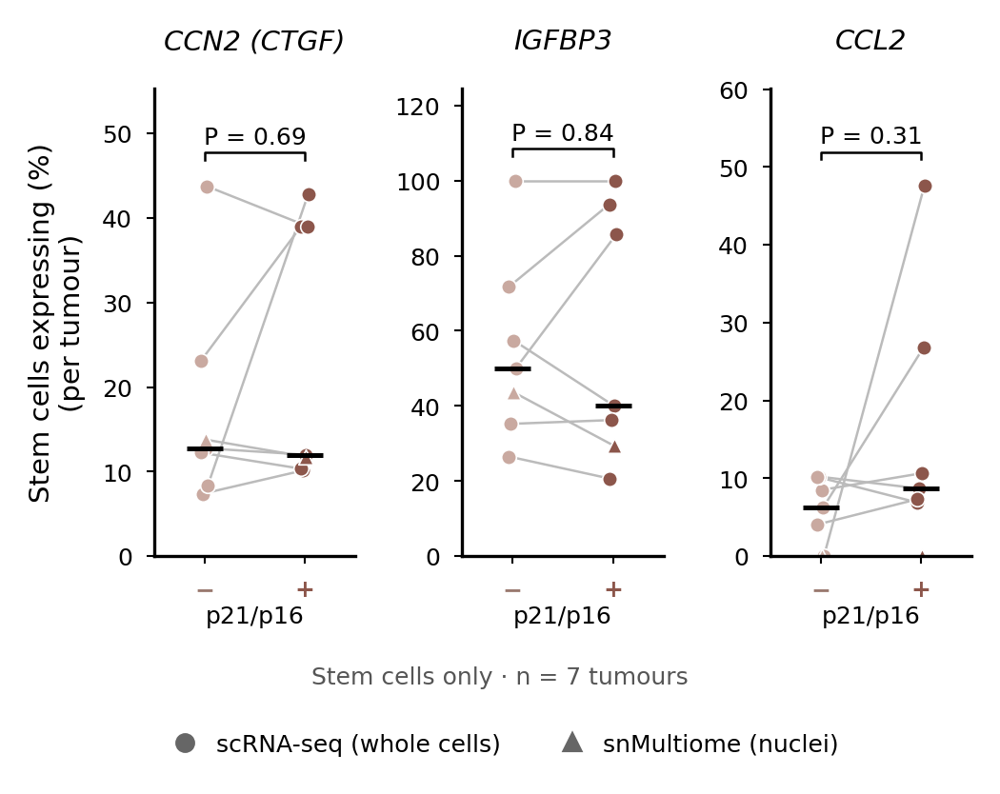

In [63]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon

# Figure 2E: within STEM cells, is SASP expression higher in senescent (p21+ and/or p16+)
# than in non-senescent stem cells? One paired point per tumour, same style as panel B.

# ---- 1. Configuration --------------------------------------------------------
sasp_genes = ["CCN2", "IGFBP3", "CCL2"]
sen_genes  = ["CDKN1A", "CDKN2A"]                 # senescent = either detected
aliases    = {"CCN2": "CTGF"}
display    = {"CCN2": "CCN2 (CTGF)", "CTGF": "CCN2 (CTGF)"}
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
mod_col    = "modality_label"
min_group  = 10                                   # need >= this many cells in BOTH stem groups
groups     = ["p21/p16−", "p21/p16+"]
colors     = {"p21/p16−": "#C9A9A0", "p21/p16+": "#8c564b"}
markers    = {"scRNA-seq (whole cells)": "o", "snMultiome (nuclei)": "^"}
fig_size   = (3.6, 2.4)
use_raw    = adata.raw is not None
n_ctrl     = 200                                  # random control genes (see step 3)

# ---- 2. Stem cells, senescence status ---------------------------------------
vn = adata.raw.var_names if use_raw else adata.var_names
sasp_genes = [g if g in vn else aliases.get(g, g) for g in sasp_genes]
sasp_genes = [g for g in sasp_genes if g in vn]
sen_genes = [g for g in sen_genes if g in vn]

ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"]
obs = stem.obs[[sample_col, mod_col]].astype(str).copy()
E = sc.get.obs_df(stem, keys=sasp_genes + sen_genes, use_raw=use_raw) > 0
E.index = obs.index
obs["sen"] = np.where(E[sen_genes].any(axis=1), groups[1], groups[0])

counts = obs.groupby([sample_col, "sen"]).size().unstack(fill_value=0).reindex(columns=groups, fill_value=0)
keep = counts.index[(counts[groups[0]] >= min_group) & (counts[groups[1]] >= min_group)]
print("Stem cells per tumour (senescent split):\n", counts.to_string())
print(f"\nTumours included (>= {min_group} cells in both groups): {len(keep)}")
mod = obs.groupby(sample_col)[mod_col].first()

pct = {g: (E[g].groupby([obs[sample_col], obs["sen"]]).mean() * 100).unstack().loc[keep, groups]
       for g in sasp_genes}

# ---- 3. Control for sequencing depth ----------------------------------------
# Cells with more reads detect more genes of every kind, so p21/p16+ cells could show
# more SASP detection simply because they are better sequenced. Compare with random genes
# detected in a similar fraction of stem cells: the SASP difference should exceed this.
if "total_counts" in stem.obs:
    tc = stem.obs["total_counts"].astype(float).groupby([obs[sample_col], obs["sen"]]).median().unstack()
    print("\nMedian UMIs per stem cell (p21/p16− vs +):\n", tc.loc[keep, groups].round(0).to_string())
rng = np.random.default_rng(0)
Xs = stem.raw.X if use_raw else stem.X
det = np.asarray((Xs > 0).mean(axis=0)).ravel()
pool = np.where((det > 0.05) & (det < 0.7))[0]
ctrl_idx = rng.choice(pool, size=min(n_ctrl, len(pool)), replace=False)
Xc = Xs[:, ctrl_idx]
Xc = (Xc.toarray() if hasattr(Xc, "toarray") else np.asarray(Xc)) > 0
ctrl_diff = []
for s in keep:
    m = (obs[sample_col] == s).to_numpy()
    pos, neg = m & (obs["sen"] == groups[1]).to_numpy(), m & (obs["sen"] == groups[0]).to_numpy()
    ctrl_diff.append((Xc[pos].mean(0) - Xc[neg].mean(0)).mean() * 100)
print(f"\nRandom control genes: median +/− difference = {np.median(ctrl_diff):.1f} percentage points "
      "(depth effect; SASP differences should be clearly larger)")

# ---- 4. Plot -----------------------------------------------------------------
fig, axes = plt.subplots(1, len(sasp_genes), figsize=fig_size, dpi=300)
axes = np.atleast_1d(axes)
print("\nGene            p21/p16− median %  p21/p16+ median %  +>−      P      median diff  vs control")
for ax, g in zip(axes, sasp_genes):
    d = pct[g]
    p = wilcoxon(d[groups[1]], d[groups[0]]).pvalue
    n_up = int((d[groups[1]] > d[groups[0]]).sum())
    diff = (d[groups[1]] - d[groups[0]]).median()
    print(f"{display.get(g, g):<15} {d[groups[0]].median():>17.1f} {d[groups[1]].median():>18.1f} "
          f"{n_up:>3}/{len(d):<3} {p:>8.3g} {diff:>10.1f} {diff - np.median(ctrl_diff):>10.1f}")

    jit_rng = np.random.default_rng(0)
    for s, row in d.iterrows():
        jit = jit_rng.uniform(-0.04, 0.04)
        ax.plot([0 + jit, 1 + jit], row[groups].to_numpy(), color="#BBBBBB", lw=0.6, zorder=1)
        for i, grp in enumerate(groups):
            ax.scatter(i + jit, row[grp], s=14, color=colors[grp], marker=markers.get(mod[s], "o"),
                       edgecolors="white", linewidths=0.4, zorder=2)
    for i, grp in enumerate(groups):
        ax.hlines(d[grp].median(), i - 0.18, i + 0.18, color="black", lw=1.2, zorder=3)

    ax.set_title(display.get(g, g), fontsize=7, fontstyle="italic", pad=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["−", "+"], fontsize=8)
    ax.set_xlabel("p21/p16", fontsize=6, labelpad=1)
    for lab, grp in zip(ax.get_xticklabels(), groups):
        lab.set_color(colors[grp] if grp == groups[1] else "#9a7a70"); lab.set_fontweight("bold")
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=6, length=2, width=0.5)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    top = d.to_numpy().max()
    yb = top * 1.08 + 0.5
    ax.plot([0, 0, 1, 1], [yb - top * 0.02, yb, yb, yb - top * 0.02], color="black", lw=0.6)
    ax.text(0.5, yb + top * 0.01,
            "P < 0.001" if p < 0.001 else f"P = {p:.3f}" if p < 0.01 else f"P = {p:.2f}",
            ha="center", va="bottom", fontsize=6)
    ax.set_ylim(top=yb + top * 0.15 + 1)

axes[0].set_ylabel("Stem cells expressing (%)\n(per tumour)", fontsize=7)
fig.text(0.5, -0.02, f"Stem cells only · n = {len(keep)} tumours", ha="center", fontsize=6, color="#555555")
present = [m for m in markers if m in set(mod[keep])]
if len(present) > 1:
    fig.legend(handles=[Line2D([], [], marker=markers[m], ls="", color="#666666", markersize=4, label=m)
                        for m in present],
               loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False, fontsize=6,
               handletextpad=0.3)
fig.tight_layout(w_pad=1.0)

fig.savefig("Fig2E_SASP_by_senescence.pdf", bbox_inches="tight")
fig.savefig("Fig2E_SASP_by_senescence.svg", bbox_inches="tight")
fig.savefig("Fig2E_SASP_by_senescence.png", dpi=600, bbox_inches="tight")
plt.show()

In [65]:
%pip install pydeseq2 gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.6/87.6 kB 9.6 MB/s eta 0:00:00


In [66]:
import numpy as np
import pandas as pd
import scanpy as sc

# Stem cells: CDKN1A-high vs CDKN1A-low differential expression.
# Main test = pseudobulk per tumour (paired design: tumour + group) with PyDESeq2,
# so each tumour counts once (avoids treating thousands of cells as independent).
# A cell-level scanpy test is included for comparison only.
#   pip install pydeseq2 gseapy

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
gene       = "CDKN1A"
split      = "detected"     # "detected": >0 vs 0   |  "quartile": top 25% vs bottom 50% (within tumour)
min_cells  = 10             # per group per tumour
counts_layer = "counts"     # raw counts for pseudobulk
sasp_check = ["CCN2", "CTGF", "IGFBP3", "IGFBP7", "IGFBP2", "IGFBP5", "CCN1", "CCL2",
              "LGALS3", "CXCL10", "CDKN2A", "GLB1", "SERPINE1", "TIMP1", "GDF15", "IL6"]

# ---- 2. Define groups within stem cells -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"})
stem = adata[ct == "Stem cells"].copy()
x = sc.get.obs_df(stem, keys=[gene], use_raw=stem.raw is not None)[gene].to_numpy()

grp = pd.Series("drop", index=stem.obs_names)
if split == "detected":
    grp[x > 0] = "high"
    grp[x == 0] = "low"
else:
    for s, idx in stem.obs.groupby(sample_col, observed=True).groups.items():
        v = pd.Series(x[stem.obs_names.get_indexer(idx)], index=idx)
        grp[idx[v >= v.quantile(0.75)]] = "high"
        grp[idx[v <= v.quantile(0.50)]] = "low"
stem.obs["CDKN1A_group"] = grp.values
stem = stem[stem.obs["CDKN1A_group"] != "drop"].copy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_cells) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_cells} cells in both groups: {len(keep)}")
stem = stem[stem.obs[sample_col].isin(keep)].copy()

# ---- 3. Pseudobulk: sum raw counts per tumour x group ------------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g, "n_cells": len(m)})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, len(keep) // 2)]   # drop very low genes
pb = pb.drop(columns=[gene], errors="ignore")    # the splitting gene itself is trivially DE

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
dds.deseq2()
st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
st.summary()
res = st.results_df.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")

print("\nTop genes up in CDKN1A-high stem cells (pseudobulk, paired by tumour):")
print(res[res["log2FoldChange"] > 0].head(25)[["baseMean", "log2FoldChange", "pvalue", "padj"]].round(4).to_string())
print("\nTop genes down:")
print(res[res["log2FoldChange"] < 0].head(15)[["baseMean", "log2FoldChange", "pvalue", "padj"]].round(4).to_string())
print("\nSenescence / SASP genes of interest:")
print(res.reindex([g for g in sasp_check if g in res.index])[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())
print(f"\nGenes with padj < 0.05: {(res['padj'] < 0.05).sum()} up {(res.query('padj < 0.05')['log2FoldChange'] > 0).sum()}")

# ---- 4. Pathways: preranked GSEA on the pseudobulk statistic -----------------
try:
    import gseapy as gp
    rnk = res["stat"].dropna().sort_values(ascending=False)
    pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                     min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
    gsea = pre.res2d.sort_values("NES", ascending=False)
    gsea.to_csv("Stem_CDKN1A_high_vs_low_GSEA_hallmark.csv", index=False)
    print("\nHallmark GSEA (positive NES = enriched in CDKN1A-high stem cells):")
    print(gsea[["Term", "NES", "FDR q-val"]].head(15).to_string(index=False))
    print(gsea[["Term", "NES", "FDR q-val"]].tail(8).to_string(index=False))
except Exception as e:
    print("\nGSEA skipped:", e)

# ---- 5. Cell-level test (for comparison only; inflated P values) ------------
sc.tl.rank_genes_groups(stem, "CDKN1A_group", groups=["high"], reference="low",
                        method="wilcoxon", use_raw=stem.raw is not None)
cell = sc.get.rank_genes_groups_df(stem, group="high")
cell.to_csv("Stem_CDKN1A_high_vs_low_cellwise.csv", index=False)
print("\nCell-level top 20 (pseudoreplicated - do not report these P values):")
print(cell.head(20)[["names", "logfoldchanges", "pvals_adj"]].to_string(index=False))

CDKN1A_group  high  low
SRA_ID                 
HRS488982       65   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
HRS1408776       1    0
SRX14605703    100  426
SRX16175537     35   70
SRX21219339     19   14
SRX21219341      3    2
SRX21219343     21    7
SRX28461022      6   98 

Tumours with >= 10 cells in both groups: 6

Top genes up in CDKN1A-high stem cells (pseudobulk, paired by tumour):
           baseMean  log2FoldChange  pvalue    padj
SLPI      2533.9879          0.3114  0.0000  0.0037
EGOT         8.6808          1.6513  0.0001  0.3231
SAA2       152.7131          0.7937  0.0002  0.4105
EGR1       242.1077          0.3944  0.0004  0.6987
CHST9       10.9731          1.0138  0.0016  0.9999
DPYSL3      15.3499          0.8246  0.0017  0.9999
TACSTD2     59.6640          0.6542  0.0031  0.9999
UNC13A       5.0647          1.4841  0.0051  0.9999
UBE2H       65.2061          0.4605  0.0059  0.9999
MAP

In [67]:
import gseapy as gp
from scipy.stats import wilcoxon

# Core dissociation-induced genes (van den Brink et al. 2017)
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]
diss = [g for g in diss if g in stem.var_names]

# 1. Is dissociation stress higher in CDKN1A-high stem cells? (per tumour)
sc.tl.score_genes(stem, diss, score_name="diss_score", use_raw=stem.raw is not None)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print(d.round(3).to_string())
print("Dissociation score high > low in", (d["high"] > d["low"]).sum(), "/", len(d),
      "tumours; paired Wilcoxon P =", round(wilcoxon(d["high"], d["low"]).pvalue, 3))

# 2. Re-run GSEA with dissociation genes removed from the ranking
rnk2 = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre2 = gp.prerank(rnk=rnk2, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                  min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g2 = pre2.res2d.set_index("Term")
print("\nAfter removing dissociation genes:")
print(g2.loc[["TNF-alpha Signaling via NF-kB", "p53 Pathway", "Inflammatory Response", "Apoptosis"],
             ["NES", "FDR q-val"]].to_string())

CDKN1A_group   high    low
SRA_ID                    
HRS488982     0.980  1.033
HRS488990     1.004  0.941
HRS488991     0.887  0.835
SRX14605703   0.470  0.308
SRX16175537   1.158  1.069
SRX21219339   1.097  0.304
Dissociation score high > low in 5 / 6 tumours; paired Wilcoxon P = 0.094

After removing dissociation genes:
                                    NES  FDR q-val
Term                                              
TNF-alpha Signaling via NF-kB  2.207291   0.000000
p53 Pathway                    1.966661   0.003419
Inflammatory Response          0.889650   1.000000
Apoptosis                      1.461356   0.203259


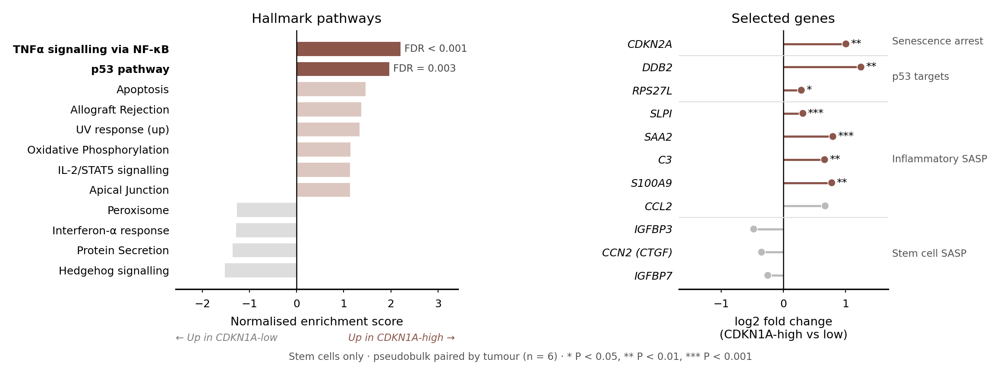

In [68]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Figure 2E: CDKN1A-high vs CDKN1A-low stem cells.
#   Left  - Hallmark GSEA (dissociation genes removed from the ranking)
#   Right - log2 fold change of selected genes (pseudobulk, paired by tumour)
# Run AFTER Stem_CDKN1A_high_vs_low.py (it reads the CSV that script saves).

# ---- 1. Configuration --------------------------------------------------------
de_csv    = "Stem_CDKN1A_high_vs_low_pseudobulk.csv"
gsea_csv  = "Stem_CDKN1A_GSEA_hallmark_nodiss.csv"   # created below if missing
n_up, n_down = 8, 4                                   # pathways shown on each side
fig_size  = (7.1, 2.6)                                # full page width
fs        = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns   = "#8c564b", "#DCC7C0"                # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns   = "#7f7f7f", "#DDDDDD"                # enriched in CDKN1A-low  (sig / n.s.)
highlight = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]

gene_groups = [                                       # right-hand panel
    ("Senescence arrest", ["CDKN2A"]),
    ("p53 targets",       ["DDB2", "RPS27L"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "CCL2"]),
    ("Stem cell SASP",    ["IGFBP3", "CCN2", "IGFBP7"]),
]
aliases = {"CCN2": "CTGF"}

diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Load DE results; run filtered GSEA if not already saved ------------
res = pd.read_csv(de_csv, index_col=0)
if not os.path.exists(gsea_csv):
    import gseapy as gp
    rnk = res["stat"].drop(index=[g for g in diss + ["CDKN1A"] if g in res.index]).dropna()
    pre = gp.prerank(rnk=rnk.sort_values(ascending=False), gene_sets="MSigDB_Hallmark_2020",
                     permutation_num=1000, min_size=15, max_size=500, seed=0,
                     outdir=None, verbose=False)
    pre.res2d.to_csv(gsea_csv, index=False)
g = pd.read_csv(gsea_csv)
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)

pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

# ---- 3. Plot -----------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 1], "wspace": 0.9})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if n > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for n, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([pretty.get(t, t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (n, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(n + (0.08 if n > 0 else -0.08), yi, txt, va="center",
                 ha="left" if n > 0 else "right", fontsize=fs["small"] - 0.5, color="#444444")
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(-lim * 0.75, lim)
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right: selected genes, log2 fold change
rows, ylab, sep, grp_pos = [], [], [], []
for gname, genes in gene_groups:
    start = len(rows)
    for gg in genes:
        key = gg if gg in res.index else aliases.get(gg, gg)
        if key in res.index:
            rows.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
    if len(rows) > start:
        grp_pos.append((gname, start, len(rows) - 1)); sep.append(len(rows) - 0.5)
gdf = pd.DataFrame(rows)
yy = np.arange(len(gdf))[::-1]                       # first gene at top
lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
        for l, p in zip(lfc, pv)]
ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
ax2.axvline(0, color="black", lw=0.6)
ax2.set_yticks(yy)
ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
for x_, y_, p in zip(lfc, yy, pv):
    if p < 0.05:
        ax2.text(x_ + (0.08 if x_ >= 0 else -0.08), y_, "*" if p >= 0.01 else "**" if p >= 0.001 else "***",
                 va="center", ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
m = np.abs(lfc).max() * 1.35
ax2.set_xlim(-m, m)
for s_ in sep[:-1]:
    ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
for gname, a, b in grp_pos:                           # group labels on the right
    ax2.text(1.02, 1 - ((a + b) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
             va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax2.tick_params(axis="y", length=0)
ax2.set_ylim(-0.6, len(gdf) - 0.4)
for sp in ("top", "right", "left"):
    ax2.spines[sp].set_visible(False)

fig.text(0.5, -0.1, "Stem cells only · pseudobulk paired by tumour (n = 6) · "
         "* P < 0.05, ** P < 0.01, *** P < 0.001", ha="center", fontsize=fs["small"] - 0.5,
         color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Not measured (zero counts in whole study): {'Su et al. (2025)': ['CGA', 'POMC'], 'Zhang et al. (2026)': ['POMC']}
             NR5A1   CGA   LHB  FSHB  TBX19  POMC  POU1F1
All cells     24.6  15.7  29.0  36.1    3.8   1.9     1.4
SRX16175537   17.8  78.5  66.0  57.2    0.5   0.6     0.0
SRX14605703   49.6  17.6   9.5  86.9   13.7   0.4     0.0
HRS488982      5.2  35.9   9.1   5.8    1.5  13.1     3.2
HRS488984     23.1   5.7  86.3  20.3    1.4   2.4     4.4
HRS488986     30.1   1.6  33.5  65.4    3.2   3.0    10.4
HRS488987      1.6  39.0   3.9   3.9    1.2   0.4     0.0
HRS488990      3.7  43.5  10.3  37.1    0.2   2.4     0.4
HRS488991      8.2  31.5  47.2  66.5    0.3   2.9     0.6
SRX21219338   45.5  10.2   2.6  51.7    3.1   0.3     1.4
SRX21219339   18.5  58.5  34.3  38.4   10.1   1.0     3.3
SRX21219341   36.3   3.0  22.0  49.7    4.1   0.3     0.0
SRX21219342   65.4  93.7  11.6  75.4    9.2   1.2     0.3
SRX21219343   18.0  11.0   4.2   2.2    8.3  26.7     0.3
SRX28461020   11

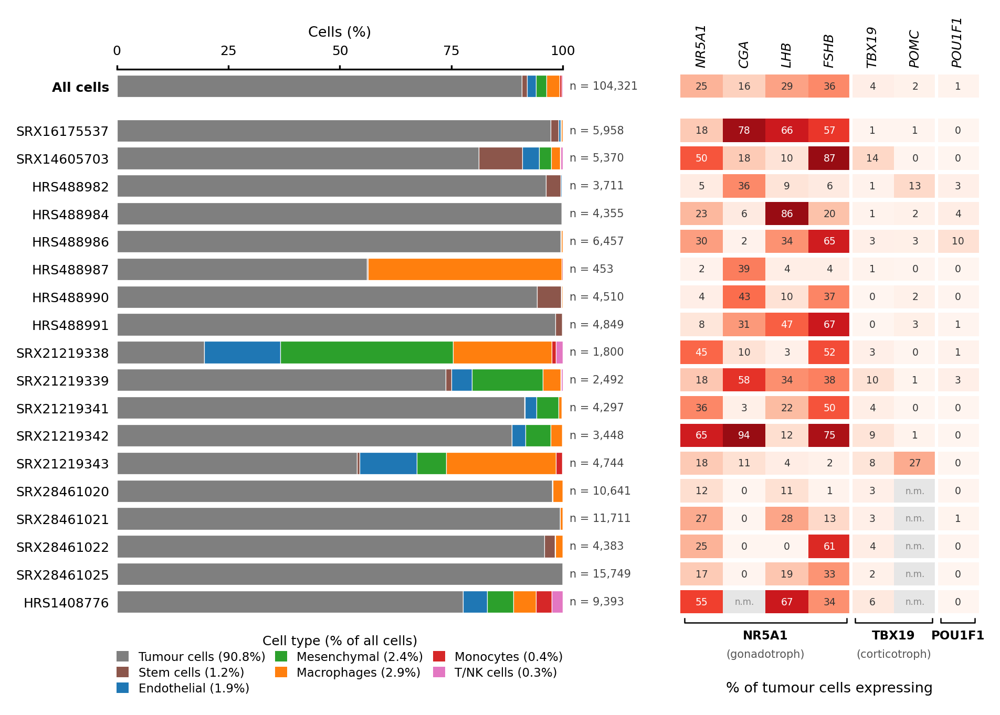

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

# Figure 1D + 1E on one shared y-axis:
#   D  cell-type composition per tumour (as before)
#   E  % of TUMOUR cells expressing lineage markers, same rows as D

# ---- 1. Configuration --------------------------------------------------------
celltype_col = "final_cell_type_broad"
sample_col   = "SRA_ID"
use_raw      = adata.raw is not None
sample_order = [                                   # same order as panel A
    "SRX16175537", "SRX14605703",
    "HRS488982", "HRS488984", "HRS488986", "HRS488987", "HRS488990", "HRS488991",
    "SRX21219338", "SRX21219339", "SRX21219341", "SRX21219342", "SRX21219343",
    "SRX28461020", "SRX28461021", "SRX28461022", "SRX28461025",
    "HRS1408776",
]
pal = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728",
       "T/NK cells": "#e377c2"}
aliases = {"Stem_cells": "Stem cells", "Endothelial_cells": "Endothelial",
           "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells",
           "Pituicytes": "Tumour cells"}
lineages = [("NR5A1\n(gonadotroph)", ["NR5A1", "CGA", "LHB", "FSHB"]),
            ("TBX19\n(corticotroph)", ["TBX19", "POMC"]),
            ("POU1F1", ["POU1F1"])]
fig_w   = 7.1                                      # inches (180 mm); D and E together
fs      = {"title": 7, "label": 6.5, "small": 6, "tiny": 5, "letter": 11}
add_letters = False   # add D and E manually when assembling

# ---- 2. Composition (panel D) -----------------------------------------------
obs = adata.obs[[sample_col, celltype_col]].astype(str).copy()
obs[celltype_col] = obs[celltype_col].replace(aliases)
types = [t for t in pal if t in set(obs[celltype_col])]
counts = pd.crosstab(obs[sample_col], obs[celltype_col]).reindex(columns=types, fill_value=0)
order = [s for s in sample_order if s in counts.index] + [s for s in counts.index if s not in sample_order]
counts = counts.reindex(order, fill_value=0)
n_cells = counts.sum(axis=1)
props = counts.div(n_cells.replace(0, np.nan), axis=0).fillna(0) * 100
overall = counts.sum(axis=0)
overall_pct = overall / overall.sum() * 100

rows = ["All cells"] + order
y = np.r_[0, np.arange(1, len(order) + 1) + 0.6]
data = pd.concat([overall_pct.to_frame("All cells").T, props])

# ---- 3. Lineage markers in tumour cells (panel E) ---------------------------
vn = adata.raw.var_names if use_raw else adata.var_names
genes = [g for _, gl in lineages for g in gl if g in vn]
tum = (obs[celltype_col] == "Tumour cells").to_numpy()
X = sc.get.obs_df(adata[tum], keys=genes, use_raw=use_raw) > 0
X.index = obs.index[tum]
lin = (X.groupby(obs.loc[tum, sample_col].values).mean() * 100).reindex(order)
lin_all = (X.mean() * 100).to_frame("All cells").T
L = pd.concat([lin_all, lin])[genes]

# Genes with ZERO counts across a whole study were not measured in that dataset (absent from
# its gene list) - show them as grey "n.m." instead of 0%.
study_col = "Author"
if study_col in adata.obs and "counts" in adata.layers:
    gi = [list(adata.var_names).index(g) for g in genes]
    Cg = adata.layers["counts"][:, gi]
    Cg = Cg.toarray() if hasattr(Cg, "toarray") else np.asarray(Cg)
    st = adata.obs[study_col].astype(str).values
    tot = pd.DataFrame(Cg, columns=genes).groupby(st).sum()
    s2study = adata.obs.groupby(sample_col, observed=True)[study_col].first().astype(str)
    for samp in L.index[1:]:
        for g in genes:
            if tot.loc[s2study[samp], g] == 0:
                L.loc[samp, g] = np.nan
    missing = {k: [g for g in genes if tot.loc[k, g] == 0] for k in tot.index}
    print("Not measured (zero counts in whole study):", {k: v for k, v in missing.items() if v})
print(L.round(1).to_string())

# ---- 4. Plot -----------------------------------------------------------------
fig = plt.figure(figsize=(fig_w, 0.17 * len(rows) + 1.3), dpi=300)
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.45, 1], wspace=0.3)
axD = fig.add_subplot(gs[0])
axE = fig.add_subplot(gs[1], sharey=axD)

# D: stacked bars
left = np.zeros(len(rows))
for t in types:
    vals = data[t].to_numpy()
    axD.barh(y, vals, left=left, height=0.8, color=pal[t], edgecolor="white", linewidth=0.3)
    left += vals
ns = [int(overall.sum())] + list(n_cells)
for yi, n in zip(y, ns):
    axD.text(101.5, yi, f"n = {n:,}" if n else "excluded", va="center", fontsize=fs["tiny"],
             color="#444444")
axD.set_yticks(y)
axD.set_yticklabels(rows, fontsize=fs["small"])
axD.get_yticklabels()[0].set_fontweight("bold")
axD.set_ylim(y[-1] + 0.6, -0.6)
axD.set_xlim(0, 100)
axD.set_xticks([0, 25, 50, 75, 100])
axD.tick_params(axis="x", labelsize=fs["small"], length=2)
axD.tick_params(axis="y", length=0)
axD.xaxis.tick_top(); axD.xaxis.set_label_position("top")
axD.set_xlabel("Cells (%)", fontsize=fs["label"])
for s in ("right", "bottom", "left"):
    axD.spines[s].set_visible(False)
lab = [f"{t} ({overall_pct[t]:.1f}%)" if overall_pct[t] >= 0.1 else f"{t} (<0.1%)" for t in types]
axD.legend(handles=[Patch(facecolor=pal[t], label=l) for t, l in zip(types, lab)],
           loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False,
           fontsize=fs["tiny"] + 0.5, handlelength=1, handleheight=1, columnspacing=0.8,
           labelspacing=0.3, title="Cell type (% of all cells)", title_fontsize=fs["small"])

# E: lineage heatmap (same y positions)
x0 = 0.18                                            # small gap so it clears the "n =" labels
xs = np.arange(len(genes)) + x0
cmap = plt.get_cmap("Reds")
for yi, (_, row) in zip(y, L.iterrows()):
    for xi, g in zip(xs, genes):
        v = row[g]
        if np.isnan(v):
            axE.add_patch(plt.Rectangle((xi - 0.5, yi - 0.42), 1, 0.84, color="#E6E6E6", lw=0))
            axE.text(xi, yi, "n.m.", ha="center", va="center", fontsize=fs["tiny"] - 1, color="#888888")
            continue
        axE.add_patch(plt.Rectangle((xi - 0.5, yi - 0.42), 1, 0.84,
                                    color=cmap(min(v, 80) / 80 * 0.9), lw=0))
        axE.text(xi, yi, f"{v:.0f}", ha="center", va="center", fontsize=fs["tiny"] - 0.5,
                 color="white" if v > 45 else "#333333")
axE.set_xlim(xs[0] - 0.6, xs[-1] + 0.6)
axE.set_xticks(xs)
axE.set_xticklabels(genes, fontsize=fs["small"], fontstyle="italic", rotation=90)
axE.xaxis.tick_top()
axE.tick_params(axis="x", length=0, pad=1)
axE.tick_params(axis="y", left=False, labelleft=False)
for s in axE.spines.values():
    s.set_visible(False)
# lineage group brackets below the heatmap
i = 0
for name, gl in lineages:
    k = sum(g in genes for g in gl)
    if k == 0:
        continue
    a, b = xs[i] - 0.4, xs[i + k - 1] + 0.4
    yb = y[-1] + 0.75
    axE.plot([a, a, b, b], [yb - 0.15, yb, yb, yb - 0.15], color="black", lw=0.6, clip_on=False)
    axE.text((a + b) / 2, yb + 0.25, name.split("\n")[0], ha="center", va="top",
             fontsize=fs["tiny"] + 0.5, fontweight="bold", clip_on=False)
    axE.text((a + b) / 2, yb + 0.95, name.split("\n")[1] if "\n" in name else "", ha="center",
             va="top", fontsize=fs["tiny"], color="#555555", clip_on=False)
    if i > 0:
        axE.axvline(xs[i] - 0.5, color="white", lw=1.5)
    i += k
axE.text(0.5, -0.115, "% of tumour cells expressing", transform=axE.transAxes, ha="center",
         va="top", fontsize=fs["label"])

if add_letters:
    fig.text(0.0, 0.99, "D", fontsize=fs["letter"], fontweight="bold", va="top")
    fig.text(axE.get_position().x0 - 0.01, 0.99, "E", fontsize=fs["letter"], fontweight="bold", va="top")

fig.savefig("Fig1DE_composition_lineage.pdf", bbox_inches="tight")
fig.savefig("Fig1DE_composition_lineage.svg", bbox_inches="tight")
fig.savefig("Fig1DE_composition_lineage.png", dpi=600, bbox_inches="tight")
plt.show()

In [10]:
import numpy as np, pandas as pd
genes = ["CGA", "LHB", "FSHB", "NR5A1", "POMC", "CDKN1A", "CDKN2A", "IGFBP3", "CCN2", "CCL2"]
genes = [g for g in genes if g in adata.var_names]
C = adata[:, genes].layers["counts"]
C = C.toarray() if hasattr(C, "toarray") else np.asarray(C)
tot = pd.DataFrame(C, columns=genes).groupby(adata.obs["Author"].astype(str).values).sum()
print(tot.astype(int).to_string())   # a 0 for a whole study = gene absent from that dataset

# genome-wide: how many genes are entirely zero in each study?
allc = adata.layers["counts"]
for study in adata.obs["Author"].astype(str).unique():
    m = (adata.obs["Author"].astype(str) == study).to_numpy()
    s = np.asarray(allc[m].sum(axis=0)).ravel()
    print(f"{study:<25} genes with zero counts: {(s == 0).sum():,} of {len(s):,}")

                         CGA    LHB    FSHB  NR5A1  POMC  CDKN1A  CDKN2A  IGFBP3   CCN2   CCL2
Asuzu et al., (2022)   51958  39544   11226   1181    84     604     323    1277    274    103
Ilie et al. (2025)     83128  52648  133092   8814  1881   12169    1556    6548   7145  26847
Su et al. (2025)           0  37154    8954   8467     0   10465     841    1740  14066   3234
Yan et al., (2024)     14890  34228   36586   4910  1614    1523     426     384    106   1221
Zhang et al. (2026)      108   9542   17215  10062     0     169    2046     230     92     49
Zhang et al., (2022b)   3336   1581   57084   4398   218     942    1217    9520   2677    113
Su et al. (2025)          genes with zero counts: 5,974 of 39,074
Zhang et al. (2026)       genes with zero counts: 3,245 of 39,074
Ilie et al. (2025)        genes with zero counts: 3,788 of 39,074
Yan et al., (2024)        genes with zero counts: 5,491 of 39,074
Zhang et al., (2022b)     genes with zero counts: 6,056 of 39,074
Asuzu

In [17]:
%pip install gseapy
%pip install pydeseq2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.6/87.6 kB 11.4 MB/s eta 0:00:00


CDKN1A_group  high  low
SRA_ID                 
HRS488982       65   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
HRS1408776       1    0
SRX14605703    100  426
SRX16175537     35   70
SRX21219339     19   14
SRX21219341      3    2
SRX21219343     21    7
SRX28461022      6   98 

Tumours with >= 10 cells in both groups: 6

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 1
                   log2FoldChange  pvalue    padj
SLPI                       0.3114  0.0000  0.0037
OTOGL                     -1.0590  0.0001  0.2920
EGOT                       1.6513  0.0001  0.3231
SAA2                       0.7937  0.0002  0.4105
COL11A1                   -1.0083  0.0004  0.6987
EGR1                       0.3944  0.0004  0.6987
CXCL14                    -2.0819  0.0009  0.9999
CHST9                      1.0138  0.0016  0.9999
DPYSL3                     0.8246  0.0017  0.9999
STK38L        

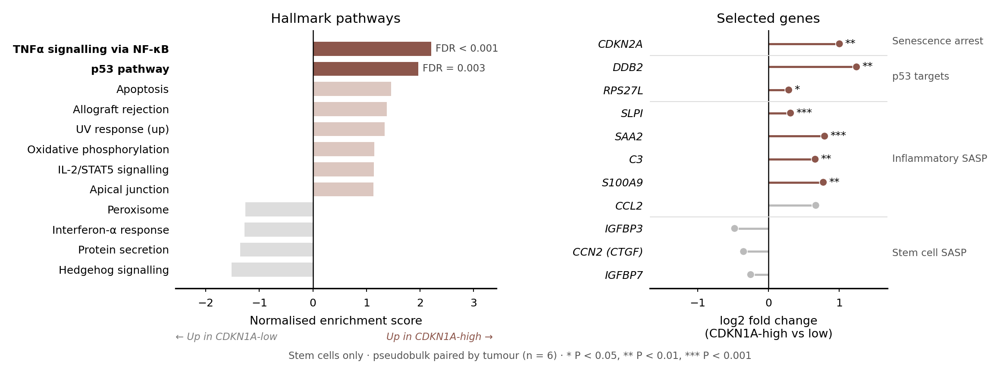

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 2.6)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
gene_groups  = [
    ("Senescence arrest", ["CDKN2A"]),
    ("p53 targets",       ["DDB2", "RPS27L"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "CCL2"]),
    ("Stem cell SASP",    ["IGFBP3", "CCN2", "IGFBP7"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
stem.obs["CDKN1A_group"] = np.where(cdkn1a > 0, "high", "low")

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_cells) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_cells} cells in both groups: {len(keep)}")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 1], "wspace": 0.55})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + (0.08 if v > 0 else -0.08), yi, txt, va="center",
                 ha="left" if v > 0 else "right", fontsize=fs["small"] - 0.5, color="#444444")
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(-lim * 0.75, lim)
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right: selected genes, log2 fold change
rws, ylab, sep, grp_pos = [], [], [], []
for gname, genes in gene_groups:
    start = len(rws)
    for gg in genes:
        key = gg if gg in res.index else aliases.get(gg, gg)
        if key in res.index:
            rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
    if len(rws) > start:
        grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
gdf = pd.DataFrame(rws)
yy = np.arange(len(gdf))[::-1]
lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
        for l, p in zip(lfc, pv)]
ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
ax2.axvline(0, color="black", lw=0.6)
ax2.set_yticks(yy)
ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
for x_, y_, p in zip(lfc, yy, pv):
    if p < 0.05:
        ax2.text(x_ + (0.08 if x_ >= 0 else -0.08), y_,
                 "*" if p >= 0.01 else "**" if p >= 0.001 else "***",
                 va="center", ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
mx = np.abs(lfc).max() * 1.35
ax2.set_xlim(-mx, mx)
ax2.xaxis.set_major_locator(MultipleLocator(1))
for s_ in sep[:-1]:
    ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
for gname, a, b in grp_pos:
    ax2.text(1.02, 1 - ((a + b) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
             va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax2.tick_params(axis="y", length=0)
ax2.set_ylim(-0.6, len(gdf) - 0.4)
for sp in ("top", "right", "left"):
    ax2.spines[sp].set_visible(False)

fig.text(0.5, -0.1, f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
         "* P < 0.05, ** P < 0.01, *** P < 0.001", ha="center", fontsize=fs["small"] - 0.5,
         color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

CDKN1A_group  high  low
SRA_ID                 
HRS488982       65   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
HRS1408776       1    0
SRX14605703    100  426
SRX16175537     35   70
SRX21219339     19   14
SRX21219341      3    2
SRX21219343     21    7
SRX28461022      6   98 

Tumours with >= 10 cells in both groups: 6

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 1
                   log2FoldChange  pvalue    padj
SLPI                       0.3114  0.0000  0.0037
OTOGL                     -1.0590  0.0001  0.2920
EGOT                       1.6513  0.0001  0.3231
SAA2                       0.7937  0.0002  0.4105
COL11A1                   -1.0083  0.0004  0.6987
EGR1                       0.3944  0.0004  0.6987
CXCL14                    -2.0819  0.0009  0.9999
CHST9                      1.0138  0.0016  0.9999
DPYSL3                     0.8246  0.0017  0.9999
STK38L        

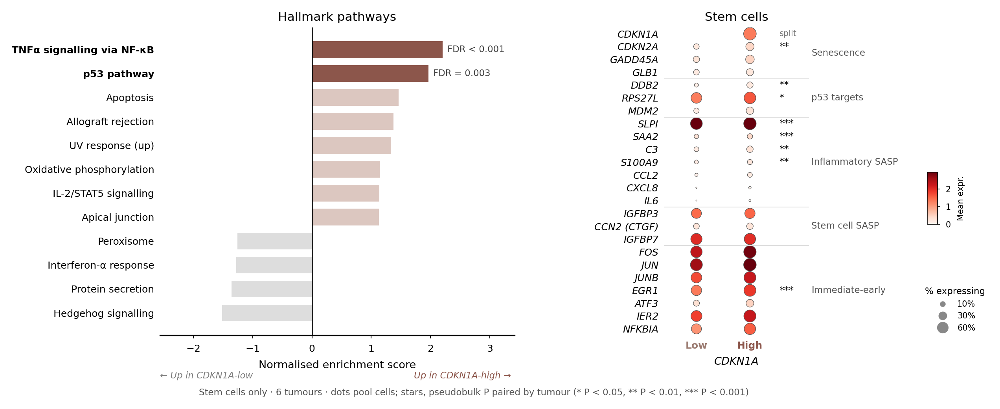

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.4)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "dotplot"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [
    ("Senescence",        ["CDKN1A", "CDKN2A", "GADD45A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "CCL2", "CXCL8", "IL6"]),
    ("Stem cell SASP",    ["IGFBP3", "CCN2", "IGFBP7"]),
    ("Immediate-early",   ["FOS", "JUN", "JUNB", "EGR1", "ATF3", "IER2", "NFKBIA"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
stem.obs["CDKN1A_group"] = np.where(cdkn1a > 0, "high", "low")

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_cells) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_cells} cells in both groups: {len(keep)}")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + (0.08 if v > 0 else -0.08), yi, txt, va="center",
                 ha="left" if v > 0 else "right", fontsize=fs["small"] - 0.5, color="#444444")
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(-lim * 0.75, lim)
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.14, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.14, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            ax2.text(x_ + (0.08 if x_ >= 0 else -0.08), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    mx = np.abs(lfc).max() * 1.35
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

In [20]:
cands = {
    "Senescence":        ["CDKN1A", "CDKN2A", "GADD45A", "GLB1"],
    "p53 targets":       ["DDB2", "RPS27L", "MDM2", "TP53I3", "ZMAT3", "SESN1", "FDXR", "TNFRSF10B"],
    "SASP regulators":   ["MAPKAPK2", "FOSL1", "TRIB1"],
    "Inflammatory SASP": ["SLPI", "SAA2", "C3", "S100A9", "CCL2", "CXCL8", "IL6", "SULF1"],
    "Stem cell SASP":    ["IGFBP3", "CCN2", "CTGF", "IGFBP7"],
    "Identity":          ["TACSTD2", "S100B", "CXCL14", "SOX2"],
}
for grp, gl in cands.items():
    sub = res.reindex([g for g in gl if g in res.index])[["log2FoldChange", "pvalue", "padj"]]
    print(f"\n{grp}\n", sub.round(4).to_string())

# the top 20 DEGs, excluding dissociation genes, for anything else worth a look
print(res.drop(index=[g for g in diss if g in res.index]).head(20)
      [["log2FoldChange", "pvalue"]].round(4).to_string())


Senescence
          log2FoldChange  pvalue    padj
CDKN2A           1.0040  0.0064  0.9999
GADD45A          0.2883  0.2322  0.9999
GLB1             0.0602  0.8539  0.9999

p53 targets
            log2FoldChange  pvalue    padj
DDB2               1.2453  0.0090  0.9999
RPS27L             0.2865  0.0130  0.9999
MDM2               0.6472  0.0644  0.9999
TP53I3            -0.1179  0.7368  0.9999
ZMAT3              0.4172  0.0940  0.9999
SESN1              0.4802  0.2314  0.9999
TNFRSF10B          0.1325  0.7089  0.9999

SASP regulators
           log2FoldChange  pvalue    padj
MAPKAPK2          0.9245  0.0059  0.9999
FOSL1             1.4948  0.0082  0.9999
TRIB1             0.7608  0.0108  0.9999

Inflammatory SASP
         log2FoldChange  pvalue    padj
SLPI            0.3114  0.0000  0.0037
SAA2            0.7937  0.0002  0.4105
C3              0.6605  0.0074  0.9999
S100A9          0.7756  0.0093  0.9999
CCL2            0.6692  0.2871  0.9999
CXCL8           0.3219  0.8441  0.9999
SU

CDKN1A_group  high  low
SRA_ID                 
HRS488982       65   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
HRS1408776       1    0
SRX14605703    100  426
SRX16175537     35   70
SRX21219339     19   14
SRX21219341      3    2
SRX21219343     21    7
SRX28461022      6   98 

Tumours with >= 10 cells in both groups: 6

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 1
                   log2FoldChange  pvalue    padj
SLPI                       0.3114  0.0000  0.0037
OTOGL                     -1.0590  0.0001  0.2920
EGOT                       1.6513  0.0001  0.3231
SAA2                       0.7937  0.0002  0.4105
COL11A1                   -1.0083  0.0004  0.6987
EGR1                       0.3944  0.0004  0.6987
CXCL14                    -2.0819  0.0009  0.9999
CHST9                      1.0138  0.0016  0.9999
DPYSL3                     0.8246  0.0017  0.9999
STK38L        

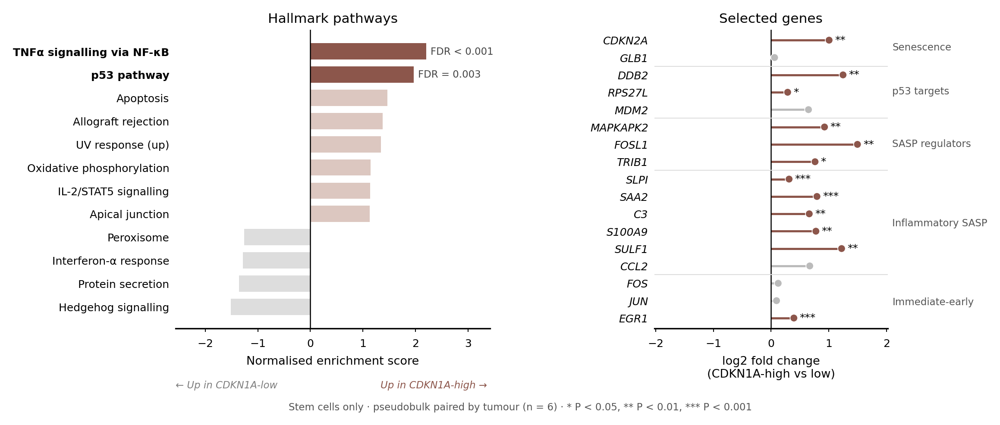

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.0)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
stem.obs["CDKN1A_group"] = np.where(cdkn1a > 0, "high", "low")

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_cells) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_cells} cells in both groups: {len(keep)}")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + (0.08 if v > 0 else -0.08), yi, txt, va="center",
                 ha="left" if v > 0 else "right", fontsize=fs["small"] - 0.5, color="#444444")
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(-lim * 0.75, lim)
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Stem cells: 1253

Proliferation (stem cells):
  MKI67 CDKN1A-low: 6 / 943 (0.6%)
  MKI67 CDKN1A-high: 1 / 310 (0.3%)
  TOP2A CDKN1A-low: 12 / 943 (1.3%)
  TOP2A CDKN1A-high: 5 / 310 (1.6%)


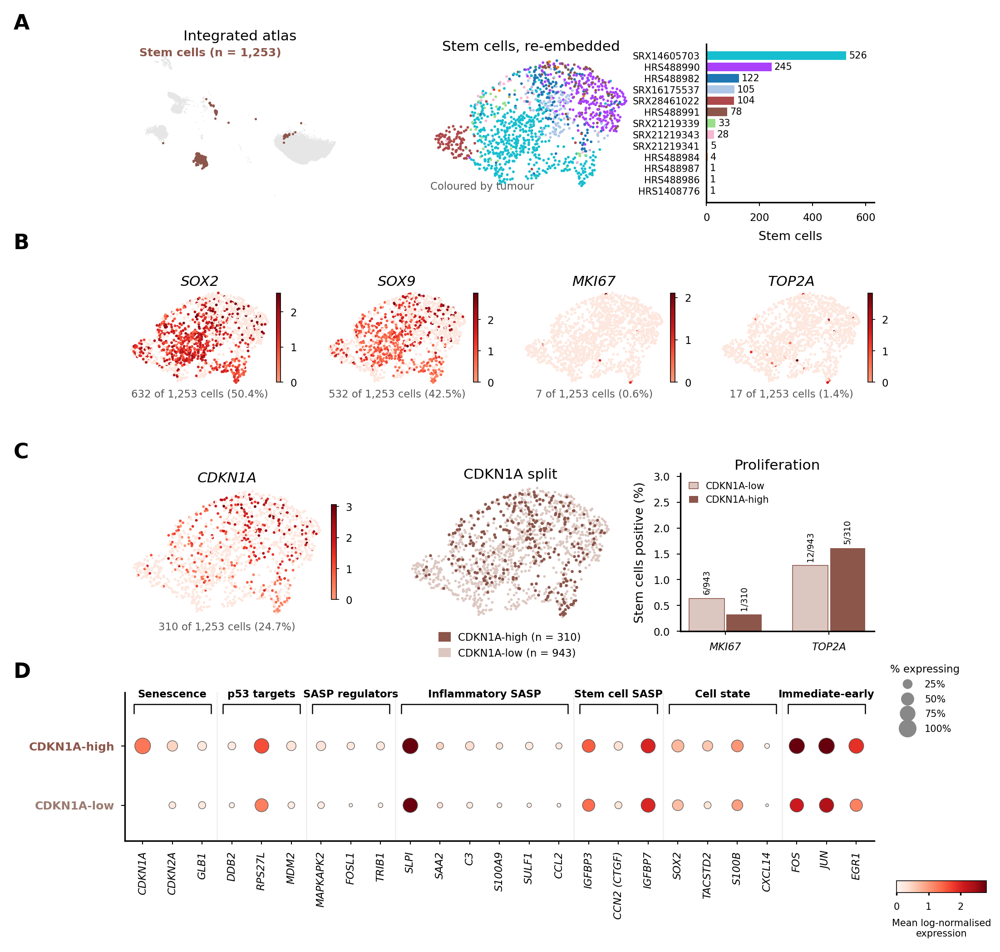


Stem cells per tumour:
 SRA_ID
SRX14605703    526
HRS488990      245
HRS488982      122
SRX16175537    105
SRX28461022    104
HRS488991       78
SRX21219339     33
SRX21219343     28
SRX21219341      5
HRS488984        4
HRS488986        1
HRS1408776       1
HRS488987        1
SOX2: 632 / 1253 (50.4%)
SOX9: 532 / 1253 (42.5%)
MKI67: 7 / 1253 (0.6%)
TOP2A: 17 / 1253 (1.4%)
CDKN1A: 310 / 1253 (24.7%)


In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Supplementary Figure 2: the stem cell compartment, in the Figure 2 style.
#   A  stem cells in the atlas | stem cells re-embedded, by tumour | stem cells per tumour
#   B  SOX2, SOX9 (identity)   | MKI67, TOP2A (proliferation)
#   C  CDKN1A expression       | CDKN1A-high / -low split
#   D  dot plot, CDKN1A-high vs -low: senescence, p53 targets, SASP, immediate-early genes

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
use_raw    = adata.raw is not None
fig_w      = 7.1                                   # inches (180 mm)
fs         = {"title": 7.5, "label": 6.5, "small": 6, "letter": 11}
stem_col   = "#8c564b"
split_cols = {"CDKN1A-low": "#DCC7C0", "CDKN1A-high": "#8c564b"}
reuse_umap = None    # e.g. "X_umap_stem" if your stem object already has its own UMAP

dot_groups = [   # complements Fig. 2E: adds the stem cell SASP and cell-state genes
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Stem cell SASP",    ["IGFBP3", "CCN2", "IGFBP7"]),
    ("Cell state",        ["SOX2", "TACSTD2", "S100B", "CXCL14"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}

# ---- 2. Stem cell subset and its own UMAP -----------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
if reuse_umap and reuse_umap in stem.obsm:
    stem.obsm["X_umap_stem"] = stem.obsm[reuse_umap]
else:
    sc.pp.neighbors(stem, use_rep="X_scVI", n_neighbors=15, random_state=0)
    sc.tl.umap(stem, random_state=0)
    stem.obsm["X_umap_stem"] = stem.obsm["X_umap"].copy()
sxy = stem.obsm["X_umap_stem"]
print(f"Stem cells: {stem.n_obs}")

vn = stem.raw.var_names if use_raw else stem.var_names
def gname(g):
    return g if g in vn else aliases.get(g, g)
def expr(g):
    return sc.get.obs_df(stem, keys=[gname(g)], use_raw=use_raw)[gname(g)].to_numpy(dtype=float)

cdkn1a = expr("CDKN1A")
stem.obs["CDKN1A_group"] = np.where(cdkn1a > 0, "CDKN1A-high", "CDKN1A-low")

# sample colours: reuse the atlas palette if stored, otherwise tab20
samples = stem.obs[sample_col].astype(str)
cats = list(adata.obs[sample_col].astype("category").cat.categories)
if f"{sample_col}_colors" in adata.uns and len(adata.uns[f"{sample_col}_colors"]) == len(cats):
    s_pal = dict(zip(cats, adata.uns[f"{sample_col}_colors"]))
else:
    s_pal = {s: plt.get_cmap("tab20")(i % 20) for i, s in enumerate(cats)}
counts = samples.value_counts()
counts = counts[counts > 0].sort_values()

# expression colour map: palest = not detected (as in Fig. 2C/D)
reds = plt.get_cmap("Reds")(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])
order = np.random.default_rng(0).permutation(stem.n_obs)

def clean(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    for sp in ax.spines.values():
        sp.set_visible(False)

def gene_umap(ax, g, cax=None):
    v = expr(g)
    vmax = np.percentile(v[v > 0], 99) if (v > 0).any() else 1
    im = ax.scatter(sxy[order, 0], sxy[order, 1], c=v[order], s=2, cmap=pop_cmap, vmin=0,
                    vmax=vmax, linewidths=0, rasterized=True)
    n = int((v > 0).sum())
    ax.set_title(f"{g}", fontsize=fs["title"], fontstyle="italic", pad=1)
    ax.text(0.5, -0.02, f"{n:,} of {len(v):,} cells ({n / len(v) * 100:.1f}%)", transform=ax.transAxes,
            ha="center", va="top", fontsize=fs["small"] - 0.5, color="#555555")
    clean(ax)
    cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.01, shrink=0.6)
    cb.ax.tick_params(labelsize=fs["small"] - 0.5, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    return v

# ---- 3. Figure layout ---------------------------------------------------------
fig = plt.figure(figsize=(fig_w, 7.6), dpi=300)
outer = GridSpec(4, 1, figure=fig, height_ratios=[0.8, 0.75, 0.8, 0.75], hspace=0.4)

# Row A
gA = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[0], width_ratios=[1.1, 1, 0.8], wspace=0.35)
a1, a2, a3 = (fig.add_subplot(gA[i]) for i in range(3))
axy = adata.obsm["X_umap"]
is_stem = ct == "Stem cells"
a1.scatter(axy[~is_stem, 0], axy[~is_stem, 1], s=0.3, color="#E6E6E6", linewidths=0, rasterized=True)
a1.scatter(axy[is_stem, 0], axy[is_stem, 1], s=1.5, color=stem_col, linewidths=0, rasterized=True)
a1.set_title("Integrated atlas", fontsize=fs["title"], pad=2)
a1.text(0.02, 0.98, f"Stem cells (n = {is_stem.sum():,})", transform=a1.transAxes, va="top",
        fontsize=fs["small"], color=stem_col, fontweight="bold")
clean(a1)

a2.scatter(sxy[order, 0], sxy[order, 1], s=2, c=[s_pal[s] for s in samples.iloc[order]],
           linewidths=0, rasterized=True)
a2.set_title("Stem cells, re-embedded", fontsize=fs["title"], pad=2)
a2.text(0.02, 0.02, "Coloured by tumour", transform=a2.transAxes, fontsize=fs["small"] - 0.5, color="#555555")
clean(a2)

a3.barh(range(len(counts)), counts.values, color=[s_pal[s] for s in counts.index], height=0.75)
a3.set_yticks(range(len(counts)))
a3.set_yticklabels(counts.index, fontsize=fs["small"] - 1)
for i, v in enumerate(counts.values):
    a3.text(v + counts.max() * 0.02, i, str(v), va="center", fontsize=fs["small"] - 1)
a3.set_xlabel("Stem cells", fontsize=fs["label"])
a3.set_xlim(0, counts.max() * 1.2)
a3.tick_params(axis="x", labelsize=fs["small"] - 0.5, length=2, width=0.5)
a3.tick_params(axis="y", length=0)
for sp in ("top", "right"):
    a3.spines[sp].set_visible(False)

# Row B
gB = GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[1], wspace=0.25)
for i, g in enumerate(["SOX2", "SOX9", "MKI67", "TOP2A"]):
    gene_umap(fig.add_subplot(gB[i]), g)

# Row C
gC = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[2], width_ratios=[1, 1, 0.9], wspace=0.3)
gene_umap(fig.add_subplot(gC[0]), "CDKN1A")
c2 = fig.add_subplot(gC[1])
grp = stem.obs["CDKN1A_group"].to_numpy()
for gg in ["CDKN1A-low", "CDKN1A-high"]:                 # high drawn on top
    m = grp == gg
    c2.scatter(sxy[m, 0], sxy[m, 1], s=2.5 if gg.endswith("high") else 2, color=split_cols[gg],
               linewidths=0, rasterized=True)
c2.set_title("CDKN1A split", fontsize=fs["title"], pad=1)
clean(c2)
c2.legend(handles=[Patch(color=split_cols[k], label=f"{k} (n = {(grp == k).sum():,})")
                   for k in ["CDKN1A-high", "CDKN1A-low"]],
          loc="upper center", bbox_to_anchor=(0.5, -0.0), frameon=False, fontsize=fs["small"] - 0.5,
          handlelength=1, ncol=1)

# Proliferation: % of MKI67+ / TOP2A+ stem cells in CDKN1A-low vs -high (bars, counts on top)
c3 = fig.add_subplot(gC[2])
prolif = {"MKI67": expr("MKI67") > 0, "TOP2A": expr("TOP2A") > 0}
xpos = {"CDKN1A-low": -0.18, "CDKN1A-high": 0.18}
for gi, (gname_, pos_) in enumerate(prolif.items()):
    for k, dx in xpos.items():
        m = grp == k
        pct = pos_[m].mean() * 100
        c3.bar(gi + dx, pct, width=0.34, color=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
               linewidth=0.4)
        c3.text(gi + dx, pct + 0.08, f"{pos_[m].sum()}/{m.sum()}", ha="center", va="bottom",
                fontsize=fs["small"] - 1.5, rotation=90)
c3.set_xticks(range(len(prolif)))
c3.set_xticklabels(list(prolif), fontsize=fs["small"], fontstyle="italic")
c3.set_ylabel("Stem cells positive (%)", fontsize=fs["label"])
top_ = max(pos_[grp == k].mean() * 100 for pos_ in prolif.values() for k in xpos)
c3.set_ylim(0, max(top_ * 1.9, 1))
c3.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
for sp in ("top", "right"):
    c3.spines[sp].set_visible(False)
c3.set_title("Proliferation", fontsize=fs["title"], pad=2)
c3.legend(handles=[Patch(facecolor=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
                         linewidth=0.4, label=k) for k in ["CDKN1A-low", "CDKN1A-high"]],
          loc="upper left", frameon=False, fontsize=fs["small"] - 1, handlelength=1)
print("\nProliferation (stem cells):")
for gname_, pos_ in prolif.items():
    for k in xpos:
        m = grp == k
        print(f"  {gname_} {k}: {pos_[m].sum()} / {m.sum()} ({pos_[m].mean() * 100:.1f}%)")

# Row D: dot plot (columns = genes; rows = high / low)
genes, gpos = [], []
for name, gl in dot_groups:
    kept = [g for g in gl if gname(g) in vn]
    if kept:
        gpos.append((name, len(genes), len(genes) + len(kept) - 1)); genes += kept
E = sc.get.obs_df(stem, keys=[gname(g) for g in genes], use_raw=use_raw).to_numpy(dtype=float)
rows_ = ["CDKN1A-high", "CDKN1A-low"]
frac = np.array([(E[grp == r] > 0).mean(0) for r in rows_])
mean = np.array([E[grp == r].mean(0) for r in rows_])
scaled = mean                                                     # shared scale (no per-gene rescaling)
vmax_d = np.percentile(mean, 95)
d = fig.add_subplot(outer[3])
xx, yy = np.meshgrid(np.arange(len(genes)), np.arange(len(rows_)))
sc_ = d.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 70, c=scaled.ravel(), cmap="Reds",
                vmin=0, vmax=vmax_d, edgecolors="#555555", linewidths=0.3)
d.set_xticks(range(len(genes)))
d.set_xticklabels(["CCN2 (CTGF)" if g == "CCN2" else g for g in genes], rotation=90,
                  fontsize=fs["small"] - 0.5, fontstyle="italic")
d.set_yticks([0, 1]); d.set_yticklabels(rows_, fontsize=fs["small"])
for lab, r in zip(d.get_yticklabels(), rows_):
    lab.set_color(split_cols[r] if r.endswith("high") else "#9a7a70"); lab.set_fontweight("bold")
d.set_xlim(-0.6, len(genes) - 0.4); d.set_ylim(1.6, -0.9)
for sp in ("top", "right"):
    d.spines[sp].set_visible(False)
d.tick_params(length=2, width=0.5)
for name, a, b in gpos:                                            # group brackets
    d.plot([a - 0.3, a - 0.3, b + 0.3, b + 0.3], [-0.55, -0.7, -0.7, -0.55], color="black", lw=0.6,
           clip_on=False)
    d.text((a + b) / 2, -0.78, name, ha="center", va="bottom", fontsize=fs["small"] - 0.5,
           fontweight="bold")
    if a > 0:
        d.axvline(a - 0.5, color="#EEEEEE", lw=0.6, zorder=0)
# keys
size_h = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p * 70),
                 label=f"{int(p * 100)}%") for p in (0.25, 0.5, 0.75, 1.0)]
d.legend(handles=size_h, title="% expressing", loc="upper left", bbox_to_anchor=(1.01, 1.25),
         frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5, labelspacing=0.6)
cax = d.inset_axes([1.03, -0.35, 0.12, 0.08])
cb = fig.colorbar(sc_, cax=cax, orientation="horizontal")
cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5)
cb.set_label("Mean log-normalised\nexpression", fontsize=fs["small"] - 1)
cb.outline.set_linewidth(0.4)

# panel letters
for i, letter in enumerate("ABCD"):
    top = outer[i].get_position(fig).y1
    fig.text(0.01, top + 0.01, letter, fontsize=fs["letter"], fontweight="bold", va="bottom")

fig.savefig("SuppFig2_stem_cells.pdf", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.svg", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.png", dpi=600, bbox_inches="tight")
plt.show()

# numbers for the legend
print("\nStem cells per tumour:\n", counts.sort_values(ascending=False).to_string())
for g in ["SOX2", "SOX9", "MKI67", "TOP2A", "CDKN1A"]:
    v = expr(g)
    print(f"{g}: {(v > 0).sum()} / {len(v)} ({(v > 0).mean() * 100:.1f}%)")

Global 90th percentile of CDKN1A in stem cells: 1.494
Cells per group: {'low': 943, 'mid': 184, 'high': 126}
CDKN1A_group  high  low
SRA_ID                 
HRS488982       38   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
SRX14605703      1  426
SRX16175537     16   70
SRX21219339      7   14
SRX21219341      1    2
SRX21219343      0    7
SRX28461022      3   98 

Tumours with >= 5 high and >= 10 low cells: 5

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 0
          log2FoldChange  pvalue    padj
S100A2            1.6689  0.0000  0.1175
TACSTD2           1.1167  0.0003  0.5604
SAA2              1.2549  0.0007  0.9026
GADD45B           1.0086  0.0013  0.9995
MT-ND4           -0.7739  0.0032  0.9995
CLIC4             1.0105  0.0040  0.9995
SLPI              0.4570  0.0045  0.9995
CDKN2A            1.3710  0.0065  0.9995
S100A9            1.1659  0.0067  0.9995
KLF6            

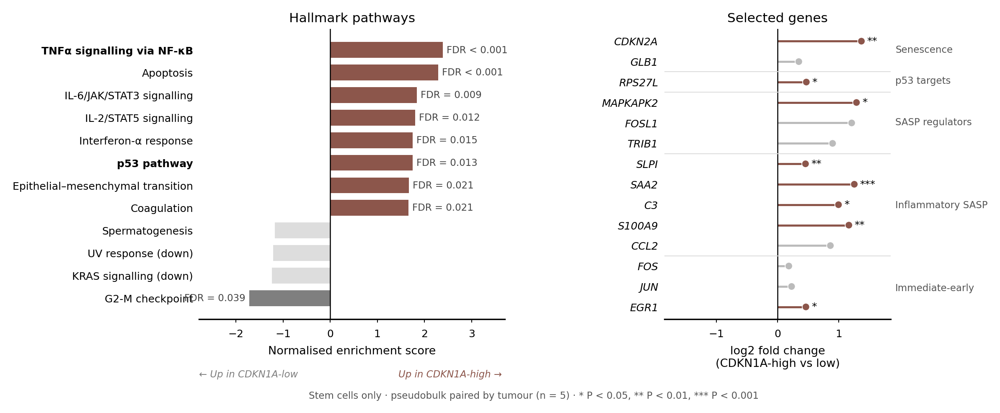

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
split_mode   = "global_q90"           # "detected": any CDKN1A vs none
                                      # "global_q90": top 10% of stem cells by CDKN1A vs none detected
                                      # "tumour_q90": top 10% within each tumour vs none detected
q_high       = 0.90
min_high     = 5                      # min CDKN1A-high cells per tumour (fewer cells pass a strict cut-off)
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.0)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
if split_mode == "detected":
    grp_ = np.where(cdkn1a > 0, "high", "low")
else:
    # stricter: "high" = top 10% of CDKN1A expression; "low" = CDKN1A not detected;
    # cells in between (detected but below the cut-off) are left out
    grp_ = np.full(len(cdkn1a), "mid", dtype=object)
    grp_[cdkn1a == 0] = "low"
    if split_mode == "global_q90":
        thr = np.quantile(cdkn1a, q_high)
        thr = max(thr, np.min(cdkn1a[cdkn1a > 0]))      # never call an undetected cell "high"
        grp_[cdkn1a >= thr] = "high"
        print(f"Global {int(q_high * 100)}th percentile of CDKN1A in stem cells: {thr:.3f}")
    else:
        sid_ = stem.obs[sample_col].astype(str).to_numpy()
        for s_ in np.unique(sid_):
            m = sid_ == s_
            v = cdkn1a[m]
            if (v > 0).any():
                thr = max(np.quantile(v, q_high), v[v > 0].min())
                grp_[m & (cdkn1a >= thr)] = "high"
stem.obs["CDKN1A_group"] = grp_
print("Cells per group:", pd.Series(grp_).value_counts().to_dict())
stem = stem[stem.obs["CDKN1A_group"] != "mid"].copy()
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_high) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_high} high and >= {min_cells} low cells: {len(keep)}")
if len(keep) < 5:
    print("WARNING: fewer than 5 tumours - treat as a sensitivity analysis, not the main result")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + (0.08 if v > 0 else -0.08), yi, txt, va="center",
                 ha="left" if v > 0 else "right", fontsize=fs["small"] - 0.5, color="#444444")
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(-lim * 0.75, lim)
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Global 90th percentile of CDKN1A in stem cells: 1.494
Cells per group: {'low': 943, 'mid': 184, 'high': 126}
CDKN1A_group  high  low
SRA_ID                 
HRS488982       38   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
SRX14605703      1  426
SRX16175537     16   70
SRX21219339      7   14
SRX21219341      1    2
SRX21219343      0    7
SRX28461022      3   98 

Tumours with >= 5 high and >= 10 low cells: 5

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 0
          log2FoldChange  pvalue    padj
S100A2            1.6689  0.0000  0.1175
TACSTD2           1.1167  0.0003  0.5604
SAA2              1.2549  0.0007  0.9026
GADD45B           1.0086  0.0013  0.9995
MT-ND4           -0.7739  0.0032  0.9995
CLIC4             1.0105  0.0040  0.9995
SLPI              0.4570  0.0045  0.9995
CDKN2A            1.3710  0.0065  0.9995
S100A9            1.1659  0.0067  0.9995
KLF6            

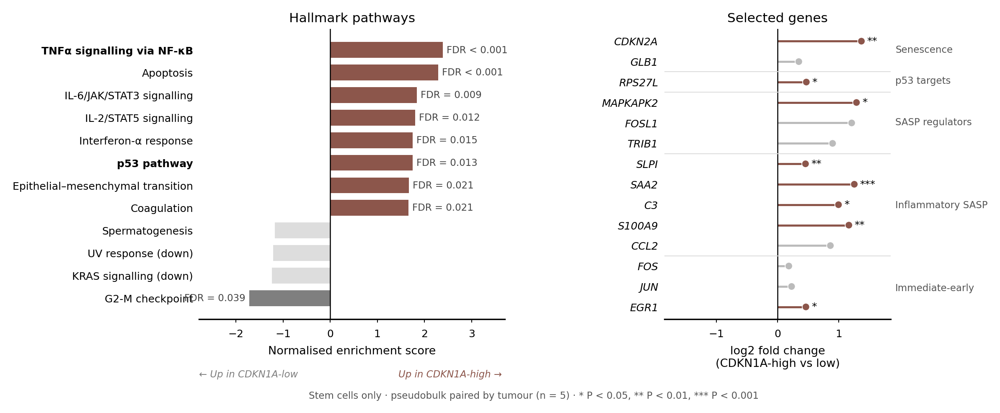

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
split_mode   = "global_q90"           # "detected": any CDKN1A vs none
                                      # "global_q90": top 10% of stem cells by CDKN1A vs none detected
                                      # "tumour_q90": top 10% within each tumour vs none detected
q_high       = 0.90
min_high     = 5                      # min CDKN1A-high cells per tumour (fewer cells pass a strict cut-off)
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.0)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
if split_mode == "detected":
    grp_ = np.where(cdkn1a > 0, "high", "low")
else:
    # stricter: "high" = top 10% of CDKN1A expression; "low" = CDKN1A not detected;
    # cells in between (detected but below the cut-off) are left out
    grp_ = np.full(len(cdkn1a), "mid", dtype=object)
    grp_[cdkn1a == 0] = "low"
    if split_mode == "global_q90":
        thr = np.quantile(cdkn1a, q_high)
        thr = max(thr, np.min(cdkn1a[cdkn1a > 0]))      # never call an undetected cell "high"
        grp_[cdkn1a >= thr] = "high"
        print(f"Global {int(q_high * 100)}th percentile of CDKN1A in stem cells: {thr:.3f}")
    else:
        sid_ = stem.obs[sample_col].astype(str).to_numpy()
        for s_ in np.unique(sid_):
            m = sid_ == s_
            v = cdkn1a[m]
            if (v > 0).any():
                thr = max(np.quantile(v, q_high), v[v > 0].min())
                grp_[m & (cdkn1a >= thr)] = "high"
stem.obs["CDKN1A_group"] = grp_
print("Cells per group:", pd.Series(grp_).value_counts().to_dict())
stem = stem[stem.obs["CDKN1A_group"] != "mid"].copy()
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_high) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_high} high and >= {min_cells} low cells: {len(keep)}")
if len(keep) < 5:
    print("WARNING: fewer than 5 tumours - treat as a sensitivity analysis, not the main result")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + (0.08 if v > 0 else -0.08), yi, txt, va="center",
                 ha="left" if v > 0 else "right", fontsize=fs["small"] - 0.5, color="#444444")
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(-lim * 0.75, lim)
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Global 90th percentile of CDKN1A in stem cells: 1.494
Cells per group: {'low': 943, 'mid': 184, 'high': 126}
CDKN1A_group  high  low
SRA_ID                 
HRS488982       38   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
SRX14605703      1  426
SRX16175537     16   70
SRX21219339      7   14
SRX21219341      1    2
SRX21219343      0    7
SRX28461022      3   98 

Tumours with >= 5 high and >= 10 low cells: 5

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 0
          log2FoldChange  pvalue    padj
S100A2            1.6689  0.0000  0.1175
TACSTD2           1.1167  0.0003  0.5604
SAA2              1.2549  0.0007  0.9026
GADD45B           1.0086  0.0013  0.9995
MT-ND4           -0.7739  0.0032  0.9995
CLIC4             1.0105  0.0040  0.9995
SLPI              0.4570  0.0045  0.9995
CDKN2A            1.3710  0.0065  0.9995
S100A9            1.1659  0.0067  0.9995
KLF6            

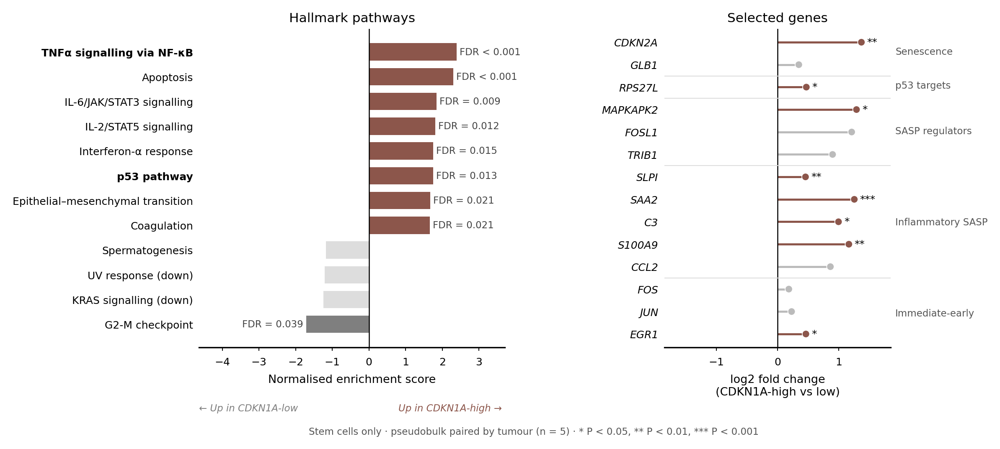

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
split_mode   = "global_q90"           # "detected": any CDKN1A vs none
                                      # "global_q90": top 10% of stem cells by CDKN1A vs none detected
                                      # "tumour_q90": top 10% within each tumour vs none detected
q_high       = 0.90
min_high     = 5                      # min CDKN1A-high cells per tumour (fewer cells pass a strict cut-off)
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.3)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Proliferation",     ["MKI67", "TOP2A", "CCNB1", "CDK1"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
if split_mode == "detected":
    grp_ = np.where(cdkn1a > 0, "high", "low")
else:
    # stricter: "high" = top 10% of CDKN1A expression; "low" = CDKN1A not detected;
    # cells in between (detected but below the cut-off) are left out
    grp_ = np.full(len(cdkn1a), "mid", dtype=object)
    grp_[cdkn1a == 0] = "low"
    if split_mode == "global_q90":
        thr = np.quantile(cdkn1a, q_high)
        thr = max(thr, np.min(cdkn1a[cdkn1a > 0]))      # never call an undetected cell "high"
        grp_[cdkn1a >= thr] = "high"
        print(f"Global {int(q_high * 100)}th percentile of CDKN1A in stem cells: {thr:.3f}")
    else:
        sid_ = stem.obs[sample_col].astype(str).to_numpy()
        for s_ in np.unique(sid_):
            m = sid_ == s_
            v = cdkn1a[m]
            if (v > 0).any():
                thr = max(np.quantile(v, q_high), v[v > 0].min())
                grp_[m & (cdkn1a >= thr)] = "high"
stem.obs["CDKN1A_group"] = grp_
print("Cells per group:", pd.Series(grp_).value_counts().to_dict())
stem = stem[stem.obs["CDKN1A_group"] != "mid"].copy()
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_high) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_high} high and >= {min_cells} low cells: {len(keep)}")
if len(keep) < 5:
    print("WARNING: fewer than 5 tumours - treat as a sensitivity analysis, not the main result")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + (0.08 if v > 0 else -0.08), yi, txt, va="center",
                 ha="left" if v > 0 else "right", fontsize=fs["small"] - 0.5, color="#444444")
lim = np.abs(show["NES"]).max() * 1.55
neg_sig = ((show["NES"] < 0) & (show["FDR"] < 0.05)).any()
ax1.set_xlim(-lim * (1.25 if neg_sig else 0.75), lim)    # room for FDR labels on negative bars
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Stem cells: 1253
CDKN1A cut-off (top 10%): 1.494; {'CDKN1A-low': 943, 'Intermediate': 184, 'CDKN1A-high': 126}

Proliferation (stem cells):
  MKI67 CDKN1A-low: 6 / 943 (0.6%)
  MKI67 CDKN1A-high: 0 / 126 (0.0%)
  TOP2A CDKN1A-low: 12 / 943 (1.3%)
  TOP2A CDKN1A-high: 0 / 126 (0.0%)


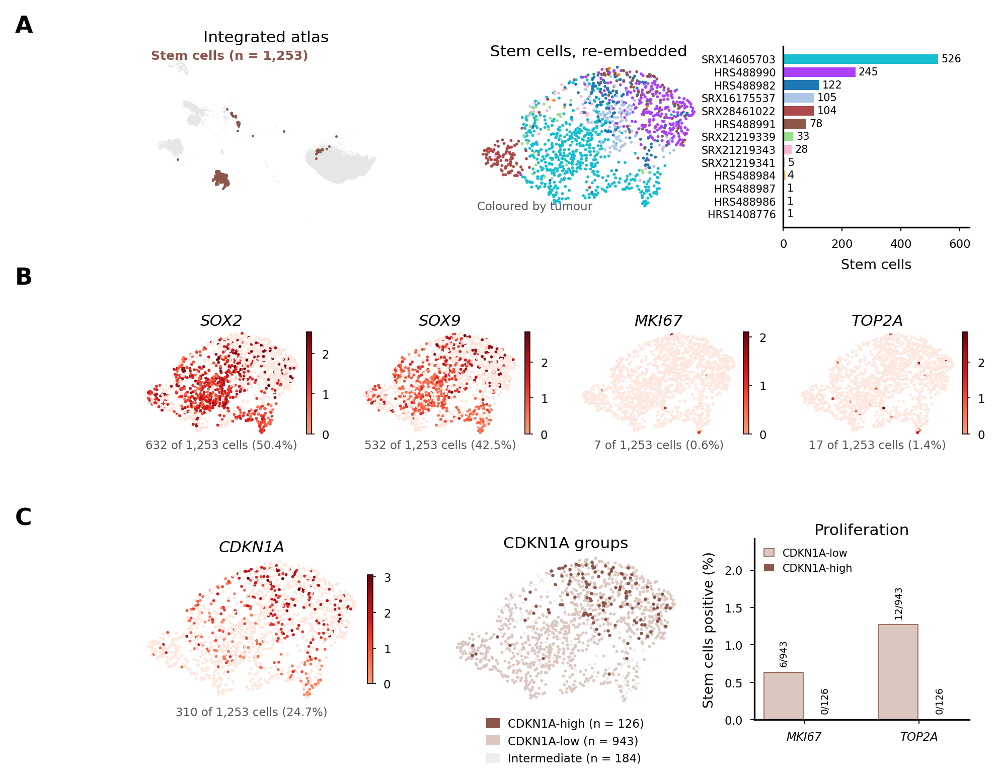


Stem cells per tumour:
 SRA_ID
SRX14605703    526
HRS488990      245
HRS488982      122
SRX16175537    105
SRX28461022    104
HRS488991       78
SRX21219339     33
SRX21219343     28
SRX21219341      5
HRS488984        4
HRS488986        1
HRS1408776       1
HRS488987        1
SOX2: 632 / 1253 (50.4%)
SOX9: 532 / 1253 (42.5%)
MKI67: 7 / 1253 (0.6%)
TOP2A: 17 / 1253 (1.4%)
CDKN1A: 310 / 1253 (24.7%)


In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Supplementary Figure 2: the stem cell compartment, in the Figure 2 style.
#   A  stem cells in the atlas | stem cells re-embedded, by tumour | stem cells per tumour
#   B  SOX2, SOX9 (identity)   | MKI67, TOP2A (proliferation)
#   C  CDKN1A expression       | CDKN1A-high / -low split

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
use_raw    = adata.raw is not None
fig_w      = 7.1                                   # inches (180 mm)
fs         = {"title": 7.5, "label": 6.5, "small": 6, "letter": 11}
stem_col   = "#8c564b"
split_cols = {"CDKN1A-low": "#DCC7C0", "CDKN1A-high": "#8c564b", "Intermediate": "#EEEEEE"}
q_high     = 0.90      # CDKN1A-high = top 10% of stem cells (as in Fig. 2E); low = not detected
reuse_umap = None    # e.g. "X_umap_stem" if your stem object already has its own UMAP

aliases = {"CCN2": "CTGF"}

# ---- 2. Stem cell subset and its own UMAP -----------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
if reuse_umap and reuse_umap in stem.obsm:
    stem.obsm["X_umap_stem"] = stem.obsm[reuse_umap]
else:
    sc.pp.neighbors(stem, use_rep="X_scVI", n_neighbors=15, random_state=0)
    sc.tl.umap(stem, random_state=0)
    stem.obsm["X_umap_stem"] = stem.obsm["X_umap"].copy()
sxy = stem.obsm["X_umap_stem"]
print(f"Stem cells: {stem.n_obs}")

vn = stem.raw.var_names if use_raw else stem.var_names
def gname(g):
    return g if g in vn else aliases.get(g, g)
def expr(g):
    return sc.get.obs_df(stem, keys=[gname(g)], use_raw=use_raw)[gname(g)].to_numpy(dtype=float)

cdkn1a = expr("CDKN1A")
thr = max(np.quantile(cdkn1a, q_high), cdkn1a[cdkn1a > 0].min())
stem.obs["CDKN1A_group"] = np.select([cdkn1a >= thr, cdkn1a == 0], ["CDKN1A-high", "CDKN1A-low"],
                                     default="Intermediate")
print(f"CDKN1A cut-off (top {int(round((1 - q_high) * 100))}%): {thr:.3f};",
      stem.obs["CDKN1A_group"].value_counts().to_dict())

# sample colours: reuse the atlas palette if stored, otherwise tab20
samples = stem.obs[sample_col].astype(str)
cats = list(adata.obs[sample_col].astype("category").cat.categories)
if f"{sample_col}_colors" in adata.uns and len(adata.uns[f"{sample_col}_colors"]) == len(cats):
    s_pal = dict(zip(cats, adata.uns[f"{sample_col}_colors"]))
else:
    s_pal = {s: plt.get_cmap("tab20")(i % 20) for i, s in enumerate(cats)}
counts = samples.value_counts()
counts = counts[counts > 0].sort_values()

# expression colour map: palest = not detected (as in Fig. 2C/D)
reds = plt.get_cmap("Reds")(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])
order = np.random.default_rng(0).permutation(stem.n_obs)

def clean(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    for sp in ax.spines.values():
        sp.set_visible(False)

def gene_umap(ax, g, cax=None):
    v = expr(g)
    vmax = np.percentile(v[v > 0], 99) if (v > 0).any() else 1
    im = ax.scatter(sxy[order, 0], sxy[order, 1], c=v[order], s=2, cmap=pop_cmap, vmin=0,
                    vmax=vmax, linewidths=0, rasterized=True)
    n = int((v > 0).sum())
    ax.set_title(f"{g}", fontsize=fs["title"], fontstyle="italic", pad=1)
    ax.text(0.5, -0.02, f"{n:,} of {len(v):,} cells ({n / len(v) * 100:.1f}%)", transform=ax.transAxes,
            ha="center", va="top", fontsize=fs["small"] - 0.5, color="#555555")
    clean(ax)
    cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.01, shrink=0.6)
    cb.ax.tick_params(labelsize=fs["small"] - 0.5, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    return v

# ---- 3. Figure layout ---------------------------------------------------------
fig = plt.figure(figsize=(fig_w, 5.8), dpi=300)
outer = GridSpec(3, 1, figure=fig, height_ratios=[0.8, 0.75, 0.8], hspace=0.4)

# Row A
gA = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[0], width_ratios=[1.1, 1, 0.8], wspace=0.35)
a1, a2, a3 = (fig.add_subplot(gA[i]) for i in range(3))
axy = adata.obsm["X_umap"]
is_stem = ct == "Stem cells"
a1.scatter(axy[~is_stem, 0], axy[~is_stem, 1], s=0.3, color="#E6E6E6", linewidths=0, rasterized=True)
a1.scatter(axy[is_stem, 0], axy[is_stem, 1], s=1.5, color=stem_col, linewidths=0, rasterized=True)
a1.set_title("Integrated atlas", fontsize=fs["title"], pad=2)
a1.text(0.02, 0.98, f"Stem cells (n = {is_stem.sum():,})", transform=a1.transAxes, va="top",
        fontsize=fs["small"], color=stem_col, fontweight="bold")
clean(a1)

a2.scatter(sxy[order, 0], sxy[order, 1], s=2, c=[s_pal[s] for s in samples.iloc[order]],
           linewidths=0, rasterized=True)
a2.set_title("Stem cells, re-embedded", fontsize=fs["title"], pad=2)
a2.text(0.02, 0.02, "Coloured by tumour", transform=a2.transAxes, fontsize=fs["small"] - 0.5, color="#555555")
clean(a2)

a3.barh(range(len(counts)), counts.values, color=[s_pal[s] for s in counts.index], height=0.75)
a3.set_yticks(range(len(counts)))
a3.set_yticklabels(counts.index, fontsize=fs["small"] - 1)
for i, v in enumerate(counts.values):
    a3.text(v + counts.max() * 0.02, i, str(v), va="center", fontsize=fs["small"] - 1)
a3.set_xlabel("Stem cells", fontsize=fs["label"])
a3.set_xlim(0, counts.max() * 1.2)
a3.tick_params(axis="x", labelsize=fs["small"] - 0.5, length=2, width=0.5)
a3.tick_params(axis="y", length=0)
for sp in ("top", "right"):
    a3.spines[sp].set_visible(False)

# Row B
gB = GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[1], wspace=0.25)
for i, g in enumerate(["SOX2", "SOX9", "MKI67", "TOP2A"]):
    gene_umap(fig.add_subplot(gB[i]), g)

# Row C
gC = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[2], width_ratios=[1, 1, 0.9], wspace=0.3)
gene_umap(fig.add_subplot(gC[0]), "CDKN1A")
c2 = fig.add_subplot(gC[1])
grp = stem.obs["CDKN1A_group"].to_numpy()
for gg in ["Intermediate", "CDKN1A-low", "CDKN1A-high"]:   # high drawn on top
    m = grp == gg
    c2.scatter(sxy[m, 0], sxy[m, 1], s=2.5 if gg.endswith("high") else 2, color=split_cols[gg],
               linewidths=0, rasterized=True)
c2.set_title("CDKN1A groups", fontsize=fs["title"], pad=1)
clean(c2)
c2.legend(handles=[Patch(color=split_cols[k], label=f"{k} (n = {(grp == k).sum():,})")
                   for k in ["CDKN1A-high", "CDKN1A-low", "Intermediate"]],
          loc="upper center", bbox_to_anchor=(0.5, -0.0), frameon=False, fontsize=fs["small"] - 0.5,
          handlelength=1, ncol=1)

# Proliferation: % of MKI67+ / TOP2A+ stem cells in CDKN1A-low vs -high (bars, counts on top)
c3 = fig.add_subplot(gC[2])
prolif = {"MKI67": expr("MKI67") > 0, "TOP2A": expr("TOP2A") > 0}
xpos = {"CDKN1A-low": -0.18, "CDKN1A-high": 0.18}
for gi, (gname_, pos_) in enumerate(prolif.items()):
    for k, dx in xpos.items():
        m = grp == k
        pct = pos_[m].mean() * 100
        c3.bar(gi + dx, pct, width=0.34, color=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
               linewidth=0.4)
        c3.text(gi + dx, pct + 0.08, f"{pos_[m].sum()}/{m.sum()}", ha="center", va="bottom",
                fontsize=fs["small"] - 1.5, rotation=90)
c3.set_xticks(range(len(prolif)))
c3.set_xticklabels(list(prolif), fontsize=fs["small"], fontstyle="italic")
c3.set_ylabel("Stem cells positive (%)", fontsize=fs["label"])
top_ = max(pos_[grp == k].mean() * 100 for pos_ in prolif.values() for k in xpos)
c3.set_ylim(0, max(top_ * 1.9, 1))
c3.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
for sp in ("top", "right"):
    c3.spines[sp].set_visible(False)
c3.set_title("Proliferation", fontsize=fs["title"], pad=2)
c3.legend(handles=[Patch(facecolor=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
                         linewidth=0.4, label=k) for k in ["CDKN1A-low", "CDKN1A-high"]],
          loc="upper left", frameon=False, fontsize=fs["small"] - 1, handlelength=1)
print("\nProliferation (stem cells):")
for gname_, pos_ in prolif.items():
    for k in xpos:
        m = grp == k
        print(f"  {gname_} {k}: {pos_[m].sum()} / {m.sum()} ({pos_[m].mean() * 100:.1f}%)")

# panel letters
for i, letter in enumerate("ABC"):
    top = outer[i].get_position(fig).y1
    fig.text(0.01, top + 0.01, letter, fontsize=fs["letter"], fontweight="bold", va="bottom")

fig.savefig("SuppFig2_stem_cells.pdf", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.svg", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.png", dpi=600, bbox_inches="tight")
plt.show()

# numbers for the legend
print("\nStem cells per tumour:\n", counts.sort_values(ascending=False).to_string())
for g in ["SOX2", "SOX9", "MKI67", "TOP2A", "CDKN1A"]:
    v = expr(g)
    print(f"{g}: {(v > 0).sum()} / {len(v)} ({(v > 0).mean() * 100:.1f}%)")

Stem cells: 1253
CDKN1A cut-off (top 10%): 1.494; {'CDKN1A-low': 943, 'Intermediate': 184, 'CDKN1A-high': 126}

Proliferation (stem cells):
  MKI67 CDKN1A-low: 6 / 943 (0.6%)
  MKI67 CDKN1A-high: 0 / 126 (0.0%)
  TOP2A CDKN1A-low: 12 / 943 (1.3%)
  TOP2A CDKN1A-high: 0 / 126 (0.0%)


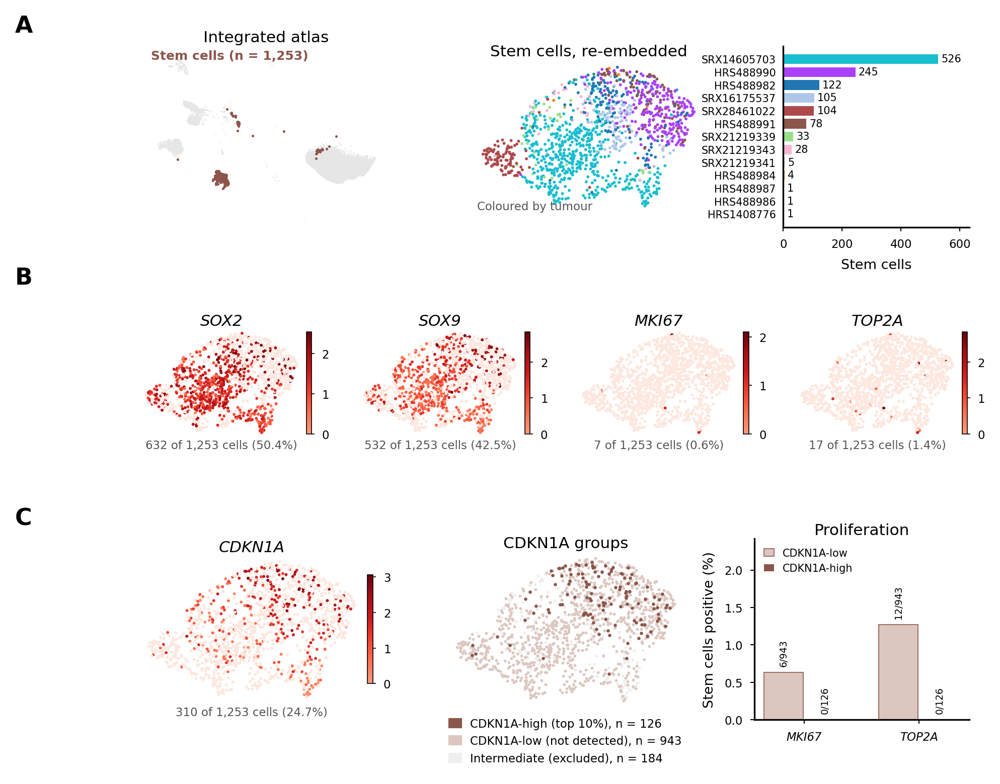


Stem cells per tumour:
 SRA_ID
SRX14605703    526
HRS488990      245
HRS488982      122
SRX16175537    105
SRX28461022    104
HRS488991       78
SRX21219339     33
SRX21219343     28
SRX21219341      5
HRS488984        4
HRS488986        1
HRS1408776       1
HRS488987        1
SOX2: 632 / 1253 (50.4%)
SOX9: 532 / 1253 (42.5%)
MKI67: 7 / 1253 (0.6%)
TOP2A: 17 / 1253 (1.4%)
CDKN1A: 310 / 1253 (24.7%)


In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Supplementary Figure 2: the stem cell compartment, in the Figure 2 style.
#   A  stem cells in the atlas | stem cells re-embedded, by tumour | stem cells per tumour
#   B  SOX2, SOX9 (identity)   | MKI67, TOP2A (proliferation)
#   C  CDKN1A expression       | CDKN1A-high / -low split

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
use_raw    = adata.raw is not None
fig_w      = 7.1                                   # inches (180 mm)
fs         = {"title": 7.5, "label": 6.5, "small": 6, "letter": 11}
stem_col   = "#8c564b"
split_cols = {"CDKN1A-low": "#DCC7C0", "CDKN1A-high": "#8c564b", "Intermediate": "#EEEEEE"}
q_high     = 0.90      # CDKN1A-high = top 10% of stem cells (as in Fig. 2E); low = not detected
reuse_umap = None    # e.g. "X_umap_stem" if your stem object already has its own UMAP

aliases = {"CCN2": "CTGF"}

# ---- 2. Stem cell subset and its own UMAP -----------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
if reuse_umap and reuse_umap in stem.obsm:
    stem.obsm["X_umap_stem"] = stem.obsm[reuse_umap]
else:
    sc.pp.neighbors(stem, use_rep="X_scVI", n_neighbors=15, random_state=0)
    sc.tl.umap(stem, random_state=0)
    stem.obsm["X_umap_stem"] = stem.obsm["X_umap"].copy()
sxy = stem.obsm["X_umap_stem"]
print(f"Stem cells: {stem.n_obs}")

vn = stem.raw.var_names if use_raw else stem.var_names
def gname(g):
    return g if g in vn else aliases.get(g, g)
def expr(g):
    return sc.get.obs_df(stem, keys=[gname(g)], use_raw=use_raw)[gname(g)].to_numpy(dtype=float)

cdkn1a = expr("CDKN1A")
thr = max(np.quantile(cdkn1a, q_high), cdkn1a[cdkn1a > 0].min())
stem.obs["CDKN1A_group"] = np.select([cdkn1a >= thr, cdkn1a == 0], ["CDKN1A-high", "CDKN1A-low"],
                                     default="Intermediate")
print(f"CDKN1A cut-off (top {int(round((1 - q_high) * 100))}%): {thr:.3f};",
      stem.obs["CDKN1A_group"].value_counts().to_dict())

# sample colours: reuse the atlas palette if stored, otherwise tab20
samples = stem.obs[sample_col].astype(str)
cats = list(adata.obs[sample_col].astype("category").cat.categories)
if f"{sample_col}_colors" in adata.uns and len(adata.uns[f"{sample_col}_colors"]) == len(cats):
    s_pal = dict(zip(cats, adata.uns[f"{sample_col}_colors"]))
else:
    s_pal = {s: plt.get_cmap("tab20")(i % 20) for i, s in enumerate(cats)}
counts = samples.value_counts()
counts = counts[counts > 0].sort_values()

# expression colour map: palest = not detected (as in Fig. 2C/D)
reds = plt.get_cmap("Reds")(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])
order = np.random.default_rng(0).permutation(stem.n_obs)

def clean(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    for sp in ax.spines.values():
        sp.set_visible(False)

def gene_umap(ax, g, cax=None):
    v = expr(g)
    vmax = np.percentile(v[v > 0], 99) if (v > 0).any() else 1
    im = ax.scatter(sxy[order, 0], sxy[order, 1], c=v[order], s=2, cmap=pop_cmap, vmin=0,
                    vmax=vmax, linewidths=0, rasterized=True)
    n = int((v > 0).sum())
    ax.set_title(f"{g}", fontsize=fs["title"], fontstyle="italic", pad=1)
    ax.text(0.5, -0.02, f"{n:,} of {len(v):,} cells ({n / len(v) * 100:.1f}%)", transform=ax.transAxes,
            ha="center", va="top", fontsize=fs["small"] - 0.5, color="#555555")
    clean(ax)
    cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.01, shrink=0.6)
    cb.ax.tick_params(labelsize=fs["small"] - 0.5, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    return v

# ---- 3. Figure layout ---------------------------------------------------------
fig = plt.figure(figsize=(fig_w, 5.8), dpi=300)
outer = GridSpec(3, 1, figure=fig, height_ratios=[0.8, 0.75, 0.8], hspace=0.4)

# Row A
gA = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[0], width_ratios=[1.1, 1, 0.8], wspace=0.35)
a1, a2, a3 = (fig.add_subplot(gA[i]) for i in range(3))
axy = adata.obsm["X_umap"]
is_stem = ct == "Stem cells"
a1.scatter(axy[~is_stem, 0], axy[~is_stem, 1], s=0.3, color="#E6E6E6", linewidths=0, rasterized=True)
a1.scatter(axy[is_stem, 0], axy[is_stem, 1], s=1.5, color=stem_col, linewidths=0, rasterized=True)
a1.set_title("Integrated atlas", fontsize=fs["title"], pad=2)
a1.text(0.02, 0.98, f"Stem cells (n = {is_stem.sum():,})", transform=a1.transAxes, va="top",
        fontsize=fs["small"], color=stem_col, fontweight="bold")
clean(a1)

a2.scatter(sxy[order, 0], sxy[order, 1], s=2, c=[s_pal[s] for s in samples.iloc[order]],
           linewidths=0, rasterized=True)
a2.set_title("Stem cells, re-embedded", fontsize=fs["title"], pad=2)
a2.text(0.02, 0.02, "Coloured by tumour", transform=a2.transAxes, fontsize=fs["small"] - 0.5, color="#555555")
clean(a2)

a3.barh(range(len(counts)), counts.values, color=[s_pal[s] for s in counts.index], height=0.75)
a3.set_yticks(range(len(counts)))
a3.set_yticklabels(counts.index, fontsize=fs["small"] - 1)
for i, v in enumerate(counts.values):
    a3.text(v + counts.max() * 0.02, i, str(v), va="center", fontsize=fs["small"] - 1)
a3.set_xlabel("Stem cells", fontsize=fs["label"])
a3.set_xlim(0, counts.max() * 1.2)
a3.tick_params(axis="x", labelsize=fs["small"] - 0.5, length=2, width=0.5)
a3.tick_params(axis="y", length=0)
for sp in ("top", "right"):
    a3.spines[sp].set_visible(False)

# Row B
gB = GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[1], wspace=0.25)
for i, g in enumerate(["SOX2", "SOX9", "MKI67", "TOP2A"]):
    gene_umap(fig.add_subplot(gB[i]), g)

# Row C
gC = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[2], width_ratios=[1, 1, 0.9], wspace=0.3)
gene_umap(fig.add_subplot(gC[0]), "CDKN1A")
c2 = fig.add_subplot(gC[1])
grp = stem.obs["CDKN1A_group"].to_numpy()
for gg in ["Intermediate", "CDKN1A-low", "CDKN1A-high"]:   # high drawn on top
    m = grp == gg
    c2.scatter(sxy[m, 0], sxy[m, 1], s=2.5 if gg.endswith("high") else 2, color=split_cols[gg],
               linewidths=0, rasterized=True)
c2.set_title("CDKN1A groups", fontsize=fs["title"], pad=1)
clean(c2)
leg_lab = {"CDKN1A-high": "CDKN1A-high (top 10%)", "CDKN1A-low": "CDKN1A-low (not detected)",
           "Intermediate": "Intermediate (excluded)"}
c2.legend(handles=[Patch(color=split_cols[k], label=f"{leg_lab[k]}, n = {(grp == k).sum():,}")
                   for k in ["CDKN1A-high", "CDKN1A-low", "Intermediate"]],
          loc="upper center", bbox_to_anchor=(0.5, -0.0), frameon=False, fontsize=fs["small"] - 0.5,
          handlelength=1, ncol=1)

# Proliferation: % of MKI67+ / TOP2A+ stem cells in CDKN1A-low vs -high (bars, counts on top)
c3 = fig.add_subplot(gC[2])
prolif = {"MKI67": expr("MKI67") > 0, "TOP2A": expr("TOP2A") > 0}
xpos = {"CDKN1A-low": -0.18, "CDKN1A-high": 0.18}
for gi, (gname_, pos_) in enumerate(prolif.items()):
    for k, dx in xpos.items():
        m = grp == k
        pct = pos_[m].mean() * 100
        c3.bar(gi + dx, pct, width=0.34, color=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
               linewidth=0.4)
        c3.text(gi + dx, pct + 0.08, f"{pos_[m].sum()}/{m.sum()}", ha="center", va="bottom",
                fontsize=fs["small"] - 1.5, rotation=90)
c3.set_xticks(range(len(prolif)))
c3.set_xticklabels(list(prolif), fontsize=fs["small"], fontstyle="italic")
c3.set_ylabel("Stem cells positive (%)", fontsize=fs["label"])
top_ = max(pos_[grp == k].mean() * 100 for pos_ in prolif.values() for k in xpos)
c3.set_ylim(0, max(top_ * 1.9, 1))
c3.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
for sp in ("top", "right"):
    c3.spines[sp].set_visible(False)
c3.set_title("Proliferation", fontsize=fs["title"], pad=2)
c3.legend(handles=[Patch(facecolor=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
                         linewidth=0.4, label=k) for k in ["CDKN1A-low", "CDKN1A-high"]],
          loc="upper left", frameon=False, fontsize=fs["small"] - 1, handlelength=1)
print("\nProliferation (stem cells):")
for gname_, pos_ in prolif.items():
    for k in xpos:
        m = grp == k
        print(f"  {gname_} {k}: {pos_[m].sum()} / {m.sum()} ({pos_[m].mean() * 100:.1f}%)")

# panel letters
for i, letter in enumerate("ABC"):
    top = outer[i].get_position(fig).y1
    fig.text(0.01, top + 0.01, letter, fontsize=fs["letter"], fontweight="bold", va="bottom")

fig.savefig("SuppFig2_stem_cells.pdf", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.svg", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.png", dpi=600, bbox_inches="tight")
plt.show()

# numbers for the legend
print("\nStem cells per tumour:\n", counts.sort_values(ascending=False).to_string())
for g in ["SOX2", "SOX9", "MKI67", "TOP2A", "CDKN1A"]:
    v = expr(g)
    print(f"{g}: {(v > 0).sum()} / {len(v)} ({(v > 0).mean() * 100:.1f}%)")

Stem cells: 1253
CDKN1A cut-off (top 10%): 1.494; {'CDKN1A-low': 943, 'Intermediate': 184, 'CDKN1A-high': 126}

Proliferation (stem cells):
  MKI67 CDKN1A-low: 6 / 943 (0.6%)
  MKI67 CDKN1A-high: 0 / 126 (0.0%)
  TOP2A CDKN1A-low: 12 / 943 (1.3%)
  TOP2A CDKN1A-high: 0 / 126 (0.0%)


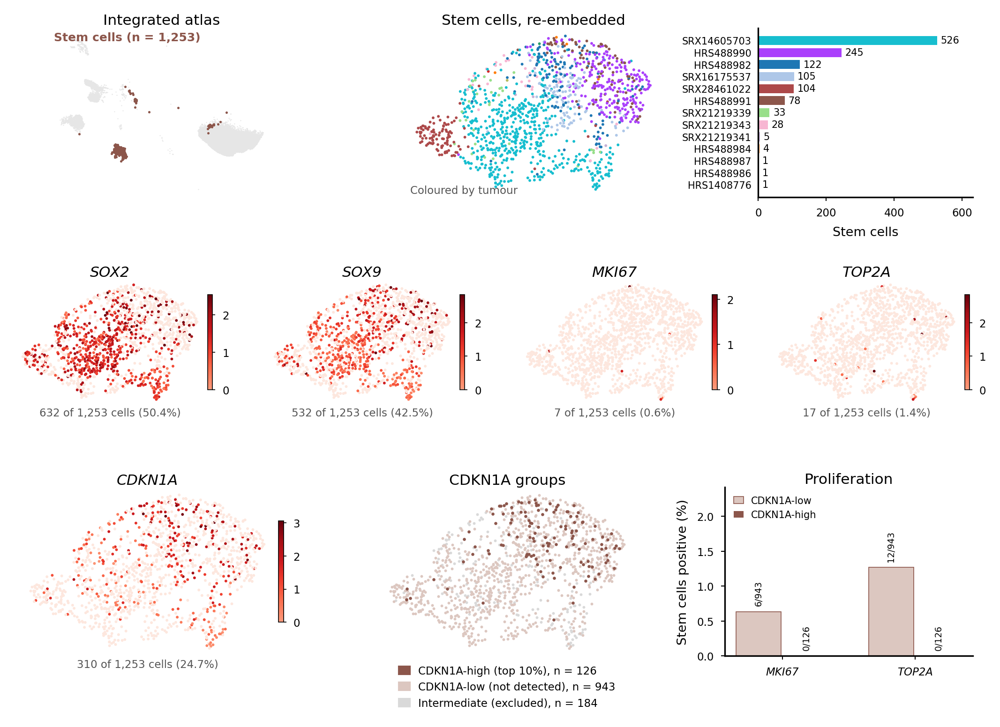


Stem cells per tumour:
 SRA_ID
SRX14605703    526
HRS488990      245
HRS488982      122
SRX16175537    105
SRX28461022    104
HRS488991       78
SRX21219339     33
SRX21219343     28
SRX21219341      5
HRS488984        4
HRS488986        1
HRS1408776       1
HRS488987        1
SOX2: 632 / 1253 (50.4%)
SOX9: 532 / 1253 (42.5%)
MKI67: 7 / 1253 (0.6%)
TOP2A: 17 / 1253 (1.4%)
CDKN1A: 310 / 1253 (24.7%)


In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Supplementary Figure 2: the stem cell compartment, in the Figure 2 style.
#   A  stem cells in the atlas | stem cells re-embedded, by tumour | stem cells per tumour
#   B  SOX2, SOX9 (identity)   | MKI67, TOP2A (proliferation)
#   C  CDKN1A expression       | CDKN1A-high / -low split

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
use_raw    = adata.raw is not None
fig_w      = 7.1                                   # inches (180 mm)
fs         = {"title": 7.5, "label": 6.5, "small": 6, "letter": 11}
stem_col   = "#8c564b"
split_cols = {"CDKN1A-low": "#DCC7C0", "CDKN1A-high": "#8c564b", "Intermediate": "#D9D9D9"}
q_high     = 0.90      # CDKN1A-high = top 10% of stem cells (as in Fig. 2E); low = not detected
reuse_umap = None    # e.g. "X_umap_stem" if your stem object already has its own UMAP

aliases = {"CCN2": "CTGF"}

# ---- 2. Stem cell subset and its own UMAP -----------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
if reuse_umap and reuse_umap in stem.obsm:
    stem.obsm["X_umap_stem"] = stem.obsm[reuse_umap]
else:
    sc.pp.neighbors(stem, use_rep="X_scVI", n_neighbors=15, random_state=0)
    sc.tl.umap(stem, random_state=0)
    stem.obsm["X_umap_stem"] = stem.obsm["X_umap"].copy()
sxy = stem.obsm["X_umap_stem"]
print(f"Stem cells: {stem.n_obs}")

vn = stem.raw.var_names if use_raw else stem.var_names
def gname(g):
    return g if g in vn else aliases.get(g, g)
def expr(g):
    return sc.get.obs_df(stem, keys=[gname(g)], use_raw=use_raw)[gname(g)].to_numpy(dtype=float)

cdkn1a = expr("CDKN1A")
thr = max(np.quantile(cdkn1a, q_high), cdkn1a[cdkn1a > 0].min())
stem.obs["CDKN1A_group"] = np.select([cdkn1a >= thr, cdkn1a == 0], ["CDKN1A-high", "CDKN1A-low"],
                                     default="Intermediate")
print(f"CDKN1A cut-off (top {int(round((1 - q_high) * 100))}%): {thr:.3f};",
      stem.obs["CDKN1A_group"].value_counts().to_dict())

# sample colours: reuse the atlas palette if stored, otherwise tab20
samples = stem.obs[sample_col].astype(str)
cats = list(adata.obs[sample_col].astype("category").cat.categories)
if f"{sample_col}_colors" in adata.uns and len(adata.uns[f"{sample_col}_colors"]) == len(cats):
    s_pal = dict(zip(cats, adata.uns[f"{sample_col}_colors"]))
else:
    s_pal = {s: plt.get_cmap("tab20")(i % 20) for i, s in enumerate(cats)}
counts = samples.value_counts()
counts = counts[counts > 0].sort_values()

# expression colour map: palest = not detected (as in Fig. 2C/D)
reds = plt.get_cmap("Reds")(np.linspace(0.35, 1.0, 255))
zero_col = "#FDE7DE"
pop_cmap = LinearSegmentedColormap.from_list(
    "pop", [(0.0, zero_col), (0.003, zero_col)] +
           [(0.004 + 0.996 * i / 254, tuple(reds[i])) for i in range(255)])
order = np.random.default_rng(0).permutation(stem.n_obs)

def clean(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    for sp in ax.spines.values():
        sp.set_visible(False)

def gene_umap(ax, g, cax=None):
    v = expr(g)
    vmax = np.percentile(v[v > 0], 99) if (v > 0).any() else 1
    im = ax.scatter(sxy[order, 0], sxy[order, 1], c=v[order], s=2, cmap=pop_cmap, vmin=0,
                    vmax=vmax, linewidths=0, rasterized=True)
    n = int((v > 0).sum())
    ax.set_title(f"{g}", fontsize=fs["title"], fontstyle="italic", pad=1)
    ax.text(0.5, -0.02, f"{n:,} of {len(v):,} cells ({n / len(v) * 100:.1f}%)", transform=ax.transAxes,
            ha="center", va="top", fontsize=fs["small"] - 0.5, color="#555555")
    clean(ax)
    cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.01, shrink=0.6)
    cb.ax.tick_params(labelsize=fs["small"] - 0.5, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    return v

# ---- 3. Figure layout ---------------------------------------------------------
fig = plt.figure(figsize=(fig_w, 5.8), dpi=300)
outer = GridSpec(3, 1, figure=fig, height_ratios=[0.8, 0.75, 0.8], hspace=0.4)

# Row A
gA = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[0], width_ratios=[1.1, 1, 0.8], wspace=0.35)
a1, a2, a3 = (fig.add_subplot(gA[i]) for i in range(3))
axy = adata.obsm["X_umap"]
is_stem = ct == "Stem cells"
a1.scatter(axy[~is_stem, 0], axy[~is_stem, 1], s=0.3, color="#E6E6E6", linewidths=0, rasterized=True)
a1.scatter(axy[is_stem, 0], axy[is_stem, 1], s=1.5, color=stem_col, linewidths=0, rasterized=True)
a1.set_title("Integrated atlas", fontsize=fs["title"], pad=2)
a1.text(0.02, 0.98, f"Stem cells (n = {is_stem.sum():,})", transform=a1.transAxes, va="top",
        fontsize=fs["small"], color=stem_col, fontweight="bold")
clean(a1)

a2.scatter(sxy[order, 0], sxy[order, 1], s=2, c=[s_pal[s] for s in samples.iloc[order]],
           linewidths=0, rasterized=True)
a2.set_title("Stem cells, re-embedded", fontsize=fs["title"], pad=2)
a2.text(0.02, 0.02, "Coloured by tumour", transform=a2.transAxes, fontsize=fs["small"] - 0.5, color="#555555")
clean(a2)

a3.barh(range(len(counts)), counts.values, color=[s_pal[s] for s in counts.index], height=0.75)
a3.set_yticks(range(len(counts)))
a3.set_yticklabels(counts.index, fontsize=fs["small"] - 1)
for i, v in enumerate(counts.values):
    a3.text(v + counts.max() * 0.02, i, str(v), va="center", fontsize=fs["small"] - 1)
a3.set_xlabel("Stem cells", fontsize=fs["label"])
a3.set_xlim(0, counts.max() * 1.2)
a3.tick_params(axis="x", labelsize=fs["small"] - 0.5, length=2, width=0.5)
a3.tick_params(axis="y", length=0)
for sp in ("top", "right"):
    a3.spines[sp].set_visible(False)

# Row B
gB = GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[1], wspace=0.25)
for i, g in enumerate(["SOX2", "SOX9", "MKI67", "TOP2A"]):
    gene_umap(fig.add_subplot(gB[i]), g)

# Row C
gC = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[2], width_ratios=[1, 1, 0.9], wspace=0.3)
gene_umap(fig.add_subplot(gC[0]), "CDKN1A")
c2 = fig.add_subplot(gC[1])
grp = stem.obs["CDKN1A_group"].to_numpy()
for gg in ["Intermediate", "CDKN1A-low", "CDKN1A-high"]:   # high drawn on top
    m = grp == gg
    c2.scatter(sxy[m, 0], sxy[m, 1], s=2.5 if gg.endswith("high") else 2, color=split_cols[gg],
               linewidths=0, rasterized=True)
c2.set_title("CDKN1A groups", fontsize=fs["title"], pad=1)
clean(c2)
leg_lab = {"CDKN1A-high": "CDKN1A-high (top 10%)", "CDKN1A-low": "CDKN1A-low (not detected)",
           "Intermediate": "Intermediate (excluded)"}
c2.legend(handles=[Patch(color=split_cols[k], label=f"{leg_lab[k]}, n = {(grp == k).sum():,}")
                   for k in ["CDKN1A-high", "CDKN1A-low", "Intermediate"]],
          loc="upper center", bbox_to_anchor=(0.5, -0.0), frameon=False, fontsize=fs["small"] - 0.5,
          handlelength=1, ncol=1)

# Proliferation: % of MKI67+ / TOP2A+ stem cells in CDKN1A-low vs -high (bars, counts on top)
c3 = fig.add_subplot(gC[2])
prolif = {"MKI67": expr("MKI67") > 0, "TOP2A": expr("TOP2A") > 0}
xpos = {"CDKN1A-low": -0.18, "CDKN1A-high": 0.18}
for gi, (gname_, pos_) in enumerate(prolif.items()):
    for k, dx in xpos.items():
        m = grp == k
        pct = pos_[m].mean() * 100
        c3.bar(gi + dx, pct, width=0.34, color=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
               linewidth=0.4)
        c3.text(gi + dx, pct + 0.08, f"{pos_[m].sum()}/{m.sum()}", ha="center", va="bottom",
                fontsize=fs["small"] - 1.5, rotation=90)
c3.set_xticks(range(len(prolif)))
c3.set_xticklabels(list(prolif), fontsize=fs["small"], fontstyle="italic")
c3.set_ylabel("Stem cells positive (%)", fontsize=fs["label"])
top_ = max(pos_[grp == k].mean() * 100 for pos_ in prolif.values() for k in xpos)
c3.set_ylim(0, max(top_ * 1.9, 1))
c3.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
for sp in ("top", "right"):
    c3.spines[sp].set_visible(False)
c3.set_title("Proliferation", fontsize=fs["title"], pad=2)
c3.legend(handles=[Patch(facecolor=split_cols[k], edgecolor="#8c564b" if k.endswith("low") else "none",
                         linewidth=0.4, label=k) for k in ["CDKN1A-low", "CDKN1A-high"]],
          loc="upper left", frameon=False, fontsize=fs["small"] - 1, handlelength=1)
print("\nProliferation (stem cells):")
for gname_, pos_ in prolif.items():
    for k in xpos:
        m = grp == k
        print(f"  {gname_} {k}: {pos_[m].sum()} / {m.sum()} ({pos_[m].mean() * 100:.1f}%)")

# no panel letters (added manually); trim the left margin
fig.subplots_adjust(left=0.02, right=0.98)

fig.savefig("SuppFig2_stem_cells.pdf", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.svg", bbox_inches="tight")
fig.savefig("SuppFig2_stem_cells.png", dpi=600, bbox_inches="tight")
plt.show()

# numbers for the legend
print("\nStem cells per tumour:\n", counts.sort_values(ascending=False).to_string())
for g in ["SOX2", "SOX9", "MKI67", "TOP2A", "CDKN1A"]:
    v = expr(g)
    print(f"{g}: {(v > 0).sum()} / {len(v)} ({(v > 0).mean() * 100:.1f}%)")

SenMayo: 125 of 126 genes found; scoring all cells...
col_0        SOX2+ stem  SOX2+ tumour  SOX2− tumour  % tumour cells SOX2+
row_0                                                                    
SRX14605703         413            63          4294                  1.45
SRX16175537          61            51          5741                  0.88
SRX28461022          43            26          4176                  0.62
HRS488990            31            14          4236                  0.33
HRS488982            27             8          3562                  0.22
SRX21219343          22            15          2540                  0.59
SRX21219339          20             8          1829                  0.44
HRS488991            10             5          4760                  0.10
SRX21219341           3            14          3914                  0.36
HRS488987             1             0           254                  0.00
HRS488984             1             0          4341       

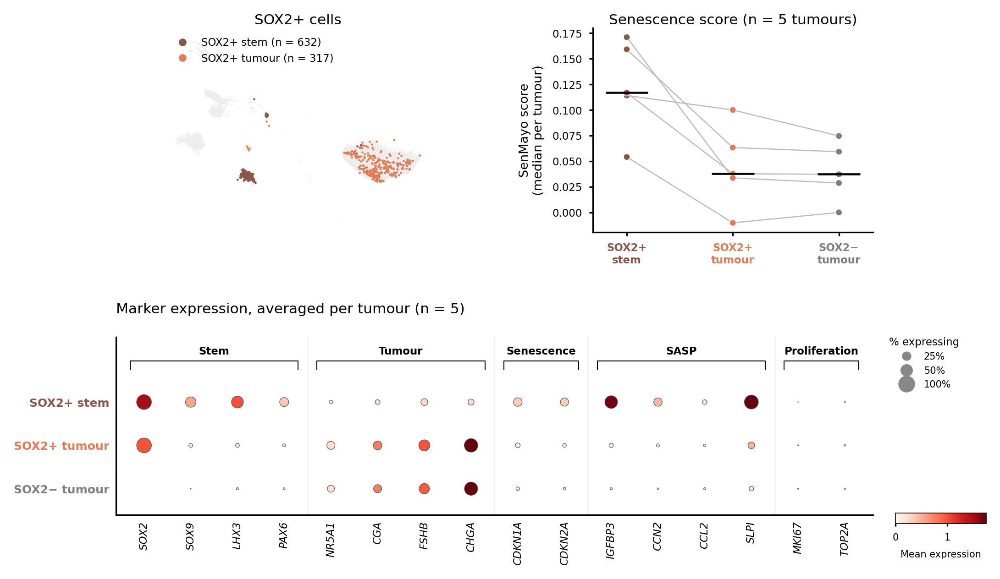

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon, ttest_rel

# =============================================================================
# SOX2+ cells in the TUMOUR cluster vs SOX2+ cells in the STEM cell cluster
#   1. How many SOX2+ tumour cells, per tumour; are they doublets?
#   2. Marker profile of SOX2+ stem, SOX2+ tumour and SOX2- tumour cells
#      (averaged per tumour, each tumour weighted equally)
#   3. SenMayo score per tumour in the three groups (paired)
#   4. Pseudobulk DE + Hallmark GSEA: SOX2+ tumour vs SOX2+ stem, paired by tumour
#   5. Figure: UMAP | SenMayo paired plot | marker dot plot
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
score_col    = "SenMayo_score"          # computed below if absent
doublet_col  = "doublet_score"
min_cells    = 10                       # per group per tumour for paired analyses
use_raw      = adata.raw is not None
groups = ["SOX2+ stem", "SOX2+ tumour", "SOX2− tumour"]
gcol   = {"SOX2+ stem": "#8c564b", "SOX2+ tumour": "#E07B54", "SOX2− tumour": "#7f7f7f"}
marker_groups = [
    ("Stem",           ["SOX2", "SOX9", "LHX3", "PAX6"]),
    ("Tumour",         ["NR5A1", "CGA", "FSHB", "CHGA"]),
    ("Senescence",     ["CDKN1A", "CDKN2A"]),
    ("SASP",           ["IGFBP3", "CCN2", "CCL2", "SLPI"]),
    ("Proliferation",  ["MKI67", "TOP2A"]),
]
aliases = {"CCN2": "CTGF"}
fs = {"title": 7.5, "label": 6.5, "small": 6}

# ---- 1b. SenMayo score (computed here if not already in adata.obs) -----------
# SenMayo gene set (Saul et al., Nat Commun 2022). Check against their Supplementary Data 1.
senmayo = ["ACVR1B", "ANG", "ANGPT1", "ANGPTL4", "AREG", "AXL", "BEX3", "BMP2", "BMP6", "C3", "CCL1",
           "CCL13", "CCL16", "CCL2", "CCL20", "CCL24", "CCL26", "CCL3", "CCL3L1", "CCL4", "CCL5", "CCL7",
           "CCL8", "CD55", "CD9", "CSF1", "CSF2", "CSF2RB", "CST4", "CTNNB1", "CTSB", "CXCL1", "CXCL10",
           "CXCL12", "CXCL16", "CXCL2", "CXCL3", "CXCL8", "CXCR2", "DKK1", "EDN1", "EGF", "EGFR", "EREG",
           "ESM1", "ETS2", "FAS", "FGF1", "FGF2", "FGF7", "GDF15", "GEM", "GMFG", "HGF", "HMGB1", "ICAM1",
           "ICAM3", "IGF1", "IGFBP1", "IGFBP2", "IGFBP3", "IGFBP4", "IGFBP5", "IGFBP6", "IGFBP7", "IL10",
           "IL13", "IL15", "IL18", "IL1A", "IL1B", "IL2", "IL32", "IL6", "IL6ST", "IL7", "INHA", "IQGAP2",
           "ITGA2", "ITPKA", "JUN", "KITLG", "LCP1", "MIF", "MMP1", "MMP10", "MMP12", "MMP13", "MMP14",
           "MMP2", "MMP3", "MMP9", "NAP1L4", "NRG1", "PAPPA", "PECAM1", "PGF", "PIGF", "PLAT", "PLAU",
           "PLAUR", "PTBP1", "PTGER2", "PTGES", "RPS6KA5", "SCAMP4", "SELPLG", "SEMA3F", "SERPINB3",
           "SERPINB4", "SERPINE1", "SERPINE2", "SPP1", "SPX", "TIMP2", "TNF", "TNFRSF10C", "TNFRSF11B",
           "TNFRSF1A", "TNFRSF1B", "TUBGCP2", "VEGFA", "VEGFC", "VGF", "WNT16", "WNT2"]
if score_col not in adata.obs:
    vn0 = adata.raw.var_names if use_raw else adata.var_names
    sm_genes = [g for g in senmayo if g in vn0]
    print(f"SenMayo: {len(sm_genes)} of {len(senmayo)} genes found; scoring all cells...")
    sc.tl.score_genes(adata, sm_genes, score_name=score_col, use_raw=use_raw, random_state=0)
else:
    print(f"Using existing {score_col}")

# ---- 2. Define the groups ------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells", "Pituicytes": "Tumour cells"}).to_numpy()
vn = adata.raw.var_names if use_raw else adata.var_names
sox2 = sc.get.obs_df(adata, keys=["SOX2"], use_raw=use_raw)["SOX2"].to_numpy() > 0
grp = np.full(adata.n_obs, "", dtype=object)
grp[(ct == "Stem cells") & sox2] = groups[0]
grp[(ct == "Tumour cells") & sox2] = groups[1]
grp[(ct == "Tumour cells") & ~sox2] = groups[2]
sid = adata.obs[sample_col].astype(str).to_numpy()

tab = pd.crosstab(sid[grp != ""], grp[grp != ""]).reindex(columns=groups, fill_value=0)
tab["% tumour cells SOX2+"] = (tab[groups[1]] / (tab[groups[1]] + tab[groups[2]]) * 100).round(2)
print(tab.sort_values(groups[0], ascending=False).to_string())
print(f"\nSOX2+ tumour cells: {(grp == groups[1]).sum():,} "
      f"({(grp == groups[1]).sum() / (ct == 'Tumour cells').sum() * 100:.1f}% of tumour cells); "
      f"SOX2+ stem cells: {(grp == groups[0]).sum():,}")

keep = tab.index[(tab[groups[0]] >= min_cells) & (tab[groups[1]] >= min_cells)].tolist()
print(f"Tumours with >= {min_cells} SOX2+ stem and >= {min_cells} SOX2+ tumour cells: {len(keep)}", keep)

# ---- 3. Doublet / quality check ----------------------------------------------
qc_cols = [c for c in [doublet_col, "n_genes_by_counts", "total_counts"] if c in adata.obs]
qc = adata.obs.loc[grp != "", qc_cols].apply(lambda c: pd.to_numeric(c.astype(str), errors="coerce"))
qc = qc.assign(group=grp[grp != ""], sid=sid[grp != ""])
qc = qc[qc["sid"].isin(keep)]
print("\nQC per group (median across tumours of per-tumour medians):")
print(qc.groupby(["sid", "group"])[qc_cols].median().groupby("group").median().reindex(groups).round(3).to_string())

# ---- 4. Marker profile, averaged per tumour ----------------------------------
genes, labels_, gpos = [], [], []
for name, gl in marker_groups:
    kept = [(g if g in vn else aliases.get(g, g)) for g in gl]
    kept = [g for g in kept if g in vn]
    if kept:
        gpos.append((name, len(genes), len(genes) + len(kept) - 1))
        genes += kept
        labels_ += ["CCN2 (CTGF)" if g == "CTGF" else g for g in kept]
E = sc.get.obs_df(adata, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
frac = np.zeros((len(groups), len(genes))); mean = np.zeros_like(frac)
for i, gname in enumerate(groups):
    f_t, m_t = [], []
    for t in keep:
        m = (grp == gname) & (sid == t)
        f_t.append((E[m] > 0).mean(0)); m_t.append(E[m].mean(0))
    frac[i], mean[i] = np.mean(f_t, 0), np.mean(m_t, 0)
prof = pd.DataFrame((frac * 100).round(1), index=groups, columns=labels_).T
print("\n% expressing (mean of per-tumour values):\n", prof.to_string())

# ---- 5. SenMayo per tumour -----------------------------------------------------
sm = None
if score_col in adata.obs:
    s_df = pd.DataFrame({"sid": sid, "group": grp, "score": pd.to_numeric(adata.obs[score_col].astype(str), errors="coerce").to_numpy()})
    sm = s_df[(s_df["group"] != "") & s_df["sid"].isin(keep)].groupby(["sid", "group"])["score"].median().unstack()[groups]
    print("\nSenMayo median per tumour:\n", sm.round(3).to_string())
    for a, b in [(groups[0], groups[1]), (groups[1], groups[2])]:
        print(f"{a} vs {b}: higher in {(sm[a] > sm[b]).sum()}/{len(sm)}; "
              f"paired Wilcoxon P = {wilcoxon(sm[a], sm[b]).pvalue:.3g}")

# ---- 6. Pseudobulk DE: SOX2+ tumour vs SOX2+ stem (paired by tumour) ----------
C = adata.layers[counts_layer]
rows, meta = [], []
for t in keep:
    for gname, short in [(groups[1], "tumour"), (groups[0], "stem")]:
        m = np.where((grp == gname) & (sid == t))[0]
        rows.append(np.asarray(C[m].sum(axis=0)).ravel())
        meta.append({"sample": f"{t}_{short}", "tumour": t, "group": short})
pb = pd.DataFrame(np.vstack(rows), columns=adata.var_names,
                  index=[m_["sample"] for m_ in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, len(keep) // 2)]
try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "tumour", "stem"], quiet=True); st.summary()
    res = st.results_df; method = "PyDESeq2"
except ImportError:
    lcpm = np.log2(pb.div(pb.sum(axis=1), axis=0) * 1e6 + 1)
    hi = lcpm.loc[[f"{t}_tumour" for t in keep]].to_numpy(); lo = lcpm.loc[[f"{t}_stem" for t in keep]].to_numpy()
    tt, pp = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"log2FoldChange": (hi - lo).mean(0), "stat": tt, "pvalue": pp}, index=lcpm.columns)
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("SOX2pos_tumour_vs_stem_pseudobulk.csv")
print(f"\nDE ({method}); positive log2FC = higher in SOX2+ tumour cells")
print("Up in SOX2+ tumour:\n", res[res["log2FoldChange"] > 0].head(20)[["log2FoldChange", "pvalue"]].round(4).to_string())
print("Up in SOX2+ stem:\n", res[res["log2FoldChange"] < 0].head(20)[["log2FoldChange", "pvalue"]].round(4).to_string())
try:
    import gseapy as gp
    pre = gp.prerank(rnk=res["stat"].dropna().sort_values(ascending=False), gene_sets="MSigDB_Hallmark_2020",
                     permutation_num=1000, min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
    gs = pre.res2d.sort_values("NES", ascending=False)
    gs.to_csv("SOX2pos_tumour_vs_stem_GSEA_hallmark.csv", index=False)
    print("\nHallmark GSEA (positive NES = enriched in SOX2+ tumour cells):")
    print(gs[["Term", "NES", "FDR q-val"]].head(8).to_string(index=False))
    print(gs[["Term", "NES", "FDR q-val"]].tail(8).to_string(index=False))
except Exception as e:
    print("GSEA skipped:", e)

# ---- 7. Figure -----------------------------------------------------------------
# top row: UMAP | SenMayo paired ; bottom row: dot plot (full width)
fig = plt.figure(figsize=(7.1, 4.6), dpi=300)
gsp = GridSpec(2, 2, figure=fig, width_ratios=[1.3, 1], height_ratios=[1.15, 1], wspace=0.35, hspace=0.55)

# (a) UMAP: SOX2+ cells by compartment
ax = fig.add_subplot(gsp[0, 0])
xy = adata.obsm["X_umap"]
ax.scatter(xy[:, 0], xy[:, 1], s=0.3, color="#EDEDED", linewidths=0, rasterized=True)
for gname in [groups[1], groups[0]]:
    m = grp == gname
    ax.scatter(xy[m, 0], xy[m, 1], s=1.2, color=gcol[gname], linewidths=0, rasterized=True)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("SOX2+ cells", fontsize=fs["title"], pad=2)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=gcol[g], markersize=3,
                          label=f"{g} (n = {(grp == g).sum():,})") for g in groups[:2]],
          loc="upper left", bbox_to_anchor=(0.0, 1.0), frameon=False, fontsize=fs["small"] - 0.5)

# (b) SenMayo paired
ax = fig.add_subplot(gsp[0, 1])
if sm is not None:
    for t, row in sm.iterrows():
        ax.plot(range(3), row[groups].to_numpy(), color="#BBBBBB", lw=0.6, zorder=1)
        ax.scatter(range(3), row[groups].to_numpy(), s=12, c=[gcol[g] for g in groups], zorder=2,
                   edgecolors="white", linewidths=0.4)
    for i, g in enumerate(groups):
        ax.hlines(sm[g].median(), i - 0.2, i + 0.2, color="black", lw=1.1, zorder=3)
    ax.set_xticks(range(3)); ax.set_xticklabels(["SOX2+\nstem", "SOX2+\ntumour", "SOX2\u2212\ntumour"],
                                                fontsize=fs["small"] - 0.5)
    for lab, g in zip(ax.get_xticklabels(), groups):
        lab.set_color(gcol[g]); lab.set_fontweight("bold")
    ax.set_ylabel("SenMayo score\n(median per tumour)", fontsize=fs["label"])
    ax.set_title(f"Senescence score (n = {len(sm)} tumours)", fontsize=fs["title"], pad=2)
    ax.tick_params(labelsize=fs["small"] - 0.5, length=2)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
else:
    ax.axis("off")

# (c) dot plot, groups x genes (full width)
ax = fig.add_subplot(gsp[1, :])
yy, xx = np.meshgrid(np.arange(len(groups)), np.arange(len(genes)), indexing="ij")
dots = ax.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                  vmin=0, vmax=np.percentile(mean, 95), edgecolors="#555555", linewidths=0.3)
ax.set_xticks(range(len(genes)))
ax.set_xticklabels(labels_, rotation=90, fontsize=fs["small"] - 0.5, fontstyle="italic")
ax.set_yticks(range(len(groups))); ax.set_yticklabels(groups, fontsize=fs["small"])
for lab, g in zip(ax.get_yticklabels(), groups):
    lab.set_color(gcol[g]); lab.set_fontweight("bold")
ax.set_xlim(-0.6, len(genes) - 0.4); ax.set_ylim(len(groups) - 0.4, -1.5)
for name, a, b in gpos:
    ax.plot([a - 0.3, a - 0.3, b + 0.3, b + 0.3], [-0.75, -0.95, -0.95, -0.75], color="black", lw=0.5)
    ax.text((a + b) / 2, -1.05, name, ha="center", va="bottom", fontsize=fs["small"] - 0.5, fontweight="bold")
    if a > 0:
        ax.axvline(a - 0.5, color="#EEEEEE", lw=0.6, zorder=0)
ax.tick_params(length=0)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.text(0.0, 1.12, f"Marker expression, averaged per tumour (n = {len(keep)})", transform=ax.transAxes,
        fontsize=fs["title"], ha="left", va="bottom")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                          label=f"{int(p_ * 100)}%") for p_ in (0.25, 0.5, 1.0)],
          title="% expressing", loc="upper left", bbox_to_anchor=(1.01, 1.05), frameon=False,
          fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5, labelspacing=0.5)
cax = ax.inset_axes([1.03, -0.05, 0.12, 0.06])
cb = fig.colorbar(dots, cax=cax, orientation="horizontal")
cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5)
cb.set_label("Mean expression", fontsize=fs["small"] - 1); cb.outline.set_linewidth(0.4)

fig.savefig("SOX2_tumour_vs_stem.pdf", bbox_inches="tight")
fig.savefig("SOX2_tumour_vs_stem.png", dpi=600, bbox_inches="tight")
plt.show()

In [36]:
%pip install liana

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 601.6/601.6 kB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 97.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 4.0 MB/s eta 0:00:00
  Created wheel for docrep: filename=docrep-0.3.2-py3-none-any.whl size=19973 sha256=b5e00fe8f2cc49c73c63645fbad934f5c023691aca697ecdb7aa079c83ca37c5
  Stored in directory: /root/.cache/pip/wheels/45/f2/42/d9ffbaceb3f12c063124529560e5a8b5ec85930e6f8ba5a017
Successfully built docrep
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.6
    Uninstalling pandas-3.0.6:
      Successfully uninstalled pandas-3.0.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pan

Cells per group: {'Tumour cells': 5000, 'Macrophages': 3035, 'Mesenchymal': 2540, 'Endothelial': 2000, 'Stem (CDKN1A-low)': 943, 'Monocytes': 424, 'T/NK cells': 332, 'Senescent stem': 126}

Significant SASP interactions from senescent stem cells (P < 0.05, expressed): 42
ligand    receptor          receiver  score     P  fold_vs_low_stem
 TIMP1        CD63       Mesenchymal 5.2204 0.001            1.2271
 TIMP1        CD63    Senescent stem 4.9720 0.001            1.2271
 TIMP1        CD63 Stem (CDKN1A-low) 4.7450 0.001            1.2271
 TIMP1        CD63       Macrophages 3.7970 0.001            1.2271
 TIMP1        CD63       Endothelial 3.7341 0.001            1.2271
   MIF       CXCR4        T/NK cells 2.6918 0.001            1.1417
 TIMP1        CD63         Monocytes 2.6624 0.019            1.2271
   MIF   CD74+CD44         Monocytes 2.5137 0.001            1.1417
   MIF       CXCR4         Monocytes 2.1392 0.001            1.1417
   MIF   CD74+CD44        T/NK cells 1.9412 0.00

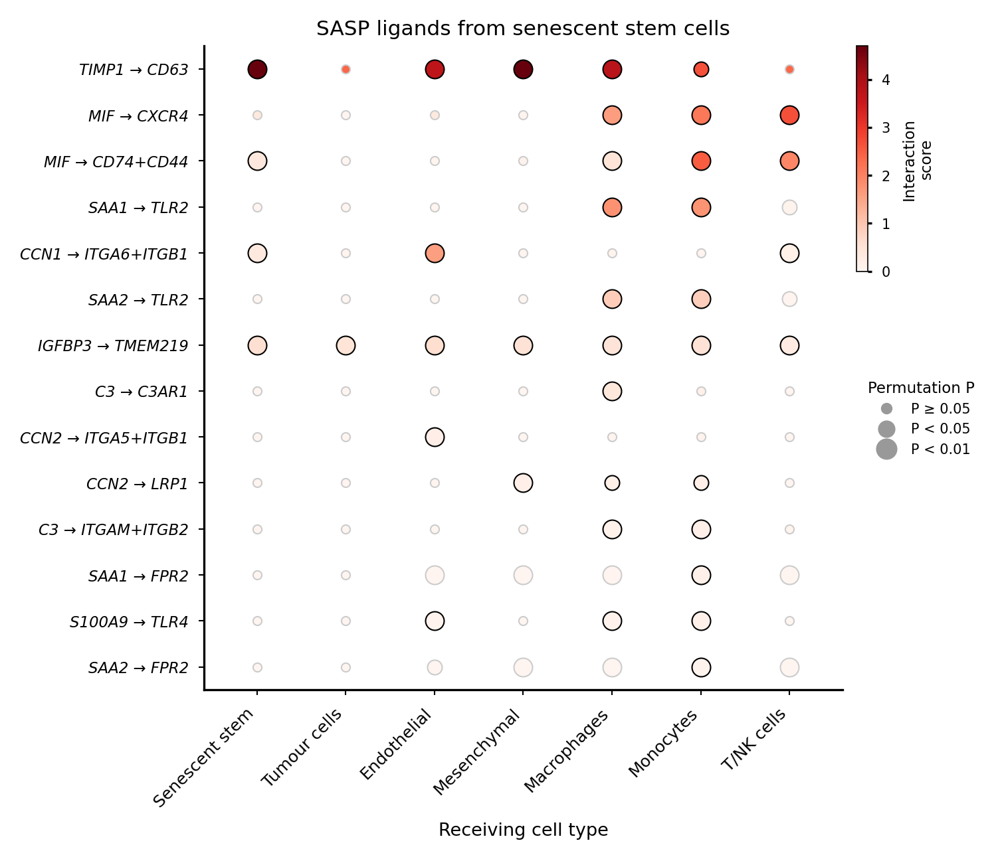

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

# =============================================================================
# Who receives the SASP?  Ligand-receptor inference WITHOUT LIANA (no extra packages).
# CellPhoneDB-style: score = mean ligand in sender x mean receptor in receiver
# (multi-subunit receptors use the lowest subunit); P value by permuting cell labels.
# Senders: senescent (CDKN1A-high) stem cells, compared with CDKN1A-low stem cells.
# Pairs: curated SASP ligand-receptor pairs (from CellPhoneDB / OmniPath).
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
q_high     = 0.90          # CDKN1A-high = top 10% of stem cells (as in Fig. 2E)
min_frac   = 0.10          # ligand / every receptor subunit detected in >= 10% of its group
n_perm     = 1000
max_per    = 5000          # downsample large groups for the permutations; None = all
seed       = 0
use_raw    = adata.raw is not None

pairs = [  # ligand, receptor (subunits joined by "+")
    ("CCL2", "CCR2"), ("CCL5", "CCR5"), ("CCL5", "CCR1"), ("CCL20", "CCR6"),
    ("CXCL1", "CXCR2"), ("CXCL2", "CXCR2"), ("CXCL8", "CXCR1"), ("CXCL8", "CXCR2"),
    ("CXCL10", "CXCR3"), ("CXCL12", "CXCR4"), ("CXCL12", "ACKR3"),
    ("IL6", "IL6R+IL6ST"), ("IL1A", "IL1R1+IL1RAP"), ("IL1B", "IL1R1+IL1RAP"),
    ("TNF", "TNFRSF1A"), ("TNF", "TNFRSF1B"), ("CSF1", "CSF1R"), ("IL15", "IL15RA+IL2RB"),
    ("SAA1", "FPR2"), ("SAA2", "FPR2"), ("SAA1", "TLR2"), ("SAA2", "TLR2"),
    ("S100A8", "TLR4"), ("S100A9", "TLR4"), ("S100A8", "AGER"), ("S100A9", "AGER"),
    ("C3", "C3AR1"), ("C3", "ITGAM+ITGB2"),
    ("IGFBP3", "TMEM219"), ("CCN2", "LRP1"), ("CCN2", "ITGAV+ITGB3"), ("CCN1", "ITGAV+ITGB3"),
    ("CCN2", "ITGA5+ITGB1"), ("CCN1", "ITGA6+ITGB1"),
    ("TGFB1", "TGFBR1+TGFBR2"), ("VEGFA", "KDR"), ("VEGFA", "FLT1"), ("VEGFA", "NRP1"),
    ("PGF", "FLT1"), ("FGF2", "FGFR1"), ("HGF", "MET"), ("AREG", "EGFR"), ("EREG", "EGFR"),
    ("GDF15", "GFRAL"), ("SPP1", "CD44"), ("SPP1", "ITGAV+ITGB1"), ("SERPINE1", "LRP1"),
    ("PLAU", "PLAUR"), ("MIF", "CD74+CD44"), ("MIF", "CXCR4"), ("ICAM1", "ITGAL+ITGB2"),
    ("FN1", "ITGA5+ITGB1"), ("TIMP1", "CD63"), ("BMP2", "BMPR1A+BMPR2"),
]
aliases = {"CCN2": "CTGF", "CCN1": "CYR61"}

# ---- 2. Groups -----------------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy().astype(object)
is_stem = ct == "Stem cells"
vn = adata.raw.var_names if use_raw else adata.var_names
g = lambda x: x if x in vn else aliases.get(x, x)
cdk = sc.get.obs_df(adata, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
thr = max(np.quantile(cdk[is_stem], q_high), cdk[is_stem & (cdk > 0)].min())
lab = ct.copy()
lab[is_stem & (cdk >= thr)] = "Senescent stem"
lab[is_stem & (cdk == 0)] = "Stem (CDKN1A-low)"
lab[is_stem & (cdk > 0) & (cdk < thr)] = "drop"

rng = np.random.default_rng(seed)
idx = []
for grp_ in pd.unique(lab):
    if grp_ == "drop":
        continue
    w = np.where(lab == grp_)[0]
    if max_per and len(w) > max_per:
        w = rng.choice(w, max_per, replace=False)
    idx.append(w)
idx = np.sort(np.concatenate(idx))
labs = lab[idx]
groups = [x for x in ["Senescent stem", "Stem (CDKN1A-low)", "Tumour cells", "Endothelial", "Mesenchymal",
                      "Macrophages", "Monocytes", "T/NK cells"] if x in set(labs)]
print("Cells per group:", pd.Series(labs).value_counts().to_dict())

# ---- 3. Expression of every gene in the pairs ---------------------------------
genes = sorted({g(x) for l, r in pairs for x in [l] + r.split("+")} & set(vn))
E = sc.get.obs_df(adata[idx], keys=genes, use_raw=use_raw)
E = E.to_numpy(dtype=float); gi = {x: i for i, x in enumerate(genes)}

def group_stats(labels_):
    M = np.vstack([E[labels_ == k].mean(0) for k in groups])          # groups x genes
    F = np.vstack([(E[labels_ == k] > 0).mean(0) for k in groups])
    return M, F

def score(M, F, l, r, s, t):
    if g(l) not in gi or any(g(x) not in gi for x in r.split("+")):
        return np.nan, False
    lm, lf = M[s, gi[g(l)]], F[s, gi[g(l)]]
    rm = min(M[t, gi[g(x)]] for x in r.split("+")); rf = min(F[t, gi[g(x)]] for x in r.split("+"))
    return lm * rm, (lf >= min_frac) and (rf >= min_frac)

M, F = group_stats(labs)
senders = [groups.index("Senescent stem"), groups.index("Stem (CDKN1A-low)")]
rows = []
for l, r in pairs:
    for s in senders:
        for t in range(len(groups)):
            sc_, ok = score(M, F, l, r, s, t)
            if np.isfinite(sc_):
                rows.append({"ligand": l, "receptor": r, "sender": groups[s], "receiver": groups[t],
                             "score": sc_, "expressed": ok})
res = pd.DataFrame(rows)

# ---- 4. Permutation P values (shuffle cell labels) ----------------------------
null_ge = np.zeros(len(res))
for _ in range(n_perm):
    Mp, Fp = group_stats(rng.permutation(labs))
    for k, row in enumerate(res.itertuples()):
        s, t = groups.index(row.sender), groups.index(row.receiver)
        null_ge[k] += score(Mp, Fp, row.ligand, row.receptor, s, t)[0] >= row.score
res["P"] = (null_ge + 1) / (n_perm + 1)

# senescent vs CDKN1A-low stem senders, same pair and receiver
piv = res.pivot_table(index=["ligand", "receptor", "receiver"], columns="sender", values="score")
res = res.merge(piv.rename(columns={"Senescent stem": "score_senescent",
                                    "Stem (CDKN1A-low)": "score_low_stem"}).reset_index(),
                on=["ligand", "receptor", "receiver"])
res["fold_vs_low_stem"] = (res["score_senescent"] + 1e-4) / (res["score_low_stem"] + 1e-4)
res.to_csv("SASP_ligand_receptor_all.csv", index=False)

sen = res[(res["sender"] == "Senescent stem") & res["expressed"] & (res["P"] < 0.05)]
sen = sen.sort_values("score", ascending=False)
sen.to_csv("SASP_ligand_receptor_senescent_significant.csv", index=False)
print(f"\nSignificant SASP interactions from senescent stem cells (P < 0.05, expressed): {len(sen)}")
print(sen[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].head(30)
      .round(4).to_string(index=False))
print("\nBy receiver:\n", sen["receiver"].value_counts().to_string())

# ---- 5. Plot ---------------------------------------------------------------------
receivers = [x for x in groups if x != "Stem (CDKN1A-low)"]
top = sen.drop_duplicates(["ligand", "receptor"]).head(20)
pairs_shown = list(zip(top["ligand"], top["receptor"]))
allsen = res[res["sender"] == "Senescent stem"].set_index(["ligand", "receptor", "receiver"])
vmax = sen["score"].quantile(0.95) if len(sen) else 1
fig, ax = plt.subplots(figsize=(4.4, 0.2 * max(len(pairs_shown), 3) + 1.4), dpi=300)
for i, (l, r) in enumerate(pairs_shown):
    for j, t in enumerate(receivers):
        if (l, r, t) not in allsen.index:
            continue
        row = allsen.loc[(l, r, t)]
        sig = row["expressed"] and row["P"] < 0.05
        size = 45 if row["P"] < 0.01 else 28 if row["P"] < 0.05 else 10
        ax.scatter(j, i, s=size, c=[row["score"]], cmap="Reds", vmin=0, vmax=vmax,
                   edgecolors="black" if sig else "#CCCCCC", linewidths=0.5)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([f"{l} → {r}" for l, r in pairs_shown], fontsize=5.5, fontstyle="italic")
ax.set_xticks(range(len(receivers)))
ax.set_xticklabels(receivers, rotation=45, ha="right", fontsize=6)
ax.set_xlim(-0.6, len(receivers) - 0.4); ax.set_ylim(len(pairs_shown) - 0.5, -0.5)
ax.set_xlabel("Receiving cell type", fontsize=6.5)
ax.set_title("SASP ligands from senescent stem cells", fontsize=7.5, pad=4)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.tick_params(length=2, width=0.5)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), ax=ax,
                  fraction=0.04, pad=0.02, shrink=0.35, anchor=(0, 1))
cb.set_label("Interaction\nscore", fontsize=5.5); cb.ax.tick_params(labelsize=5, length=1.5)
cb.outline.set_linewidth(0.4)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(s_), label=l_)
                   for s_, l_ in [(10, "P ≥ 0.05"), (28, "P < 0.05"), (45, "P < 0.01")]],
          title="Permutation P", loc="upper left", bbox_to_anchor=(1.02, 0.5), frameon=False,
          fontsize=5, title_fontsize=5.5)
fig.savefig("SASP_ligand_receptor.pdf", bbox_inches="tight")
fig.savefig("SASP_ligand_receptor.png", dpi=600, bbox_inches="tight")
plt.show()

Cells per group: {'Tumour cells': 5000, 'Macrophages': 3035, 'Mesenchymal': 2540, 'Endothelial': 2000, 'Stem (CDKN1A-low)': 943, 'Monocytes': 424, 'T/NK cells': 332, 'Senescent stem': 126}

Significant SASP interactions from senescent stem cells (P < 0.05, expressed): 42
ligand    receptor          receiver  score     P  fold_vs_low_stem
 TIMP1        CD63       Mesenchymal 5.2204 0.001            1.2271
 TIMP1        CD63    Senescent stem 4.9720 0.001            1.2271
 TIMP1        CD63 Stem (CDKN1A-low) 4.7450 0.001            1.2271
 TIMP1        CD63       Macrophages 3.7970 0.001            1.2271
 TIMP1        CD63       Endothelial 3.7341 0.001            1.2271
   MIF       CXCR4        T/NK cells 2.6918 0.001            1.1417
 TIMP1        CD63         Monocytes 2.6624 0.019            1.2271
   MIF   CD74+CD44         Monocytes 2.5137 0.001            1.1417
   MIF       CXCR4         Monocytes 2.1392 0.001            1.1417
   MIF   CD74+CD44        T/NK cells 1.9412 0.00

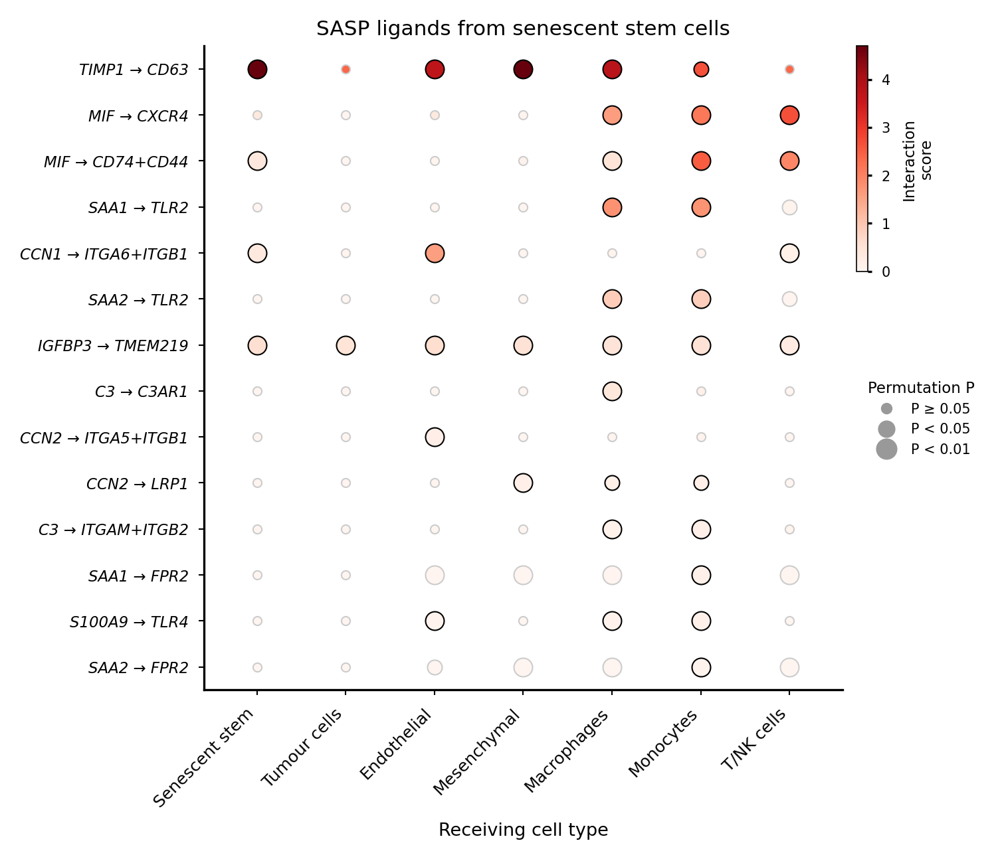

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

# =============================================================================
# Who receives the SASP?  HYPOTHESIS-DRIVEN ligand-receptor inference (curated SASP pairs).
# CellPhoneDB-style: score = mean ligand in sender x mean receptor in receiver
# (multi-subunit receptors use the lowest subunit); P value by permuting cell labels.
# Senders: senescent (CDKN1A-high) stem cells, compared with CDKN1A-low stem cells.
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
q_high     = 0.90          # CDKN1A-high = top 10% of stem cells (as in Fig. 2E)
min_frac   = 0.10          # ligand / every receptor subunit detected in >= 10% of its group
n_perm     = 1000
max_per    = 5000          # downsample large groups for the permutations; None = all
seed       = 0
use_raw    = adata.raw is not None

pairs = [  # ligand, receptor (subunits joined by "+")
    ("CCL2", "CCR2"), ("CCL5", "CCR5"), ("CCL5", "CCR1"), ("CCL20", "CCR6"),
    ("CXCL1", "CXCR2"), ("CXCL2", "CXCR2"), ("CXCL8", "CXCR1"), ("CXCL8", "CXCR2"),
    ("CXCL10", "CXCR3"), ("CXCL12", "CXCR4"), ("CXCL12", "ACKR3"),
    ("IL6", "IL6R+IL6ST"), ("IL1A", "IL1R1+IL1RAP"), ("IL1B", "IL1R1+IL1RAP"),
    ("TNF", "TNFRSF1A"), ("TNF", "TNFRSF1B"), ("CSF1", "CSF1R"), ("IL15", "IL15RA+IL2RB"),
    ("SAA1", "FPR2"), ("SAA2", "FPR2"), ("SAA1", "TLR2"), ("SAA2", "TLR2"),
    ("S100A8", "TLR4"), ("S100A9", "TLR4"), ("S100A8", "AGER"), ("S100A9", "AGER"),
    ("C3", "C3AR1"), ("C3", "ITGAM+ITGB2"),
    ("IGFBP3", "TMEM219"), ("CCN2", "LRP1"), ("CCN2", "ITGAV+ITGB3"), ("CCN1", "ITGAV+ITGB3"),
    ("CCN2", "ITGA5+ITGB1"), ("CCN1", "ITGA6+ITGB1"),
    ("TGFB1", "TGFBR1+TGFBR2"), ("VEGFA", "KDR"), ("VEGFA", "FLT1"), ("VEGFA", "NRP1"),
    ("PGF", "FLT1"), ("FGF2", "FGFR1"), ("HGF", "MET"), ("AREG", "EGFR"), ("EREG", "EGFR"),
    ("GDF15", "GFRAL"), ("SPP1", "CD44"), ("SPP1", "ITGAV+ITGB1"), ("SERPINE1", "LRP1"),
    ("PLAU", "PLAUR"), ("MIF", "CD74+CD44"), ("MIF", "CXCR4"), ("ICAM1", "ITGAL+ITGB2"),
    ("FN1", "ITGA5+ITGB1"), ("TIMP1", "CD63"), ("BMP2", "BMPR1A+BMPR2"),
]
aliases = {"CCN2": "CTGF", "CCN1": "CYR61"}

# ---- 2. Groups -----------------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy().astype(object)
is_stem = ct == "Stem cells"
vn = adata.raw.var_names if use_raw else adata.var_names
g = lambda x: x if x in vn else aliases.get(x, x)
cdk = sc.get.obs_df(adata, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
thr = max(np.quantile(cdk[is_stem], q_high), cdk[is_stem & (cdk > 0)].min())
lab = ct.copy()
lab[is_stem & (cdk >= thr)] = "Senescent stem"
lab[is_stem & (cdk == 0)] = "Stem (CDKN1A-low)"
lab[is_stem & (cdk > 0) & (cdk < thr)] = "drop"

rng = np.random.default_rng(seed)
idx = []
for grp_ in pd.unique(lab):
    if grp_ == "drop":
        continue
    w = np.where(lab == grp_)[0]
    if max_per and len(w) > max_per:
        w = rng.choice(w, max_per, replace=False)
    idx.append(w)
idx = np.sort(np.concatenate(idx))
labs = lab[idx]
groups = [x for x in ["Senescent stem", "Stem (CDKN1A-low)", "Tumour cells", "Endothelial", "Mesenchymal",
                      "Macrophages", "Monocytes", "T/NK cells"] if x in set(labs)]
print("Cells per group:", pd.Series(labs).value_counts().to_dict())

# ---- 3. Expression of every gene in the pairs ---------------------------------
genes = sorted({g(x) for l, r in pairs for x in [l] + r.split("+")} & set(vn))
E = sc.get.obs_df(adata[idx], keys=genes, use_raw=use_raw)
E = E.to_numpy(dtype=float); gi = {x: i for i, x in enumerate(genes)}

def group_stats(labels_):
    M = np.vstack([E[labels_ == k].mean(0) for k in groups])
    F = np.vstack([(E[labels_ == k] > 0).mean(0) for k in groups])
    return M, F

def score(M, F, l, r, s, t):
    if g(l) not in gi or any(g(x) not in gi for x in r.split("+")):
        return np.nan, False
    lm, lf = M[s, gi[g(l)]], F[s, gi[g(l)]]
    rm = min(M[t, gi[g(x)]] for x in r.split("+")); rf = min(F[t, gi[g(x)]] for x in r.split("+"))
    return lm * rm, (lf >= min_frac) and (rf >= min_frac)

M, F = group_stats(labs)
senders = [groups.index("Senescent stem"), groups.index("Stem (CDKN1A-low)")]
rows = []
for l, r in pairs:
    for s in senders:
        for t in range(len(groups)):
            sc_, ok = score(M, F, l, r, s, t)
            if np.isfinite(sc_):
                rows.append({"ligand": l, "receptor": r, "sender": groups[s], "receiver": groups[t],
                             "score": sc_, "expressed": ok})
res = pd.DataFrame(rows)

# ---- 4. Permutation P values (shuffle cell labels) ----------------------------
null_ge = np.zeros(len(res))
for _ in range(n_perm):
    Mp, Fp = group_stats(rng.permutation(labs))
    for k, row in enumerate(res.itertuples()):
        s, t = groups.index(row.sender), groups.index(row.receiver)
        null_ge[k] += score(Mp, Fp, row.ligand, row.receptor, s, t)[0] >= row.score
res["P"] = (null_ge + 1) / (n_perm + 1)

piv = res.pivot_table(index=["ligand", "receptor", "receiver"], columns="sender", values="score")
res = res.merge(piv.rename(columns={"Senescent stem": "score_senescent",
                                    "Stem (CDKN1A-low)": "score_low_stem"}).reset_index(),
                on=["ligand", "receptor", "receiver"])
res["fold_vs_low_stem"] = (res["score_senescent"] + 1e-4) / (res["score_low_stem"] + 1e-4)
res.to_csv("SASP_ligand_receptor_all.csv", index=False)

sen = res[(res["sender"] == "Senescent stem") & res["expressed"] & (res["P"] < 0.05)]
sen = sen.sort_values("score", ascending=False)
sen.to_csv("SASP_ligand_receptor_senescent_significant.csv", index=False)
print(f"\nSignificant SASP interactions from senescent stem cells (P < 0.05, expressed): {len(sen)}")
print(sen[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].head(30)
      .round(4).to_string(index=False))
print("\nBy receiver:\n", sen["receiver"].value_counts().to_string())

# ---- 5. Plot ---------------------------------------------------------------------
receivers = [x for x in groups if x != "Stem (CDKN1A-low)"]
top = sen.drop_duplicates(["ligand", "receptor"]).head(20)
pairs_shown = list(zip(top["ligand"], top["receptor"]))
allsen = res[res["sender"] == "Senescent stem"].set_index(["ligand", "receptor", "receiver"])
vmax = sen["score"].quantile(0.95) if len(sen) else 1
fig, ax = plt.subplots(figsize=(4.4, 0.2 * max(len(pairs_shown), 3) + 1.4), dpi=300)
for i, (l, r) in enumerate(pairs_shown):
    for j, t in enumerate(receivers):
        if (l, r, t) not in allsen.index:
            continue
        row = allsen.loc[(l, r, t)]
        sig = row["expressed"] and row["P"] < 0.05
        size = 45 if row["P"] < 0.01 else 28 if row["P"] < 0.05 else 10
        ax.scatter(j, i, s=size, c=[row["score"]], cmap="Reds", vmin=0, vmax=vmax,
                   edgecolors="black" if sig else "#CCCCCC", linewidths=0.5)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([f"{l} \u2192 {r}" for l, r in pairs_shown], fontsize=5.5, fontstyle="italic")
ax.set_xticks(range(len(receivers)))
ax.set_xticklabels(receivers, rotation=45, ha="right", fontsize=6)
ax.set_xlim(-0.6, len(receivers) - 0.4); ax.set_ylim(len(pairs_shown) - 0.5, -0.5)
ax.set_xlabel("Receiving cell type", fontsize=6.5)
ax.set_title("SASP ligands from senescent stem cells", fontsize=7.5, pad=4)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.tick_params(length=2, width=0.5)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), ax=ax,
                  fraction=0.04, pad=0.02, shrink=0.35, anchor=(0, 1))
cb.set_label("Interaction\nscore", fontsize=5.5); cb.ax.tick_params(labelsize=5, length=1.5)
cb.outline.set_linewidth(0.4)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(s_), label=l_)
                   for s_, l_ in [(10, "P \u2265 0.05"), (28, "P < 0.05"), (45, "P < 0.01")]],
          title="Permutation P", loc="upper left", bbox_to_anchor=(1.02, 0.5), frameon=False,
          fontsize=5, title_fontsize=5.5)
fig.savefig("SASP_ligand_receptor.pdf", bbox_inches="tight")
fig.savefig("SASP_ligand_receptor.png", dpi=600, bbox_inches="tight")
plt.show()

Database: 4,620 ligand-receptor pairs, 1,026 ligands
Pairs with all genes measured: 4,569; genes: 1,858
Senescent stem: 126 cells
Tumour cells: 94,737 cells
Endothelial: 2,000 cells
Mesenchymal: 2,540 cells
Macrophages: 3,035 cells
Monocytes: 424 cells
T/NK cells: 332 cells

Ligands expressed by senescent stem cells and tested: 168
Up in senescent stem (P < 0.05): 7  |  SASP ligands among them: 1 of 12 SASP ligands tested
SASP enrichment among up-regulated ligands: odds ratio 2.27, one-sided Fisher P = 0.411

Top ligands by paired test (unbiased):
 ligand  log2FC  pvalue  SASP  frac_sen_stem
   SLPI  0.4570  0.0045 False         0.9365
 S100A9  1.1659  0.0067 False         0.1270
  LAMC2  1.4005  0.0083 False         0.1825
    VCL  0.6942  0.0232 False         0.4286
SERTAD1  0.8758  0.0288 False         0.3254
  EFNA1  0.9718  0.0407 False         0.2381
     C3  0.9963  0.0466  True         0.1984
  HLA-E  0.6786  0.0577 False         0.4603
   P4HB  0.7528  0.0636 False         0.2

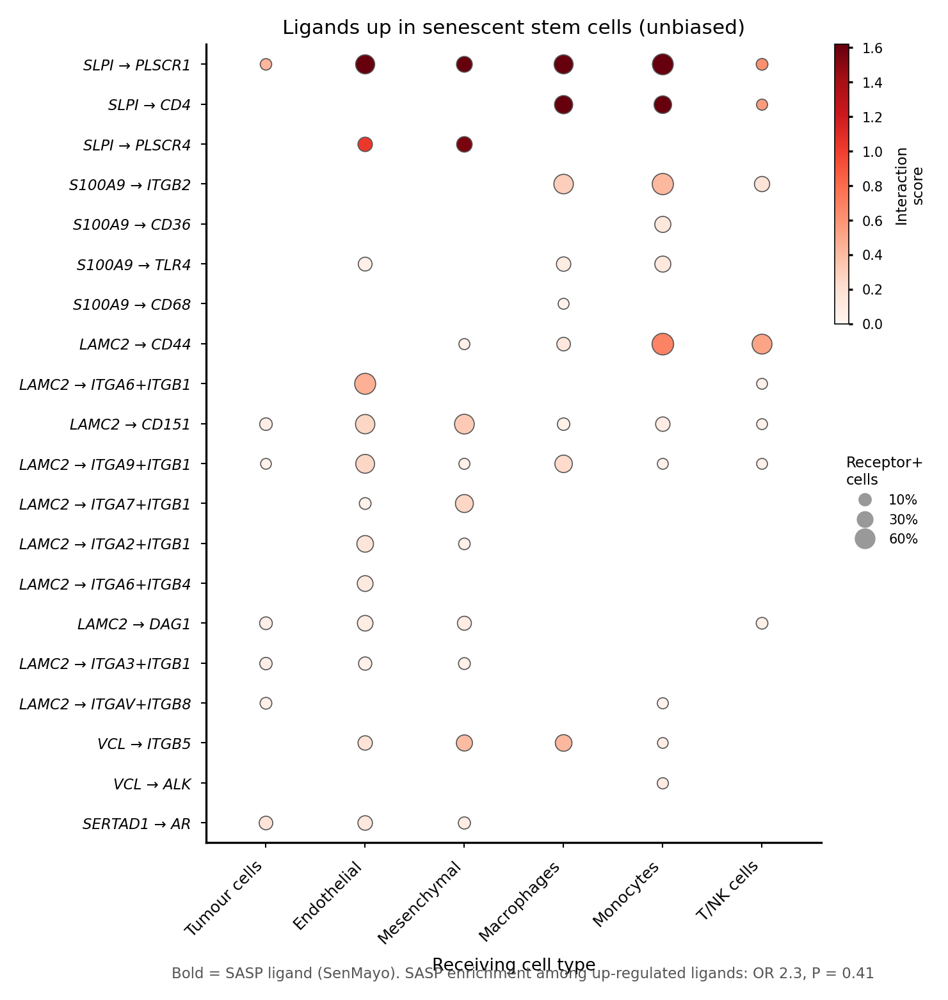

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import fisher_exact
from matplotlib.lines import Line2D

# =============================================================================
# UNBIASED ligand-receptor analysis for senescent (CDKN1A-high) stem cells
#   - every ligand-receptor pair in the LIANA consensus database (no pre-selection)
#   - ligands ranked by the PAIRED, per-tumour pseudobulk test from Fig. 2E
#     (CDKN1A-high vs CDKN1A-low stem cells), so pooling across tumours plays no role
#   - SASP defined in advance by the SenMayo secreted factors (not chosen from our data)
#   - test: are SASP ligands over-represented among ligands up in senescent stem cells?
#   - receivers: cell types expressing the receptor (all subunits) in >= 10% of cells
# Needs: Stem_CDKN1A_high_vs_low_pseudobulk.csv  (saved by Fig2E_complete.py)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
de_csv     = "Stem_CDKN1A_high_vs_low_pseudobulk.csv"
label_col  = "final_cell_type_broad"
q_high     = 0.90
min_frac   = 0.10           # ligand in senescent stem cells; receptor subunits in receiver
p_up       = 0.05           # ligand "up" in senescent stem cells: P < 0.05 and log2FC > 0
top_n      = 20
use_raw    = adata.raw is not None
receivers  = ["Tumour cells", "Endothelial", "Mesenchymal", "Macrophages", "Monocytes", "T/NK cells"]

# Pre-specified SASP definition: SenMayo secreted / SASP factors (Saul et al., 2022)
senmayo = ["ACVR1B", "ANG", "ANGPT1", "ANGPTL4", "AREG", "AXL", "BEX3", "BMP2", "BMP6", "C3", "CCL1",
           "CCL13", "CCL16", "CCL2", "CCL20", "CCL24", "CCL26", "CCL3", "CCL3L1", "CCL4", "CCL5", "CCL7",
           "CCL8", "CD55", "CD9", "CSF1", "CSF2", "CSF2RB", "CST4", "CTNNB1", "CTSB", "CXCL1", "CXCL10",
           "CXCL12", "CXCL16", "CXCL2", "CXCL3", "CXCL8", "CXCR2", "DKK1", "EDN1", "EGF", "EGFR", "EREG",
           "ESM1", "ETS2", "FAS", "FGF1", "FGF2", "FGF7", "GDF15", "GEM", "GMFG", "HGF", "HMGB1", "ICAM1",
           "ICAM3", "IGF1", "IGFBP1", "IGFBP2", "IGFBP3", "IGFBP4", "IGFBP5", "IGFBP6", "IGFBP7", "IL10",
           "IL13", "IL15", "IL18", "IL1A", "IL1B", "IL2", "IL32", "IL6", "IL6ST", "IL7", "INHA", "IQGAP2",
           "ITGA2", "ITPKA", "JUN", "KITLG", "LCP1", "MIF", "MMP1", "MMP10", "MMP12", "MMP13", "MMP14",
           "MMP2", "MMP3", "MMP9", "NAP1L4", "NRG1", "PAPPA", "PECAM1", "PGF", "PIGF", "PLAT", "PLAU",
           "PLAUR", "PTBP1", "PTGER2", "PTGES", "RPS6KA5", "SCAMP4", "SELPLG", "SEMA3F", "SERPINB3",
           "SERPINB4", "SERPINE1", "SERPINE2", "SPP1", "SPX", "TIMP2", "TNF", "TNFRSF10C", "TNFRSF11B",
           "TNFRSF1A", "TNFRSF1B", "TUBGCP2", "VEGFA", "VEGFC", "VGF", "WNT16", "WNT2"]
sasp_set = set(senmayo)

# ---- 2. Full ligand-receptor database ----------------------------------------
import liana as li
db = li.resource.select_resource("consensus")[["ligand", "receptor"]].drop_duplicates()
print(f"Database: {len(db):,} ligand-receptor pairs, {db['ligand'].nunique():,} ligands")

# ---- 3. Groups: senescent stem cells + receivers -----------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy().astype(object)
is_stem = ct == "Stem cells"
vn = pd.Index(adata.raw.var_names if use_raw else adata.var_names)
cdk = sc.get.obs_df(adata, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
thr = max(np.quantile(cdk[is_stem], q_high), cdk[is_stem & (cdk > 0)].min())
lab = ct.copy()
lab[is_stem & (cdk >= thr)] = "Senescent stem"
groups = ["Senescent stem"] + [r for r in receivers if r in set(lab)]

subunits = lambda cplx: cplx.split("_")
db = db[db["ligand"].apply(lambda c: all(s in vn for s in subunits(c))) &
        db["receptor"].apply(lambda c: all(s in vn for s in subunits(c)))]
genes = sorted({s for c in pd.concat([db["ligand"], db["receptor"]]).unique() for s in subunits(c)})
print(f"Pairs with all genes measured: {len(db):,}; genes: {len(genes):,}")

X = adata.raw.X if use_raw else adata.X
cols = vn.get_indexer(genes)
mean, frac = {}, {}
for gname in groups:
    m = np.where(lab == gname)[0]
    sub = X[m][:, cols]
    sub = sub.toarray() if hasattr(sub, "toarray") else np.asarray(sub)
    mean[gname] = pd.Series(sub.mean(0), index=genes)
    frac[gname] = pd.Series((sub > 0).mean(0), index=genes)
    print(f"{gname}: {len(m):,} cells")

def cplx(stat, gname, c):           # complex = weakest subunit
    return min(stat[gname][s] for s in subunits(c))

# ---- 4. Ligand ranking from the paired pseudobulk test (Fig. 2E) -------------
de = pd.read_csv(de_csv, index_col=0)
lig = pd.DataFrame({"ligand": db["ligand"].unique()})
lig["frac_sen_stem"] = [cplx(frac, "Senescent stem", c) for c in lig["ligand"]]
lig = lig[lig["frac_sen_stem"] >= min_frac].copy()
first = lambda c: subunits(c)[0]
lig["log2FC"] = [de["log2FoldChange"].get(first(c), np.nan) for c in lig["ligand"]]
lig["pvalue"] = [de["pvalue"].get(first(c), np.nan) for c in lig["ligand"]]
lig["stat"] = [de["stat"].get(first(c), np.nan) for c in lig["ligand"]]
lig = lig.dropna(subset=["stat"])
lig["SASP"] = lig["ligand"].apply(lambda c: any(s in sasp_set for s in subunits(c)))
lig["up"] = (lig["pvalue"] < p_up) & (lig["log2FC"] > 0)
lig = lig.sort_values("stat", ascending=False)
lig.to_csv("LR_unbiased_ligands_ranked.csv", index=False)

# ---- 5. Are SASP ligands over-represented among ligands up in senescent stem? -
tab = pd.crosstab(lig["up"], lig["SASP"]).reindex(index=[True, False], columns=[True, False], fill_value=0)
odds, p_f = fisher_exact(tab.values, alternative="greater")
print(f"\nLigands expressed by senescent stem cells and tested: {len(lig)}")
print(f"Up in senescent stem (P < {p_up}): {lig['up'].sum()}  |  SASP ligands among them: "
      f"{lig.loc[lig['up'], 'SASP'].sum()} of {lig['SASP'].sum()} SASP ligands tested")
print(f"SASP enrichment among up-regulated ligands: odds ratio {odds:.2f}, one-sided Fisher P = {p_f:.3g}")
print("\nTop ligands by paired test (unbiased):")
print(lig.head(25)[["ligand", "log2FC", "pvalue", "SASP", "frac_sen_stem"]].round(4).to_string(index=False))

# ---- 6. Receivers of the up-regulated ligands --------------------------------
up_l = lig[lig["up"]]
rows = []
for _, r in db[db["ligand"].isin(up_l["ligand"])].iterrows():
    for t in groups[1:]:
        rf = cplx(frac, t, r["receptor"])
        if rf >= min_frac:
            rows.append({"ligand": r["ligand"], "receptor": r["receptor"], "receiver": t,
                         "score": cplx(mean, "Senescent stem", r["ligand"]) * cplx(mean, t, r["receptor"]),
                         "receptor_frac": rf})
inter = pd.DataFrame(rows).merge(up_l[["ligand", "log2FC", "pvalue", "stat", "SASP"]], on="ligand")
inter.to_csv("LR_unbiased_interactions.csv", index=False)
print("\nInteractions from up-regulated ligands, by receiver:")
print(inter.groupby("receiver").agg(n=("ligand", "size"), SASP=("SASP", "sum")).reindex(groups[1:]).to_string())

# ---- 7. Plot: top up-regulated ligand->receptor pairs x receivers ------------
top = (inter.sort_values(["stat", "score"], ascending=False)
       .drop_duplicates(["ligand", "receptor"]).head(top_n))
pairs = list(zip(top["ligand"], top["receptor"]))
ii = inter.set_index(["ligand", "receptor", "receiver"])
vmax = inter["score"].quantile(0.95) if len(inter) else 1
fig, ax = plt.subplots(figsize=(4.4, 0.2 * max(len(pairs), 3) + 1.4), dpi=300)
for i, (l, r) in enumerate(pairs):
    for j, t in enumerate(groups[1:]):
        if (l, r, t) in ii.index:
            row = ii.loc[(l, r, t)]
            ax.scatter(j, i, s=10 + 60 * row["receptor_frac"], c=[row["score"]], cmap="Reds", vmin=0,
                       vmax=vmax, edgecolors="#555555", linewidths=0.4)
ax.set_yticks(range(len(pairs)))
lbl = [f"{l.replace('_', '+')} \u2192 {r.replace('_', '+')}" for l, r in pairs]
ax.set_yticklabels(lbl, fontsize=5.5, fontstyle="italic")
for tl, (l, _) in zip(ax.get_yticklabels(), pairs):
    if any(s in sasp_set for s in subunits(l)):
        tl.set_fontweight("bold")
ax.set_xticks(range(len(groups) - 1)); ax.set_xticklabels(groups[1:], rotation=45, ha="right", fontsize=6)
ax.set_xlim(-0.6, len(groups) - 1.4); ax.set_ylim(len(pairs) - 0.5, -0.5)
ax.set_xlabel("Receiving cell type", fontsize=6.5)
ax.set_title("Ligands up in senescent stem cells (unbiased)", fontsize=7.5, pad=4)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.tick_params(length=2, width=0.5)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), ax=ax,
                  fraction=0.04, pad=0.02, shrink=0.35, anchor=(0, 1))
cb.set_label("Interaction\nscore", fontsize=5.5); cb.ax.tick_params(labelsize=5, length=1.5)
cb.outline.set_linewidth(0.4)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(10 + 60 * f_),
                          label=f"{int(f_ * 100)}%") for f_ in (0.1, 0.3, 0.6)],
          title="Receptor+\ncells", loc="upper left", bbox_to_anchor=(1.02, 0.5), frameon=False,
          fontsize=5, title_fontsize=5.5)
fig.text(0.5, -0.02, f"Bold = SASP ligand (SenMayo). SASP enrichment among up-regulated ligands: "
         f"OR {odds:.1f}, P = {p_f:.2g}", ha="center", fontsize=5.5, color="#555555")
fig.savefig("LR_unbiased.pdf", bbox_inches="tight")
fig.savefig("LR_unbiased.png", dpi=600, bbox_inches="tight")
plt.show()

CCN2+ cells (%), median across tumours:
               median  count
cell_type                  
Tumour cells     0.2     18
Stem cells      21.4      8
Endothelial     62.1      8
Mesenchymal     46.3      7
Macrophages      0.0     13
Monocytes        3.1      2
T/NK cells       0.0      3

Share of all CCN2 expression (%):
 Tumour cells    11.3
Stem cells       7.0
Endothelial     30.9
Mesenchymal     49.0
Macrophages      1.4
Monocytes        0.3
T/NK cells       0.2

Predicted CCN2 interactions from stem cells:
    receptor     receiver  score  receptor_frac  expressed
ITGA6+ITGB1  Endothelial  0.403          0.861       True
ITGA5+ITGB1  Endothelial  0.226          0.736       True
       LRP1  Mesenchymal  0.208          0.602       True
       LRP1    Monocytes  0.196          0.620       True
       LRP1  Macrophages  0.172          0.552       True
ITGA6+ITGB1   Stem cells  0.136          0.410       True
ITGA5+ITGB1    Monocytes  0.070          0.269       True
       LRP1  

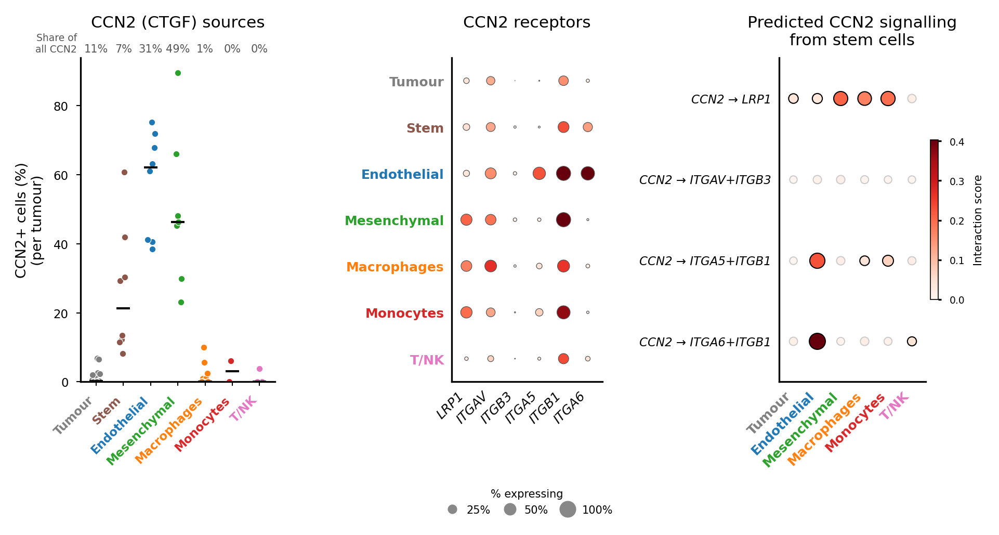

In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

# =============================================================================
# Supplementary Figure 2D: CCN2 (CTGF) - who makes it and who could receive it
#   left   % of cells expressing CCN2 per cell type (one point per tumour)
#   centre CCN2 receptor expression by cell type (dot plot)
#   right  predicted CCN2 interactions from stem cells (CellPhoneDB-style score)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
min_cells  = 20             # cells of a type in a tumour to plot that tumour's point
min_frac   = 0.10           # receptor (all subunits) detected in >= 10% of receiver cells
use_raw    = adata.raw is not None
order = ["Tumour cells", "Stem cells", "Endothelial", "Mesenchymal", "Macrophages", "Monocytes", "T/NK cells"]
pal = {"Tumour cells": "#7f7f7f", "Stem cells": "#8c564b", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728", "T/NK cells": "#e377c2"}
receptors = ["LRP1", "ITGAV", "ITGB3", "ITGA5", "ITGB1", "ITGA6"]
ccn2_pairs = [("LRP1",), ("ITGAV", "ITGB3"), ("ITGA5", "ITGB1"), ("ITGA6", "ITGB1")]
fs = {"title": 7.5, "label": 6.5, "small": 6}

# ---- 2. Data -------------------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy()
sid = adata.obs[sample_col].astype(str).to_numpy()
vn = adata.raw.var_names if use_raw else adata.var_names
ccn2 = "CCN2" if "CCN2" in vn else "CTGF"
genes = [ccn2] + [r for r in receptors if r in vn]
E = sc.get.obs_df(adata, keys=genes, use_raw=use_raw)
order = [c for c in order if c in set(ct)]

# per tumour % CCN2+ by cell type
rows = []
for c in order:
    for t in np.unique(sid):
        m = (ct == c) & (sid == t)
        if m.sum() >= min_cells:
            rows.append({"cell_type": c, "tumour": t, "pct": (E.loc[m, ccn2] > 0).mean() * 100})
per_t = pd.DataFrame(rows)
share = pd.Series({c: E.loc[ct == c, ccn2].sum() for c in order})
share = share / share.sum() * 100
print("CCN2+ cells (%), median across tumours:\n",
      per_t.groupby("cell_type")["pct"].agg(["median", "count"]).reindex(order).round(1).to_string())
print("\nShare of all CCN2 expression (%):\n", share.round(1).to_string())

# receptor expression by cell type
frac = pd.DataFrame({c: (E.loc[ct == c, genes] > 0).mean() for c in order}).T
mean = pd.DataFrame({c: E.loc[ct == c, genes].mean() for c in order}).T

# predicted CCN2 interactions from stem cells
lig_m, lig_f = mean.loc["Stem cells", ccn2], frac.loc["Stem cells", ccn2]
inter = []
for rec in ccn2_pairs:
    if not all(r in genes for r in rec):
        continue
    for c in order:
        rm = min(mean.loc[c, r] for r in rec); rf = min(frac.loc[c, r] for r in rec)
        inter.append({"receptor": "+".join(rec), "receiver": c, "score": lig_m * rm,
                      "receptor_frac": rf, "expressed": rf >= min_frac and lig_f >= min_frac})
inter = pd.DataFrame(inter)
inter.to_csv("SuppFig2D_CCN2_interactions.csv", index=False)
print("\nPredicted CCN2 interactions from stem cells:\n",
      inter[inter["expressed"]].sort_values("score", ascending=False).round(3).to_string(index=False))

# ---- 3. Figure -----------------------------------------------------------------
fig = plt.figure(figsize=(7.1, 2.7), dpi=300)
gs = GridSpec(1, 3, figure=fig, width_ratios=[1.1, 0.85, 0.9], wspace=1.05)
short = {"Tumour cells": "Tumour", "Stem cells": "Stem", "Endothelial": "Endothelial",
         "Mesenchymal": "Mesenchymal", "Macrophages": "Macrophages", "Monocytes": "Monocytes",
         "T/NK cells": "T/NK"}

# (i) sources
ax = fig.add_subplot(gs[0])
rng = np.random.default_rng(0)
for i, c in enumerate(order):
    v = per_t.loc[per_t["cell_type"] == c, "pct"].to_numpy()
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=9, color=pal[c], edgecolors="white",
               linewidths=0.3, zorder=2)
    if len(v):
        ax.hlines(np.median(v), i - 0.25, i + 0.25, color="black", lw=1.0, zorder=3)
    ax.text(i, 1.01, f"{share[c]:.0f}%", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
            fontsize=fs["small"] - 1, color="#555555")
ax.text(-0.7, 1.01, "Share of\nall CCN2", transform=ax.get_xaxis_transform(), ha="right", va="bottom",
        fontsize=fs["small"] - 1.5, color="#555555")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([short[c] for c in order], rotation=45, ha="right", fontsize=fs["small"])
for lab, c in zip(ax.get_xticklabels(), order):
    lab.set_color(pal[c]); lab.set_fontweight("bold")
ax.set_ylabel("CCN2+ cells (%)\n(per tumour)", fontsize=fs["label"])
ax.set_title("CCN2 (CTGF) sources", fontsize=fs["title"], pad=14)
ax.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
ax.set_ylim(bottom=0)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)

# (ii) receptors
ax = fig.add_subplot(gs[1])
rec_genes = [r for r in receptors if r in genes]
yy, xx = np.meshgrid(np.arange(len(order)), np.arange(len(rec_genes)), indexing="ij")
f_ = frac.loc[order, rec_genes].to_numpy(); m_ = mean.loc[order, rec_genes].to_numpy()
dots = ax.scatter(xx.ravel(), yy.ravel(), s=f_.ravel() * 45, c=m_.ravel(), cmap="Reds", vmin=0,
                  vmax=np.percentile(m_, 95), edgecolors="#555555", linewidths=0.3)
ax.set_xticks(range(len(rec_genes))); ax.set_xticklabels(rec_genes, rotation=45, ha="right",
                                                          fontsize=fs["small"], fontstyle="italic")
ax.set_yticks(range(len(order))); ax.set_yticklabels([short[c] for c in order], fontsize=fs["small"])
for lab, c in zip(ax.get_yticklabels(), order):
    lab.set_color(pal[c]); lab.set_fontweight("bold")
ax.set_xlim(-0.6, len(rec_genes) - 0.4); ax.set_ylim(len(order) - 0.5, -0.5)
ax.set_title("CCN2 receptors", fontsize=fs["title"], pad=14)
ax.tick_params(length=0)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p * 45),
                          label=f"{int(p * 100)}%") for p in (0.25, 0.5, 1.0)],
          title="% expressing", loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False, ncol=3,
          fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 1, columnspacing=0.8, handletextpad=0.3)

# (iii) predicted interactions from stem cells
ax = fig.add_subplot(gs[2])
recs = list(dict.fromkeys(inter["receptor"]))
recv = [c for c in order if c != "Stem cells"]
ii = inter.set_index(["receptor", "receiver"])
vmax = inter.loc[inter["expressed"], "score"].max() if inter["expressed"].any() else 1
for i, r in enumerate(recs):
    for j, c in enumerate(recv):
        row = ii.loc[(r, c)]
        ax.scatter(j, i, s=12 + 50 * min(row["receptor_frac"], 1), c=[row["score"]], cmap="Reds",
                   vmin=0, vmax=vmax, edgecolors="black" if row["expressed"] else "#CCCCCC", linewidths=0.5)
ax.set_yticks(range(len(recs)))
ax.set_yticklabels([f"CCN2 → {r}" for r in recs], fontsize=fs["small"] - 0.5, fontstyle="italic")
ax.set_xticks(range(len(recv))); ax.set_xticklabels([short[c] for c in recv], rotation=45, ha="right",
                                                     fontsize=fs["small"])
for lab, c in zip(ax.get_xticklabels(), recv):
    lab.set_color(pal[c]); lab.set_fontweight("bold")
ax.set_xlim(-0.6, len(recv) - 0.4); ax.set_ylim(len(recs) - 0.5, -0.5)
ax.set_title("Predicted CCN2 signalling\nfrom stem cells", fontsize=fs["title"], pad=6)
ax.tick_params(length=0)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), ax=ax,
                  fraction=0.05, pad=0.03, shrink=0.6)
cb.set_label("Interaction score", fontsize=fs["small"] - 1); cb.ax.tick_params(labelsize=fs["small"] - 1.5, length=1.5)
cb.outline.set_linewidth(0.4)

fig.savefig("SuppFig2D_CCN2.pdf", bbox_inches="tight")
fig.savefig("SuppFig2D_CCN2.svg", bbox_inches="tight")
fig.savefig("SuppFig2D_CCN2.png", dpi=600, bbox_inches="tight")
plt.show()

Cells per group: {'Tumour cells': 5000, 'Macrophages': 3035, 'Mesenchymal': 2540, 'Endothelial': 2000, 'Stem (CDKN1A-low)': 943, 'Monocytes': 424, 'T/NK cells': 332, 'Senescent stem': 126}

Significant SASP interactions from senescent stem cells (P < 0.05, expressed): 42
ligand    receptor          receiver  score     P  fold_vs_low_stem
 TIMP1        CD63       Mesenchymal 5.2204 0.001            1.2271
 TIMP1        CD63    Senescent stem 4.9720 0.001            1.2271
 TIMP1        CD63 Stem (CDKN1A-low) 4.7450 0.001            1.2271
 TIMP1        CD63       Macrophages 3.7970 0.001            1.2271
 TIMP1        CD63       Endothelial 3.7341 0.001            1.2271
   MIF       CXCR4        T/NK cells 2.6918 0.001            1.1417
 TIMP1        CD63         Monocytes 2.6624 0.019            1.2271
   MIF   CD74+CD44         Monocytes 2.5137 0.001            1.1417
   MIF       CXCR4         Monocytes 2.1392 0.001            1.1417
   MIF   CD74+CD44        T/NK cells 1.9412 0.00

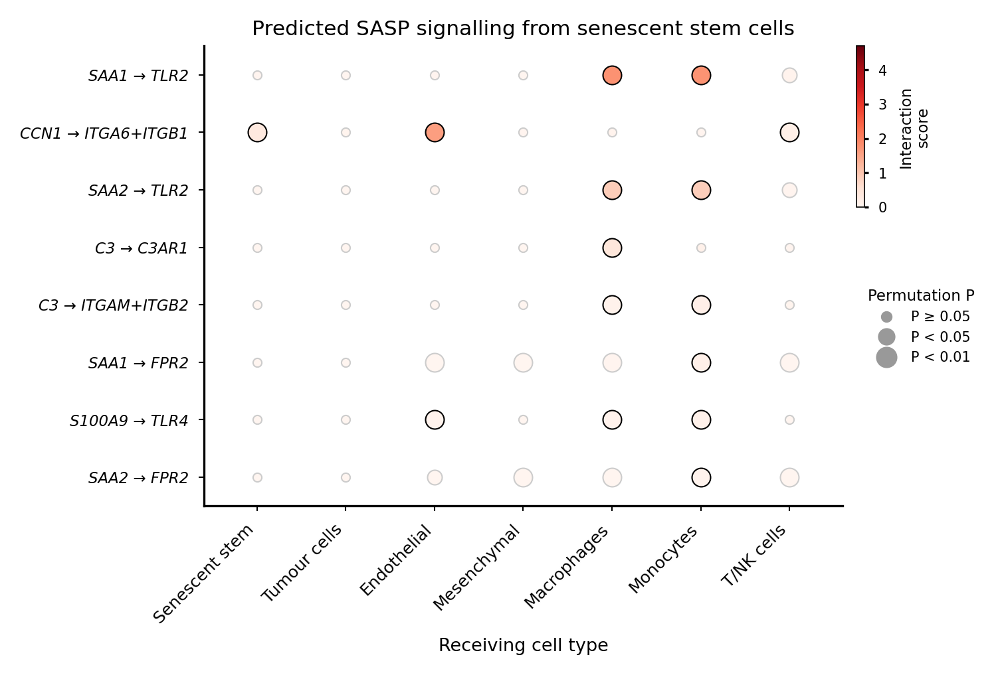

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

# =============================================================================
# Who receives the SASP?  Ligand-receptor inference WITHOUT LIANA (no extra packages).
# CellPhoneDB-style: score = mean ligand in sender x mean receptor in receiver
# (multi-subunit receptors use the lowest subunit); P value by permuting cell labels.
# Senders: senescent (CDKN1A-high) stem cells, compared with CDKN1A-low stem cells.
# Pairs: curated SASP ligand-receptor pairs (from CellPhoneDB / OmniPath).
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
q_high     = 0.90          # CDKN1A-high = top 10% of stem cells (as in Fig. 2E)
min_frac   = 0.10          # ligand / every receptor subunit detected in >= 10% of its group
n_perm     = 1000
max_per    = 5000          # downsample large groups for the permutations; None = all
seed       = 0
use_raw    = adata.raw is not None
min_fold   = 1.5           # plot only interactions >= 1.5x stronger from senescent than CDKN1A-low stem
                            # cells (removes ubiquitous ligands such as TIMP1/MIF); 1.0 = show all

pairs = [  # ligand, receptor (subunits joined by "+")
    ("CCL2", "CCR2"), ("CCL5", "CCR5"), ("CCL5", "CCR1"), ("CCL20", "CCR6"),
    ("CXCL1", "CXCR2"), ("CXCL2", "CXCR2"), ("CXCL8", "CXCR1"), ("CXCL8", "CXCR2"),
    ("CXCL10", "CXCR3"), ("CXCL12", "CXCR4"), ("CXCL12", "ACKR3"),
    ("IL6", "IL6R+IL6ST"), ("IL1A", "IL1R1+IL1RAP"), ("IL1B", "IL1R1+IL1RAP"),
    ("TNF", "TNFRSF1A"), ("TNF", "TNFRSF1B"), ("CSF1", "CSF1R"), ("IL15", "IL15RA+IL2RB"),
    ("SAA1", "FPR2"), ("SAA2", "FPR2"), ("SAA1", "TLR2"), ("SAA2", "TLR2"),
    ("S100A8", "TLR4"), ("S100A9", "TLR4"), ("S100A8", "AGER"), ("S100A9", "AGER"),
    ("C3", "C3AR1"), ("C3", "ITGAM+ITGB2"),
    ("IGFBP3", "TMEM219"), ("CCN2", "LRP1"), ("CCN2", "ITGAV+ITGB3"), ("CCN1", "ITGAV+ITGB3"),
    ("CCN2", "ITGA5+ITGB1"), ("CCN1", "ITGA6+ITGB1"),
    ("TGFB1", "TGFBR1+TGFBR2"), ("VEGFA", "KDR"), ("VEGFA", "FLT1"), ("VEGFA", "NRP1"),
    ("PGF", "FLT1"), ("FGF2", "FGFR1"), ("HGF", "MET"), ("AREG", "EGFR"), ("EREG", "EGFR"),
    ("GDF15", "GFRAL"), ("SPP1", "CD44"), ("SPP1", "ITGAV+ITGB1"), ("SERPINE1", "LRP1"),
    ("PLAU", "PLAUR"), ("MIF", "CD74+CD44"), ("MIF", "CXCR4"), ("ICAM1", "ITGAL+ITGB2"),
    ("FN1", "ITGA5+ITGB1"), ("TIMP1", "CD63"), ("BMP2", "BMPR1A+BMPR2"),
]
aliases = {"CCN2": "CTGF", "CCN1": "CYR61"}

# ---- 2. Groups -----------------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy().astype(object)
is_stem = ct == "Stem cells"
vn = adata.raw.var_names if use_raw else adata.var_names
g = lambda x: x if x in vn else aliases.get(x, x)
cdk = sc.get.obs_df(adata, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
thr = max(np.quantile(cdk[is_stem], q_high), cdk[is_stem & (cdk > 0)].min())
lab = ct.copy()
lab[is_stem & (cdk >= thr)] = "Senescent stem"
lab[is_stem & (cdk == 0)] = "Stem (CDKN1A-low)"
lab[is_stem & (cdk > 0) & (cdk < thr)] = "drop"

rng = np.random.default_rng(seed)
idx = []
for grp_ in pd.unique(lab):
    if grp_ == "drop":
        continue
    w = np.where(lab == grp_)[0]
    if max_per and len(w) > max_per:
        w = rng.choice(w, max_per, replace=False)
    idx.append(w)
idx = np.sort(np.concatenate(idx))
labs = lab[idx]
groups = [x for x in ["Senescent stem", "Stem (CDKN1A-low)", "Tumour cells", "Endothelial", "Mesenchymal",
                      "Macrophages", "Monocytes", "T/NK cells"] if x in set(labs)]
print("Cells per group:", pd.Series(labs).value_counts().to_dict())

# ---- 3. Expression of every gene in the pairs ---------------------------------
genes = sorted({g(x) for l, r in pairs for x in [l] + r.split("+")} & set(vn))
E = sc.get.obs_df(adata[idx], keys=genes, use_raw=use_raw)
E = E.to_numpy(dtype=float); gi = {x: i for i, x in enumerate(genes)}

def group_stats(labels_):
    M = np.vstack([E[labels_ == k].mean(0) for k in groups])          # groups x genes
    F = np.vstack([(E[labels_ == k] > 0).mean(0) for k in groups])
    return M, F

def score(M, F, l, r, s, t):
    if g(l) not in gi or any(g(x) not in gi for x in r.split("+")):
        return np.nan, False
    lm, lf = M[s, gi[g(l)]], F[s, gi[g(l)]]
    rm = min(M[t, gi[g(x)]] for x in r.split("+")); rf = min(F[t, gi[g(x)]] for x in r.split("+"))
    return lm * rm, (lf >= min_frac) and (rf >= min_frac)

M, F = group_stats(labs)
senders = [groups.index("Senescent stem"), groups.index("Stem (CDKN1A-low)")]
rows = []
for l, r in pairs:
    for s in senders:
        for t in range(len(groups)):
            sc_, ok = score(M, F, l, r, s, t)
            if np.isfinite(sc_):
                rows.append({"ligand": l, "receptor": r, "sender": groups[s], "receiver": groups[t],
                             "score": sc_, "expressed": ok})
res = pd.DataFrame(rows)

# ---- 4. Permutation P values (shuffle cell labels) ----------------------------
null_ge = np.zeros(len(res))
for _ in range(n_perm):
    Mp, Fp = group_stats(rng.permutation(labs))
    for k, row in enumerate(res.itertuples()):
        s, t = groups.index(row.sender), groups.index(row.receiver)
        null_ge[k] += score(Mp, Fp, row.ligand, row.receptor, s, t)[0] >= row.score
res["P"] = (null_ge + 1) / (n_perm + 1)

# senescent vs CDKN1A-low stem senders, same pair and receiver
piv = res.pivot_table(index=["ligand", "receptor", "receiver"], columns="sender", values="score")
res = res.merge(piv.rename(columns={"Senescent stem": "score_senescent",
                                    "Stem (CDKN1A-low)": "score_low_stem"}).reset_index(),
                on=["ligand", "receptor", "receiver"])
res["fold_vs_low_stem"] = (res["score_senescent"] + 1e-4) / (res["score_low_stem"] + 1e-4)
res.to_csv("SASP_ligand_receptor_all.csv", index=False)

sen = res[(res["sender"] == "Senescent stem") & res["expressed"] & (res["P"] < 0.05)]
sen = sen.sort_values("score", ascending=False)
sen.to_csv("SASP_ligand_receptor_senescent_significant.csv", index=False)
print(f"\nSignificant SASP interactions from senescent stem cells (P < 0.05, expressed): {len(sen)}")
print(sen[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].head(30)
      .round(4).to_string(index=False))
print("\nBy receiver:\n", sen["receiver"].value_counts().to_string())

# ---- 5. Plot ---------------------------------------------------------------------
receivers = [x for x in groups if x != "Stem (CDKN1A-low)"]
spec = sen[sen["fold_vs_low_stem"] >= min_fold]
print(f"\nShown in plot (fold vs CDKN1A-low stem >= {min_fold}): {spec[['ligand','receptor']].drop_duplicates().shape[0]} pairs")
print(spec[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].round(3).to_string(index=False))
top = spec.drop_duplicates(["ligand", "receptor"]).head(20)
pairs_shown = list(zip(top["ligand"], top["receptor"]))
allsen = res[res["sender"] == "Senescent stem"].set_index(["ligand", "receptor", "receiver"])
vmax = sen["score"].quantile(0.95) if len(sen) else 1
fig, ax = plt.subplots(figsize=(4.4, 0.2 * max(len(pairs_shown), 3) + 1.4), dpi=300)
for i, (l, r) in enumerate(pairs_shown):
    for j, t in enumerate(receivers):
        if (l, r, t) not in allsen.index:
            continue
        row = allsen.loc[(l, r, t)]
        sig = row["expressed"] and row["P"] < 0.05
        size = 45 if row["P"] < 0.01 else 28 if row["P"] < 0.05 else 10
        ax.scatter(j, i, s=size, c=[row["score"]], cmap="Reds", vmin=0, vmax=vmax,
                   edgecolors="black" if sig else "#CCCCCC", linewidths=0.5)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([f"{l} → {r}" for l, r in pairs_shown], fontsize=5.5, fontstyle="italic")
ax.set_xticks(range(len(receivers)))
ax.set_xticklabels(receivers, rotation=45, ha="right", fontsize=6)
ax.set_xlim(-0.6, len(receivers) - 0.4); ax.set_ylim(len(pairs_shown) - 0.5, -0.5)
ax.set_xlabel("Receiving cell type", fontsize=6.5)
ax.set_title("Predicted SASP signalling from senescent stem cells", fontsize=7.5, pad=4)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.tick_params(length=2, width=0.5)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), ax=ax,
                  fraction=0.04, pad=0.02, shrink=0.35, anchor=(0, 1))
cb.set_label("Interaction\nscore", fontsize=5.5); cb.ax.tick_params(labelsize=5, length=1.5)
cb.outline.set_linewidth(0.4)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(s_), label=l_)
                   for s_, l_ in [(10, "P ≥ 0.05"), (28, "P < 0.05"), (45, "P < 0.01")]],
          title="Permutation P", loc="upper left", bbox_to_anchor=(1.02, 0.5), frameon=False,
          fontsize=5, title_fontsize=5.5)
fig.savefig("SuppFig2D_ligand_receptor.svg", bbox_inches="tight")
fig.savefig("SuppFig2D_ligand_receptor.pdf", bbox_inches="tight")
fig.savefig("SuppFig2D_ligand_receptor.png", dpi=600, bbox_inches="tight")
plt.show()

Using existing SenMayo_score
col_0        SOX2+ stem  SOX2+ tumour  SOX2− tumour  % tumour cells SOX2+
row_0                                                                    
SRX14605703         413            63          4294                  1.45
SRX16175537          61            51          5741                  0.88
SRX28461022          43            26          4176                  0.62
HRS488990            31            14          4236                  0.33
HRS488982            27             8          3562                  0.22
SRX21219343          22            15          2540                  0.59
SRX21219339          20             8          1829                  0.44
HRS488991            10             5          4760                  0.10
SRX21219341           3            14          3914                  0.36
HRS488987             1             0           254                  0.00
HRS488984             1             0          4341                  0.00
HRS140877

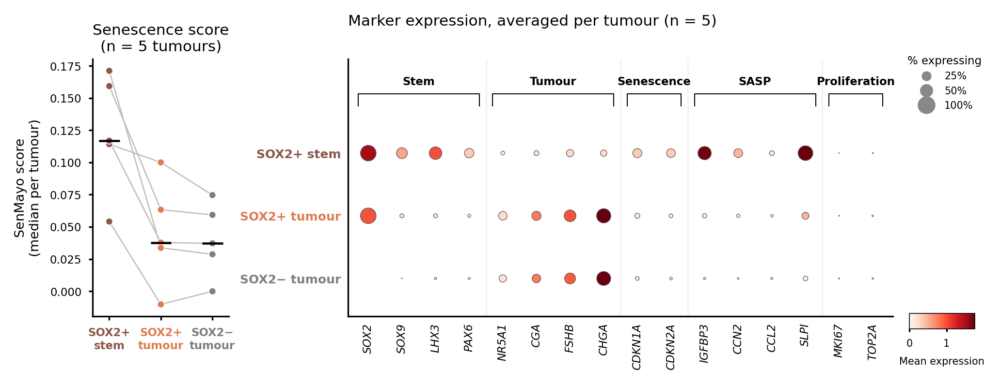

In [44]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon, ttest_rel

# =============================================================================
# SOX2+ cells in the TUMOUR cluster vs SOX2+ cells in the STEM cell cluster
#   1. How many SOX2+ tumour cells, per tumour; are they doublets?
#   2. Marker profile of SOX2+ stem, SOX2+ tumour and SOX2- tumour cells
#      (averaged per tumour, each tumour weighted equally)
#   3. SenMayo score per tumour in the three groups (paired)
#   4. Pseudobulk DE + Hallmark GSEA: SOX2+ tumour vs SOX2+ stem, paired by tumour
#   5. Figure: UMAP | marker dot plot | SenMayo paired plot
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
score_col    = "SenMayo_score"          # computed earlier; skipped if absent
doublet_col  = "doublet_score"
min_cells    = 10                       # per group per tumour for paired analyses
use_raw      = adata.raw is not None
groups = ["SOX2+ stem", "SOX2+ tumour", "SOX2− tumour"]
gcol   = {"SOX2+ stem": "#8c564b", "SOX2+ tumour": "#E07B54", "SOX2− tumour": "#7f7f7f"}
marker_groups = [
    ("Stem",           ["SOX2", "SOX9", "LHX3", "PAX6"]),
    ("Tumour",         ["NR5A1", "CGA", "FSHB", "CHGA"]),
    ("Senescence",     ["CDKN1A", "CDKN2A"]),
    ("SASP",           ["IGFBP3", "CCN2", "CCL2", "SLPI"]),
    ("Proliferation",  ["MKI67", "TOP2A"]),
]
aliases = {"CCN2": "CTGF"}
fs = {"title": 7.5, "label": 6.5, "small": 6}

# ---- 1b. SenMayo score (computed here if not already in adata.obs) -----------
# SenMayo gene set (Saul et al., Nat Commun 2022). Check against their Supplementary Data 1.
senmayo = ["ACVR1B", "ANG", "ANGPT1", "ANGPTL4", "AREG", "AXL", "BEX3", "BMP2", "BMP6", "C3", "CCL1",
           "CCL13", "CCL16", "CCL2", "CCL20", "CCL24", "CCL26", "CCL3", "CCL3L1", "CCL4", "CCL5", "CCL7",
           "CCL8", "CD55", "CD9", "CSF1", "CSF2", "CSF2RB", "CST4", "CTNNB1", "CTSB", "CXCL1", "CXCL10",
           "CXCL12", "CXCL16", "CXCL2", "CXCL3", "CXCL8", "CXCR2", "DKK1", "EDN1", "EGF", "EGFR", "EREG",
           "ESM1", "ETS2", "FAS", "FGF1", "FGF2", "FGF7", "GDF15", "GEM", "GMFG", "HGF", "HMGB1", "ICAM1",
           "ICAM3", "IGF1", "IGFBP1", "IGFBP2", "IGFBP3", "IGFBP4", "IGFBP5", "IGFBP6", "IGFBP7", "IL10",
           "IL13", "IL15", "IL18", "IL1A", "IL1B", "IL2", "IL32", "IL6", "IL6ST", "IL7", "INHA", "IQGAP2",
           "ITGA2", "ITPKA", "JUN", "KITLG", "LCP1", "MIF", "MMP1", "MMP10", "MMP12", "MMP13", "MMP14",
           "MMP2", "MMP3", "MMP9", "NAP1L4", "NRG1", "PAPPA", "PECAM1", "PGF", "PIGF", "PLAT", "PLAU",
           "PLAUR", "PTBP1", "PTGER2", "PTGES", "RPS6KA5", "SCAMP4", "SELPLG", "SEMA3F", "SERPINB3",
           "SERPINB4", "SERPINE1", "SERPINE2", "SPP1", "SPX", "TIMP2", "TNF", "TNFRSF10C", "TNFRSF11B",
           "TNFRSF1A", "TNFRSF1B", "TUBGCP2", "VEGFA", "VEGFC", "VGF", "WNT16", "WNT2"]
if score_col not in adata.obs:
    vn0 = adata.raw.var_names if use_raw else adata.var_names
    sm_genes = [g for g in senmayo if g in vn0]
    print(f"SenMayo: {len(sm_genes)} of {len(senmayo)} genes found; scoring all cells...")
    sc.tl.score_genes(adata, sm_genes, score_name=score_col, use_raw=use_raw, random_state=0)
else:
    print(f"Using existing {score_col}")

# ---- 2. Define the groups ------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells", "Pituicytes": "Tumour cells"}).to_numpy()
vn = adata.raw.var_names if use_raw else adata.var_names
sox2 = sc.get.obs_df(adata, keys=["SOX2"], use_raw=use_raw)["SOX2"].to_numpy() > 0
grp = np.full(adata.n_obs, "", dtype=object)
grp[(ct == "Stem cells") & sox2] = groups[0]
grp[(ct == "Tumour cells") & sox2] = groups[1]
grp[(ct == "Tumour cells") & ~sox2] = groups[2]
sid = adata.obs[sample_col].astype(str).to_numpy()

tab = pd.crosstab(sid[grp != ""], grp[grp != ""]).reindex(columns=groups, fill_value=0)
tab["% tumour cells SOX2+"] = (tab[groups[1]] / (tab[groups[1]] + tab[groups[2]]) * 100).round(2)
print(tab.sort_values(groups[0], ascending=False).to_string())
print(f"\nSOX2+ tumour cells: {(grp == groups[1]).sum():,} "
      f"({(grp == groups[1]).sum() / (ct == 'Tumour cells').sum() * 100:.1f}% of tumour cells); "
      f"SOX2+ stem cells: {(grp == groups[0]).sum():,}")

keep = tab.index[(tab[groups[0]] >= min_cells) & (tab[groups[1]] >= min_cells)].tolist()
print(f"Tumours with >= {min_cells} SOX2+ stem and >= {min_cells} SOX2+ tumour cells: {len(keep)}", keep)

# ---- 3. Doublet / quality check ----------------------------------------------
qc_cols = [c for c in [doublet_col, "n_genes_by_counts", "total_counts"] if c in adata.obs]
qc = adata.obs.loc[grp != "", qc_cols].apply(lambda c: pd.to_numeric(c.astype(str), errors="coerce"))
qc = qc.assign(group=grp[grp != ""], sid=sid[grp != ""])
qc = qc[qc["sid"].isin(keep)]
print("\nQC per group (median across tumours of per-tumour medians):")
print(qc.groupby(["sid", "group"])[qc_cols].median().groupby("group").median().reindex(groups).round(3).to_string())

# ---- 4. Marker profile, averaged per tumour ----------------------------------
genes, labels_, gpos = [], [], []
for name, gl in marker_groups:
    kept = [(g if g in vn else aliases.get(g, g)) for g in gl]
    kept = [g for g in kept if g in vn]
    if kept:
        gpos.append((name, len(genes), len(genes) + len(kept) - 1))
        genes += kept
        labels_ += ["CCN2 (CTGF)" if g == "CTGF" else g for g in kept]
E = sc.get.obs_df(adata, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
frac = np.zeros((len(groups), len(genes))); mean = np.zeros_like(frac)
for i, gname in enumerate(groups):
    f_t, m_t = [], []
    for t in keep:
        m = (grp == gname) & (sid == t)
        f_t.append((E[m] > 0).mean(0)); m_t.append(E[m].mean(0))
    frac[i], mean[i] = np.mean(f_t, 0), np.mean(m_t, 0)
prof = pd.DataFrame((frac * 100).round(1), index=groups, columns=labels_).T
print("\n% expressing (mean of per-tumour values):\n", prof.to_string())

# ---- 5. SenMayo per tumour -----------------------------------------------------
sm = None
if score_col in adata.obs:
    s_df = pd.DataFrame({"sid": sid, "group": grp, "score": pd.to_numeric(adata.obs[score_col].astype(str), errors="coerce").to_numpy()})
    sm = s_df[(s_df["group"] != "") & s_df["sid"].isin(keep)].groupby(["sid", "group"])["score"].median().unstack()[groups]
    print("\nSenMayo median per tumour:\n", sm.round(3).to_string())
    for a, b in [(groups[0], groups[1]), (groups[1], groups[2])]:
        print(f"{a} vs {b}: higher in {(sm[a] > sm[b]).sum()}/{len(sm)}; "
              f"paired Wilcoxon P = {wilcoxon(sm[a], sm[b]).pvalue:.3g}")

# ---- 6. Pseudobulk DE: SOX2+ tumour vs SOX2+ stem (paired by tumour) ----------
C = adata.layers[counts_layer]
rows, meta = [], []
for t in keep:
    for gname, short in [(groups[1], "tumour"), (groups[0], "stem")]:
        m = np.where((grp == gname) & (sid == t))[0]
        rows.append(np.asarray(C[m].sum(axis=0)).ravel())
        meta.append({"sample": f"{t}_{short}", "tumour": t, "group": short})
pb = pd.DataFrame(np.vstack(rows), columns=adata.var_names,
                  index=[m_["sample"] for m_ in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, len(keep) // 2)]
try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "tumour", "stem"], quiet=True); st.summary()
    res = st.results_df; method = "PyDESeq2"
except ImportError:
    lcpm = np.log2(pb.div(pb.sum(axis=1), axis=0) * 1e6 + 1)
    hi = lcpm.loc[[f"{t}_tumour" for t in keep]].to_numpy(); lo = lcpm.loc[[f"{t}_stem" for t in keep]].to_numpy()
    tt, pp = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"log2FoldChange": (hi - lo).mean(0), "stat": tt, "pvalue": pp}, index=lcpm.columns)
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("SOX2pos_tumour_vs_stem_pseudobulk.csv")
print(f"\nDE ({method}); positive log2FC = higher in SOX2+ tumour cells")
print("Up in SOX2+ tumour:\n", res[res["log2FoldChange"] > 0].head(20)[["log2FoldChange", "pvalue"]].round(4).to_string())
print("Up in SOX2+ stem:\n", res[res["log2FoldChange"] < 0].head(20)[["log2FoldChange", "pvalue"]].round(4).to_string())
try:
    import gseapy as gp
    pre = gp.prerank(rnk=res["stat"].dropna().sort_values(ascending=False), gene_sets="MSigDB_Hallmark_2020",
                     permutation_num=1000, min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
    gs = pre.res2d.sort_values("NES", ascending=False)
    gs.to_csv("SOX2pos_tumour_vs_stem_GSEA_hallmark.csv", index=False)
    print("\nHallmark GSEA (positive NES = enriched in SOX2+ tumour cells):")
    print(gs[["Term", "NES", "FDR q-val"]].head(8).to_string(index=False))
    print(gs[["Term", "NES", "FDR q-val"]].tail(8).to_string(index=False))
except Exception as e:
    print("GSEA skipped:", e)

# ---- 7. Figure -----------------------------------------------------------------
# top row: UMAP | SenMayo paired ; bottom row: dot plot (full width)
show_umap = False      # False = compact supplementary panel: senescence score | dot plot
if show_umap:
    fig = plt.figure(figsize=(7.1, 4.6), dpi=300)
    gsp = GridSpec(2, 2, figure=fig, width_ratios=[1.3, 1], height_ratios=[1.15, 1], wspace=0.35, hspace=0.55)
    pos_umap, pos_sm, pos_dot = gsp[0, 0], gsp[0, 1], gsp[1, :]
else:
    fig = plt.figure(figsize=(7.1, 2.3), dpi=300)
    gsp = GridSpec(1, 2, figure=fig, width_ratios=[0.55, 2.2], wspace=0.35)
    pos_umap, pos_sm, pos_dot = None, gsp[0], gsp[1]

# (a) UMAP: SOX2+ cells by compartment (full layout only)
if show_umap:
    ax = fig.add_subplot(pos_umap)
    xy = adata.obsm["X_umap"]
    ax.scatter(xy[:, 0], xy[:, 1], s=0.3, color="#EDEDED", linewidths=0, rasterized=True)
    for gname in [groups[1], groups[0]]:
        m = grp == gname
        ax.scatter(xy[m, 0], xy[m, 1], s=1.2, color=gcol[gname], linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title("SOX2+ cells", fontsize=fs["title"], pad=2)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=gcol[g], markersize=3,
                              label=f"{g} (n = {(grp == g).sum():,})") for g in groups[:2]],
              loc="upper left", bbox_to_anchor=(0.0, 1.0), frameon=False, fontsize=fs["small"] - 0.5)

# (b) SenMayo paired
ax = fig.add_subplot(pos_sm)
if sm is not None:
    for t, row in sm.iterrows():
        ax.plot(range(3), row[groups].to_numpy(), color="#BBBBBB", lw=0.6, zorder=1)
        ax.scatter(range(3), row[groups].to_numpy(), s=12, c=[gcol[g] for g in groups], zorder=2,
                   edgecolors="white", linewidths=0.4)
    for i, g in enumerate(groups):
        ax.hlines(sm[g].median(), i - 0.2, i + 0.2, color="black", lw=1.1, zorder=3)
    ax.set_xticks(range(3)); ax.set_xticklabels(["SOX2+\nstem", "SOX2+\ntumour", "SOX2\u2212\ntumour"],
                                                fontsize=fs["small"] - 0.5)
    for lab, g in zip(ax.get_xticklabels(), groups):
        lab.set_color(gcol[g]); lab.set_fontweight("bold")
    ax.set_ylabel("SenMayo score\n(median per tumour)", fontsize=fs["label"])
    ax.set_title(f"Senescence score\n(n = {len(sm)} tumours)", fontsize=fs["title"], pad=4)
    ax.tick_params(labelsize=fs["small"] - 0.5, length=2)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
else:
    ax.axis("off")

# (c) dot plot, groups x genes
ax = fig.add_subplot(pos_dot)
yy, xx = np.meshgrid(np.arange(len(groups)), np.arange(len(genes)), indexing="ij")
dots = ax.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                  vmin=0, vmax=np.percentile(mean, 95), edgecolors="#555555", linewidths=0.3)
ax.set_xticks(range(len(genes)))
ax.set_xticklabels(labels_, rotation=90, fontsize=fs["small"] - 0.5, fontstyle="italic")
ax.set_yticks(range(len(groups))); ax.set_yticklabels(groups, fontsize=fs["small"])
for lab, g in zip(ax.get_yticklabels(), groups):
    lab.set_color(gcol[g]); lab.set_fontweight("bold")
ax.set_xlim(-0.6, len(genes) - 0.4); ax.set_ylim(len(groups) - 0.4, -1.5)
for name, a, b in gpos:
    ax.plot([a - 0.3, a - 0.3, b + 0.3, b + 0.3], [-0.75, -0.95, -0.95, -0.75], color="black", lw=0.5)
    ax.text((a + b) / 2, -1.05, name, ha="center", va="bottom", fontsize=fs["small"] - 0.5, fontweight="bold")
    if a > 0:
        ax.axvline(a - 0.5, color="#EEEEEE", lw=0.6, zorder=0)
ax.tick_params(length=0)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.text(0.0, 1.12, f"Marker expression, averaged per tumour (n = {len(keep)})", transform=ax.transAxes,
        fontsize=fs["title"], ha="left", va="bottom")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                          label=f"{int(p_ * 100)}%") for p_ in (0.25, 0.5, 1.0)],
          title="% expressing", loc="upper left", bbox_to_anchor=(1.01, 1.05), frameon=False,
          fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5, labelspacing=0.5)
cax = ax.inset_axes([1.03, -0.05, 0.12, 0.06])
cb = fig.colorbar(dots, cax=cax, orientation="horizontal")
cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5)
cb.set_label("Mean expression", fontsize=fs["small"] - 1); cb.outline.set_linewidth(0.4)

fig.savefig("SOX2_tumour_vs_stem.pdf", bbox_inches="tight")
fig.savefig("SOX2_tumour_vs_stem.png", dpi=600, bbox_inches="tight")
plt.show()

Cells per group: {'Tumour cells': 5000, 'Macrophages': 3035, 'Mesenchymal': 2540, 'Endothelial': 2000, 'Stem (CDKN1A-low)': 943, 'Monocytes': 424, 'T/NK cells': 332, 'Senescent stem': 126}

Significant SASP interactions from senescent stem cells (P < 0.05, expressed): 42
ligand    receptor          receiver  score     P  fold_vs_low_stem
 TIMP1        CD63       Mesenchymal 5.2204 0.001            1.2271
 TIMP1        CD63    Senescent stem 4.9720 0.001            1.2271
 TIMP1        CD63 Stem (CDKN1A-low) 4.7450 0.001            1.2271
 TIMP1        CD63       Macrophages 3.7970 0.001            1.2271
 TIMP1        CD63       Endothelial 3.7341 0.001            1.2271
   MIF       CXCR4        T/NK cells 2.6918 0.001            1.1417
 TIMP1        CD63         Monocytes 2.6624 0.019            1.2271
   MIF   CD74+CD44         Monocytes 2.5137 0.001            1.1417
   MIF       CXCR4         Monocytes 2.1392 0.001            1.1417
   MIF   CD74+CD44        T/NK cells 1.9412 0.00

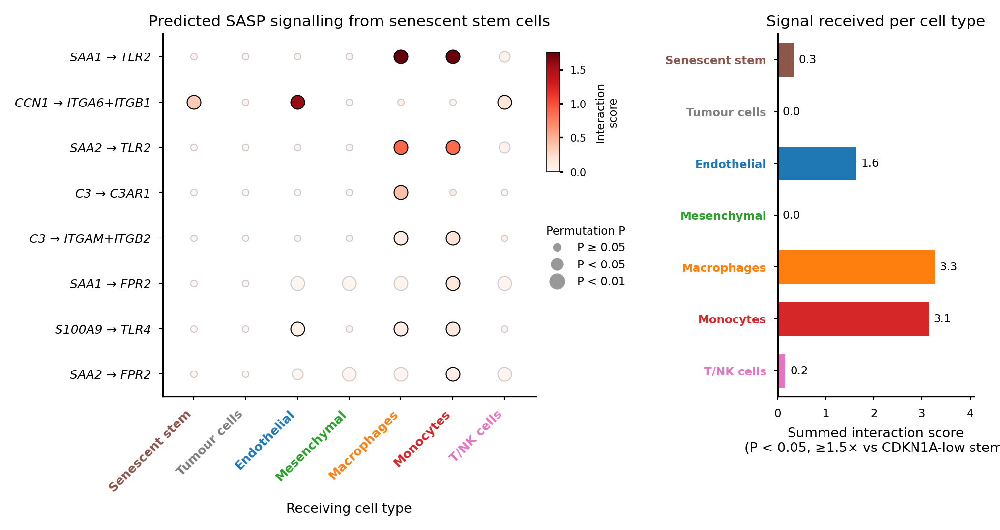

In [45]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

# =============================================================================
# Who receives the SASP?  Ligand-receptor inference WITHOUT LIANA (no extra packages).
# CellPhoneDB-style: score = mean ligand in sender x mean receptor in receiver
# (multi-subunit receptors use the lowest subunit); P value by permuting cell labels.
# Senders: senescent (CDKN1A-high) stem cells, compared with CDKN1A-low stem cells.
# Pairs: curated SASP ligand-receptor pairs (from CellPhoneDB / OmniPath).
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
q_high     = 0.90          # CDKN1A-high = top 10% of stem cells (as in Fig. 2E)
min_frac   = 0.10          # ligand / every receptor subunit detected in >= 10% of its group
n_perm     = 1000
max_per    = 5000          # downsample large groups for the permutations; None = all
seed       = 0
use_raw    = adata.raw is not None
min_fold   = 1.5           # plot only interactions >= 1.5x stronger from senescent than CDKN1A-low stem
                            # cells (removes ubiquitous ligands such as TIMP1/MIF); 1.0 = show all

pairs = [  # ligand, receptor (subunits joined by "+")
    ("CCL2", "CCR2"), ("CCL5", "CCR5"), ("CCL5", "CCR1"), ("CCL20", "CCR6"),
    ("CXCL1", "CXCR2"), ("CXCL2", "CXCR2"), ("CXCL8", "CXCR1"), ("CXCL8", "CXCR2"),
    ("CXCL10", "CXCR3"), ("CXCL12", "CXCR4"), ("CXCL12", "ACKR3"),
    ("IL6", "IL6R+IL6ST"), ("IL1A", "IL1R1+IL1RAP"), ("IL1B", "IL1R1+IL1RAP"),
    ("TNF", "TNFRSF1A"), ("TNF", "TNFRSF1B"), ("CSF1", "CSF1R"), ("IL15", "IL15RA+IL2RB"),
    ("SAA1", "FPR2"), ("SAA2", "FPR2"), ("SAA1", "TLR2"), ("SAA2", "TLR2"),
    ("S100A8", "TLR4"), ("S100A9", "TLR4"), ("S100A8", "AGER"), ("S100A9", "AGER"),
    ("C3", "C3AR1"), ("C3", "ITGAM+ITGB2"),
    ("IGFBP3", "TMEM219"), ("CCN2", "LRP1"), ("CCN2", "ITGAV+ITGB3"), ("CCN1", "ITGAV+ITGB3"),
    ("CCN2", "ITGA5+ITGB1"), ("CCN1", "ITGA6+ITGB1"),
    ("TGFB1", "TGFBR1+TGFBR2"), ("VEGFA", "KDR"), ("VEGFA", "FLT1"), ("VEGFA", "NRP1"),
    ("PGF", "FLT1"), ("FGF2", "FGFR1"), ("HGF", "MET"), ("AREG", "EGFR"), ("EREG", "EGFR"),
    ("GDF15", "GFRAL"), ("SPP1", "CD44"), ("SPP1", "ITGAV+ITGB1"), ("SERPINE1", "LRP1"),
    ("PLAU", "PLAUR"), ("MIF", "CD74+CD44"), ("MIF", "CXCR4"), ("ICAM1", "ITGAL+ITGB2"),
    ("FN1", "ITGA5+ITGB1"), ("TIMP1", "CD63"), ("BMP2", "BMPR1A+BMPR2"),
]
aliases = {"CCN2": "CTGF", "CCN1": "CYR61"}

# ---- 2. Groups -----------------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy().astype(object)
is_stem = ct == "Stem cells"
vn = adata.raw.var_names if use_raw else adata.var_names
g = lambda x: x if x in vn else aliases.get(x, x)
cdk = sc.get.obs_df(adata, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
thr = max(np.quantile(cdk[is_stem], q_high), cdk[is_stem & (cdk > 0)].min())
lab = ct.copy()
lab[is_stem & (cdk >= thr)] = "Senescent stem"
lab[is_stem & (cdk == 0)] = "Stem (CDKN1A-low)"
lab[is_stem & (cdk > 0) & (cdk < thr)] = "drop"

rng = np.random.default_rng(seed)
idx = []
for grp_ in pd.unique(lab):
    if grp_ == "drop":
        continue
    w = np.where(lab == grp_)[0]
    if max_per and len(w) > max_per:
        w = rng.choice(w, max_per, replace=False)
    idx.append(w)
idx = np.sort(np.concatenate(idx))
labs = lab[idx]
groups = [x for x in ["Senescent stem", "Stem (CDKN1A-low)", "Tumour cells", "Endothelial", "Mesenchymal",
                      "Macrophages", "Monocytes", "T/NK cells"] if x in set(labs)]
print("Cells per group:", pd.Series(labs).value_counts().to_dict())

# ---- 3. Expression of every gene in the pairs ---------------------------------
genes = sorted({g(x) for l, r in pairs for x in [l] + r.split("+")} & set(vn))
E = sc.get.obs_df(adata[idx], keys=genes, use_raw=use_raw)
E = E.to_numpy(dtype=float); gi = {x: i for i, x in enumerate(genes)}

def group_stats(labels_):
    M = np.vstack([E[labels_ == k].mean(0) for k in groups])          # groups x genes
    F = np.vstack([(E[labels_ == k] > 0).mean(0) for k in groups])
    return M, F

def score(M, F, l, r, s, t):
    if g(l) not in gi or any(g(x) not in gi for x in r.split("+")):
        return np.nan, False
    lm, lf = M[s, gi[g(l)]], F[s, gi[g(l)]]
    rm = min(M[t, gi[g(x)]] for x in r.split("+")); rf = min(F[t, gi[g(x)]] for x in r.split("+"))
    return lm * rm, (lf >= min_frac) and (rf >= min_frac)

M, F = group_stats(labs)
senders = [groups.index("Senescent stem"), groups.index("Stem (CDKN1A-low)")]
rows = []
for l, r in pairs:
    for s in senders:
        for t in range(len(groups)):
            sc_, ok = score(M, F, l, r, s, t)
            if np.isfinite(sc_):
                rows.append({"ligand": l, "receptor": r, "sender": groups[s], "receiver": groups[t],
                             "score": sc_, "expressed": ok})
res = pd.DataFrame(rows)

# ---- 4. Permutation P values (shuffle cell labels) ----------------------------
null_ge = np.zeros(len(res))
for _ in range(n_perm):
    Mp, Fp = group_stats(rng.permutation(labs))
    for k, row in enumerate(res.itertuples()):
        s, t = groups.index(row.sender), groups.index(row.receiver)
        null_ge[k] += score(Mp, Fp, row.ligand, row.receptor, s, t)[0] >= row.score
res["P"] = (null_ge + 1) / (n_perm + 1)

# senescent vs CDKN1A-low stem senders, same pair and receiver
piv = res.pivot_table(index=["ligand", "receptor", "receiver"], columns="sender", values="score")
res = res.merge(piv.rename(columns={"Senescent stem": "score_senescent",
                                    "Stem (CDKN1A-low)": "score_low_stem"}).reset_index(),
                on=["ligand", "receptor", "receiver"])
res["fold_vs_low_stem"] = (res["score_senescent"] + 1e-4) / (res["score_low_stem"] + 1e-4)
res.to_csv("SASP_ligand_receptor_all.csv", index=False)

sen = res[(res["sender"] == "Senescent stem") & res["expressed"] & (res["P"] < 0.05)]
sen = sen.sort_values("score", ascending=False)
sen.to_csv("SASP_ligand_receptor_senescent_significant.csv", index=False)
print(f"\nSignificant SASP interactions from senescent stem cells (P < 0.05, expressed): {len(sen)}")
print(sen[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].head(30)
      .round(4).to_string(index=False))
print("\nBy receiver:\n", sen["receiver"].value_counts().to_string())

# ---- 5. Plot (Supplementary Fig. 2E): dot plot | interactions per receiver ----
from matplotlib.gridspec import GridSpec
receivers = [x for x in groups if x != "Stem (CDKN1A-low)"]
spec = sen[sen["fold_vs_low_stem"] >= min_fold]
print(f"\nShown in plot (fold vs CDKN1A-low stem >= {min_fold}): "
      f"{spec[['ligand','receptor']].drop_duplicates().shape[0]} pairs")
print(spec[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].round(3).to_string(index=False))
top = spec.drop_duplicates(["ligand", "receptor"]).head(20)
pairs_shown = list(zip(top["ligand"], top["receptor"]))
allsen = res[res["sender"] == "Senescent stem"].set_index(["ligand", "receptor", "receiver"])
vmax = spec["score"].quantile(0.95) if len(spec) else 1
pal = {"Senescent stem": "#8c564b", "Tumour cells": "#7f7f7f", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728", "T/NK cells": "#e377c2"}
fs = {"title": 7.5, "label": 6.5, "small": 6}

h = 0.2 * max(len(pairs_shown), 4) + 1.6
fig = plt.figure(figsize=(7.1, h), dpi=300)
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.9, 1], wspace=0.85)

# left: ligand -> receptor x receiver
ax = fig.add_subplot(gs[0])
for i, (l, r) in enumerate(pairs_shown):
    for j, t in enumerate(receivers):
        if (l, r, t) not in allsen.index:
            continue
        row = allsen.loc[(l, r, t)]
        sig = row["expressed"] and row["P"] < 0.05
        size = 45 if row["P"] < 0.01 else 28 if row["P"] < 0.05 else 10
        ax.scatter(j, i, s=size, c=[row["score"]], cmap="Reds", vmin=0, vmax=vmax,
                   edgecolors="black" if sig else "#CCCCCC", linewidths=0.5)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([f"{l} \u2192 {r}" for l, r in pairs_shown], fontsize=fs["small"], fontstyle="italic")
ax.set_xticks(range(len(receivers)))
ax.set_xticklabels(receivers, rotation=45, ha="right", fontsize=fs["small"])
for lab_, t in zip(ax.get_xticklabels(), receivers):
    lab_.set_color(pal.get(t, "black")); lab_.set_fontweight("bold")
ax.set_xlim(-0.6, len(receivers) - 0.4); ax.set_ylim(len(pairs_shown) - 0.5, -0.5)
ax.set_xlabel("Receiving cell type", fontsize=fs["label"])
ax.set_title("Predicted SASP signalling from senescent stem cells", fontsize=fs["title"], pad=4)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.tick_params(length=2, width=0.5)
cax = ax.inset_axes([1.03, 0.62, 0.035, 0.33])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), cax=cax)
cb.set_label("Interaction\nscore", fontsize=fs["small"] - 0.5); cb.ax.tick_params(labelsize=5, length=1.5)
cb.outline.set_linewidth(0.4)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(s_), label=l_)
                   for s_, l_ in [(10, "P \u2265 0.05"), (28, "P < 0.05"), (45, "P < 0.01")]],
          title="Permutation P", loc="upper left", bbox_to_anchor=(1.0, 0.5), frameon=False,
          fontsize=5.5, title_fontsize=fs["small"] - 0.5)

# right: summed score of significant, senescence-specific interactions per receiver
# (a simple count is uninformative: permutation P mainly reflects the ligand, so the same
#  pairs pass in most receivers; the summed score weights each by receptor expression)
ax2 = fig.add_subplot(gs[1])
cnt = spec.groupby("receiver")["score"].sum().reindex(receivers, fill_value=0).round(2)
print("\nSummed interaction score per receiver:\n", cnt.to_string())
y = np.arange(len(receivers))
ax2.barh(y, cnt.values, color=[pal.get(t, "#999999") for t in receivers], height=0.65)
for yi, v in zip(y, cnt.values):
    ax2.text(v + max(cnt.max(), 1e-3) * 0.03, yi, f"{v:.1f}", va="center", fontsize=fs["small"] - 0.5)
ax2.set_yticks(y); ax2.set_yticklabels(receivers, fontsize=fs["small"])
for lab_, t in zip(ax2.get_yticklabels(), receivers):
    lab_.set_color(pal.get(t, "black")); lab_.set_fontweight("bold")
ax2.set_ylim(len(receivers) - 0.5, -0.5)
ax2.set_xlim(0, max(cnt.max(), 1e-3) * 1.25)
ax2.set_xlabel("Summed interaction score\n(P < 0.05, \u2265{:.1f}\u00d7 vs CDKN1A-low stem)".format(min_fold), fontsize=fs["label"])
ax2.set_title("Signal received per cell type", fontsize=fs["title"], pad=4)
ax2.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
for sp in ("top", "right"):
    ax2.spines[sp].set_visible(False)

fig.savefig("SuppFig2E_ligand_receptor.svg", bbox_inches="tight")
fig.savefig("SuppFig2E_ligand_receptor.pdf", bbox_inches="tight")
fig.savefig("SuppFig2E_ligand_receptor.png", dpi=600, bbox_inches="tight")
plt.show()

Cells per group: {'Tumour cells': 5000, 'Macrophages': 3035, 'Mesenchymal': 2540, 'Endothelial': 2000, 'Stem (CDKN1A-low)': 943, 'Monocytes': 424, 'T/NK cells': 332, 'Senescent stem': 126}

Significant SASP interactions from senescent stem cells (P < 0.05, expressed): 42
ligand    receptor          receiver  score     P  fold_vs_low_stem
 TIMP1        CD63       Mesenchymal 5.2204 0.001            1.2271
 TIMP1        CD63    Senescent stem 4.9720 0.001            1.2271
 TIMP1        CD63 Stem (CDKN1A-low) 4.7450 0.001            1.2271
 TIMP1        CD63       Macrophages 3.7970 0.001            1.2271
 TIMP1        CD63       Endothelial 3.7341 0.001            1.2271
   MIF       CXCR4        T/NK cells 2.6918 0.001            1.1417
 TIMP1        CD63         Monocytes 2.6624 0.019            1.2271
   MIF   CD74+CD44         Monocytes 2.5137 0.001            1.1417
   MIF       CXCR4         Monocytes 2.1392 0.001            1.1417
   MIF   CD74+CD44        T/NK cells 1.9412 0.00

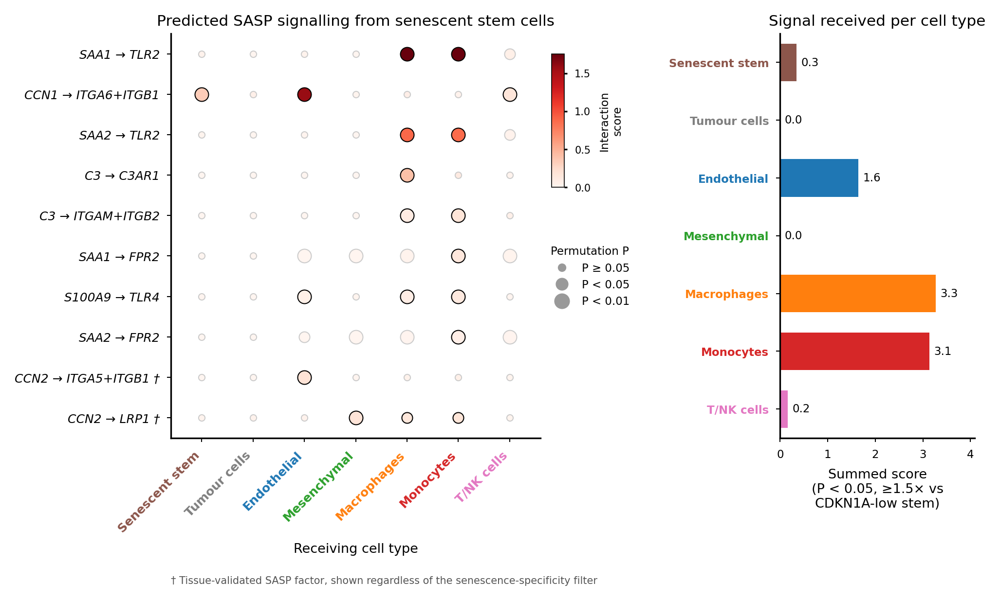

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

# =============================================================================
# Who receives the SASP?  Ligand-receptor inference WITHOUT LIANA (no extra packages).
# CellPhoneDB-style: score = mean ligand in sender x mean receptor in receiver
# (multi-subunit receptors use the lowest subunit); P value by permuting cell labels.
# Senders: senescent (CDKN1A-high) stem cells, compared with CDKN1A-low stem cells.
# Pairs: curated SASP ligand-receptor pairs (from CellPhoneDB / OmniPath).
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
q_high     = 0.90          # CDKN1A-high = top 10% of stem cells (as in Fig. 2E)
min_frac   = 0.10          # ligand / every receptor subunit detected in >= 10% of its group
n_perm     = 1000
max_per    = 5000          # downsample large groups for the permutations; None = all
seed       = 0
use_raw    = adata.raw is not None
always_show = ["CCN2", "CCL2"]   # tissue-stained SASP factors: plotted regardless of the fold filter (marked \u2020)
min_fold   = 1.5           # plot only interactions >= 1.5x stronger from senescent than CDKN1A-low stem
                            # cells (removes ubiquitous ligands such as TIMP1/MIF); 1.0 = show all

pairs = [  # ligand, receptor (subunits joined by "+")
    ("CCL2", "CCR2"), ("CCL5", "CCR5"), ("CCL5", "CCR1"), ("CCL20", "CCR6"),
    ("CXCL1", "CXCR2"), ("CXCL2", "CXCR2"), ("CXCL8", "CXCR1"), ("CXCL8", "CXCR2"),
    ("CXCL10", "CXCR3"), ("CXCL12", "CXCR4"), ("CXCL12", "ACKR3"),
    ("IL6", "IL6R+IL6ST"), ("IL1A", "IL1R1+IL1RAP"), ("IL1B", "IL1R1+IL1RAP"),
    ("TNF", "TNFRSF1A"), ("TNF", "TNFRSF1B"), ("CSF1", "CSF1R"), ("IL15", "IL15RA+IL2RB"),
    ("SAA1", "FPR2"), ("SAA2", "FPR2"), ("SAA1", "TLR2"), ("SAA2", "TLR2"),
    ("S100A8", "TLR4"), ("S100A9", "TLR4"), ("S100A8", "AGER"), ("S100A9", "AGER"),
    ("C3", "C3AR1"), ("C3", "ITGAM+ITGB2"),
    ("IGFBP3", "TMEM219"), ("CCN2", "LRP1"), ("CCN2", "ITGAV+ITGB3"), ("CCN1", "ITGAV+ITGB3"),
    ("CCN2", "ITGA5+ITGB1"), ("CCN1", "ITGA6+ITGB1"),
    ("TGFB1", "TGFBR1+TGFBR2"), ("VEGFA", "KDR"), ("VEGFA", "FLT1"), ("VEGFA", "NRP1"),
    ("PGF", "FLT1"), ("FGF2", "FGFR1"), ("HGF", "MET"), ("AREG", "EGFR"), ("EREG", "EGFR"),
    ("GDF15", "GFRAL"), ("SPP1", "CD44"), ("SPP1", "ITGAV+ITGB1"), ("SERPINE1", "LRP1"),
    ("PLAU", "PLAUR"), ("MIF", "CD74+CD44"), ("MIF", "CXCR4"), ("ICAM1", "ITGAL+ITGB2"),
    ("FN1", "ITGA5+ITGB1"), ("TIMP1", "CD63"), ("BMP2", "BMPR1A+BMPR2"),
]
aliases = {"CCN2": "CTGF", "CCN1": "CYR61"}

# ---- 2. Groups -----------------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy().astype(object)
is_stem = ct == "Stem cells"
vn = adata.raw.var_names if use_raw else adata.var_names
g = lambda x: x if x in vn else aliases.get(x, x)
cdk = sc.get.obs_df(adata, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
thr = max(np.quantile(cdk[is_stem], q_high), cdk[is_stem & (cdk > 0)].min())
lab = ct.copy()
lab[is_stem & (cdk >= thr)] = "Senescent stem"
lab[is_stem & (cdk == 0)] = "Stem (CDKN1A-low)"
lab[is_stem & (cdk > 0) & (cdk < thr)] = "drop"

rng = np.random.default_rng(seed)
idx = []
for grp_ in pd.unique(lab):
    if grp_ == "drop":
        continue
    w = np.where(lab == grp_)[0]
    if max_per and len(w) > max_per:
        w = rng.choice(w, max_per, replace=False)
    idx.append(w)
idx = np.sort(np.concatenate(idx))
labs = lab[idx]
groups = [x for x in ["Senescent stem", "Stem (CDKN1A-low)", "Tumour cells", "Endothelial", "Mesenchymal",
                      "Macrophages", "Monocytes", "T/NK cells"] if x in set(labs)]
print("Cells per group:", pd.Series(labs).value_counts().to_dict())

# ---- 3. Expression of every gene in the pairs ---------------------------------
genes = sorted({g(x) for l, r in pairs for x in [l] + r.split("+")} & set(vn))
E = sc.get.obs_df(adata[idx], keys=genes, use_raw=use_raw)
E = E.to_numpy(dtype=float); gi = {x: i for i, x in enumerate(genes)}

def group_stats(labels_):
    M = np.vstack([E[labels_ == k].mean(0) for k in groups])          # groups x genes
    F = np.vstack([(E[labels_ == k] > 0).mean(0) for k in groups])
    return M, F

def score(M, F, l, r, s, t):
    if g(l) not in gi or any(g(x) not in gi for x in r.split("+")):
        return np.nan, False
    lm, lf = M[s, gi[g(l)]], F[s, gi[g(l)]]
    rm = min(M[t, gi[g(x)]] for x in r.split("+")); rf = min(F[t, gi[g(x)]] for x in r.split("+"))
    return lm * rm, (lf >= min_frac) and (rf >= min_frac)

M, F = group_stats(labs)
senders = [groups.index("Senescent stem"), groups.index("Stem (CDKN1A-low)")]
rows = []
for l, r in pairs:
    for s in senders:
        for t in range(len(groups)):
            sc_, ok = score(M, F, l, r, s, t)
            if np.isfinite(sc_):
                rows.append({"ligand": l, "receptor": r, "sender": groups[s], "receiver": groups[t],
                             "score": sc_, "expressed": ok})
res = pd.DataFrame(rows)

# ---- 4. Permutation P values (shuffle cell labels) ----------------------------
null_ge = np.zeros(len(res))
for _ in range(n_perm):
    Mp, Fp = group_stats(rng.permutation(labs))
    for k, row in enumerate(res.itertuples()):
        s, t = groups.index(row.sender), groups.index(row.receiver)
        null_ge[k] += score(Mp, Fp, row.ligand, row.receptor, s, t)[0] >= row.score
res["P"] = (null_ge + 1) / (n_perm + 1)

# senescent vs CDKN1A-low stem senders, same pair and receiver
piv = res.pivot_table(index=["ligand", "receptor", "receiver"], columns="sender", values="score")
res = res.merge(piv.rename(columns={"Senescent stem": "score_senescent",
                                    "Stem (CDKN1A-low)": "score_low_stem"}).reset_index(),
                on=["ligand", "receptor", "receiver"])
res["fold_vs_low_stem"] = (res["score_senescent"] + 1e-4) / (res["score_low_stem"] + 1e-4)
res.to_csv("SASP_ligand_receptor_all.csv", index=False)

sen = res[(res["sender"] == "Senescent stem") & res["expressed"] & (res["P"] < 0.05)]
sen = sen.sort_values("score", ascending=False)
sen.to_csv("SASP_ligand_receptor_senescent_significant.csv", index=False)
print(f"\nSignificant SASP interactions from senescent stem cells (P < 0.05, expressed): {len(sen)}")
print(sen[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].head(30)
      .round(4).to_string(index=False))
print("\nBy receiver:\n", sen["receiver"].value_counts().to_string())

# ---- 5. Plot (Supplementary Fig. 2E): dot plot | interactions per receiver ----
from matplotlib.gridspec import GridSpec
receivers = [x for x in groups if x != "Stem (CDKN1A-low)"]
spec = sen[sen["fold_vs_low_stem"] >= min_fold]
print(f"\nShown in plot (fold vs CDKN1A-low stem >= {min_fold}): "
      f"{spec[['ligand','receptor']].drop_duplicates().shape[0]} pairs")
print(spec[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].round(3).to_string(index=False))
top = spec.drop_duplicates(["ligand", "receptor"]).head(20)
pairs_shown = list(zip(top["ligand"], top["receptor"]))
allsen = res[res["sender"] == "Senescent stem"].set_index(["ligand", "receptor", "receiver"])
# add the tissue-stained factors (e.g. CCN2/CTGF) even if not senescence-specific
extra = res[(res["sender"] == "Senescent stem") & res["ligand"].isin(always_show)]
extra_sig = extra[extra["expressed"] & (extra["P"] < 0.05)]
extra = extra_sig if len(extra_sig) else extra
for l, r in extra.sort_values("score", ascending=False)[["ligand", "receptor"]].drop_duplicates().itertuples(index=False):
    if (l, r) not in pairs_shown:
        pairs_shown.append((l, r))
dagger = {l for l, _ in pairs_shown if l in always_show and l not in set(spec["ligand"])}
print("\nAdded regardless of fold filter (\u2020):")
print(extra[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].round(3).to_string(index=False))
vmax = spec["score"].quantile(0.95) if len(spec) else 1
pal = {"Senescent stem": "#8c564b", "Tumour cells": "#7f7f7f", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728", "T/NK cells": "#e377c2"}
fs = {"title": 7.5, "label": 6.5, "small": 6}

h = 0.2 * max(len(pairs_shown), 4) + 1.6
fig = plt.figure(figsize=(7.1, h), dpi=300)
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.9, 1], wspace=0.85)

# left: ligand -> receptor x receiver
ax = fig.add_subplot(gs[0])
for i, (l, r) in enumerate(pairs_shown):
    for j, t in enumerate(receivers):
        if (l, r, t) not in allsen.index:
            continue
        row = allsen.loc[(l, r, t)]
        sig = row["expressed"] and row["P"] < 0.05
        size = 45 if row["P"] < 0.01 else 28 if row["P"] < 0.05 else 10
        ax.scatter(j, i, s=size, c=[row["score"]], cmap="Reds", vmin=0, vmax=vmax,
                   edgecolors="black" if sig else "#CCCCCC", linewidths=0.5)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([f"{l} \u2192 {r}" + (" \u2020" if l in dagger else "") for l, r in pairs_shown],
                   fontsize=fs["small"], fontstyle="italic")
if dagger:
    ax.text(0.0, -0.36, "\u2020 Tissue-validated SASP factor, shown regardless of the senescence-specificity filter",
            transform=ax.transAxes, fontsize=fs["small"] - 1, color="#555555")
ax.set_xticks(range(len(receivers)))
ax.set_xticklabels(receivers, rotation=45, ha="right", fontsize=fs["small"])
for lab_, t in zip(ax.get_xticklabels(), receivers):
    lab_.set_color(pal.get(t, "black")); lab_.set_fontweight("bold")
ax.set_xlim(-0.6, len(receivers) - 0.4); ax.set_ylim(len(pairs_shown) - 0.5, -0.5)
ax.set_xlabel("Receiving cell type", fontsize=fs["label"])
ax.set_title("Predicted SASP signalling from senescent stem cells", fontsize=fs["title"], pad=4)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.tick_params(length=2, width=0.5)
cax = ax.inset_axes([1.03, 0.62, 0.035, 0.33])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), cax=cax)
cb.set_label("Interaction\nscore", fontsize=fs["small"] - 0.5); cb.ax.tick_params(labelsize=5, length=1.5)
cb.outline.set_linewidth(0.4)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(s_), label=l_)
                   for s_, l_ in [(10, "P \u2265 0.05"), (28, "P < 0.05"), (45, "P < 0.01")]],
          title="Permutation P", loc="upper left", bbox_to_anchor=(1.0, 0.5), frameon=False,
          fontsize=5.5, title_fontsize=fs["small"] - 0.5)

# right: summed score of significant, senescence-specific interactions per receiver
# (a simple count is uninformative: permutation P mainly reflects the ligand, so the same
#  pairs pass in most receivers; the summed score weights each by receptor expression)
ax2 = fig.add_subplot(gs[1])
cnt = spec.groupby("receiver")["score"].sum().reindex(receivers, fill_value=0).round(2)
print("\nSummed interaction score per receiver:\n", cnt.to_string())
y = np.arange(len(receivers))
ax2.barh(y, cnt.values, color=[pal.get(t, "#999999") for t in receivers], height=0.65)
for yi, v in zip(y, cnt.values):
    ax2.text(v + max(cnt.max(), 1e-3) * 0.03, yi, f"{v:.1f}", va="center", fontsize=fs["small"] - 0.5)
ax2.set_yticks(y); ax2.set_yticklabels(receivers, fontsize=fs["small"])
for lab_, t in zip(ax2.get_yticklabels(), receivers):
    lab_.set_color(pal.get(t, "black")); lab_.set_fontweight("bold")
ax2.set_ylim(len(receivers) - 0.5, -0.5)
ax2.set_xlim(0, max(cnt.max(), 1e-3) * 1.25)
ax2.set_xlabel("Summed score\n(P < 0.05, \u2265{:.1f}\u00d7 vs\nCDKN1A-low stem)".format(min_fold), fontsize=fs["label"])
ax2.set_title("Signal received per cell type", fontsize=fs["title"], pad=4)
ax2.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
for sp in ("top", "right"):
    ax2.spines[sp].set_visible(False)

fig.savefig("SuppFig2E_ligand_receptor.svg", bbox_inches="tight")
fig.savefig("SuppFig2E_ligand_receptor.pdf", bbox_inches="tight")
fig.savefig("SuppFig2E_ligand_receptor.png", dpi=600, bbox_inches="tight")
plt.show()

Cells per group: {'Tumour cells': 5000, 'Macrophages': 3035, 'Mesenchymal': 2540, 'Endothelial': 2000, 'Stem (CDKN1A-low)': 943, 'Monocytes': 424, 'T/NK cells': 332, 'Senescent stem': 126}

Significant SASP interactions from senescent stem cells (P < 0.05, expressed): 42
ligand    receptor          receiver  score     P  fold_vs_low_stem
 TIMP1        CD63       Mesenchymal 5.2204 0.001            1.2271
 TIMP1        CD63    Senescent stem 4.9720 0.001            1.2271
 TIMP1        CD63 Stem (CDKN1A-low) 4.7450 0.001            1.2271
 TIMP1        CD63       Macrophages 3.7970 0.001            1.2271
 TIMP1        CD63       Endothelial 3.7341 0.001            1.2271
   MIF       CXCR4        T/NK cells 2.6918 0.001            1.1417
 TIMP1        CD63         Monocytes 2.6624 0.019            1.2271
   MIF   CD74+CD44         Monocytes 2.5137 0.001            1.1417
   MIF       CXCR4         Monocytes 2.1392 0.001            1.1417
   MIF   CD74+CD44        T/NK cells 1.9412 0.00

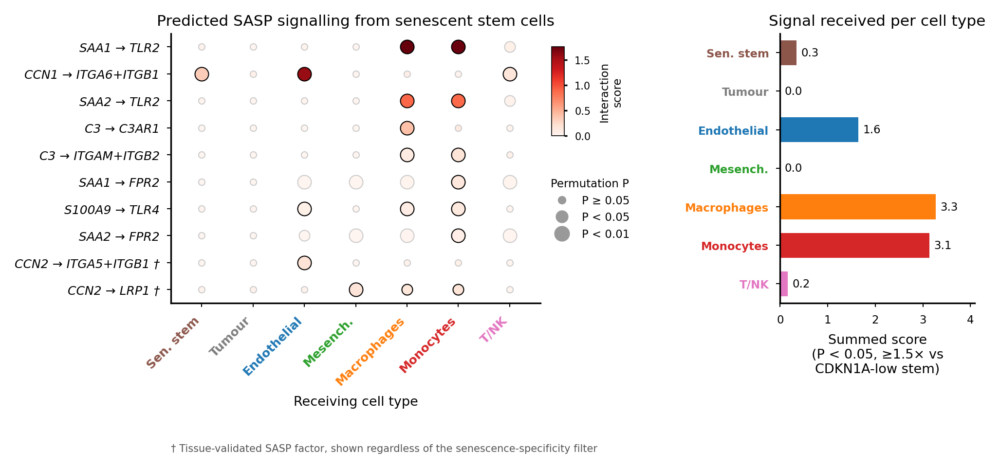

In [47]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

# =============================================================================
# Who receives the SASP?  Ligand-receptor inference WITHOUT LIANA (no extra packages).
# CellPhoneDB-style: score = mean ligand in sender x mean receptor in receiver
# (multi-subunit receptors use the lowest subunit); P value by permuting cell labels.
# Senders: senescent (CDKN1A-high) stem cells, compared with CDKN1A-low stem cells.
# Pairs: curated SASP ligand-receptor pairs (from CellPhoneDB / OmniPath).
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col  = "final_cell_type_broad"
q_high     = 0.90          # CDKN1A-high = top 10% of stem cells (as in Fig. 2E)
min_frac   = 0.10          # ligand / every receptor subunit detected in >= 10% of its group
n_perm     = 1000
max_per    = 5000          # downsample large groups for the permutations; None = all
seed       = 0
use_raw    = adata.raw is not None
always_show = ["CCN2", "CCL2"]   # tissue-stained SASP factors: plotted regardless of the fold filter (marked †)
min_fold   = 1.5           # plot only interactions >= 1.5x stronger from senescent than CDKN1A-low stem
                            # cells (removes ubiquitous ligands such as TIMP1/MIF); 1.0 = show all

pairs = [  # ligand, receptor (subunits joined by "+")
    ("CCL2", "CCR2"), ("CCL5", "CCR5"), ("CCL5", "CCR1"), ("CCL20", "CCR6"),
    ("CXCL1", "CXCR2"), ("CXCL2", "CXCR2"), ("CXCL8", "CXCR1"), ("CXCL8", "CXCR2"),
    ("CXCL10", "CXCR3"), ("CXCL12", "CXCR4"), ("CXCL12", "ACKR3"),
    ("IL6", "IL6R+IL6ST"), ("IL1A", "IL1R1+IL1RAP"), ("IL1B", "IL1R1+IL1RAP"),
    ("TNF", "TNFRSF1A"), ("TNF", "TNFRSF1B"), ("CSF1", "CSF1R"), ("IL15", "IL15RA+IL2RB"),
    ("SAA1", "FPR2"), ("SAA2", "FPR2"), ("SAA1", "TLR2"), ("SAA2", "TLR2"),
    ("S100A8", "TLR4"), ("S100A9", "TLR4"), ("S100A8", "AGER"), ("S100A9", "AGER"),
    ("C3", "C3AR1"), ("C3", "ITGAM+ITGB2"),
    ("IGFBP3", "TMEM219"), ("CCN2", "LRP1"), ("CCN2", "ITGAV+ITGB3"), ("CCN1", "ITGAV+ITGB3"),
    ("CCN2", "ITGA5+ITGB1"), ("CCN1", "ITGA6+ITGB1"),
    ("TGFB1", "TGFBR1+TGFBR2"), ("VEGFA", "KDR"), ("VEGFA", "FLT1"), ("VEGFA", "NRP1"),
    ("PGF", "FLT1"), ("FGF2", "FGFR1"), ("HGF", "MET"), ("AREG", "EGFR"), ("EREG", "EGFR"),
    ("GDF15", "GFRAL"), ("SPP1", "CD44"), ("SPP1", "ITGAV+ITGB1"), ("SERPINE1", "LRP1"),
    ("PLAU", "PLAUR"), ("MIF", "CD74+CD44"), ("MIF", "CXCR4"), ("ICAM1", "ITGAL+ITGB2"),
    ("FN1", "ITGA5+ITGB1"), ("TIMP1", "CD63"), ("BMP2", "BMPR1A+BMPR2"),
]
aliases = {"CCN2": "CTGF", "CCN1": "CYR61"}

# ---- 2. Groups -----------------------------------------------------------------
ct = adata.obs[label_col].astype(str).replace({
    "Stem_cells": "Stem cells", "Pituicytes": "Tumour cells", "Endothelial_cells": "Endothelial",
    "Mesenchymal_cells": "Mesenchymal", "T_or_NK_cells": "T/NK cells"}).to_numpy().astype(object)
is_stem = ct == "Stem cells"
vn = adata.raw.var_names if use_raw else adata.var_names
g = lambda x: x if x in vn else aliases.get(x, x)
cdk = sc.get.obs_df(adata, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
thr = max(np.quantile(cdk[is_stem], q_high), cdk[is_stem & (cdk > 0)].min())
lab = ct.copy()
lab[is_stem & (cdk >= thr)] = "Senescent stem"
lab[is_stem & (cdk == 0)] = "Stem (CDKN1A-low)"
lab[is_stem & (cdk > 0) & (cdk < thr)] = "drop"

rng = np.random.default_rng(seed)
idx = []
for grp_ in pd.unique(lab):
    if grp_ == "drop":
        continue
    w = np.where(lab == grp_)[0]
    if max_per and len(w) > max_per:
        w = rng.choice(w, max_per, replace=False)
    idx.append(w)
idx = np.sort(np.concatenate(idx))
labs = lab[idx]
groups = [x for x in ["Senescent stem", "Stem (CDKN1A-low)", "Tumour cells", "Endothelial", "Mesenchymal",
                      "Macrophages", "Monocytes", "T/NK cells"] if x in set(labs)]
print("Cells per group:", pd.Series(labs).value_counts().to_dict())

# ---- 3. Expression of every gene in the pairs ---------------------------------
genes = sorted({g(x) for l, r in pairs for x in [l] + r.split("+")} & set(vn))
E = sc.get.obs_df(adata[idx], keys=genes, use_raw=use_raw)
E = E.to_numpy(dtype=float); gi = {x: i for i, x in enumerate(genes)}

def group_stats(labels_):
    M = np.vstack([E[labels_ == k].mean(0) for k in groups])          # groups x genes
    F = np.vstack([(E[labels_ == k] > 0).mean(0) for k in groups])
    return M, F

def score(M, F, l, r, s, t):
    if g(l) not in gi or any(g(x) not in gi for x in r.split("+")):
        return np.nan, False
    lm, lf = M[s, gi[g(l)]], F[s, gi[g(l)]]
    rm = min(M[t, gi[g(x)]] for x in r.split("+")); rf = min(F[t, gi[g(x)]] for x in r.split("+"))
    return lm * rm, (lf >= min_frac) and (rf >= min_frac)

M, F = group_stats(labs)
senders = [groups.index("Senescent stem"), groups.index("Stem (CDKN1A-low)")]
rows = []
for l, r in pairs:
    for s in senders:
        for t in range(len(groups)):
            sc_, ok = score(M, F, l, r, s, t)
            if np.isfinite(sc_):
                rows.append({"ligand": l, "receptor": r, "sender": groups[s], "receiver": groups[t],
                             "score": sc_, "expressed": ok})
res = pd.DataFrame(rows)

# ---- 4. Permutation P values (shuffle cell labels) ----------------------------
null_ge = np.zeros(len(res))
for _ in range(n_perm):
    Mp, Fp = group_stats(rng.permutation(labs))
    for k, row in enumerate(res.itertuples()):
        s, t = groups.index(row.sender), groups.index(row.receiver)
        null_ge[k] += score(Mp, Fp, row.ligand, row.receptor, s, t)[0] >= row.score
res["P"] = (null_ge + 1) / (n_perm + 1)

# senescent vs CDKN1A-low stem senders, same pair and receiver
piv = res.pivot_table(index=["ligand", "receptor", "receiver"], columns="sender", values="score")
res = res.merge(piv.rename(columns={"Senescent stem": "score_senescent",
                                    "Stem (CDKN1A-low)": "score_low_stem"}).reset_index(),
                on=["ligand", "receptor", "receiver"])
res["fold_vs_low_stem"] = (res["score_senescent"] + 1e-4) / (res["score_low_stem"] + 1e-4)
res.to_csv("SASP_ligand_receptor_all.csv", index=False)

sen = res[(res["sender"] == "Senescent stem") & res["expressed"] & (res["P"] < 0.05)]
sen = sen.sort_values("score", ascending=False)
sen.to_csv("SASP_ligand_receptor_senescent_significant.csv", index=False)
print(f"\nSignificant SASP interactions from senescent stem cells (P < 0.05, expressed): {len(sen)}")
print(sen[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].head(30)
      .round(4).to_string(index=False))
print("\nBy receiver:\n", sen["receiver"].value_counts().to_string())

# ---- 5. Plot (Supplementary Fig. 2E): dot plot | interactions per receiver ----
from matplotlib.gridspec import GridSpec
receivers = [x for x in groups if x != "Stem (CDKN1A-low)"]
spec = sen[sen["fold_vs_low_stem"] >= min_fold]
print(f"\nShown in plot (fold vs CDKN1A-low stem >= {min_fold}): "
      f"{spec[['ligand','receptor']].drop_duplicates().shape[0]} pairs")
print(spec[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].round(3).to_string(index=False))
top = spec.drop_duplicates(["ligand", "receptor"]).head(20)
pairs_shown = list(zip(top["ligand"], top["receptor"]))
allsen = res[res["sender"] == "Senescent stem"].set_index(["ligand", "receptor", "receiver"])
# add the tissue-stained factors (e.g. CCN2/CTGF) even if not senescence-specific
extra = res[(res["sender"] == "Senescent stem") & res["ligand"].isin(always_show)]
extra_sig = extra[extra["expressed"] & (extra["P"] < 0.05)]
extra = extra_sig if len(extra_sig) else extra
for l, r in extra.sort_values("score", ascending=False)[["ligand", "receptor"]].drop_duplicates().itertuples(index=False):
    if (l, r) not in pairs_shown:
        pairs_shown.append((l, r))
dagger = {l for l, _ in pairs_shown if l in always_show and l not in set(spec["ligand"])}
print("\nAdded regardless of fold filter (†):")
print(extra[["ligand", "receptor", "receiver", "score", "P", "fold_vs_low_stem"]].round(3).to_string(index=False))
vmax = spec["score"].quantile(0.95) if len(spec) else 1
pal = {"Senescent stem": "#8c564b", "Tumour cells": "#7f7f7f", "Endothelial": "#1f77b4",
       "Mesenchymal": "#2ca02c", "Macrophages": "#ff7f0e", "Monocytes": "#d62728", "T/NK cells": "#e377c2"}
fs = {"title": 7.5, "label": 6.5, "small": 6}

h = 0.13 * max(len(pairs_shown), 4) + 1.1
short = {"Senescent stem": "Sen. stem", "Tumour cells": "Tumour", "Endothelial": "Endothelial",
         "Mesenchymal": "Mesench.", "Macrophages": "Macrophages", "Monocytes": "Monocytes", "T/NK cells": "T/NK"}
fig = plt.figure(figsize=(7.1, h), dpi=300)
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.9, 1], wspace=0.85)

# left: ligand -> receptor x receiver
ax = fig.add_subplot(gs[0])
for i, (l, r) in enumerate(pairs_shown):
    for j, t in enumerate(receivers):
        if (l, r, t) not in allsen.index:
            continue
        row = allsen.loc[(l, r, t)]
        sig = row["expressed"] and row["P"] < 0.05
        size = 45 if row["P"] < 0.01 else 28 if row["P"] < 0.05 else 10
        ax.scatter(j, i, s=size, c=[row["score"]], cmap="Reds", vmin=0, vmax=vmax,
                   edgecolors="black" if sig else "#CCCCCC", linewidths=0.5)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([f"{l} → {r}" + (" †" if l in dagger else "") for l, r in pairs_shown],
                   fontsize=fs["small"], fontstyle="italic")
if dagger:
    ax.text(0.0, -0.55, "† Tissue-validated SASP factor, shown regardless of the senescence-specificity filter",
            transform=ax.transAxes, fontsize=fs["small"] - 1, color="#555555")
ax.set_xticks(range(len(receivers)))
ax.set_xticklabels([short.get(t, t) for t in receivers], rotation=45, ha="right", fontsize=fs["small"])
for lab_, t in zip(ax.get_xticklabels(), receivers):
    lab_.set_color(pal.get(t, "black")); lab_.set_fontweight("bold")
ax.set_xlim(-0.6, len(receivers) - 0.4); ax.set_ylim(len(pairs_shown) - 0.5, -0.5)
ax.set_xlabel("Receiving cell type", fontsize=fs["label"])
ax.set_title("Predicted SASP signalling from senescent stem cells", fontsize=fs["title"], pad=4)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.tick_params(length=2, width=0.5)
cax = ax.inset_axes([1.03, 0.62, 0.035, 0.33])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Reds", norm=plt.Normalize(0, vmax)), cax=cax)
cb.set_label("Interaction\nscore", fontsize=fs["small"] - 0.5); cb.ax.tick_params(labelsize=5, length=1.5)
cb.outline.set_linewidth(0.4)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#999999", markersize=np.sqrt(s_), label=l_)
                   for s_, l_ in [(10, "P ≥ 0.05"), (28, "P < 0.05"), (45, "P < 0.01")]],
          title="Permutation P", loc="upper left", bbox_to_anchor=(1.0, 0.5), frameon=False,
          fontsize=5.5, title_fontsize=fs["small"] - 0.5)

# right: summed score of significant, senescence-specific interactions per receiver
# (a simple count is uninformative: permutation P mainly reflects the ligand, so the same
#  pairs pass in most receivers; the summed score weights each by receptor expression)
ax2 = fig.add_subplot(gs[1])
cnt = spec.groupby("receiver")["score"].sum().reindex(receivers, fill_value=0).round(2)
print("\nSummed interaction score per receiver:\n", cnt.to_string())
y = np.arange(len(receivers))
ax2.barh(y, cnt.values, color=[pal.get(t, "#999999") for t in receivers], height=0.65)
for yi, v in zip(y, cnt.values):
    ax2.text(v + max(cnt.max(), 1e-3) * 0.03, yi, f"{v:.1f}", va="center", fontsize=fs["small"] - 0.5)
ax2.set_yticks(y); ax2.set_yticklabels([short.get(t, t) for t in receivers], fontsize=fs["small"])
for lab_, t in zip(ax2.get_yticklabels(), receivers):
    lab_.set_color(pal.get(t, "black")); lab_.set_fontweight("bold")
ax2.set_ylim(len(receivers) - 0.5, -0.5)
ax2.set_xlim(0, max(cnt.max(), 1e-3) * 1.25)
ax2.set_xlabel("Summed score\n(P < 0.05, ≥{:.1f}× vs\nCDKN1A-low stem)".format(min_fold), fontsize=fs["label"])
ax2.set_title("Signal received per cell type", fontsize=fs["title"], pad=4)
ax2.tick_params(labelsize=fs["small"] - 0.5, length=2, width=0.5)
for sp in ("top", "right"):
    ax2.spines[sp].set_visible(False)

fig.savefig("SuppFig2E_ligand_receptor.svg", bbox_inches="tight")
fig.savefig("SuppFig2E_ligand_receptor.pdf", bbox_inches="tight")
fig.savefig("SuppFig2E_ligand_receptor.png", dpi=600, bbox_inches="tight")
plt.show()

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon

# Figure 2E: within STEM cells, is SASP expression higher in senescent (p21+ and/or p16+)
# than in non-senescent stem cells? One paired point per tumour, same style as panel B.

# ---- 1. Configuration --------------------------------------------------------
sasp_genes = ["CCN2", "IGFBP3", "CCL2"]
sen_genes  = ["CDKN1A", "CDKN2A"]                 # senescent = either detected
aliases    = {"CCN2": "CTGF"}
display    = {"CCN2": "CCN2 (CTGF)", "CTGF": "CCN2 (CTGF)"}
label_col  = "final_cell_type_broad"
sample_col = "SRA_ID"
mod_col    = "modality_label"
min_group  = 10                                   # need >= this many cells in BOTH stem groups
groups     = ["p21/p16−", "p21/p16+"]
colors     = {"p21/p16−": "#C9A9A0", "p21/p16+": "#8c564b"}
markers    = {"scRNA-seq (whole cells)": "o", "snMultiome (nuclei)": "^"}
fig_size   = (3.6, 2.4)
use_raw    = adata.raw is not None
n_ctrl     = 200                                  # random control genes (see step 3)

# ---- 2. Stem cells, senescence status ---------------------------------------
vn = adata.raw.var_names if use_raw else adata.var_names
sasp_genes = [g if g in vn else aliases.get(g, g) for g in sasp_genes]
sasp_genes = [g for g in sasp_genes if g in vn]
sen_genes = [g for g in sen_genes if g in vn]

ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"]
obs = stem.obs[[sample_col, mod_col]].astype(str).copy()
E = sc.get.obs_df(stem, keys=sasp_genes + sen_genes, use_raw=use_raw) > 0
E.index = obs.index
obs["sen"] = np.where(E[sen_genes].any(axis=1), groups[1], groups[0])

counts = obs.groupby([sample_col, "sen"]).size().unstack(fill_value=0).reindex(columns=groups, fill_value=0)
keep = counts.index[(counts[groups[0]] >= min_group) & (counts[groups[1]] >= min_group)]
print("Stem cells per tumour (senescent split):\n", counts.to_string())
print(f"\nTumours included (>= {min_group} cells in both groups): {len(keep)}")
mod = obs.groupby(sample_col)[mod_col].first()

pct = {g: (E[g].groupby([obs[sample_col], obs["sen"]]).mean() * 100).unstack().loc[keep, groups]
       for g in sasp_genes}

# ---- 3. Control for sequencing depth ----------------------------------------
# Cells with more reads detect more genes of every kind, so p21/p16+ cells could show
# more SASP detection simply because they are better sequenced. Compare with random genes
# detected in a similar fraction of stem cells: the SASP difference should exceed this.
if "total_counts" in stem.obs:
    tc = stem.obs["total_counts"].astype(float).groupby([obs[sample_col], obs["sen"]]).median().unstack()
    print("\nMedian UMIs per stem cell (p21/p16− vs +):\n", tc.loc[keep, groups].round(0).to_string())
rng = np.random.default_rng(0)
Xs = stem.raw.X if use_raw else stem.X
det = np.asarray((Xs > 0).mean(axis=0)).ravel()
pool = np.where((det > 0.05) & (det < 0.7))[0]
ctrl_idx = rng.choice(pool, size=min(n_ctrl, len(pool)), replace=False)
Xc = Xs[:, ctrl_idx]
Xc = (Xc.toarray() if hasattr(Xc, "toarray") else np.asarray(Xc)) > 0
ctrl_diff = []
for s in keep:
    m = (obs[sample_col] == s).to_numpy()
    pos, neg = m & (obs["sen"] == groups[1]).to_numpy(), m & (obs["sen"] == groups[0]).to_numpy()
    ctrl_diff.append((Xc[pos].mean(0) - Xc[neg].mean(0)).mean() * 100)
print(f"\nRandom control genes: median +/− difference = {np.median(ctrl_diff):.1f} percentage points "
      "(depth effect; SASP differences should be clearly larger)")

# ---- 4. Plot -----------------------------------------------------------------
fig, axes = plt.subplots(1, len(sasp_genes), figsize=fig_size, dpi=300)
axes = np.atleast_1d(axes)
print("\nGene            p21/p16− median %  p21/p16+ median %  +>−      P      median diff  vs control")
for ax, g in zip(axes, sasp_genes):
    d = pct[g]
    p = wilcoxon(d[groups[1]], d[groups[0]]).pvalue
    n_up = int((d[groups[1]] > d[groups[0]]).sum())
    diff = (d[groups[1]] - d[groups[0]]).median()
    print(f"{display.get(g, g):<15} {d[groups[0]].median():>17.1f} {d[groups[1]].median():>18.1f} "
          f"{n_up:>3}/{len(d):<3} {p:>8.3g} {diff:>10.1f} {diff - np.median(ctrl_diff):>10.1f}")

    jit_rng = np.random.default_rng(0)
    for s, row in d.iterrows():
        jit = jit_rng.uniform(-0.04, 0.04)
        ax.plot([0 + jit, 1 + jit], row[groups].to_numpy(), color="#BBBBBB", lw=0.6, zorder=1)
        for i, grp in enumerate(groups):
            ax.scatter(i + jit, row[grp], s=14, color=colors[grp], marker=markers.get(mod[s], "o"),
                       edgecolors="white", linewidths=0.4, zorder=2)
    for i, grp in enumerate(groups):
        ax.hlines(d[grp].median(), i - 0.18, i + 0.18, color="black", lw=1.2, zorder=3)

    ax.set_title(display.get(g, g), fontsize=7, fontstyle="italic", pad=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["−", "+"], fontsize=8)
    ax.set_xlabel("p21/p16", fontsize=6, labelpad=1)
    for lab, grp in zip(ax.get_xticklabels(), groups):
        lab.set_color(colors[grp] if grp == groups[1] else "#9a7a70"); lab.set_fontweight("bold")
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(bottom=0)
    ax.tick_params(labelsize=6, length=2, width=0.5)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    top = d.to_numpy().max()
    yb = top * 1.08 + 0.5
    ax.plot([0, 0, 1, 1], [yb - top * 0.02, yb, yb, yb - top * 0.02], color="black", lw=0.6)
    ax.text(0.5, yb + top * 0.01,
            "P < 0.001" if p < 0.001 else f"P = {p:.3f}" if p < 0.01 else f"P = {p:.2f}",
            ha="center", va="bottom", fontsize=6)
    ax.set_ylim(top=yb + top * 0.15 + 1)

axes[0].set_ylabel("Stem cells expressing (%)\n(per tumour)", fontsize=7)
fig.text(0.5, -0.02, f"Stem cells only · n = {len(keep)} tumours", ha="center", fontsize=6, color="#555555")
present = [m for m in markers if m in set(mod[keep])]
if len(present) > 1:
    fig.legend(handles=[Line2D([], [], marker=markers[m], ls="", color="#666666", markersize=4, label=m)
                        for m in present],
               loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False, fontsize=6,
               handletextpad=0.3)
fig.tight_layout(w_pad=1.0)

fig.savefig("Fig2E_SASP_by_senescence.pdf", bbox_inches="tight")
fig.savefig("Fig2E_SASP_by_senescence.svg", bbox_inches="tight")
fig.savefig("Fig2E_SASP_by_senescence.png", dpi=600, bbox_inches="tight")
plt.show()

KeyError: "['modality_label'] not in index"

Global 90th percentile of CDKN1A in stem cells: 1.494
Cells per group: {'low': 943, 'mid': 184, 'high': 126}
CDKN1A_group  high  low
SRA_ID                 
HRS488982       38   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
SRX14605703      1  426
SRX16175537     16   70
SRX21219339      7   14
SRX21219341      1    2
SRX21219343      0    7
SRX28461022      3   98 

Tumours with >= 5 high and >= 10 low cells: 5

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 0
          log2FoldChange  pvalue    padj
S100A2            1.6689  0.0000  0.1175
TACSTD2           1.1167  0.0003  0.5604
SAA2              1.2549  0.0007  0.9026
GADD45B           1.0086  0.0013  0.9995
MT-ND4           -0.7739  0.0032  0.9995
CLIC4             1.0105  0.0040  0.9995
SLPI              0.4570  0.0045  0.9995
CDKN2A            1.3710  0.0065  0.9995
S100A9            1.1659  0.0067  0.9995
KLF6            

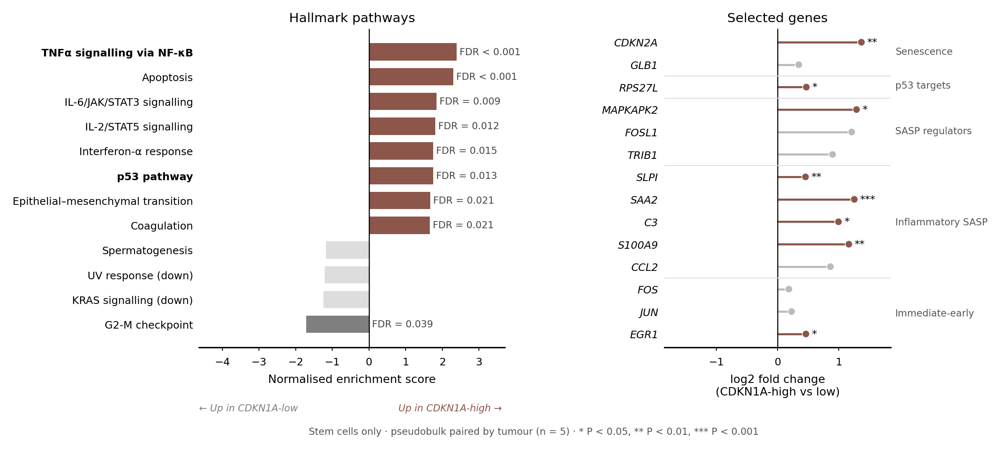

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
split_mode   = "global_q90"           # "detected": any CDKN1A vs none
                                      # "global_q90": top 10% of stem cells by CDKN1A vs none detected
                                      # "tumour_q90": top 10% within each tumour vs none detected
q_high       = 0.90
min_high     = 5                      # min CDKN1A-high cells per tumour (fewer cells pass a strict cut-off)
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.3)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Proliferation",     ["MKI67", "TOP2A", "CCNB1", "CDK1"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
if split_mode == "detected":
    grp_ = np.where(cdkn1a > 0, "high", "low")
else:
    # stricter: "high" = top 10% of CDKN1A expression; "low" = CDKN1A not detected;
    # cells in between (detected but below the cut-off) are left out
    grp_ = np.full(len(cdkn1a), "mid", dtype=object)
    grp_[cdkn1a == 0] = "low"
    if split_mode == "global_q90":
        thr = np.quantile(cdkn1a, q_high)
        thr = max(thr, np.min(cdkn1a[cdkn1a > 0]))      # never call an undetected cell "high"
        grp_[cdkn1a >= thr] = "high"
        print(f"Global {int(q_high * 100)}th percentile of CDKN1A in stem cells: {thr:.3f}")
    else:
        sid_ = stem.obs[sample_col].astype(str).to_numpy()
        for s_ in np.unique(sid_):
            m = sid_ == s_
            v = cdkn1a[m]
            if (v > 0).any():
                thr = max(np.quantile(v, q_high), v[v > 0].min())
                grp_[m & (cdkn1a >= thr)] = "high"
stem.obs["CDKN1A_group"] = grp_
print("Cells per group:", pd.Series(grp_).value_counts().to_dict())
stem = stem[stem.obs["CDKN1A_group"] != "mid"].copy()
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_high) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_high} high and >= {min_cells} low cells: {len(keep)}")
if len(keep) < 5:
    print("WARNING: fewer than 5 tumours - treat as a sensitivity analysis, not the main result")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + 0.08 if v > 0 else 0.08, yi, txt, va="center", ha="left",
                 fontsize=fs["small"] - 0.5, color="#444444")   # negative bars: label right of zero
lim = np.abs(show["NES"]).max() * 1.55
neg_sig = ((show["NES"] < 0) & (show["FDR"] < 0.05)).any()
ax1.set_xlim(-lim * (1.25 if neg_sig else 0.75), lim)    # room for FDR labels on negative bars
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Global 90th percentile of CDKN1A in stem cells: 1.494
Cells per group: {'low': 943, 'mid': 184, 'high': 126}
CDKN1A_group  high  low
SRA_ID                 
HRS488982       38   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
SRX14605703      1  426
SRX16175537     16   70
SRX21219339      7   14
SRX21219341      1    2
SRX21219343      0    7
SRX28461022      3   98 

Tumours with >= 5 high and >= 10 low cells: 5

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 0
          log2FoldChange  pvalue    padj
S100A2            1.6689  0.0000  0.1175
TACSTD2           1.1167  0.0003  0.5604
SAA2              1.2549  0.0007  0.9026
GADD45B           1.0086  0.0013  0.9995
MT-ND4           -0.7739  0.0032  0.9995
CLIC4             1.0105  0.0040  0.9995
SLPI              0.4570  0.0045  0.9995
CDKN2A            1.3710  0.0065  0.9995
S100A9            1.1659  0.0067  0.9995
KLF6            

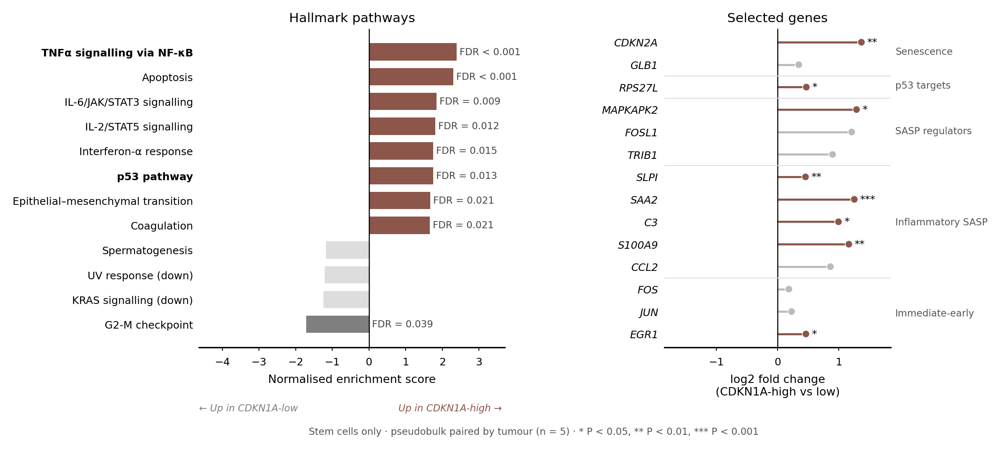

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (detected) vs CDKN1A-low
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
split_mode   = "global_q90"           # "detected": any CDKN1A vs none
                                      # "global_q90": top 10% of stem cells by CDKN1A vs none detected
                                      # "tumour_q90": top 10% within each tumour vs none detected
q_high       = 0.90
min_high     = 5                      # min CDKN1A-high cells per tumour (fewer cells pass a strict cut-off)
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.3)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Proliferation",     ["MKI67", "TOP2A", "CCNB1", "CDK1"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
if split_mode == "detected":
    grp_ = np.where(cdkn1a > 0, "high", "low")
else:
    # stricter: "high" = top 10% of CDKN1A expression; "low" = CDKN1A not detected;
    # cells in between (detected but below the cut-off) are left out
    grp_ = np.full(len(cdkn1a), "mid", dtype=object)
    grp_[cdkn1a == 0] = "low"
    if split_mode == "global_q90":
        thr = np.quantile(cdkn1a, q_high)
        thr = max(thr, np.min(cdkn1a[cdkn1a > 0]))      # never call an undetected cell "high"
        grp_[cdkn1a >= thr] = "high"
        print(f"Global {int(q_high * 100)}th percentile of CDKN1A in stem cells: {thr:.3f}")
    else:
        sid_ = stem.obs[sample_col].astype(str).to_numpy()
        for s_ in np.unique(sid_):
            m = sid_ == s_
            v = cdkn1a[m]
            if (v > 0).any():
                thr = max(np.quantile(v, q_high), v[v > 0].min())
                grp_[m & (cdkn1a >= thr)] = "high"
stem.obs["CDKN1A_group"] = grp_
print("Cells per group:", pd.Series(grp_).value_counts().to_dict())
stem = stem[stem.obs["CDKN1A_group"] != "mid"].copy()
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_high) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_high} high and >= {min_cells} low cells: {len(keep)}")
if len(keep) < 5:
    print("WARNING: fewer than 5 tumours - treat as a sensitivity analysis, not the main result")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + 0.08 if v > 0 else 0.08, yi, txt, va="center", ha="left",
                 fontsize=fs["small"] - 0.5, color="#444444")   # negative bars: label right of zero
lim = np.abs(show["NES"]).max() * 1.55
neg_sig = ((show["NES"] < 0) & (show["FDR"] < 0.05)).any()
ax1.set_xlim(-lim * (1.25 if neg_sig else 0.75), lim)    # room for FDR labels on negative bars
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Global 90th percentile of CDKN1A in stem cells: 1.494
Cells per group: {'low': 943, 'mid': 184, 'high': 126}
CDKN1A_group  high  low
SRA_ID                 
HRS488982       38   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
SRX14605703      1  426
SRX16175537     16   70
SRX21219339      7   14
SRX21219341      1    2
SRX21219343      0    7
SRX28461022      3   98 

Tumours with >= 5 high and >= 10 low cells: 5

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 0
          log2FoldChange  pvalue    padj
S100A2            1.6689  0.0000  0.1175
TACSTD2           1.1167  0.0003  0.5604
SAA2              1.2549  0.0007  0.9026
GADD45B           1.0086  0.0013  0.9995
MT-ND4           -0.7739  0.0032  0.9995
CLIC4             1.0105  0.0040  0.9995
SLPI              0.4570  0.0045  0.9995
CDKN2A            1.3710  0.0065  0.9995
S100A9            1.1659  0.0067  0.9995
KLF6            

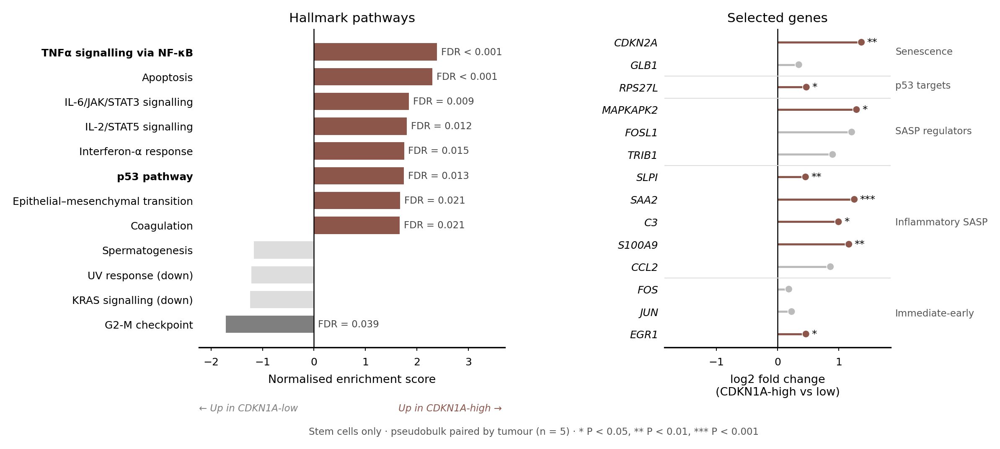

In [51]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (top 10%) vs CDKN1A-low (not detected)
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
split_mode   = "global_q90"           # "detected": any CDKN1A vs none
                                      # "global_q90": top 10% of stem cells by CDKN1A vs none detected
                                      # "tumour_q90": top 10% within each tumour vs none detected
q_high       = 0.90
min_high     = 5                      # min CDKN1A-high cells per tumour (fewer cells pass a strict cut-off)
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.3)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = ["p53 Pathway", "TNF-alpha Signaling via NF-kB"]
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Proliferation",     ["MKI67", "TOP2A", "CCNB1", "CDK1"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
if split_mode == "detected":
    grp_ = np.where(cdkn1a > 0, "high", "low")
else:
    # stricter: "high" = top 10% of CDKN1A expression; "low" = CDKN1A not detected;
    # cells in between (detected but below the cut-off) are left out
    grp_ = np.full(len(cdkn1a), "mid", dtype=object)
    grp_[cdkn1a == 0] = "low"
    if split_mode == "global_q90":
        thr = np.quantile(cdkn1a, q_high)
        thr = max(thr, np.min(cdkn1a[cdkn1a > 0]))      # never call an undetected cell "high"
        grp_[cdkn1a >= thr] = "high"
        print(f"Global {int(q_high * 100)}th percentile of CDKN1A in stem cells: {thr:.3f}")
    else:
        sid_ = stem.obs[sample_col].astype(str).to_numpy()
        for s_ in np.unique(sid_):
            m = sid_ == s_
            v = cdkn1a[m]
            if (v > 0).any():
                thr = max(np.quantile(v, q_high), v[v > 0].min())
                grp_[m & (cdkn1a >= thr)] = "high"
stem.obs["CDKN1A_group"] = grp_
print("Cells per group:", pd.Series(grp_).value_counts().to_dict())
stem = stem[stem.obs["CDKN1A_group"] != "mid"].copy()
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_high) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_high} high and >= {min_cells} low cells: {len(keep)}")
if len(keep) < 5:
    print("WARNING: fewer than 5 tumours - treat as a sensitivity analysis, not the main result")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + 0.08 if v > 0 else 0.08, yi, txt, va="center", ha="left",
                 fontsize=fs["small"] - 0.5, color="#444444")   # negative bars: label right of zero
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(min(show["NES"].min() * 1.3, -0.5), lim)   # left edge just past the most negative bar
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()

Global 90th percentile of CDKN1A in stem cells: 1.494
Cells per group: {'low': 943, 'mid': 184, 'high': 126}
CDKN1A_group  high  low
SRA_ID                 
HRS488982       38   57
HRS488984        2    2
HRS488986        0    1
HRS488987        0    1
HRS488990       36  209
HRS488991       22   56
SRX14605703      1  426
SRX16175537     16   70
SRX21219339      7   14
SRX21219341      1    2
SRX21219343      0    7
SRX28461022      3   98 

Tumours with >= 5 high and >= 10 low cells: 5

Differential expression: PyDESeq2 (~ tumour + group); genes with padj < 0.05: 0
          log2FoldChange  pvalue    padj
S100A2            1.6689  0.0000  0.1175
TACSTD2           1.1167  0.0003  0.5604
SAA2              1.2549  0.0007  0.9026
GADD45B           1.0086  0.0013  0.9995
MT-ND4           -0.7739  0.0032  0.9995
CLIC4             1.0105  0.0040  0.9995
SLPI              0.4570  0.0045  0.9995
CDKN2A            1.3710  0.0065  0.9995
S100A9            1.1659  0.0067  0.9995
KLF6            

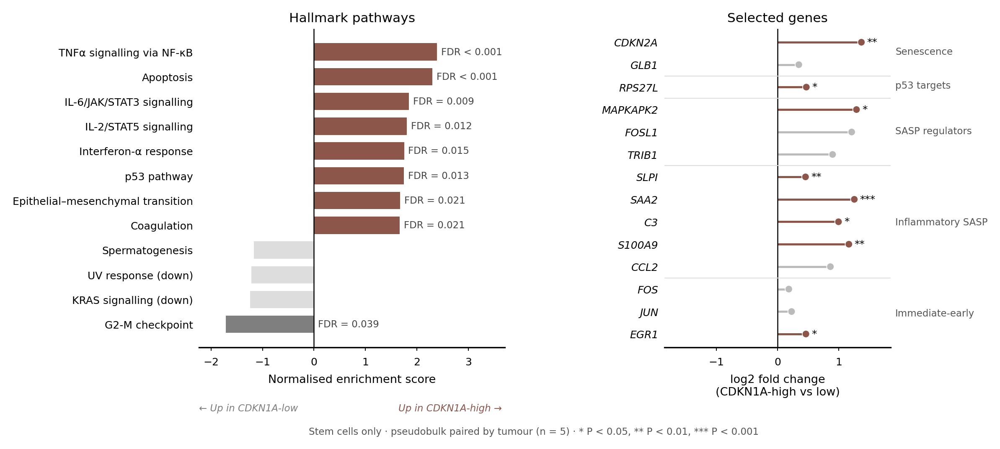

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from matplotlib.ticker import MultipleLocator
from scipy.stats import ttest_rel, wilcoxon

def bh(p):
    """Benjamini-Hochberg FDR."""
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(1, len(p) + 1)
    q = p * len(p) / r
    q_sorted = np.minimum.accumulate(q[o][::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q_sorted, 1)
    return out

# =============================================================================
# Figure 2E - complete, self-contained (runs straight from `adata`)
#   1. Stem cells split into CDKN1A-high (top 10%) vs CDKN1A-low (not detected)
#   2. Pseudobulk per tumour x group, paired differential expression
#      (PyDESeq2 if installed, otherwise paired t-test on log-CPM)
#   3. Dissociation-stress check
#   4. Hallmark GSEA with CDKN1A + dissociation genes removed from the ranking
#   5. Plot: pathway NES bars + selected-gene fold changes
# Needs: gseapy  (%pip install gseapy)   Optional: pydeseq2 (%pip install pydeseq2)
# =============================================================================

# ---- 1. Configuration --------------------------------------------------------
label_col    = "final_cell_type_broad"
sample_col   = "SRA_ID"
counts_layer = "counts"
min_cells    = 10                     # per group per tumour
split_mode   = "global_q90"           # "detected": any CDKN1A vs none
                                      # "global_q90": top 10% of stem cells by CDKN1A vs none detected
                                      # "tumour_q90": top 10% within each tumour vs none detected
q_high       = 0.90
min_high     = 5                      # min CDKN1A-high cells per tumour (fewer cells pass a strict cut-off)
n_up, n_down = 8, 4                   # pathways shown on each side
fig_size     = (7.1, 3.3)             # full page width (180 mm)
fs           = {"title": 7.5, "label": 6.5, "small": 6}
c_up, c_up_ns = "#8c564b", "#DCC7C0"  # enriched in CDKN1A-high (sig / n.s.)
c_dn, c_dn_ns = "#7f7f7f", "#DDDDDD"  # enriched in CDKN1A-low  (sig / n.s.)
highlight    = []                     # no bold pathway labels; bar colour already marks FDR < 0.05
right_panel  = "lollipop"            # "dotplot" (CDKN1A-high vs low cells) or "lollipop" (fold changes)
gene_groups  = [                     # chosen from the pseudobulk results (see legend)
    ("Senescence",        ["CDKN1A", "CDKN2A", "GLB1"]),
    ("p53 targets",       ["DDB2", "RPS27L", "MDM2"]),
    ("SASP regulators",   ["MAPKAPK2", "FOSL1", "TRIB1"]),
    ("Inflammatory SASP", ["SLPI", "SAA2", "C3", "S100A9", "SULF1", "CCL2"]),
    ("Proliferation",     ["MKI67", "TOP2A", "CCNB1", "CDK1"]),
    ("Immediate-early",   ["FOS", "JUN", "EGR1"]),
]
aliases = {"CCN2": "CTGF"}
diss = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "EGR2", "EGR3", "ATF3", "IER2", "IER3",
        "IER5", "HSPA1A", "HSPA1B", "HSPA8", "DNAJB1", "DUSP1", "ZFP36", "ZFP36L1", "NR4A1",
        "NR4A2", "KLF2", "KLF4", "KLF6", "SOCS3", "NFKBIA", "PPP1R15A", "GADD45B", "BTG2",
        "MYC", "CCN1", "CYR61", "HSPH1", "UBC", "SRF"]

# ---- 2. Stem cells: CDKN1A-high vs -low -------------------------------------
ct = adata.obs[label_col].astype(str).replace({"Stem_cells": "Stem cells"}).to_numpy()
stem = adata[ct == "Stem cells"].copy()
use_raw = stem.raw is not None
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()
if split_mode == "detected":
    grp_ = np.where(cdkn1a > 0, "high", "low")
else:
    # stricter: "high" = top 10% of CDKN1A expression; "low" = CDKN1A not detected;
    # cells in between (detected but below the cut-off) are left out
    grp_ = np.full(len(cdkn1a), "mid", dtype=object)
    grp_[cdkn1a == 0] = "low"
    if split_mode == "global_q90":
        thr = np.quantile(cdkn1a, q_high)
        thr = max(thr, np.min(cdkn1a[cdkn1a > 0]))      # never call an undetected cell "high"
        grp_[cdkn1a >= thr] = "high"
        print(f"Global {int(q_high * 100)}th percentile of CDKN1A in stem cells: {thr:.3f}")
    else:
        sid_ = stem.obs[sample_col].astype(str).to_numpy()
        for s_ in np.unique(sid_):
            m = sid_ == s_
            v = cdkn1a[m]
            if (v > 0).any():
                thr = max(np.quantile(v, q_high), v[v > 0].min())
                grp_[m & (cdkn1a >= thr)] = "high"
stem.obs["CDKN1A_group"] = grp_
print("Cells per group:", pd.Series(grp_).value_counts().to_dict())
stem = stem[stem.obs["CDKN1A_group"] != "mid"].copy()
cdkn1a = sc.get.obs_df(stem, keys=["CDKN1A"], use_raw=use_raw)["CDKN1A"].to_numpy()

n = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).size().unstack(fill_value=0)
keep = n.index[(n.get("high", 0) >= min_high) & (n.get("low", 0) >= min_cells)]
print(n.to_string(), f"\n\nTumours with >= {min_high} high and >= {min_cells} low cells: {len(keep)}")
if len(keep) < 5:
    print("WARNING: fewer than 5 tumours - treat as a sensitivity analysis, not the main result")
stem = stem[stem.obs[sample_col].astype(str).isin([str(k) for k in keep])].copy()
n_tum = len(keep)

# ---- 3. Pseudobulk (sum raw counts per tumour x group) ----------------------
C = stem.layers[counts_layer]
rows, meta = [], []
for (s, g), idx in stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True).groups.items():
    m = stem.obs_names.get_indexer(idx)
    rows.append(np.asarray(C[m].sum(axis=0)).ravel())
    meta.append({"sample": f"{s}_{g}", "tumour": str(s), "group": g})
pb = pd.DataFrame(np.vstack(rows), columns=stem.var_names,
                  index=[mm["sample"] for mm in meta]).round().astype(int)
pb_meta = pd.DataFrame(meta).set_index("sample")
pb = pb.loc[:, (pb >= 10).sum(axis=0) >= max(3, n_tum // 2)]     # drop very low genes
pb = pb.drop(columns=["CDKN1A"], errors="ignore")

try:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    dds = DeseqDataSet(counts=pb, metadata=pb_meta, design="~ tumour + group", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["group", "high", "low"], quiet=True)
    st.summary()
    res = st.results_df
    method = "PyDESeq2 (~ tumour + group)"
except ImportError:
    cpm = pb.div(pb.sum(axis=1), axis=0) * 1e6
    lcpm = np.log2(cpm + 1)
    tum = sorted(set(pb_meta["tumour"]))
    hi = lcpm.loc[[f"{t}_high" for t in tum]].to_numpy()
    lo = lcpm.loc[[f"{t}_low" for t in tum]].to_numpy()
    t, p = ttest_rel(hi, lo, axis=0)
    res = pd.DataFrame({"baseMean": cpm.mean().values, "log2FoldChange": (hi - lo).mean(axis=0),
                        "stat": t, "pvalue": p}, index=lcpm.columns)
    res["padj"] = bh(res["pvalue"].fillna(1))
    method = "paired t-test on log2 CPM"
res = res.sort_values("pvalue")
res.to_csv("Stem_CDKN1A_high_vs_low_pseudobulk.csv")
print(f"\nDifferential expression: {method}; genes with padj < 0.05: {(res['padj'] < 0.05).sum()}")
print(res.head(15)[["log2FoldChange", "pvalue", "padj"]].round(4).to_string())

# ---- 4. Dissociation-stress check -------------------------------------------
dg = [g for g in diss if g in (stem.raw.var_names if use_raw else stem.var_names)]
sc.tl.score_genes(stem, dg, score_name="diss_score", use_raw=use_raw)
d = stem.obs.groupby([sample_col, "CDKN1A_group"], observed=True)["diss_score"].median().unstack()
print("\nDissociation score (median per tumour):\n", d.round(3).to_string())
print(f"high > low in {(d['high'] > d['low']).sum()}/{len(d)} tumours; "
      f"paired Wilcoxon P = {wilcoxon(d['high'], d['low']).pvalue:.3f}")

# ---- 5. Hallmark GSEA, dissociation genes removed ---------------------------
import gseapy as gp
rnk = res["stat"].drop(index=[g for g in diss if g in res.index]).dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", permutation_num=1000,
                 min_size=15, max_size=500, seed=0, outdir=None, verbose=False)
g = pre.res2d.copy()
g["NES"] = g["NES"].astype(float)
g["FDR"] = g["FDR q-val"].astype(float)
g.to_csv("Stem_CDKN1A_GSEA_hallmark_nodiss.csv", index=False)
print("\nHallmark GSEA (dissociation genes removed):")
print(g.sort_values("NES", ascending=False)[["Term", "NES", "FDR"]].head(10).to_string(index=False))

# ---- 6. Plot -----------------------------------------------------------------
pretty = {"TNF-alpha Signaling via NF-kB": "TNFα signalling via NF-κB",
          "p53 Pathway": "p53 pathway", "UV Response Up": "UV response (up)",
          "UV Response Dn": "UV response (down)", "IL-2/STAT5 Signaling": "IL-2/STAT5 signalling",
          "IL-6/JAK/STAT3 Signaling": "IL-6/JAK/STAT3 signalling",
          "Epithelial Mesenchymal Transition": "Epithelial–mesenchymal transition",
          "KRAS Signaling Dn": "KRAS signalling (down)", "KRAS Signaling Up": "KRAS signalling (up)",
          "Pperoxisome": "Peroxisome", "Hedgehog Signaling": "Hedgehog signalling",
          "Interferon Alpha Response": "Interferon-α response",
          "Interferon Gamma Response": "Interferon-γ response"}
def tidy(t):
    if t in pretty:
        return pretty[t]
    w = t.split()
    out = [w[0]] + [x if (x.isupper() or any(ch.isdigit() for ch in x) or "-" in x) else x.lower()
                    for x in w[1:]]
    return " ".join(out).replace("Signaling", "signalling").replace("signaling", "signalling")

show = pd.concat([g.nlargest(n_up, "NES"), g.nsmallest(n_down, "NES").iloc[::-1]])
show = show.drop_duplicates("Term").sort_values("NES")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size, dpi=300,
                               gridspec_kw={"width_ratios": [1.35, 0.55 if right_panel == "dotplot" else 1],
                                            "wspace": 0.6})

# Left: pathway NES bars
cols = [(c_up if f < 0.05 else c_up_ns) if v > 0 else (c_dn if f < 0.05 else c_dn_ns)
        for v, f in zip(show["NES"], show["FDR"])]
y = np.arange(len(show))
ax1.barh(y, show["NES"], color=cols, height=0.7, edgecolor="none")
ax1.axvline(0, color="black", lw=0.6)
ax1.set_yticks(y)
ax1.set_yticklabels([tidy(t) for t in show["Term"]], fontsize=fs["small"])
for lab, t in zip(ax1.get_yticklabels(), show["Term"]):
    if t in highlight:
        lab.set_fontweight("bold")
for yi, (v, f) in enumerate(zip(show["NES"], show["FDR"])):
    txt = "FDR < 0.001" if f < 0.001 else f"FDR = {f:.3f}" if f < 0.05 else ""
    if txt:
        ax1.text(v + 0.08 if v > 0 else 0.08, yi, txt, va="center", ha="left",
                 fontsize=fs["small"] - 0.5, color="#444444")   # negative bars: label right of zero
lim = np.abs(show["NES"]).max() * 1.55
ax1.set_xlim(min(show["NES"].min() * 1.3, -0.5), lim)   # left edge just past the most negative bar
ax1.set_xlabel("Normalised enrichment score", fontsize=fs["label"])
ax1.set_title("Hallmark pathways", fontsize=fs["title"], pad=4)
ax1.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
ax1.tick_params(axis="y", length=0)
for sp in ("top", "right", "left"):
    ax1.spines[sp].set_visible(False)
ax1.text(0.99, -0.2, "Up in CDKN1A-high →", transform=ax1.transAxes, ha="right",
         fontsize=fs["small"] - 0.5, color=c_up, fontstyle="italic")
ax1.text(0.0, -0.2, "← Up in CDKN1A-low", transform=ax1.transAxes, ha="left",
         fontsize=fs["small"] - 0.5, color=c_dn, fontstyle="italic")

# Right panel ---------------------------------------------------------------
def lookup(gg, pool):
    return gg if gg in pool else aliases.get(gg, gg)
def stars(p):
    return "" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"

if right_panel == "dotplot":
    # Dot plot of CDKN1A-low vs -high stem cells (cells pooled across the n tumours).
    # Size = % of cells expressing; colour = mean log-normalised expression on ONE shared
    # scale (not rescaled per gene, which would exaggerate a two-group comparison).
    # Stars = pseudobulk P (paired by tumour), so the statistics are per tumour, not per cell.
    vn = stem.raw.var_names if use_raw else stem.var_names
    genes, labels_, grp_pos = [], [], []
    for gname, gl in gene_groups:
        kept = [gg for gg in gl if lookup(gg, vn) in vn]
        if kept:
            grp_pos.append((gname, len(genes), len(genes) + len(kept) - 1))
            genes += [lookup(gg, vn) for gg in kept]
            labels_ += ["CCN2 (CTGF)" if gg == "CCN2" else gg for gg in kept]
    Ex = sc.get.obs_df(stem, keys=genes, use_raw=use_raw).to_numpy(dtype=float)
    grp = stem.obs["CDKN1A_group"].to_numpy()
    cols_ = ["low", "high"]
    frac = np.array([(Ex[grp == c] > 0).mean(0) for c in cols_]).T        # genes x 2
    mean = np.array([Ex[grp == c].mean(0) for c in cols_]).T
    vmax = np.percentile(mean, 95)
    yy, xx = np.meshgrid(np.arange(len(genes)), [0, 1], indexing="ij")
    dots = ax2.scatter(xx.ravel(), yy.ravel(), s=frac.ravel() * 60, c=mean.ravel(), cmap="Reds",
                       vmin=0, vmax=vmax, edgecolors="#555555", linewidths=0.3)
    for i, gg in enumerate(genes):
        p = res.loc[gg, "pvalue"] if gg in res.index else np.nan
        txt = "split" if gg == "CDKN1A" else stars(p)
        ax2.text(1.55, i, txt, va="center", ha="left", fontsize=fs["small"] - (1 if txt == "split" else 0),
                 color="#777777" if txt == "split" else "black")
    ax2.set_yticks(range(len(genes)))
    ax2.set_yticklabels(labels_, fontsize=fs["small"], fontstyle="italic")
    ax2.set_xticks([0, 1])
    ax2.set_xticklabels(["Low", "High"], fontsize=fs["small"])
    for lab, c in zip(ax2.get_xticklabels(), [c_up_ns, c_up]):
        lab.set_color("#9a7a70" if c == c_up_ns else c_up); lab.set_fontweight("bold")
    ax2.set_xlabel("CDKN1A", fontsize=fs["label"], fontstyle="italic")
    ax2.set_xlim(-0.6, 2.1)
    ax2.set_ylim(len(genes) - 0.5, -0.5)
    for name, a_, b_ in grp_pos:
        if a_ > 0:
            ax2.axhline(a_ - 0.5, color="#DDDDDD", lw=0.5)
        ax2.text(2.15, (a_ + b_) / 2, name, va="center", ha="left", fontsize=fs["small"] - 0.5,
                 color="#555555", transform=ax2.transData, clip_on=False)
    ax2.set_title("Stem cells", fontsize=fs["title"], pad=4)
    ax2.tick_params(length=0)
    for sp in ("top", "right", "left", "bottom"):
        ax2.spines[sp].set_visible(False)
    # keys
    from matplotlib.lines import Line2D
    sz = [Line2D([], [], marker="o", ls="", color="#888888", markersize=np.sqrt(p_ * 60),
                 label=f"{int(p_ * 100)}%") for p_ in (0.1, 0.3, 0.6)]
    ax2.legend(handles=sz, title="% expressing", loc="lower left", bbox_to_anchor=(1.78, 0.0),
               frameon=False, fontsize=fs["small"] - 1, title_fontsize=fs["small"] - 0.5,
               labelspacing=0.5, borderaxespad=0)
    cax = ax2.inset_axes([1.82, 0.36, 0.07, 0.17])
    cb = fig.colorbar(dots, cax=cax)
    cb.ax.tick_params(labelsize=fs["small"] - 1, length=1.5, width=0.4)
    cb.outline.set_linewidth(0.4)
    cb.set_label("Mean expr.", fontsize=fs["small"] - 1)
    footer = (f"Stem cells only · {n_tum} tumours · dots pool cells; stars, pseudobulk P paired by tumour "
              "(* P < 0.05, ** P < 0.01, *** P < 0.001)")
else:
    rws, ylab, sep, grp_pos = [], [], [], []
    for gname, gl in gene_groups:
        start = len(rws)
        for gg in gl:
            key = lookup(gg, res.index)
            if key in res.index and key != "CDKN1A":
                rws.append(res.loc[key]); ylab.append("CCN2 (CTGF)" if gg == "CCN2" else gg)
        if len(rws) > start:
            grp_pos.append((gname, start, len(rws) - 1)); sep.append(len(rws) - 0.5)
    gdf = pd.DataFrame(rws)
    yy = np.arange(len(gdf))[::-1]
    lfc, pv = gdf["log2FoldChange"].to_numpy(), gdf["pvalue"].to_numpy()
    gcol = [c_up if (p < 0.05 and l > 0) else c_dn if (p < 0.05 and l < 0) else "#BBBBBB"
            for l, p in zip(lfc, pv)]
    ax2.hlines(yy, 0, lfc, color=gcol, lw=1.2)
    ax2.scatter(lfc, yy, s=18, color=gcol, zorder=3, edgecolors="white", linewidths=0.4)
    ax2.axvline(0, color="black", lw=0.6)
    ax2.set_yticks(yy)
    ax2.set_yticklabels(ylab, fontsize=fs["small"], fontstyle="italic")
    mx = np.abs(lfc).max() * 1.35
    for x_, y_, p in zip(lfc, yy, pv):
        if stars(p):
            off = 0.05 * mx
            ax2.text(x_ + (off if x_ >= 0 else -off), y_, stars(p), va="center",
                     ha="left" if x_ >= 0 else "right", fontsize=fs["small"])
    ax2.set_xlim(-mx, mx)
    ax2.xaxis.set_major_locator(MultipleLocator(1))
    for s_ in sep[:-1]:
        ax2.axhline(len(gdf) - 1 - s_, color="#DDDDDD", lw=0.5)
    for gname, a_, b_ in grp_pos:
        ax2.text(1.02, 1 - ((a_ + b_) / 2 + 0.5) / len(gdf), gname, transform=ax2.transAxes,
                 va="center", ha="left", fontsize=fs["small"] - 0.5, color="#555555")
    ax2.set_xlabel("log2 fold change\n(CDKN1A-high vs low)", fontsize=fs["label"])
    ax2.set_title("Selected genes", fontsize=fs["title"], pad=4)
    ax2.tick_params(axis="x", labelsize=fs["small"], length=2, width=0.5)
    ax2.tick_params(axis="y", length=0)
    ax2.set_ylim(-0.6, len(gdf) - 0.4)
    for sp in ("top", "right", "left"):
        ax2.spines[sp].set_visible(False)
    footer = (f"Stem cells only · pseudobulk paired by tumour (n = {n_tum}) · "
              "* P < 0.05, ** P < 0.01, *** P < 0.001")

fig.text(0.5, -0.1 if right_panel == "lollipop" else -0.04, footer, ha="center", fontsize=fs["small"] - 0.5, color="#555555")

fig.savefig("Fig2E_pathways.pdf", bbox_inches="tight")
fig.savefig("Fig2E_pathways.svg", bbox_inches="tight")
fig.savefig("Fig2E_pathways.png", dpi=600, bbox_inches="tight")
plt.show()